# Fisher e DALI
## A persistência da não gaussianidade

**Igor Stellet · Estatística Bayesiana · Doutorado no CBPF · 2026/2**

**Tema:** Higher-order Fisher Matrix (DALI).

Este será o notebook principal do projeto, contendo todas as hipóteses, deduções, exxemplos, aplicações e discussções dos resultados. As funções principais e que acredito que serão úteis para outros projetos serão acrescentadas em `src/dali.py`.

O planejamento está no [README](README.md).

O título *A persistência da não gaussianidade*  é inspirada na obra *A Persistência da Memória*, de Salvador Dalí (1931), [registrada no MoMA](https://www.moma.org/collection/works/79018). Ao final do projeto, farei uma oficina visual, presente no Bloco 7, para ilustrar a obra e o motivo do artista da nome ao método :), utilizando uma construção matemática própria.

# 0. Leitura e execução

O percurso de cada seção será: **pergunta → modelo e hipóteses → dedução → implementação → verificação → interpretação**.

1. Abra este arquivo com o kernel **Análise Bayesiana (.venv)** do repositório.
2. Execute a configuração abaixo, a partir da raiz do repositório ou da pasta `projeto/`.
3. Nas próximas versões, as análises serão acrescentadas na ordem do sumário e os parâmetros de execução serão documentados nos próprios blocos.

O único código científico executado para esta entrega é a figura de orientação do README, cujo script acompanha os arquivos. O módulo principal está preparado para receber as funções; ainda não implementa as aproximações.


In [1]:
from pathlib import Path
import sys

# Aceita iniciar o kernel na raiz do repositório ou na pasta deste notebook.
candidatos = (Path.cwd(), Path.cwd() / "projeto")
PROJETO_DIR = next(
    (pasta.resolve() for pasta in candidatos if (pasta / "src" / "dali.py").is_file()),
    None,
)
if PROJETO_DIR is None:
    raise FileNotFoundError(
        "Abra o notebook na pasta projeto/ ou na raiz do repositório, "
        "mantendo src/dali.py junto dos arquivos do projeto."
    )

if str(PROJETO_DIR) not in sys.path:
    sys.path.insert(0, str(PROJETO_DIR))

from src import dali

FIGURAS_DIR = PROJETO_DIR / "figuras"
DADOS_DIR = PROJETO_DIR / "data"
TABELAS_DIR = PROJETO_DIR / "tabelas"
SEMENTE = 2026

print("Pasta do projeto localizada:", PROJETO_DIR.name)
print("Módulo local carregado:", dali.__name__)
print("Estrutura inicial pronta; análises científicas a desenvolver.")


Pasta do projeto localizada: projeto
Módulo local carregado: src.dali
Estrutura inicial pronta; análises científicas a desenvolver.


## Sumário

- [1. Modelo probabilístico e Fisher](#bloco-1)
- [2. Hierarquia de DALI](#bloco-2)
- [3. Exemplos controlados](#bloco-3)
- [4. Aplicação à Lista 3](#bloco-4)
- [5. Supernovas](#bloco-5)
- [6. BAO e combinação de observáveis](#bloco-6)
- [7. Oficina visual inspirada em Dalí](#bloco-7)
- [8. Precisão e custo computacional](#bloco-8)
- [9. Síntese, limitações e referências](#bloco-9)


<a id="bloco-1"></a>

# 1. Modelo probabilístico e Fisher

Antes de aprendermos o método de DALI, é necessário entendermos o básico sobre Fisher e seu método aproximativo. Assim, podemos começar nos perguntando:

O que estamos aproximando ao usar Fisher, quais são as hipóteses e como essa matriz está relacionada com a incerteza dos parâmetros?

Antes de tentar ir além da aproximação gaussiana, vamos construir um caso em que ela funciona exatamente, ou seja, na qual a matriz de Fisher descreve completamente o problema. 

Partiremos de um modelo de medição, escreveremos a distribuição dos erros e derivaremos a likelihood. A solução analítica será confrontada com uma integração numérica da posterior, no código.

Depois manteremos a likelihood e mudaremos a informação anterior: primeiro uma prior gaussiana informativa, depois uma fronteira física que delimita a prior, isso ajuda a ver a limitação dessa aproximação. Por fim, usaremos um modelo não linear para mostrar que **erros gaussianos não implicam uma posterior gaussiana nos parâmetros**, aqui vemos quando essa aproximação começa a falhar e motiva o DALI.

Para entender isso melhor vamos:

    1. Construir um modelo de medição;
    2. Construir a likelihood a partir do modelo;
    3. Mostrar a aproximação de Fisher
    4. Discutir a interpretação física, covariância e geometria
    5. Confrontar a aproximação com integração numérica
    6. Prior e limites da aproximação.
    7. Motivar DALI

## 1.1. Modelo de medições. 

Vamos considerar medidas da posição de um corpo em MRU (com motivação de física 1). Os instantes $t_i$ são conhecidos com precisão suficiente para que sua incerteza seja desprezível neste exemplo. O modelo físico da posição prevê:

$$
\mu_i(a,v)=a+v t_i,
$$

onde $a$ é a posição no instante $t=0$ e $v$ é a velocidade. O modelo é **linear nos parâmetros** que são $a$ e $v$. É importante entender que linearidade dos parâmetros é diferente de linearidade em outras variáveis: um modelo como $a_0+a_1t+a_2t^2$ também seria linear em seus parâmetros, embora sua curva em função de $t$ fosse uma parábola (não linear).

As medidas contêm erro:

$$
d_i=\mu_i(a,v)+\varepsilon_i.
$$

A notação utilizada é:
| Símbolo | Significado | Dimensão ou unidade |
|---|---|---|
| $N$ | Número de medidas. | Inteiro. |
| $t_i$ | Instante da medida $i$. | Segundo. |
| $d\in\mathbb R^N$ | Vetor das posições observadas. | Metro. |
| $\theta=(a,v)^T$ | Parâmetros que queremos inferir. | Metro e metro por segundo. |
| $\mu(\theta)$ | Vetor das posições previstas. | Metro. |
| $\varepsilon=d-\mu(\theta)$ | Vetor dos erros no modelo de medição. | Metro. |
| $C$ | Covariância conhecida dos erros dos **dados**. | Matriz $N\times N$, em metro quadrado. |
| $\mathcal L(\theta)=p(d\mid\theta,I)$ | Likelihood dos dados observados. | Densidade em dados. |
| $\pi(\theta)=p(\theta\mid I)$ | Prior dos parâmetros. | Densidade em parâmetros. |
| $p(\theta\mid d,I)$ | Posterior dos parâmetros. | Densidade em parâmetros. |
| $\Sigma$ | Covariância dos **parâmetros** sob uma posterior especificada. | Matriz $2\times2$, com unidades por entrada. |

$I$ reúne as hipóteses e informações que condicionamos aos dados: modelo do movimento, descrição dos erros e escolhas de prior. A partir daqui, irei omitir $I$ algumas vezes para simplificar a escrita.

### Hipóteses deste exemplo

- Forma do modelo conhecida; inferimos seus parâmetros.
- O vetor dos erros é gaussiano, tem média zero e covariância $C$ conhecida.
- $C$ é simétrica, definida positiva e **independente dos parâmetros**.

In [2]:
# Permite recarregar src/dali.py durante sua reescrita.
import importlib
# Permite registrar a versão do Python usada na execução.
import platform

# Traz as operações com vetores, matrizes e números aleatórios.
import numpy as np
# Organiza os resultados em tabelas.
import pandas as pd
# Registra a versão das rotinas científicas utilizadas.
import scipy
# Traz a quadratura de Simpson para integrar as malhas.
from scipy.integrate import simpson
# Traz as densidades e os quantis usados como referências analíticas.
from scipy.stats import norm, chi2, multivariate_normal
# Traz as ferramentas para desenhar os gráficos.
import matplotlib.pyplot as plt
# Permite exibir tabelas, figuras e pequenos textos no notebook.
from IPython.display import display, Markdown

# Recarregar ajuda durante a reescrita das funções em src/dali.py.
importlib.reload(dali)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "svg.fonttype": "none",
})
# Escolhe as cores que terão o mesmo significado nos gráficos.
AZUL, LARANJA, VERDE, CINZA = "#245f94", "#b45f2c", "#398477", "#777777"
# Define onde salvar as figuras deste bloco.
FIGURAS_B1 = FIGURAS_DIR / "bloco_01"
# Define onde salvar as tabelas deste bloco.
TABELAS_B1 = TABELAS_DIR / "bloco_01"
# Cria a pasta de saída se ela ainda não existir.
FIGURAS_B1.mkdir(parents=True, exist_ok=True)
# Cria a pasta de saída se ela ainda não existir.
TABELAS_B1.mkdir(parents=True, exist_ok=True)

def mostrar_tabela(nome, tabela):
    """Exibe e exporta a mesma tabela usada na discussão."""
    # Salva os valores numéricos para consulta e reprodução.
    tabela.to_csv(TABELAS_B1 / f"{nome}.csv", index=False)
    display(tabela)

def mostrar_figura(nome, figura):
    """Preserva uma versão estática no notebook e arquivos para reutilização."""
    # Salva a mesma figura em formato de imagem e em formato vetorial.
    for formato in ("png", "svg"):
        figura.savefig(FIGURAS_B1 / f"{nome}.{formato}", dpi=170, bbox_inches="tight")
    display(figura)
    plt.close(figura)

print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| SciPy:", scipy.__version__)

Python: 3.14.4
NumPy: 2.5.4 | SciPy: 1.18.1


### Erro de calibração compartilhado: por que incluí-lo?

Queremos dar um significado físico à diferença entre a covariância dos dados $C$ e a covariância dos parâmetros $\Sigma$. Imagine que o instrumento tenha uma incerteza no zero da régua: em uma realização do experimento, todas as posições recebem o mesmo deslocamento. Mais medidas ajudam a determinar a inclinação da trajetória, mas não eliminam essa dúvida comum sobre sua posição inicial.

Vamos representar essa situação por

$$
\varepsilon_i=b_{\rm cal}+\eta_i,
\qquad b_{\rm cal}\sim\mathcal N(0,\tau_{\rm cal}^2),
\qquad \eta_i\sim\mathcal N(0,\sigma_i^2).
$$

$b_{\rm cal}$ é uma única incerteza de calibração compartilhada, enquanto os $\eta_i$ são independentes entre si e de $b_{\rm cal}$. Ao integrar sobre essa calibração desconhecida, obtemos

$$
C_{ij}=\mathbb E[\varepsilon_i\varepsilon_j]
=\tau_{\rm cal}^2+\sigma_i^2\delta_{ij},
\qquad C=\operatorname{diag}(\sigma_i^2)+\tau_{\rm cal}^2\mathbf1\mathbf1^T.
$$

Portanto, $C_{ii}=\sigma_i^2+\tau_{\rm cal}^2$ e, para $i\ne j$, $C_{ij}=\tau_{\rm cal}^2$. **O termo compartilhado entra em todas as entradas de $C$**, e não apenas na diagonal. Ele correlaciona os erros das medidas na likelihood conjunta; isso é diferente da correlação entre os parâmetros na posterior.

Nossa previsão física já está definida: o erro comum aumenta a incerteza em $a$, enquanto as diferenças $d_j-d_i$, usadas para inferir $v$, cancelam $b_{\rm cal}$. Primeiro veremos a correlação dos dados no mapa de $C$ da seção 1.4; na seção 1.8, compararemos as incertezas dos parâmetros com e sem esse termo. A covariância será a mesma em todas essas contas, com $\sigma_i$ e $\tau_{\rm cal}$ conhecidos.


In [3]:
# Cria o gerador aleatório; altere SEMENTE no Bloco 0 para outra realização.
rng_b1 = np.random.default_rng(SEMENTE)
# Escolhe os instantes e a quantidade de medidas; altere para explorar outro experimento.
t = np.linspace(0.0, 4.0, 13)                         # segundos
# Conta quantas medidas serão simuladas.
N = t.size
# Escolhe os desvios independentes em metros; altere para aumentar ou reduzir o ruído.
sigma_ind = 0.20 + 0.08*t/4.0                        # metros
# Escolhe o desvio da calibração comum; use zero para retirar essa correlação.
tau_cal = 0.10                                      # metros
# Coloca as variâncias independentes na diagonal de C.
C_ind = np.diag(sigma_ind**2)
# Acrescenta a variância compartilhada a todas as entradas de C.
C_dados = C_ind + tau_cal**2*np.ones((N, N))
# Monta a matriz do modelo: cada linha é (1, t_i).
X = np.column_stack((np.ones(N), t))                 # mu = X @ theta
# Escolhe a posição inicial e a velocidade verdadeiras da simulação; altere se quiser.
theta_gerador = np.array([1.20, 0.020])              # m; m/s

# Cholesky produz uma realização com a covariância total desejada.
L_dados = np.linalg.cholesky(C_dados)
# Gera normais padrão e as transforma em erros com covariância C.
erro = L_dados @ rng_b1.normal(size=N)
# Soma os erros às posições previstas pelo modelo gerador.
dados = X @ theta_gerador + erro

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("01_dados_simulados", pd.DataFrame({
    "t [s]": t, "d [m]": dados,
    "sigma independente [m]": sigma_ind,
    "sigma total marginal [m]": np.sqrt(np.diag(C_dados)),
}))
# Salva os valores numéricos para consulta e reprodução.
pd.DataFrame(C_dados).to_csv(TABELAS_B1/"01_covariancia_dados.csv", index=False)


,t [s],d [m],sigma independente [m],sigma total marginal [m]
0,0.000000,1.022652,0.200000,0.223607
1,0.333333,1.225372,0.206667,0.229589
2,0.666667,0.752947,0.213333,0.235608
3,1.000000,1.462333,0.220000,0.241661
4,1.333333,1.330881,0.226667,0.247745
5,1.666667,1.128663,0.233333,0.253859
6,2.000000,1.123027,0.240000,0.260000
7,2.333333,1.279281,0.246667,0.266166
8,2.666667,1.143595,0.253333,0.272356
9,3.000000,1.155865,0.260000,0.278568


## 1.2. Construindo a likelihood

A hipótese estatística é uma distribuição para os **erros dos dados**, que nos diz que:

$$
p(\varepsilon)=\frac{1}{(2\pi)^{N/2}|C|^{1/2}}
\exp\!\left[-\frac12\varepsilon^TC^{-1}\varepsilon\right].
$$

Fixados os parâmetros, a mudança de variável $d=\mu(\theta)+\varepsilon$ é uma translação e tem jacobiano unitário. Portanto,

$$
\boxed{\mathcal L(\theta)=p(d\mid\theta)=
\frac{1}{(2\pi)^{N/2}|C|^{1/2}}
\exp\!\left[-\frac12r(\theta)^TC^{-1}r(\theta)\right]},
\qquad r(\theta)=d-\mu(\theta).
$$

Agora $d$ está fixado no valor observado e investigamos como a densidade dos dados muda com $\theta$. A likelihood não é normalizada nos parâmetros e devemos tomar cuidado com iisso. A posterior será dada por:

$$
p(\theta\mid d)=\frac{\mathcal L(\theta)\pi(\theta)}{Z},
\qquad Z=\int \mathcal L(\theta)\pi(\theta)\,d\theta.
$$

Definindo $\chi^2(\theta)=r^TC^{-1}r$, temos

$$
-\log\mathcal L=\frac12\chi^2+
\frac N2\log(2\pi)+\frac12\log|C|.
$$

Como $C$ é fixa, os dois últimos termos são constantes. Nós os manteremos nas avaliações normalizadas. Se $C$ dependesse de $\theta$, o determinante também contribuiria para as derivadas e para localização do máximo da Likelihood.

### A interpretação geométrica nos dados

Se $C=LL^T$ (valido para matrizes simétricas e positivas definidas), com $L$ triangular de Cholesky, então

$$
\chi^2=\|L^{-1}r\|^2.
$$

Assim, $C^{-1}$ mede distâncias no espaço dos dados de acordo com as incertezas e correlações do experimento. A matriz de convariância se importa com o tamanho da diferença entre levando em consideração se o ruído esperado permite distinguir essa diferença ou se está dentro do esperado.


## 1.3. Modelo linear: Forma quadrática exata

Escrevemos $\mu=X\theta$, com $X$ de dimensão $N\times p$ e $p=2$ neste exemplo. Cada linha é $(1,t_i)$. Expandindo o quadrado,

$$
\chi^2(\theta)=d^TC^{-1}d-2\theta^TX^TC^{-1}d
+\theta^T X^TC^{-1}X\theta.
$$

$$
\chi^2(\theta)=d^TC^{-1}d-2\theta^Tb
+\theta^T F\theta.
$$

Definimos

$$
F=X^TC^{-1}X,\qquad b=X^TC^{-1}d.
$$

Da condição $\nabla_\theta\chi^2=0$, segue o sistema das equações normais:

$$
\boxed{F\widehat\theta_{\rm ML}=b}.
$$

Para $\Delta=\theta-\widehat\theta_{\rm ML}$ podemos adicionar e subtrair esse termo nas equações acimas para obtermos:

$$
\boxed{\chi^2(\theta)=\chi^2_{\min}+\Delta^TF\Delta}.
$$

Note que nesse moodelo linear essa igualdade é exata! O quadrado do resíduo já é um polinômio de grau dois em $\theta$. Não desprezamos termos cúbicos ou de ordem superior e aproximação de Fisher torna-se a melhor possível para esse modelo.

A likelihood tem forma gaussiana nos parâmetros. Para falar de uma **posterior** gaussiana, ainda precisamos especificar a prior. Uma prior gaussiana preserva essa forma; uma prior restritiva pode cortá-la.


## 1.4. Escolha de prior e solução analítica da posterior

Vamos usar $\pi(\theta)=\mathcal N(m_0,S_0)$, onde $m_0$ é a média da prior e $S_0$ é sua covariância. Ignorando o termo da evidência que é apenas normalização, podemos somar os expoentes da likelihood e da prior, no qual obtemos
$$
Q=F+S_0^{-1},\qquad
m=Q^{-1}\left(b+S_0^{-1}m_0\right),\qquad
\boxed{\Sigma=Q^{-1}}.
$$

Logo, $p(\theta\mid d)=\mathcal N(m,\Sigma)$. Aqui, a matriz $Q$ está relacionada à precisão da **posterior**, enquanto $F$ é a informação provinda da likelihood, veja que a prior Gaussaiana desloca o máximo da posterior em realação ao máximo da Likelihood.. O estimador ML maximiza a likelihood; o MAP maximiza a posterior. A média e o MAP coincidem na distribuição gaussiana.

Começaremos por uma prior ilustrativa ampla, com desvios de $10\,\mathrm m$ em $a$ e $3\,\mathrm{m\,s^{-1}}$ em $v$. Ela é  praticamente constante na região restringida pelos dados.

No limite em que a prior se torna muito ampla, $S_0^{-1}$ torna-se muito pequeno, de modo que $m\to\widehat\theta_{\rm ML}$ e $\Sigma\to F^{-1}$. No limite dessa prior ampla vamos utilizar as Gaussianas largas, para facilitar os códigos e sua estrutura.


In [4]:
# Escolhe o centro da prior ampla de (a, v).
m0 = np.array([0.0, 0.0])
# Escolhe as variâncias da prior ampla; os valores no colchete são desvios.
S0 = np.diag([10.0**2, 3.0**2])
# Resolve analiticamente o modelo linear com a prior declarada.
ajuste = dali.linear_gaussian_posterior(X, dados, C_dados, m0, S0)
# Guarda a informação de Fisher da likelihood.
F = ajuste.fisher
# Guarda a precisão da posterior, incluindo a prior.
Q = ajuste.precision
# Guarda a média da posterior, que também é seu MAP neste caso gaussiano.
m = ajuste.mean
# Guarda a covariância da posterior.
Sigma = ajuste.covariance
# Calcula a covariância do limite de prior constante, resolvendo um sistema linear.
Sigma_L = np.linalg.solve(F, np.eye(2))

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("02_parametros_lineares", pd.DataFrame({
    "Parâmetro": ["a [m]", "v [m/s]"],
    "Gerador (conhecido só na simulação)": theta_gerador,
    "Máxima likelihood": ajuste.mle,
    "Média/MAP posterior": m,
    "Desvio marginal posterior": np.sqrt(np.diag(Sigma)),
}))
display(Markdown("**Informação da likelihood $F$, precisão posterior $Q$ e covariância $\\Sigma$:**"))
# Exibe cada matriz do ajuste para facilitar sua inspeção.
for nome, matriz in [("F", F), ("Q", Q), ("Sigma", Sigma)]:
    display(Markdown(f"**{nome}**"))
    display(pd.DataFrame(matriz, index=["a", "v"], columns=["a", "v"]))


,Parâmetro,Gerador (conhecido só na simulação),Máxima likelihood,Média/MAP posterior,Desvio marginal posterior
0,a [m],1.20,1.082863,1.082649,0.150889
1,v [m/s],0.02,0.060574,0.060608,0.052965


**Informação da likelihood $F$, precisão posterior $Q$ e covariância $\Sigma$:**

**F**

,a,v
a,69.992634,121.725608
v,121.725608,568.017112


**Q**

,a,v
a,70.002634,121.725608
v,121.725608,568.128223


**Sigma**

,a,v
a,0.022768,-0.004878
v,-0.004878,0.002805


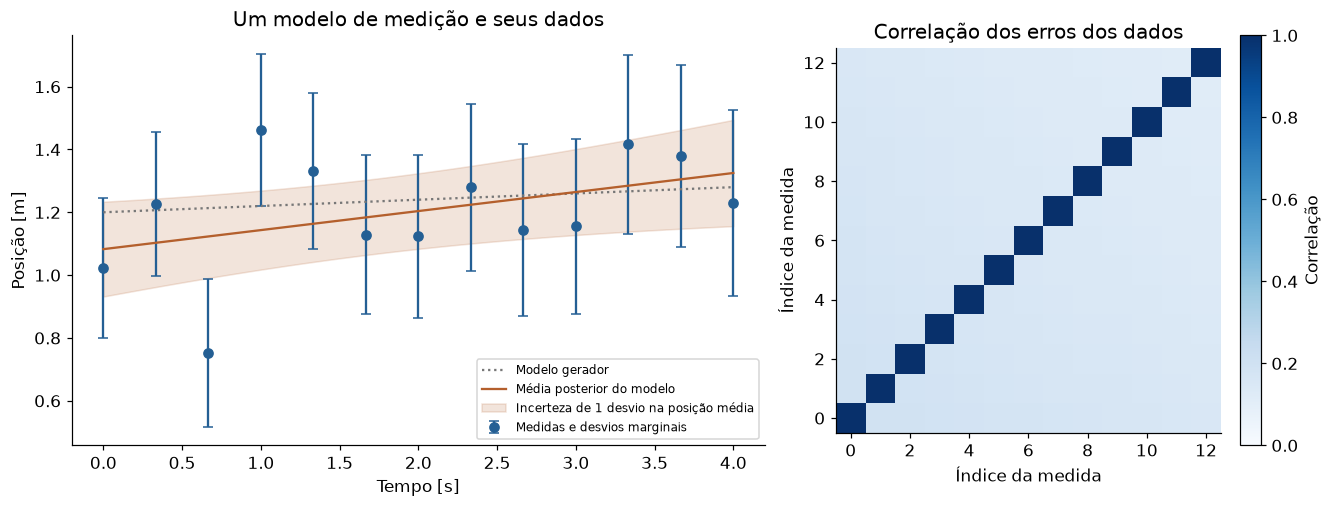

In [5]:
# Cria mais instantes somente para desenhar uma curva contínua.
t_plot = np.linspace(t.min(), t.max(), 250)
# Escreve o mesmo modelo nos instantes usados no desenho.
X_plot = np.column_stack((np.ones(t_plot.size), t_plot))
# Calcula a posição média prevista com a média posterior dos parâmetros.
mu_plot = X_plot @ m
# Propaga a covariância dos parâmetros para a incerteza da posição média.
sigma_modelo = np.sqrt(np.einsum("ni,ij,nj->n", X_plot, Sigma, X_plot))
# Divide cada covariância pelos desvios para obter correlações adimensionais.
corr_dados = C_dados / np.sqrt(np.outer(np.diag(C_dados), np.diag(C_dados)))

# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.8, 1]},
                        layout="constrained")
axs[0].errorbar(t, dados, yerr=np.sqrt(np.diag(C_dados)), fmt="o", color=AZUL,
                capsize=3, label="Medidas e desvios marginais")
axs[0].plot(t_plot, X_plot @ theta_gerador, color=CINZA, ls=":", label="Modelo gerador")
axs[0].plot(t_plot, mu_plot, color=LARANJA, label="Média posterior do modelo")
axs[0].fill_between(t_plot, mu_plot-sigma_modelo, mu_plot+sigma_modelo,
                     color=LARANJA, alpha=.17, label="Incerteza de 1 desvio na posição média")
axs[0].set(xlabel="Tempo [s]", ylabel="Posição [m]", title="Um modelo de medição e seus dados")
axs[0].legend(fontsize=8)
# Desenha o mapa de correlação dos erros das medidas.
im = axs[1].imshow(corr_dados, vmin=0, vmax=1, cmap="Blues", origin="lower")
axs[1].set(xlabel="Índice da medida", ylabel="Índice da medida", title="Correlação dos erros dos dados")
fig.colorbar(im, ax=axs[1], label="Correlação")
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("01_dados_e_covariancia", fig)


As barras mostram os desvios marginais $\sqrt{C_{ii}}$. Elas não mostram, sozinhas, como os erros se relacionam. No painel da direita, os elementos fora da diagonal revelam a correlação gerada pela calibração compartilhada. É essa matriz completa que entrou na likelihood e no ajuste.

A faixa da curva representa a incerteza sobre a **posição média prevista**, $\operatorname{Var}[\mu(t)\mid d]=X(t)\Sigma X(t)^T$. Uma faixa preditiva para novas medidas também precisaria incluir seu ruído e sua relação com a calibração.

O parâmetro gerador aparece porque os dados são simulados; em um experimento real, ele não estaria disponível para julgar o ajuste. Até aqui, o erro compartilhado apareceu em $C$; na seção 1.8 verificaremos o efeito previsto sobre $a$ e $v$.


## 1.5. Relação entre matriz de Fisher e informação

A definição de informação esperada utiliza a distribuição dos dados sob parâmetros fixos. Definindo o *score* $s_a=\partial_a\log\mathcal L$, com $a$ sendo a derivada em relação aos PARÂMETROS. 

$$
F^{\rm exp}_{ab}=\mathbb E_{d\mid\theta}[s_as_b]
=-\mathbb E_{d\mid\theta}[\partial_a\partial_b\log\mathcal L],
$$

sob as condições de regularidade que permitem diferenciar sob a integral.

Para um modelo gaussiano cuja covariância não dependa dos dados, escrevendo $\mu_{,a}=\partial_a\mu$,

$$
s_a=\mu_{,a}^TC^{-1}r.
$$

Como $\mathbb E[r]=0$ e $\mathbb E[rr^T]=C$ sob o modelo verdadeiro,

$$
\boxed{F^{\rm exp}_{ab}=\mu_{,a}^TC^{-1}\mu_{,b}},
\qquad F^{\rm exp}=J^TC^{-1}J,
$$

onde $J_{ia}=\partial_a\mu_i$. No modelo linear, $J=X$ e recuperamos a matriz já obtida pelas equações anterioresç

### Três matrizes parecidas que trazem informações diferentes

A curvatura observada da log-likelihood negativa, ou seja, considerando os dados medidos, é

$$
H^{\rm obs}_{ab}=
\mu_{,a}^TC^{-1}\mu_{,b}
-\mu_{,ab}^TC^{-1}r.
$$

No caso linear as derivadas segundas em relação ao parâmetros são todas 0, $\mu_{,ab}=0$, portanto $H^{\rm obs}=F^{\rm exp}=F$ para qualquer conjunto de dados. Num modelo não linear, o termo com o resíduo pode permanecer mesmo num máximo da likelihood, isso é importante para interpretarmos melhor o DALI, que se expande para modelos não lineares.

| Matriz | O que descreve? | Nesta aplicação linear |
|---|---|---|
| $F^{\rm exp}$ | Informação média em dados que poderiam ser observados. | $X^TC^{-1}X$. |
| $H^{\rm obs}$ | Curvatura da log-likelihood negativa nos dados observados. | Igual a $F^{\rm exp}$. |
| $H^{\rm post}$ | Curvatura de $-\log p(\theta\mid d)$ no ponto considerado. | $F+S_0^{-1}=Q$. |

Para uma posterior geral com máximo interior $\widehat\theta$,

$$
-\log p(\widehat\theta+\Delta\mid d)
\simeq -\log p(\widehat\theta\mid d)
+\frac12\Delta^TH^{\rm post}\Delta.
$$

A inversa de $H^{\rm post}$ descreve a covariância da gaussiana **local**.

In [6]:
# As segundas derivadas de um modelo linear nos parâmetros são zero.
segundas_lineares = np.zeros((N, 2, 2))
# Calcula a curvatura observada e mantém explícito o termo com o resíduo.
H_obs_linear = dali.observed_gaussian_hessian(
    dados-X @ ajuste.mle, X, segundas_lineares, C_dados
)
# Confere a igualdade entre Fisher e a curvatura observada no modelo linear.
assert np.allclose(F, H_obs_linear)
# Confere a soma das precisões da likelihood e da prior.
assert np.allclose(Q, F + np.linalg.solve(S0, np.eye(2)))
# Confere que a precisão e a covariância posterior são inversas.
assert np.allclose(Q @ Sigma, np.eye(2))
print("Modelo linear: informação esperada = curvatura observada.")
print("A covariância posterior é a inversa de Q = F + precisão da prior.")


Modelo linear: informação esperada = curvatura observada.
A covariância posterior é a inversa de Q = F + precisão da prior.


## 1.6. Convariância e Geometria

No nosso caso, a posterior normalizada é

$$
p(\theta\mid d)=\frac{|Q|^{1/2}}{(2\pi)^{p/2}}
\exp\!\left[-\frac12(\theta-m)^TQ(\theta-m)\right].
$$

Na transformação $z=Q^{1/2}(\theta-m)$, a distribuição se torna uma normal padrão. Assim, $\mathbb E[zz^T]=I$ e

$$
\boxed{\operatorname{Cov}(\theta\mid d)=Q^{-1}=\Sigma}.
$$

As entradas diagonais de $\Sigma$ são as variâncias marginais; $\Sigma_{av}$ mede como as flutuações de $a$ e $v$ se relacionam. As unidades são $\Sigma_{aa}$ em $\mathrm m^2$, $\Sigma_{av}$ em $\mathrm{m^2\,s^{-1}}$ e $\Sigma_{vv}$ em $\mathrm{m^2\,s^{-2}}$. A correlação

$$
\rho_{av}=\frac{\Sigma_{av}}{\sqrt{\Sigma_{aa}\Sigma_{vv}}}
$$

é adimensional. Como medimos em $t\ge0$, uma posição inicial maior pode ser compensada por uma velocidade menor, produzindo anticorrelação.

Para uma pequena mudança nos parâmetros, $\delta\mu\simeq J\delta\theta$. A distância entre as previsões, ponderada pelo ruído, é

$$
\|\delta\mu\|_{C^{-1}}^2= \delta\mu^{T} C^{-1} \delta \mu = \delta\theta ^{T} J^{T} C^{-1} J \delta \theta = \delta\theta^TF^{\rm exp}\delta\theta.
$$

Uma direção de grande informação (muitos dados) altera bastante as previsões em relação ao ruído; sua incerteza tende a ser menor. Uma direção pouco restringida (poucos dados) produz alterações difíceis de distinguir nos dados, incertezas maiores.

### Mudando a escala dos vetores para desenhar as direções

$a$ está em metros e $v$ em metros por segundo. Uma inclinação visual em um gráfico desses números depende das unidades: trocar metros por centímetros já mudaria o desenho. Vamos declarar as escalas do gráfico antes de interpretar seus autovetores:

$$
u_a=\frac{a-m_a}{0.20\,\mathrm m},\qquad
u_v=\frac{v-m_v}{0.05\,\mathrm{m/s}},\qquad
u=S^{-1}(\theta-m).
$$

Aqui $S=\operatorname{diag}(0.20\,\mathrm m,0.05\,\mathrm{m/s})$. As escalas são escolhas de visualização e podem ser alteradas. Não acrescentam dados ou prior. Substituindo $\theta-m=Su$ na mesma forma quadrática,

$$
(\theta-m)^TQ(\theta-m)=u^T\underbrace{(S^TQS)}_{Q_u}u.
$$

Assim, **$Q_u$ é a mesma precisão escrita nas coordenadas do gráfico**. Seus autovetores dão as direções principais e seus autovalores $\lambda_i$ dão semieixos $\sqrt{q/\lambda_i}$ para a elipse $u^TQ_uu=q$. Reescalar não elimina a correlação nem garante variâncias unitárias. Continuaremos calculando e apresentando as incertezas físicas com $\Sigma$; não precisamos de outra matriz de covariância para este gráfico.

Em dois parâmetros gaussianos, $q$ segue $\chi^2$ com dois graus de liberdade. As regiões conjuntas de 68,3% e 95,4% usam $q\simeq2.30$ e $6.17$. $q=1$ contém apenas 39,3% da massa conjunta; já o intervalo marginal de um desvio contém cerca de 68,3% em uma dimensão. As elipses e as marginais serão comparadas com a integração na seção seguinte.


In [7]:
# Escolhe as unidades do gráfico adimensional; altere sem mudar o ajuste físico.
escala = np.diag([0.20, 0.05])
# Calcula a transformação que divide os deslocamentos por essas escalas.
escala_inv = np.linalg.solve(escala, np.eye(2))
# Reescreve a mesma forma quadrática nas coordenadas adimensionais.
Q_u = escala.T @ Q @ escala
# Encontra as larguras e direções principais nessa escala declarada.
autovalores, autovetores = np.linalg.eigh(Q_u)
# Calcula a correlação entre os parâmetros a e v.
rho = Sigma[0, 1] / np.sqrt(Sigma[0, 0]*Sigma[1, 1])

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("03_geometria", pd.DataFrame({
    "Direção adimensional": [1, 2],
    "Autovalor de Q_u": autovalores,
    "Desvio na direção": 1/np.sqrt(autovalores),
    "Semieixo da região de 68,3%": np.sqrt(chi2.ppf(.683, 2)/autovalores),
}))
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("03_probabilidade_conjunta", pd.DataFrame({
    "Massa conjunta": [.683, .954],
    "q em duas dimensões": chi2.ppf([.683, .954], df=2),
}))
print(f"Correlação entre a e v: {rho:.6f}")
print(f"Massa conjunta com q <= 1: {chi2.cdf(1, 2):.6f}")


,Direção adimensional,Autovalor de Q_u,Desvio na direção,"Semieixo da região de 68,3%"
0,1,0.711048,1.185907,1.797620
1,2,3.509378,0.533808,0.809156


,Massa conjunta,q em duas dimensões
0,0.683,2.297707
1,0.954,6.158228


Correlação entre a e v: -0.610382
Massa conjunta com q <= 1: 0.393469


## 1.7. A integração numérica recupera a solução analítica?

Vamos avaliar diretamente o produto $\mathcal L(\theta)\pi(\theta)$ numa malha. A integração será feita por Simpson nos dois eixos. Isso verifica simultaneamente a normalização, as médias, a covariância e as marginais.

Usaremos $a$ no eixo horizontal e $v$ no vertical: uma matriz tabulada terá a forma `densidade[índice_v, índice_a]`. As integrais serão calculadas com as coordenadas dos eixos; somar densidades sem as larguras das células não representa uma probabilidade.

O domínio se estenderá por oito desvios marginais em cada direção em torno da média analítica. Esse recorte é uma **escolha de integração**, não uma nova fronteira da prior. Vamos refinar a malha e verificar que ampliar o domínio não altera os resultados.

Para evitar subfluxo numérico, a normalização usará uma constante de deslocamento no logaritmo:

$$
Z=e^s\int \exp[\log\mathcal L+\log\pi-s]\,d\theta.
$$

Como a prior é gaussiana e o modelo é linear, há ainda uma verificação independente da normalização. A distribuição preditiva anterior dos dados é

$$
d\sim\mathcal N(Xm_0,\ C+XS_0X^T),
$$

portanto a densidade dessa normal nos dados observados fornece $Z$ analiticamente. Não usaremos seu valor como teste de qualidade do ajuste nem faremos comparação de modelos neste bloco.

Nos gráficos, também construiremos regiões de **maior densidade posterior**, ou HPD. Escolhemos um limiar $c$ tal que a região $p(\theta\mid d)\ge c$ contenha a probabilidade desejada. Na malha, ordenamos os nós por densidade e acumulamos suas massas com os pesos da quadratura. Essa escolha permite comparar regiões com o mesmo conteúdo de probabilidade, inclusive quando seus contornos deixam de ser elipses. A localização do contorno ainda tem erro de discretização.


In [8]:
def malha_gaussiana(media, covariancia, n=201, largura=8.0):
    """Eixos de integração e pontos em forma (n_y, n_x, 2)."""
    # Extrai os desvios marginais para definir o alcance da malha.
    desvios = np.sqrt(np.diag(covariancia))
    # Escolhe os pontos do eixo a para a integração.
    eixo_a = np.linspace(media[0]-largura*desvios[0], media[0]+largura*desvios[0], n)
    # Escolhe os pontos do eixo v para a integração.
    eixo_v = np.linspace(media[1]-largura*desvios[1], media[1]+largura*desvios[1], n)
    # Combina os eixos para avaliar todos os pares de parâmetros.
    aa, vv = np.meshgrid(eixo_a, eixo_v)
    return eixo_a, eixo_v, np.stack((aa, vv), axis=-1)

def log_likelihood_linear(pontos):
    # Subtrai de cada dado a previsão para cada ponto de parâmetros.
    residuos = dados - np.asarray(pontos) @ X.T
    return dali.gaussian_logpdf(residuos, np.zeros(N), C_dados)

# Escolhe os pontos do eixo a para a integração.
eixo_a, eixo_v, pontos = malha_gaussiana(m, Sigma)
# Soma log-likelihood e log-prior, mantendo suas normalizações.
log_produto = log_likelihood_linear(pontos) + dali.gaussian_logpdf(pontos, m0, S0)
# Normaliza a posterior na malha e obtém o log da integral L vezes prior.
pdf_grid, log_Z_grid = dali.normalize_log_grid(log_produto, eixo_a, eixo_v)
# Integra a média e a covariância na malha.
media_grid, cov_grid = dali.grid_moments_2d(pdf_grid, eixo_a, eixo_v)
# Avalia a densidade gaussiana exata nos mesmos pontos.
pdf_analitica = np.exp(dali.gaussian_logpdf(pontos, m, Sigma))
# Calcula a evidência pela distribuição preditiva anterior dos dados.
log_Z_analitico = float(multivariate_normal.logpdf(dados, mean=X @ m0,
                                                cov=C_dados + X @ S0 @ X.T))
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("04_analitico_vs_malha", pd.DataFrame({
    "Quantidade": ["média de a [m]", "média de v [m/s]", "Var(a) [m²]",
                   "Cov(a,v) [m²/s]", "Var(v) [m²/s²]", "log Z"],
    "Analítica": [m[0], m[1], Sigma[0,0], Sigma[0,1], Sigma[1,1], log_Z_analitico],
    "Malha": [media_grid[0], media_grid[1], cov_grid[0,0], cov_grid[0,1],
              cov_grid[1,1], log_Z_grid],
}).assign(**{"Erro absoluto": lambda df: np.abs(df["Malha"]-df["Analítica"])}))
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(media_grid, m, atol=1e-9)
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(cov_grid, Sigma, atol=1e-9)
# Confere a normalização numérica usando a evidência analítica.
assert abs(log_Z_grid-log_Z_analitico) < 1e-8


,Quantidade,Analítica,Malha,Erro absoluto
0,média de a [m],1.082649,1.082649,2.220446e-16
1,média de v [m/s],0.060608,0.060608,5.551115e-17
2,Var(a) [m²],0.022768,0.022768,2.525757e-15
3,"Cov(a,v) [m²/s]",-0.004878,-0.004878,7.884318e-16
4,Var(v) [m²/s²],0.002805,0.002805,3.109492e-16
5,log Z,-5.936931,-5.936931,3.828937e-12


In [9]:
# Prepara a lista que reunirá os erros de cada malha.
linhas = []
# Varia resolução ou domínio para verificar a integração.
for n, largura in [(51, 8.0), (101, 8.0), (201, 8.0), (201, 10.0)]:
    # Constrói uma malha para a resolução ou o domínio em teste.
    a_n, v_n, pts_n = malha_gaussiana(m, Sigma, n=n, largura=largura)
    # Reavalia o mesmo produto likelihood vezes prior nessa malha.
    log_n = log_likelihood_linear(pts_n) + dali.gaussian_logpdf(pts_n, m0, S0)
    # Normaliza a densidade na malha em teste.
    p_n, lz_n = dali.normalize_log_grid(log_n, a_n, v_n)
    # Recalcula os momentos para comparar com a resposta analítica.
    m_n, S_n = dali.grid_moments_2d(p_n, a_n, v_n)
    linhas.append({"Nós por eixo": n, "Largura em desvios": largura,
                   "Erro máximo na média": np.max(np.abs(m_n-m)),
                   "Erro máximo na covariância": np.max(np.abs(S_n-Sigma)),
                   "Erro em log Z": abs(lz_n-log_Z_analitico)})
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("05_refinamento_gaussiano", pd.DataFrame(linhas))


,Nós por eixo,Largura em desvios,Erro máximo na média,Erro máximo na covariância,Erro em log Z
0,51,8.0,2.220446e-16,2.834538e-15,3.828049e-12
1,101,8.0,2.220446e-16,2.556982e-15,3.828937e-12
2,201,8.0,2.220446e-16,2.525757e-15,3.828937e-12
3,201,10.0,4.857226e-17,2.602085e-18,3.831602e-12


### Marginalização com a matriz de Fisher

Na gaussiana, as marginais têm variâncias $\Sigma_{aa}$ e $\Sigma_{vv}$. Se fixarmos o outro parâmetro em sua média, as variâncias condicionais são $1/Q_{aa}$ e $1/Q_{vv}$, respectivamente. Com correlação não nula, elas são menores que as variâncias marginais.

Em dois parâmetros,

$$
\sigma^2_{a\mid v=m_v}=\Sigma_{aa}-\frac{\Sigma_{av}^2}{\Sigma_{vv}},
\qquad
\sigma^2_{v\mid a=m_a}=\Sigma_{vv}-\frac{\Sigma_{av}^2}{\Sigma_{aa}}.
$$

Integrar considera a incerteza sobre o parâmetro que não nos interessa. Fixá-lo introduz informação adicional: seu valor foi tomado como conhecido. Isso explica por que um corte normalizado tende a ser mais estreito que a marginal.


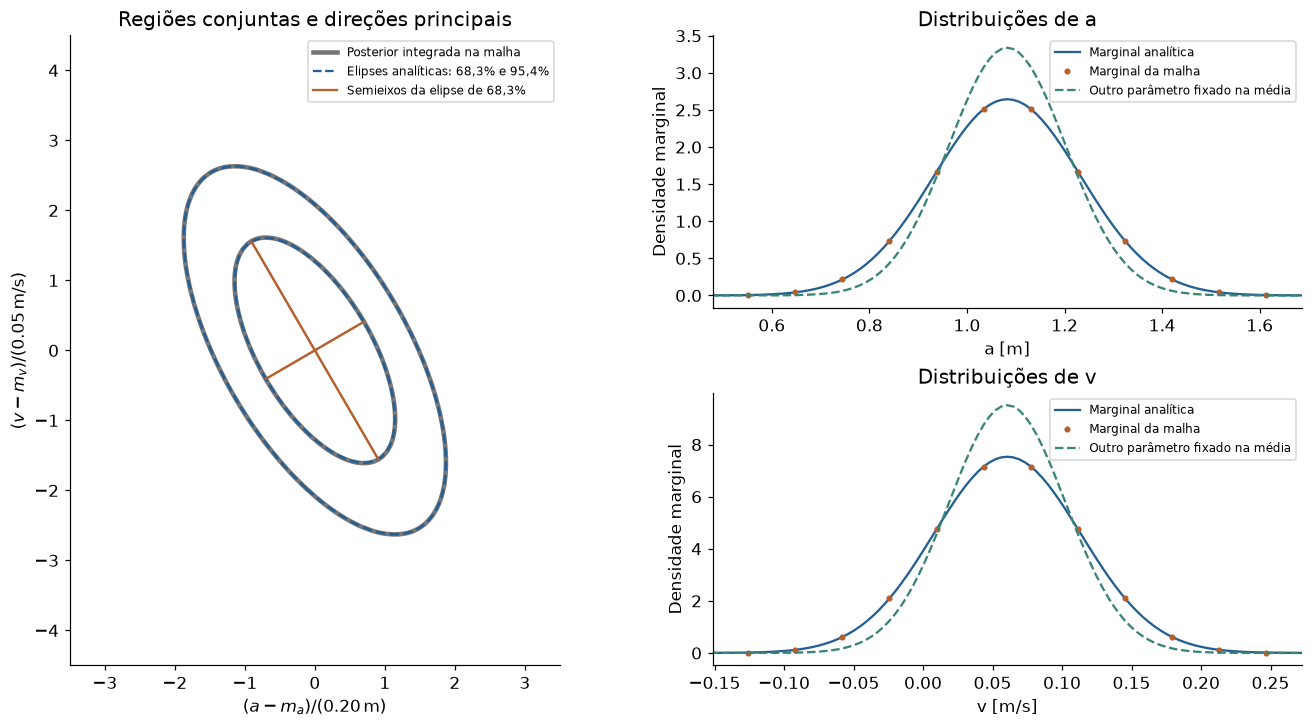

In [10]:
# Integra sobre v para obter a marginal de a.
pa_grid = simpson(pdf_grid, x=eixo_v, axis=0)
# Integra sobre a para obter a marginal de v.
pv_grid = simpson(pdf_grid, x=eixo_a, axis=1)
# Reescreve o eixo a na escala adimensional do gráfico conjunto.
u0 = (pontos[...,0]-m[0])/escala[0,0]
# Reescreve o eixo v na escala adimensional do gráfico conjunto.
u1 = (pontos[...,1]-m[1])/escala[1,1]
# Encontra os níveis de densidade das regiões HPD de 68,3% e 95,4%.
limiares = np.sort(dali.hpd_thresholds_2d(pdf_grid, eixo_a, eixo_v))

# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig = plt.figure(figsize=(12, 6.5), layout="constrained")
# Divide a figura entre o painel conjunto e os dois painéis marginais.
gs = fig.add_gridspec(2, 2, width_ratios=[1.1, 1])
# Associa nomes aos três painéis para desenhar em cada um.
axj, axa, axv = fig.add_subplot(gs[:,0]), fig.add_subplot(gs[0,1]), fig.add_subplot(gs[1,1])
axj.contour(u0, u1, pdf_grid, levels=limiares, colors=CINZA, linewidths=3)
# Percorre as duas probabilidades conjuntas que serão desenhadas.
for prob in (.683, .954):
    # Calcula a elipse analítica com a probabilidade conjunta escolhida.
    elipse = dali.gaussian_ellipse(m, Sigma, prob)
    # Aplica à elipse a mesma mudança de escala usada na malha.
    elipse_u = (elipse-m) @ escala_inv.T
    axj.plot(elipse_u[:,0], elipse_u[:,1], color=AZUL, ls="--", lw=1.7)
# Percorre as duas direções principais da precisão.
for k in range(2):
    # Calcula o semieixo da elipse de 68,3% nessa direção principal.
    vetor = np.sqrt(chi2.ppf(.683, 2)/autovalores[k]) * autovetores[:,k]
    axj.plot([-vetor[0], vetor[0]], [-vetor[1], vetor[1]], color=LARANJA, lw=1.6)
axj.set(xlabel=r"$(a-m_a)/(0.20\,\mathrm{m})$",
        ylabel=r"$(v-m_v)/(0.05\,\mathrm{m/s})$", title="Regiões conjuntas e direções principais")
axj.set_xlim(-3.5, 3.5); axj.set_ylim(-4.5, 4.5)
axj.set_aspect("equal", adjustable="box")
axj.plot([], [], color=CINZA, lw=3, label="Posterior integrada na malha")
axj.plot([], [], color=AZUL, ls="--", label="Elipses analíticas: 68,3% e 95,4%")
axj.plot([], [], color=LARANJA, label="Semieixos da elipse de 68,3%")
axj.legend(fontsize=8)
# Repete a comparação entre marginal e corte para cada parâmetro.
for ax, eixo, marginal, i, nome, unidade in [
    (axa, eixo_a, pa_grid, 0, "a", "m"), (axv, eixo_v, pv_grid, 1, "v", "m/s")]:
    ax.plot(eixo, norm.pdf(eixo, m[i], np.sqrt(Sigma[i,i])), color=AZUL,
            label="Marginal analítica")
    ax.plot(eixo[::8], marginal[::8], ".", color=LARANJA, label="Marginal da malha")
    ax.plot(eixo, norm.pdf(eixo, m[i], np.sqrt(1/Q[i,i])), ls="--", color=VERDE,
            label="Outro parâmetro fixado na média")
    ax.set(xlabel=f"{nome} [{unidade}]", ylabel="Densidade marginal", title=f"Distribuições de {nome}")
    ax.set_xlim(m[i]-4*np.sqrt(Sigma[i,i]), m[i]+4*np.sqrt(Sigma[i,i]))
    ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("02_geometria_e_marginais", fig)


## 1.8. Covariância dos dados, dos parâmetros e de estimadores

É útil separar três perguntas:

1. **Como os erros das posições flutuariam se repetíssemos o experimento?** A resposta está em $C$, uma matriz $N\times N$.
2. **Quanto os parâmetros ainda podem variar depois destes dados e desta prior?** A resposta está na covariância posterior $\Sigma$, uma matriz $p\times p$.
3. **Como a estimativa de máxima likelihood variaria entre repetições do experimento?** Essa é a covariância amostral de um estimador.

No caso linear, $\widehat\theta_{\rm ML}=\theta_{\rm verdadeiro}+F^{-1}X^TC^{-1}\varepsilon$. Portanto,

$$
\operatorname{Cov}_{d\mid\theta}(\widehat\theta_{\rm ML})
=F^{-1}X^TC^{-1}CC^{-1}XF^{-1}=F^{-1}.
$$

A igualdade numérica com a covariância posterior no limite de prior ampla é uma propriedade deste modelo. Com a prior gaussiana, a covariância posterior é $(F+S_0^{-1})^{-1}$.

### O que o erro compartilhado faz fisicamente?

Um deslocamento de calibração é indistinguível de uma alteração em $a$, mas não altera as diferenças de posição que informam $v$. Neste modelo específico, a covariância da likelihood com calibração é

$$
F_C^{-1}=F_{\rm ind}^{-1}+
\begin{pmatrix}\tau_{\rm cal}^2&0\\0&0\end{pmatrix}.
$$

Assim, a incerteza compartilhada cria um piso adicional para a posição inicial.


In [11]:
# Repete o ajuste com somente os erros independentes.
ajuste_ind = dali.linear_gaussian_posterior(X, dados, C_ind)
# Repete o ajuste com o erro comum, mantendo os mesmos dados.
ajuste_cor = dali.linear_gaussian_posterior(X, dados, C_dados)
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("06_efeito_calibracao", pd.DataFrame({
    "Caso": ["Erros independentes", "Com calibração compartilhada"],
    "sigma de a na likelihood [m]": [np.sqrt(ajuste_ind.covariance[0,0]),
                                     np.sqrt(ajuste_cor.covariance[0,0])],
    "sigma de v na likelihood [m/s]": [np.sqrt(ajuste_ind.covariance[1,1]),
                                       np.sqrt(ajuste_cor.covariance[1,1])],
}))
# Confere que só Var(a) recebe o acréscimo tau_cal² previsto.
assert np.allclose(ajuste_cor.covariance-ajuste_ind.covariance,
                  [[tau_cal**2, 0], [0, 0]], atol=1e-12)


,Caso,sigma de a na likelihood [m],sigma de v na likelihood [m/s]
0,Erros independentes,0.113029,0.052976
1,Com calibração compartilhada,0.150915,0.052976


## 1.9. Uma prior informativa muda o problema de inferência

Até aqui usamos uma prior ampla: desvios de $10\,\mathrm m$ em $a$ e $3\,\mathrm{m/s}$ em $v$, centrada em zero. Ela muda muito pouco na região favorecida pela likelihood. Agora queremos responder a uma pergunta diferente: **o que muda se tivermos uma medida anterior e independente da velocidade?**

Manteremos os dados, o modelo e $C$. A única troca será a prior de $v$:

$$
\pi_{\rm ampla}(v)=\mathcal N(0,3^2)
\quad\longrightarrow\quad
\pi_{\rm info}(v)=\mathcal N(0.03,0.04^2),
$$

com velocidades em $\mathrm{m/s}$. A prior de $a$ permanece igual. A nova informação é ilustrativa e não foi estimada dos dados que já usamos.

O fator da likelihood permanece o mesmo. Ao multiplicá-lo pela nova prior, seus expoentes somam-se:

$$
Q_{\rm info}=F+S_{0,\rm info}^{-1},\qquad
Q_{\rm info}m_{\rm info}=F\widehat\theta_{\rm ML}
+S_{0,\rm info}^{-1}m_{0,\rm info}.
$$

A primeira equação mostra por que somamos **precisões**. A segunda mostra como os centros da likelihood e da prior participam da média final. Como $a$ e $v$ são anticorrelacionados, favorecer velocidades menores também pode favorecer posições iniciais maiores.

Antes de olhar o gráfico, esperamos uma marginal de $v$ mais estreita e um centro que se desloque em direção à informação anterior. No painel da direita, a curva verde é a prior usada sozinha; as outras duas são posteriors. No painel conjunto, linhas contínuas delimitam 68,3% e tracejadas delimitam 95,4%. A tabela permite verificar como a mudança se transmite a $a$.

Essa posterior ainda é exatamente gaussiana. Portanto, esta comparação mostra o papel da prior; a fronteira da seção 1.10 será o passo que altera o suporte e quebra essa forma gaussiana.


,Caso,Média de a [m],Média de v [m/s],sigma de a [m],sigma de v [m/s]
0,Prior ampla,1.082649,0.060608,0.150889,0.052965
1,Prior informativa em v,1.116534,0.041121,0.131781,0.031922


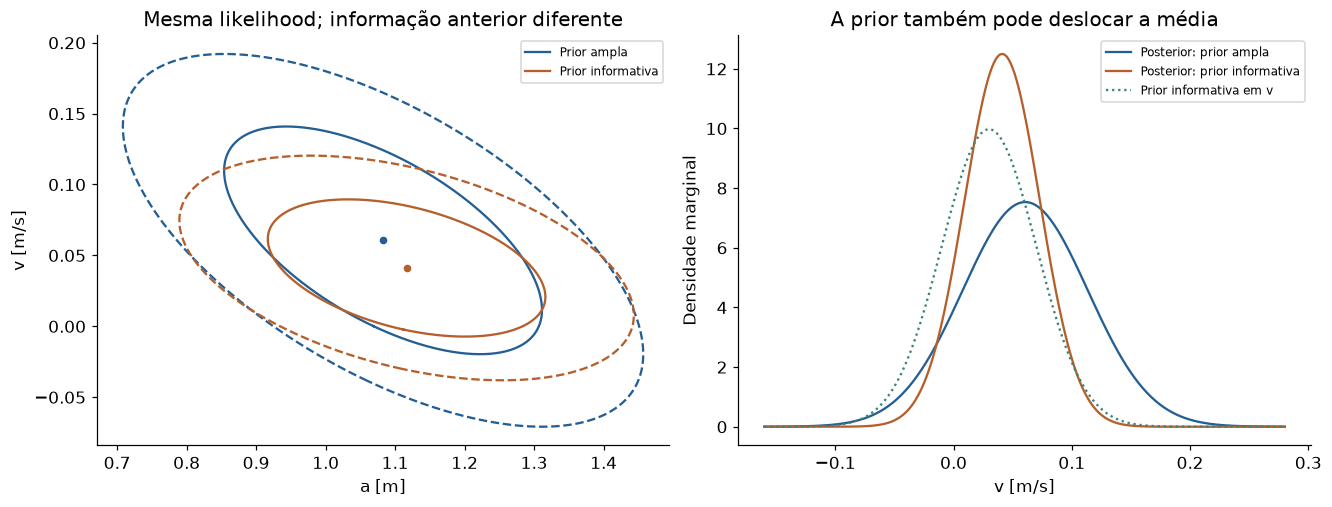

In [12]:
# Escolhe a média da informação anterior sobre v; altere para testar outro centro.
m0_info = np.array([0.0, 0.030])
# Mantém a prior de a e escolhe desvio 0.040 m/s em v; altere para outra força da prior.
S0_info = np.diag([10.0**2, 0.040**2])
# Refaz a posterior com a nova prior e com a mesma likelihood.
ajuste_info = dali.linear_gaussian_posterior(X, dados, C_dados, m0_info, S0_info)

# Cria uma malha que cobre a nova posterior.
a_info, v_info, pts_info = malha_gaussiana(ajuste_info.mean, ajuste_info.covariance)
# Normaliza a posterior formada pela likelihood original e pela nova prior.
p_info, _ = dali.normalize_log_grid(
    log_likelihood_linear(pts_info)+dali.gaussian_logpdf(pts_info, m0_info, S0_info), a_info, v_info
)
# Confere a nova média e covariância por integração.
m_info_grid, S_info_grid = dali.grid_moments_2d(p_info, a_info, v_info)
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(m_info_grid, ajuste_info.mean, atol=1e-9)
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(S_info_grid, ajuste_info.covariance, atol=1e-9)

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("07_prior_gaussiana", pd.DataFrame({
    "Caso": ["Prior ampla", "Prior informativa em v"],
    "Média de a [m]": [m[0], ajuste_info.mean[0]],
    "Média de v [m/s]": [m[1], ajuste_info.mean[1]],
    "sigma de a [m]": [np.sqrt(Sigma[0,0]), np.sqrt(ajuste_info.covariance[0,0])],
    "sigma de v [m/s]": [np.sqrt(Sigma[1,1]), np.sqrt(ajuste_info.covariance[1,1])],
}))

# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
# Compara as duas escolhas de prior com a mesma convenção de cores.
for resultado, cor, nome in [(ajuste, AZUL, "Prior ampla"), (ajuste_info, LARANJA, "Prior informativa")]:
    # Percorre as duas probabilidades conjuntas que serão desenhadas.
    for prob, estilo in [(.683, "-"), (.954, "--")]:
        # Calcula uma elipse analítica para o caso e a probabilidade desta iteração.
        curva = dali.gaussian_ellipse(resultado.mean, resultado.covariance, prob)
        axs[0].plot(curva[:,0], curva[:,1], color=cor, ls=estilo,
                    label=nome if prob==.683 else None)
    axs[0].plot(*resultado.mean, "o", color=cor, ms=4)
    # Escolhe o intervalo em que serão desenhadas as densidades de v.
    v_grafico = np.linspace(-.16, .28, 500)
    axs[1].plot(v_grafico, norm.pdf(v_grafico, resultado.mean[1], np.sqrt(resultado.covariance[1,1])),
                color=cor, label=f"Posterior: {nome.lower()}")
axs[1].plot(v_grafico, norm.pdf(v_grafico, m0_info[1], np.sqrt(S0_info[1,1])),
            color=VERDE, ls=":", label="Prior informativa em v")
axs[0].set(xlabel="a [m]", ylabel="v [m/s]", title="Mesma likelihood; informação anterior diferente")
axs[1].set(xlabel="v [m/s]", ylabel="Densidade marginal", title="A prior também pode deslocar a média")
for ax in axs: ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("03_prior_gaussiana", fig)


## 1.10. Uma fronteira física: mesma curvatura, covariância diferente

Suponha agora que uma informação física adicional selecione movimentos no sentido positivo, incluindo repouso: $v\ge0$. Essa é uma restrição do experimento considerado, uma prior mais restritiva.

Voltaremos à prior ampla do caso-base e a condicionaremos a $v\ge0$. Se $p_0$ denota a posterior gaussiana desse caso, a posterior restringida é

$$
p_+(a,v\mid d)=\frac{p_0(a,v\mid d)\,\mathbf 1_{v\ge0}}{Z_+},
\qquad
Z_+=\int_{v\ge0}p_0(a,v\mid d)\,da\,dv.
$$

$Z_+$ é a **massa aceita pela posterior-base**, não a evidência original dos dados. Os fatores de normalização da prior restringida se cancelam ao normalizar a posterior.

Na região interior permitida, a log-posterior difere da anterior apenas por uma constante; sua Hessiana continua $Q$. Mas a distribuição global é cortada, sua marginal em $v$ se torna assimétrica e seus momentos mudam. Logo, a inversa da curvatura interna não é, em geral, a covariância dessa posterior truncada.

### Referência analítica para a truncagem

Definimos $\sigma_v=\sqrt{\Sigma_{vv}}$, $\alpha=-m_v/\sigma_v$, $Z_+=1-\Phi(\alpha)$ e $\lambda=\varphi(\alpha)/Z_+$, onde $\varphi$ e $\Phi$ são a densidade e a acumulada da normal padrão. A integral por partes da cauda gaussiana dá

$$
\mathbb E[v\mid v\ge0,d]=m_v+\sigma_v\lambda,
\quad
\operatorname{Var}(v\mid v\ge0,d)=\sigma_v^2(1+\alpha\lambda-\lambda^2).
$$

Usando a distribuição condicional gaussiana de $a$ dado $v$, obtemos os momentos conjuntos:

$$
m_+=m+\frac{\Sigma_{:,v}}{\sigma_v}\lambda,
\qquad
\Sigma_+=\Sigma-\frac{\Sigma_{:,v}\Sigma_{v,:}}{\sigma_v^2}
\lambda(\lambda-\alpha).
$$

A notação $\Sigma_{:,v}$ representa a coluna associada a $v$. A mudança da média de $a$ resulta da correlação entre os parâmetros.

**Antes de executar:** se retirarmos a cauda de velocidades negativas, em que sentido a média de $v$ deve mudar? E a de $a$, que é anticorrelacionada com $v$?


In [13]:
# Calcula os momentos exatos ao condicionar a gaussiana a v >= 0.
m_mais, Sigma_mais, massa_aceita = dali.lower_truncated_gaussian_moments(m, Sigma, index=1)
# Extrai os desvios do caso-base para definir a malha truncada.
sigma_a, sigma_v = np.sqrt(np.diag(Sigma))
# Mantém um domínio amplo em a; 321 controla a resolução.
a_mais = np.linspace(m[0]-8*sigma_a, m[0]+8*sigma_a, 321)
# Começa a integração em v=0, a fronteira física declarada.
v_mais = np.linspace(0.0, m[1]+8*sigma_v, 321)
# Forma os pares de coordenadas dentro do domínio permitido.
aa_mais, vv_mais = np.meshgrid(a_mais, v_mais)
# Coloca cada par (a,v) na última dimensão do array.
pts_mais = np.stack((aa_mais, vv_mais), axis=-1)

# Integramos apenas o domínio permitido: não inserimos uma descontinuidade
# artificial no meio da malha de quadratura.
p_mais, log_massa_grid = dali.normalize_log_grid(
    dali.gaussian_logpdf(pts_mais, m, Sigma), a_mais, v_mais
)
# Integra os momentos da posterior truncada para confrontar com as fórmulas.
m_mais_grid, S_mais_grid = dali.grid_moments_2d(p_mais, a_mais, v_mais)
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("08_fronteira_momentos", pd.DataFrame({
    "Quantidade": ["média de a [m]", "média de v [m/s]", "Var(a) [m²]",
                   "Cov(a,v) [m²/s]", "Var(v) [m²/s²]", "Massa aceita Z+"],
    "Gaussiana sem corte": [m[0], m[1], Sigma[0,0], Sigma[0,1], Sigma[1,1], 1.0],
    "Truncagem analítica": [m_mais[0], m_mais[1], Sigma_mais[0,0], Sigma_mais[0,1],
                           Sigma_mais[1,1], massa_aceita],
    "Truncagem em malha": [m_mais_grid[0], m_mais_grid[1], S_mais_grid[0,0], S_mais_grid[0,1],
                          S_mais_grid[1,1], np.exp(log_massa_grid)],
}))
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(m_mais_grid, m_mais, atol=1e-7)
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(S_mais_grid, Sigma_mais, atol=1e-8)
print(f"Massa que a gaussiana-base atribui a v < 0: {100*(1-massa_aceita):.4f}%")
print(f"Massa em v >= 0: analítica={massa_aceita:.10f}; malha={np.exp(log_massa_grid):.10f}")


,Quantidade,Gaussiana sem corte,Truncagem analítica,Truncagem em malha
0,média de a [m],1.082649,1.060800,1.060800
1,média de v [m/s],0.060608,0.073174,0.073174
2,Var(a) [m²],0.022768,0.019987,0.019987
3,"Cov(a,v) [m²/s]",-0.004878,-0.003279,-0.003279
4,Var(v) [m²/s²],0.002805,0.001886,0.001886
5,Massa aceita Z+,1.000000,0.873750,0.873750


Massa que a gaussiana-base atribui a v < 0: 12.6250%
Massa em v >= 0: analítica=0.8737500201; malha=0.8737500216


In [14]:
# Reúne os erros ao refinar a malha da posterior truncada.
linhas_mais = []
# Varia resolução ou domínio para verificar a integração.
for n in (81, 161, 321):
    # Constrói uma malha para a resolução ou o domínio em teste.
    a_n = np.linspace(m[0]-8*sigma_a, m[0]+8*sigma_a, n)
    # Monta o eixo vertical da malha em teste.
    v_n = np.linspace(0, m[1]+8*sigma_v, n)
    # Combina os eixos da malha em teste.
    aa_n, vv_n = np.meshgrid(a_n, v_n)
    # Normaliza a densidade na malha em teste.
    p_n, lz_n = dali.normalize_log_grid(
        dali.gaussian_logpdf(np.stack((aa_n, vv_n), -1), m, Sigma), a_n, v_n
    )
    # Calcula os momentos na malha em teste.
    mn, Sn = dali.grid_moments_2d(p_n, a_n, v_n)
    linhas_mais.append({"Nós por eixo": n, "Erro em Z+": abs(np.exp(lz_n)-massa_aceita),
                        "Erro máximo na média": np.max(abs(mn-m_mais)),
                        "Erro máximo na covariância": np.max(abs(Sn-Sigma_mais))})
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("09_refinamento_fronteira", pd.DataFrame(linhas_mais))


,Nós por eixo,Erro em Z+,Erro máximo na média,Erro máximo na covariância
0,81,3.815598e-07,7.531193e-08,3.613250e-09
1,161,2.378808e-08,4.674238e-09,2.272526e-10
2,321,1.485826e-09,2.916338e-10,1.422619e-11


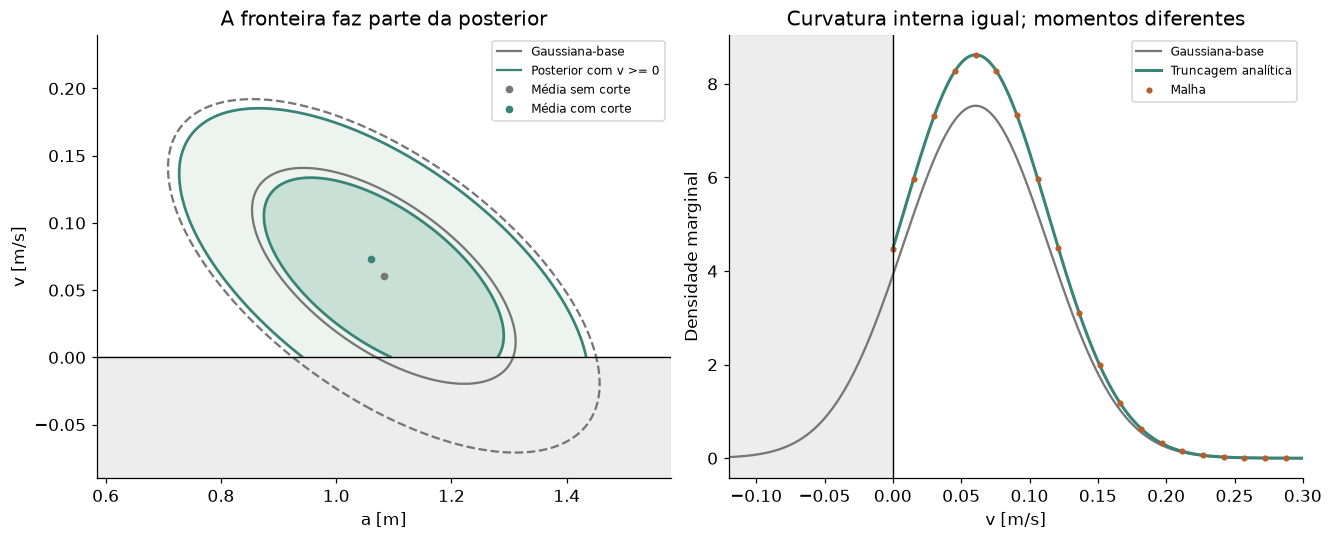

In [15]:
# Integra a para obter a marginal de v depois do corte.
pv_mais = simpson(p_mais, x=a_mais, axis=1)
# Calcula os níveis HPD da posterior que já foi truncada e renormalizada.
lim_mais = np.sort(dali.hpd_thresholds_2d(p_mais, a_mais, v_mais))
# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
# Percorre as duas probabilidades conjuntas que serão desenhadas.
for prob, estilo in [(.683, "-"), (.954, "--")]:
    # Calcula uma elipse analítica para o caso e a probabilidade desta iteração.
    curva = dali.gaussian_ellipse(m, Sigma, prob)
    axs[0].plot(curva[:,0], curva[:,1], color=CINZA, ls=estilo,
                label="Gaussiana-base" if prob==.683 else None)
axs[0].contourf(aa_mais, vv_mais, p_mais,
                levels=[*lim_mais, p_mais.max()*1.001], colors=["#edf4f0", "#c8e0d6"])
axs[0].contour(aa_mais, vv_mais, p_mais, levels=lim_mais, colors=VERDE, linewidths=1.8)
axs[0].plot([], [], color=VERDE, label="Posterior com v >= 0")
axs[0].axhline(0, color="black", lw=.9)
axs[0].axhspan(-.09, 0, color="#dddddd", alpha=.5)
axs[0].plot(*m, "o", color=CINZA, ms=4, label="Média sem corte")
axs[0].plot(*m_mais, "o", color=VERDE, ms=4, label="Média com corte")
axs[0].set(xlabel="a [m]", ylabel="v [m/s]", title="A fronteira faz parte da posterior",
            xlim=(m[0]-3.3*sigma_a, m[0]+3.3*sigma_a), ylim=(-.09, .24))
# Escolhe um eixo que também mostra a região excluída pela fronteira.
v_des = np.linspace(-.12, .30, 550)
axs[1].plot(v_des, norm.pdf(v_des, m[1], sigma_v), color=CINZA, label="Gaussiana-base")
axs[1].plot(v_mais, norm.pdf(v_mais, m[1], sigma_v)/massa_aceita,
            color=VERDE, lw=2, label="Truncagem analítica")
axs[1].plot(v_mais[::10], pv_mais[::10], ".", color=LARANJA, label="Malha")
axs[1].axvline(0, color="black", lw=.9)
axs[1].axvspan(-.12, 0, color="#dddddd", alpha=.5)
axs[1].set(xlabel="v [m/s]", ylabel="Densidade marginal", title="Curvatura interna igual; momentos diferentes",
            xlim=(-.12, .30))
for ax in axs: ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("04_fronteira_fisica", fig)


As mudanças dos momentos analíticos e numéricos concordam. A condição $v\ge0$ remove massa, exige renormalização e desloca as médias. Dentro do suporte permitido, a curvatura permanece a mesma da gaussiana-base. Neste conjunto de dados, o MAP gaussiano já tem $v>0$ e permanece no mesmo ponto após o corte, embora a média e a covariância mudem.

Se o máximo não restringido estivesse fora do suporte, o MAP restringido poderia estar na fronteira. Nesse caso, a expansão usual em torno de um máximo interior, com gradiente nulo, exigiria ainda mais cuidado.

**Esta não gaussianidade vem da prior e do suporte.** Não precisamos de derivadas superiores da likelihood para representá-la: podemos manter a prior exata. Isso será importante para separar as motivações de DALI no próximo bloco.


## 1.11. Erros gaussianos, priors gaussianas e uma posterior curva

Agora queremos isolar uma origem diferente de não gaussianidade: a **relação não linear entre parâmetros e observáveis**. Usaremos duas medidas adimensionais e parâmetros também adimensionais $q=(q_1,q_2)$:

$$
d=\begin{pmatrix}0\\0\end{pmatrix},\qquad
\mu(q)=\begin{pmatrix}q_1\\q_2-\kappa q_1^2\end{pmatrix},\qquad
C_{\rm nl}=\operatorname{diag}(1,0.4^2),\qquad\kappa=0.65.
$$

O experimento mede uma resposta linear e outra que mistura a segunda coordenada com uma resposta quadrática da primeira. O ruído de ambos os canais é gaussiano. Os dados $(0,0)$ são o valor observado escolhido para este exemplo, e não uma hipótese de ruído com variância nula.

Adotaremos priors gaussianas próprias $q_1\sim\mathcal N(0,3^2)$ e $q_2\sim\mathcal N(0,5^2)$. Assim,

$$
-\log p(q\mid d)=\mathrm{const}
+\frac12q_1^2+\frac{(q_2-\kappa q_1^2)^2}{2(0.4)^2}
+\frac{q_1^2}{2(3)^2}+\frac{q_2^2}{2(5)^2}.
$$

Todos os termos são não negativos e se anulam simultaneamente apenas em $q=(0,0)$, o MAP. O Jacobiano do modelo nesse ponto é a identidade. Como o resíduo é nulo, o Fisher esperado coincide com a curvatura observada ali, e a precisão local da posterior é

$$
Q_{\rm local}=\operatorname{diag}\left(1+\frac19,\;\frac{1}{0.4^2}+\frac1{25}\right).
$$

A curvatura local nem sequer depende de $\kappa$, embora a geometria global da posterior dependa. A likelihood prefere $q_2\approx\kappa q_1^2$: ao nos afastarmos do pico, a região favorecida se curva.

**Antes de executar:** se a elipse local é simétrica em $q_2$ e a região favorecida se curva para $q_2>0$, você espera que a média global de $q_2$ ainda coincida com o MAP?


In [16]:
# Controla a curvatura do modelo; altere para explorar a não linearidade.
kappa = 0.65
# Escolhe as variâncias gaussianas dos dois canais do novo modelo.
C_nl = np.diag([1.0, 0.4**2])
# Escolhe o centro das priors gaussianas do exemplo não linear.
prior_nl_media = np.zeros(2)
# Escolhe as larguras dessas priors; elas são próprias.
prior_nl_cov = np.diag([3.0**2, 5.0**2])
# Usa o Jacobiano no MAP, que é a identidade neste modelo.
F_nl_local = dali.fisher_gaussian(np.eye(2), C_nl)
# Soma a precisão da prior à informação da likelihood no MAP.
Q_nl_local = F_nl_local + np.linalg.solve(prior_nl_cov, np.eye(2))
# Obtém a covariância da gaussiana local.
Sigma_nl_local = np.linalg.solve(Q_nl_local, np.eye(2))

def log_posterior_nl(pontos):
    # Converte os pontos recebidos em um array para avaliar o modelo.
    pontos = np.asarray(pontos)
    # Calcula as duas respostas, incluindo a dependência quadrática.
    modelo = np.stack((pontos[...,0], pontos[...,1]-kappa*pontos[...,0]**2), -1)
    return (dali.gaussian_logpdf(-modelo, [0, 0], C_nl)
            + dali.gaussian_logpdf(pontos, prior_nl_media, prior_nl_cov))

# Escolhe o domínio e a resolução do primeiro parâmetro; refine para testar convergência.
q1 = np.linspace(-5.5, 5.5, 501)
# Escolhe um domínio maior na cauda positiva do segundo parâmetro.
q2 = np.linspace(-3.5, 18.0, 501)
# Combina os eixos para avaliar a posterior completa.
qq1, qq2 = np.meshgrid(q1, q2)
# Agrupa as duas coordenadas de cada ponto da malha.
pts_nl = np.stack((qq1, qq2), -1)
# Normaliza a posterior não linear na malha escolhida.
p_nl, log_Z_nl = dali.normalize_log_grid(log_posterior_nl(pts_nl), q1, q2)
# Calcula a média e a covariância globais, sem a aproximação gaussiana.
m_nl, S_nl = dali.grid_moments_2d(p_nl, q1, q2)
# Integra q1 para obter a marginal do parâmetro q2.
pv_nl = simpson(p_nl, x=q1, axis=1)
# Mede a correlação linear, que não detecta toda dependência não linear.
rho_nl = S_nl[0,1]/np.sqrt(S_nl[0,0]*S_nl[1,1])
# Calcula o terceiro momento central padronizado da marginal de q2.
skew_q2 = simpson((q2-m_nl[1])**3*pv_nl, x=q2)/S_nl[1,1]**1.5

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("10_posterior_nao_linear", pd.DataFrame({
    "Quantidade": ["média q1", "média q2", "Var(q1)", "Cov(q1,q2)", "Var(q2)"],
    "Gaussiana local": [0.0, 0.0, Sigma_nl_local[0,0], Sigma_nl_local[0,1], Sigma_nl_local[1,1]],
    "Posterior completa em malha": [m_nl[0], m_nl[1], S_nl[0,0], S_nl[0,1], S_nl[1,1]],
}))
print(f"Correlação linear q1-q2 na posterior completa: {rho_nl:.3e}")
print(f"Assimetria da marginal q2 na malha: {skew_q2:.6f}")


,Quantidade,Gaussiana local,Posterior completa em malha
0,média q1,0.000000,3.735882e-18
1,média q2,0.000000,5.417134e-01
2,Var(q1),0.900000,8.387391e-01
3,"Cov(q1,q2)",0.000000,1.278953e-17
4,Var(q2),0.158983,7.109646e-01


Correlação linear q1-q2 na posterior completa: 1.656e-17
Assimetria da marginal q2 na malha: 1.775200


In [17]:
# Guarda os resultados para diferentes resoluções e domínios.
checagens_nl = []
# Varia resolução ou domínio para verificar a integração.
for n, limites in [(251, (-5.5,5.5,-3.5,18)), (501, (-5.5,5.5,-3.5,18)),
                   (601, (-6,6,-4,24))]:
    # Monta o primeiro eixo da malha não linear em teste.
    x_n = np.linspace(limites[0], limites[1], n)
    # Monta o segundo eixo da malha não linear em teste.
    y_n = np.linspace(limites[2], limites[3], n)
    # Forma os pares de coordenadas da malha não linear em teste.
    xx_n, yy_n = np.meshgrid(x_n, y_n)
    # Normaliza a densidade na malha em teste.
    p_n, lz_n = dali.normalize_log_grid(log_posterior_nl(np.stack((xx_n, yy_n), -1)), x_n, y_n)
    # Calcula os momentos na malha em teste.
    mn, Sn = dali.grid_moments_2d(p_n, x_n, y_n)
    checagens_nl.append({"Nós por eixo": n, "Domínio": str(limites),
                         "Média q2": mn[1], "Var(q2)": Sn[1,1], "Var(q1)": Sn[0,0],
                         "Diferença máxima na média vs. principal": np.max(abs(mn-m_nl)),
                         "Diferença máxima na covariância vs. principal": np.max(abs(Sn-S_nl)),
                         "Diferença em log Z vs. principal": abs(lz_n-log_Z_nl)})
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("11_refinamento_nao_linear", pd.DataFrame(checagens_nl))
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.max(abs(mn-m_nl)) < 1e-7
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.max(abs(Sn-S_nl)) < 1e-7


,Nós por eixo,Domínio,Média q2,Var(q2),Var(q1),Diferença máxima na média vs. principal,Diferença máxima na covariância vs. principal,Diferença em log Z vs. principal
0,251,"(-5.5, 5.5, -3.5, 18)",0.541713,0.710965,0.838739,5.551115e-15,9.714451e-14,0.000000e+00
1,501,"(-5.5, 5.5, -3.5, 18)",0.541713,0.710965,0.838739,0.000000e+00,0.000000e+00,0.000000e+00
2,601,"(-6, 6, -4, 24)",0.541713,0.710965,0.838739,4.744829e-10,8.561867e-09,2.626699e-11


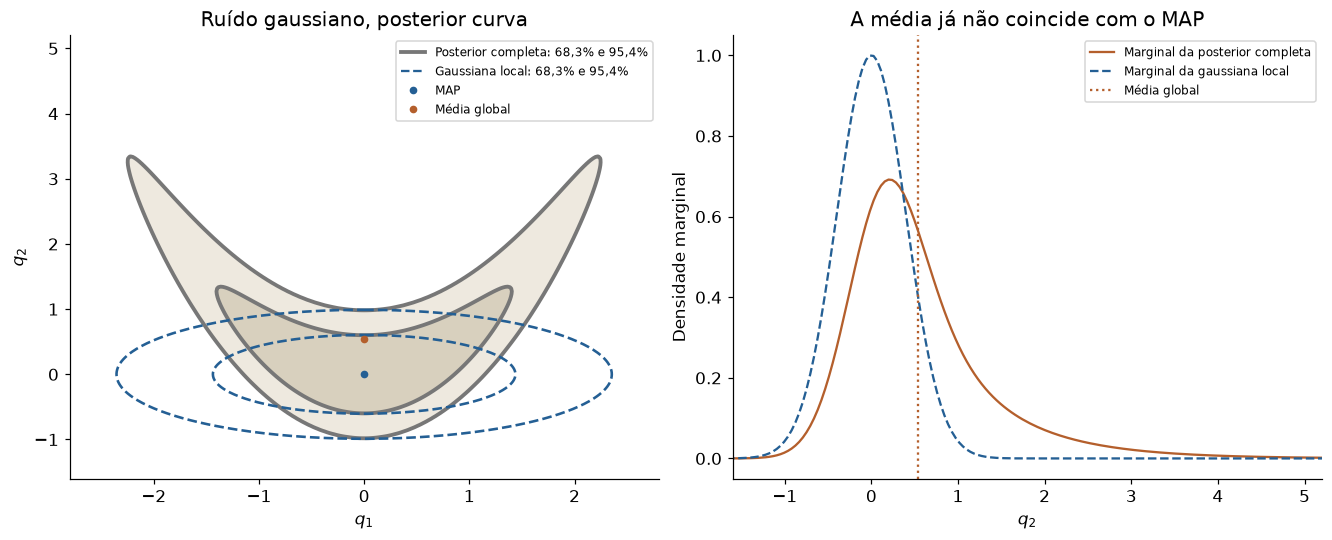

In [18]:
# Calcula os níveis HPD da posterior completa para compará-los com as elipses.
lim_nl = np.sort(dali.hpd_thresholds_2d(p_nl, q1, q2))
# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axs[0].contourf(qq1, qq2, p_nl, levels=[*lim_nl, p_nl.max()*1.001],
                colors=["#eee9df", "#d8d0be"])
axs[0].contour(qq1, qq2, p_nl, levels=lim_nl, colors=CINZA, linewidths=2.5)
# Percorre as duas probabilidades conjuntas que serão desenhadas.
for prob in (.683, .954):
    # Calcula uma elipse analítica para o caso e a probabilidade desta iteração.
    curva = dali.gaussian_ellipse([0,0], Sigma_nl_local, prob)
    axs[0].plot(curva[:,0], curva[:,1], color=AZUL, ls="--", lw=1.7)
axs[0].plot([], [], color=CINZA, lw=2.5, label="Posterior completa: 68,3% e 95,4%")
axs[0].plot([], [], color=AZUL, ls="--", label="Gaussiana local: 68,3% e 95,4%")
axs[0].plot(0, 0, "o", color=AZUL, ms=4, label="MAP")
axs[0].plot(*m_nl, "o", color=LARANJA, ms=4, label="Média global")
axs[0].set(xlabel=r"$q_1$", ylabel=r"$q_2$", title="Ruído gaussiano, posterior curva",
            xlim=(-2.8,2.8), ylim=(-1.6,5.2))
axs[1].plot(q2, pv_nl, color=LARANJA, label="Marginal da posterior completa")
axs[1].plot(q2, norm.pdf(q2, 0, np.sqrt(Sigma_nl_local[1,1])), color=AZUL, ls="--",
            label="Marginal da gaussiana local")
axs[1].axvline(m_nl[1], color=LARANJA, ls=":", label="Média global")
axs[1].set(xlabel=r"$q_2$", ylabel="Densidade marginal", title="A média já não coincide com o MAP",
            xlim=(-1.6,5.2))
for ax in axs: ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("05_posterior_curva", fig)


A malha mostra uma média positiva em $q_2$, uma marginal assimétrica e uma largura global que a gaussiana local não recupera. A comparação entre resoluções e domínios permite avaliar se isso poderia ser apenas um erro de integração.

Há um detalhe: a posterior é simétrica em $q_1\to-q_1$. Por isso, sua média em $q_1$ e a covariância linear entre $q_1$ e $q_2$ se anulam. Ainda assim, as coordenadas não são independentes: o valor favorecido de $q_2$ acompanha aproximadamente $\kappa q_1^2$. **Correlação linear nula não implica independência numa distribuição geral.**

Este exemplo não precisou de erros não gaussianos nem de uma fronteira próxima. A forma não gaussiana surge da resposta quadrática do modelo. A aproximação local descreve a região imediatamente próxima ao máximo, mas não toda a massa da posterior.


## 1.12. O que a inversa de Fisher nos diz — e o que ela não diz?

| Situação | Curvatura e covariância | 
|---|---|
| Modelo linear, ruído gaussiano com $C$ fixa, prior aproximadamente constante na região relevante | $F^{-1}$ descreve a covariância no limite de prior ampla. |
| Mesmo modelo e prior gaussiana própria | A posterior é exatamente gaussiana, com covariância $(F+S_0^{-1})^{-1}$. |
| Likelihood quadrática com prior cortada por uma fronteira | A curvatura interna pode permanecer igual, enquanto os momentos globais mudam. |
| Modelo não linear | A curvatura dá uma descrição local; os termos além da forma quadrática podem modificar as regiões e as marginais. |
| Informação esperada singular | Há uma direção que o modelo não identifica na ordem considerada; inverter a matriz não é uma operação válida sem tratar essa situação. |

Para qualquer análise, precisamos declarar o que é a matriz usada, em que ponto foi avaliada, qual prior foi mantida e se a região importante está bem descrita pela expansão local.


## 1.13. E se quisermos ir além da forma gaussiana?

Construímos primeiro um caso em que a forma quadrática é exata e depois encontramos dois mecanismos de não gaussianidade: uma prior com fronteira e uma resposta não linear do modelo.

No primeiro, manter a prior exata já representa o corte. No segundo, mesmo com priors gaussianas suaves e com o máximo bem localizado, a forma quadrática perde a curvatura global da região favorecida. Essa é a motivação para investigar derivadas superiores do modelo.

Podemos então perguntar:

> **E se quisermos caracterizar e recuperar as não gaussianidades? Podemos ir além da expansão até segunda ordem? Por que não simplesmente acrescentar ordens maiores?**

Uma dificuldade já aparece numa dimensão. Se $\psi=-\log p$ e cortarmos sua expansão em

$$
\psi(\Delta)\simeq\psi_0+\frac12h\Delta^2+\frac16t\Delta^3,
$$

com $h>0$ e $t\ne0$, o termo cúbico domina com sinal negativo em uma das caudas. A exponencial $e^{-\psi}$ então cresce sem limite nessa cauda, caso o suporte seja ilimitado. Acrescentar um termo pode destruir a normalização em vez de melhorar a distribuição. Uma prior de suporte finito pode evitar a divergência da integral sem garantir uma boa aproximação.

No próximo bloco, vamos estudar **como DALI reorganiza os termos da expansão**, distinguindo a ordem das derivadas do modelo da potência dos deslocamentos no expoente. A pergunta será como conservar uma construção probabilística bem definida e, ao mesmo tempo, recuperar parte da geometria que Fisher não descreveu.

<a id="bloco-2"></a>

# 2. Hierarquia de DALI

No Bloco 1, a resposta linear dos observáveis produziu uma likelihood exatamente quadrática nos parâmetros. Depois, uma resposta não linear curvou a posterior e mostrou o que a elipse local deixava de representar. Vamos agora modificar a aproximação do **modelo**, conservando a estrutura gaussiana dos erros.

A ideia central será: **escolher até qual derivada aproximamos o modelo e manter inteiro o quadrado do resíduo correspondente**. Isso produz singleto, dubleto e tripleto de DALI (*Derivative Approximation for LIkelihoods*).

Seguiremos uma única dedução: likelihood gaussiana → Taylor do modelo → quadrado completo → hierarquia. Ao final, teremos funções para avaliar as três ordens; as comparações entre posteriors, malhas e amostragem virão nos exemplos do Bloco 3.


## 2.1. Ponto de partida: o que permanece fixo?

Mantemos as hipóteses do bloco anterior:

$$
d=\mu(\theta)+\varepsilon,\qquad
\varepsilon\sim\mathcal N(0,C),\qquad
\mathcal L(\theta)=\mathcal N_C
\exp\!\left[-\frac12\|d-\mu(\theta)\|_M^2\right],
$$

onde $M=C^{-1}$, $\langle x,y\rangle_M=x^TMy$, $\|x\|_M^2=x^TMx$ e $\mathcal N_C=(2\pi)^{-N/2}|C|^{-1/2}$. $C$ é conhecida, simétrica, definida positiva e **independente de $\theta$**. Ela pode conter correlações entre os dados, como a calibração do Bloco 1.

Escolhemos um ponto $\theta_0$ e definimos

$$
\Delta=\theta-\theta_0,\qquad \mu_0=\mu(\theta_0),\qquad r_0=d-\mu_0.
$$

$\theta_0$ pode ser um fiducial de forecast ou um ponto de ajuste; vamos declarar qual caso usamos. $r_0=0$ significa que os dados escolhidos coincidem com a previsão nesse ponto. **Estar num máximo de likelihood não implica, em geral, $r_0=0$.**

O modelo precisa ter as derivadas utilizadas na região do centro. Para interpretar um resto de Taylor de ordem $K$, também precisamos controlar as derivadas seguintes nessa região. Suavidade local não garante precisão em todo o suporte da posterior. A prior continuará explícita, $p(\theta\mid d)\propto\mathcal L(\theta)\pi(\theta)$.


## 2.2. Podemos simplesmente expandir em parâmetros?

**Podemos fazer uma expansão de Taylor em torno de $\theta_0$.** O cuidado está em usar seu truncamento local como se ele definisse uma distribuição global. DALI também usa deslocamentos nos parâmetros; o que muda é o critério de truncamento.

Se expandirmos $\psi=-\log\mathcal L$ até grau três em uma dimensão,

$$
\psi(\Delta)\simeq\psi_0+\frac12h\Delta^2+\frac16g\Delta^3,
$$

com $h>0$ e $g\ne0$, uma cauda terá $\psi\to-\infty$. A exponencial continua positiva, mas cresce sem limite. Em suporte ilimitado e com prior constante, não será integrável. Adicionar grau quatro também não resolve automaticamente: seu coeficiente pode ser negativo em alguma direção.

Há duas questões distintas: um polinômio usado para aproximar diretamente uma **densidade** pode ficar negativo; uma exponencial de um polinômio real é positiva, mas pode ter caudas não integráveis. Nosso objetivo é conservar uma estrutura de soma de quadrados para evitar que a likelihood aproximada exploda nas caudas. A normalização em parâmetros ainda será examinada na seção 2.7.


## 2.3. Expandir o modelo e só então formar o quadrado

As derivadas abaixo são avaliadas em $\theta_0$. O índice $i$ percorre os $N$ dados; $a,b,c$ percorrem os $p$ parâmetros. Índices de parâmetros repetidos são somados:

$$
J_{ia}=\partial_a\mu_i,\qquad
H_{iab}=\partial_a\partial_b\mu_i,\qquad
T_{iabc}=\partial_a\partial_b\partial_c\mu_i.
$$

Aqui $H$ é a segunda derivada do **modelo**, não a Hessiana da log-likelihood. Para reduzir a quantidade de índices, definimos vetores no espaço dos dados:

$$
A_i=J_{ia}\Delta_a,\qquad
B_i=H_{iab}\Delta_a\Delta_b,\qquad
D_i=T_{iabc}\Delta_a\Delta_b\Delta_c.
$$

Os fatores de Taylor ainda não entraram nesses vetores. A mudança aproximada da previsão é

$$
\mathcal T_1=A,\qquad
\mathcal T_2=A+\frac12B,\qquad
\mathcal T_3=A+\frac12B+\frac16D,
$$

ou, em geral,

$$
\mathcal T_K(\Delta)=\sum_{n=1}^K\frac1{n!}
\mu_{,a_1\cdots a_n}\Delta_{a_1}\cdots\Delta_{a_n}.
$$

Substituímos $\mu(\theta)\approx\mu_0+\mathcal T_K$ na likelihood original e **não cortamos o quadrado depois disso**:

$$
\boxed{E_K(\Delta)=\frac12\|r_0-\mathcal T_K(\Delta)\|_M^2,\qquad
\mathcal L_K(\theta)=\mathcal N_C e^{-E_K(\Delta)}}.
$$

Essa expressão também deixa claro o que o código aproximará: a previsão do modelo dentro da mesma distribuição dos erros. Primeiro vamos derivar a hierarquia com $r_0=0$; depois retomaremos os dados com resíduo não nulo.


## 2.4. Singleto, dubleto e tripleto

### Singleto: somente a resposta linear

Para $K=1$ e $r_0=0$,

$$
E_1=\frac12\langle A,A\rangle_M
=\frac12\Delta^T\underbrace{J^TMJ}_{F^{\rm exp}(\theta_0)}\Delta.
$$

O **singleto de DALI tem o mesmo núcleo gaussiano da aproximação de Fisher esperado**, no centro escolhido. Essa equivalência não exige inverter $F$. Para obter a posterior, multiplicamos $e^{-E_1}$ pela prior declarada.

Com prior constante e $F$ definida positiva, a covariância é $F^{-1}$. Com prior gaussiana, recuperamos $(F+S_0^{-1})^{-1}$. Com uma fronteira ou outra prior não gaussiana, podemos avaliar o mesmo singleto e conservar a prior exata; sua posterior pode deixar de ser gaussiana, como já vimos. A inversão de Fisher é uma conveniência do caso gaussiano, não uma etapa obrigatória da avaliação de DALI.


### Dubleto: conservar juntos os termos gerados por $H$

Para $K=2$,

$$
\begin{aligned}
E_2&=\frac12\left\langle A+\frac12B,A+\frac12B\right\rangle_M\\
&=\boxed{\frac12\langle A,A\rangle_M
+\frac12\langle A,B\rangle_M
+\frac18\langle B,B\rangle_M}.
\end{aligned}
$$

O coeficiente $1/2$ do termo cruzado vem dos dois produtos iguais, $\langle A,B/2\rangle_M$ e $\langle B/2,A\rangle_M$, multiplicados pelo $1/2$ externo. O coeficiente $1/8$ vem de $(1/2)(1/2)^2$.

Em índices,

$$
E_2=\frac12 J_{ia}M_{ij}J_{jb}\Delta_a\Delta_b
+\frac12 J_{ia}M_{ij}H_{jbc}\Delta_a\Delta_b\Delta_c
+\frac18 H_{iab}M_{ij}H_{jcd}\Delta_a\Delta_b\Delta_c\Delta_d.
$$

Agora há potências dois, três e quatro em $\Delta$, embora só tenhamos calculado derivadas até segunda ordem do modelo. O termo cúbico pode ser negativo, mas faz parte de um quadrado completo. Retirá-lo ou retirar o termo quártico, mantendo o outro, mudaria a aproximação que acabamos de construir.


### Tripleto: acrescentar todos os produtos gerados por $T$

Para $K=3$, o quadrado completo dá

$$
\begin{aligned}
E_3&=\frac12\left\|A+\frac12B+\frac16D\right\|_M^2\\
&=\boxed{E_2+\frac16\langle A,D\rangle_M
+\frac1{12}\langle B,D\rangle_M
+\frac1{72}\langle D,D\rangle_M}.
\end{aligned}
$$

Os novos termos têm graus quatro, cinco e seis. Seus fatores são, respectivamente, $(1/2)\,2\,(1)(1/6)$, $(1/2)\,2\,(1/2)(1/6)$ e $(1/2)(1/6)^2$.

**O tripleto não consiste em adicionar apenas um termo de grau seis ao dubleto.** Os três produtos novos vêm da mesma terceira derivada e permanecem juntos. O termo de grau seis é não negativo, mas pode se anular em determinadas direções. A garantia mais direta vem do quadrado completo, que continuaremos usando no código.


## 2.5. Ordem da derivada não é grau no expoente

| Aproximação, com $r_0=0$ | Maior derivada do modelo | Produtos mantidos | Graus possíveis em $E_K$ |
|---|---|---|---|
| Singleto | $J$: primeira | $JJ$ | 2 |
| Dubleto | $H$: segunda | $JJ,JH,HH$ | 2, 3, 4 |
| Tripleto | $T$: terceira | Os anteriores e $JT,HT,TT$ | 2, 3, 4, 5, 6 |

Se uma derivada se anular, alguns desses termos desaparecem. Em ordem geral, $E_K=\frac12\sum_{n,m\le K}\langle\mu^{(n)}[\Delta^n],\mu^{(m)}[\Delta^m]\rangle_M/(n!m!)$. Ao juntar os pares iguais, o coeficiente é $1/(n!m!)$ para $n\ne m$ e $1/[2(n!)^2]$ para $n=m$.

Essa contagem esclarece uma diferença importante: **dubleto não é a Taylor completa de $-\log\mathcal L$ até grau quatro**. A Taylor completa também teria o produto $JT$, que o dubleto não conhece. O tripleto recupera esse produto e conserva ainda termos selecionados de graus cinco e seis.

Para um modelo suficientemente suave e $r_0=0$, o resto $R_K=\mu-\mu_0-\mathcal T_K=O(\|\Delta\|^{K+1})$ produz

$$
E_{\rm exato}-E_K
=\langle\mathcal T_K,R_K\rangle_M+\frac12\|R_K\|_M^2
=O(\|\Delta\|^{K+2}).
$$

Assim, genericamente o dubleto coincide com a Taylor do expoente até grau três, e o tripleto até grau quatro. Suas potências adicionais são a consequência de conservar o quadrado. Essa é a reorganização: a hierarquia é controlada pelas **derivadas de $\mu$**, em vez de cortar o polinômio final por grau.



## 2.6. Quando podemos retirar o resíduo?

No forecast centrado em $\theta_0$, podemos escolher dados sintéticos $d=\mu_0$. Nesse caso, $r_0=0$ e as expressões anteriores valem diretamente. Há também uma interpretação em média sobre dados: se $d\sim\mathcal N(\mu_0,C)$,

$$
\mathbb E_d\!\left[\log\mathcal L(\theta)-\log\mathcal L(\theta_0)\right]
=-\frac12\|\mu(\theta)-\mu_0\|_M^2.
$$

Trata-se da média da **log-razão de likelihoods**; não da média das likelihoods nem das posteriors.

Para um conjunto de dados observado, conservamos $r_0$:

$$
\boxed{E_K(\Delta)-E_K(0)
=-\langle r_0,\mathcal T_K\rangle_M
+\frac12\|\mathcal T_K\|_M^2}.
$$

No máximo interior de likelihood, $J^TMr_0=0$ elimina o termo linear, mas não obriga $H_{iab}M_{ij}r_{0j}$ a se anular. O coeficiente quadrático então contém

$$
H^{\rm obs}_{ab}=F^{\rm exp}_{ab}-\sum_{ij}H_{iab}M_{ij}r_{0j},
$$

em acordo com o Bloco 1. Por isso, usar resíduo zero num ajuste observado pode alterar até a curvatura que desejamos aproximar. Num MAP com prior não constante, nem mesmo o gradiente da likelihood precisa ser zero: ele se equilibra com o gradiente da log-prior.

Usaremos o nome **DALI de forecast** para as fórmulas sem resíduo. Para os dados observados, nossa implementação usa a **likelihood do modelo Taylor com o resíduo preservado**. São usos da mesma construção de quadrado, mas precisam ser identificados na comparação com as expressões de forecast do artigo. Com resíduo não nulo, o erro genérico do expoente pode começar já em $O(\|\Delta\|^{K+1})$.


## 2.7. O que está garantido — e o que precisamos verificar?

### Não negatividade do quadrado

Como $M$ é definida positiva,

$$
E_K=\frac12\|r_0-\mathcal T_K\|_M^2\ge0,
\qquad 0<e^{-E_K}\le1
$$

para valores finitos do polinômio. Não é preciso exigir que cada termo cruzado seja positivo. A likelihood completa tem o fator $\mathcal N_C$ e pode exceder um, pois é uma densidade nos dados. A afirmação de limite acima vale para seu núcleo exponencial. Se a prior tiver suporte limitado, a posterior será zero fora dele.

### Normalização em parâmetros

Uma função positiva e limitada pode ter integral infinita num domínio ilimitado. Com **prior própria**, temos uma condição suficiente simples:

$$
I_K=\int e^{-E_K(\theta)}\pi(\theta)\,d\theta,
\qquad 0<I_K\le1,
$$

desde que o modelo seja definido onde a prior põe massa. Então $p_K=e^{-E_K}\pi/I_K$ é normalizável. Uma prior própria de suporte compacto também resolve essa questão se o modelo for finito nesse suporte.

Com uma prior constante imprópria em todo $\mathbb R^p$, precisamos examinar a integral. Uma condição suficiente de cauda é $E_K\ge c\|\Delta\|^\alpha$ fora de uma região limitada, com $c,\alpha>0$, em coordenadas com escalas declaradas. Apenas observar $E_K\to\infty$, sem controlar a taxa, não basta em geral.

**Uma verificação matemática adicional do projeto.** Mesmo $F$ não singular no centro não garante a integral dos dubletos e tripletos. Tome $C=I$, $\theta_0=(0,0)$ e um deslocamento quadrático

$$
\mathcal T_2(x,y)=(x,(1-x)y),\qquad
E_2=\frac12\left[x^2+(1-x)^2y^2\right].
$$

O Jacobiano no centro é $I$, logo $F=I$. Entretanto, integrar primeiro em $y$ dá

$$
\int_{\mathbb R^2}e^{-E_2}\,dx\,dy
=\sqrt{2\pi}\int_{\mathbb R}\frac{e^{-x^2/2}}{|1-x|}\,dx=\infty,
$$

pela divergência perto de $x=1$. A terceira derivada é zero, de modo que o tripleto coincide com o dubleto neste caso. Esse exemplo qualifica a afirmação de normalização dos slides e do artigo: o quadrado garante não negatividade, mas o comportamento global e a prior precisam ser considerados. Não há conflito com a construção probabilística dos erros; uma likelihood normalizada nos dados não precisa ser integrável em parâmetros sob prior imprópria.

### Precisão, prior e parametrização

A normalização não garante fidelidade: zeros adicionais de $r_0-\mathcal T_K$ podem criar máximos espúrios, e modos distantes podem ser perdidos. A concordância entre dubleto e tripleto também não prova que ambos sejam bons. Vamos confrontá-los com a likelihood exata e examinar a estabilidade ao mudar o centro e a região considerada.

A prior será mantida exata. Para uma mudança invertível de parâmetros $\theta=g(\phi)$, precisamos transformar a mesma informação anterior:

$$
\pi_\phi(\phi)=\pi_\theta(g(\phi))\,|\det Dg(\phi)|.
$$

Uma mudança afim de escala, com todos os tensores transformados consistentemente, conserva o mesmo polinômio físico. Já uma mudança não linear modifica o truncamento de Taylor a ordem finita; pode tornar o modelo mais ou menos linear na região relevante. Usar o mesmo número para uma prior "uniforme" em duas parametrizações diferentes geralmente muda o problema de inferência. Isso será testado nos exemplos, junto com as possíveis falhas simultâneas das ordens.


## 2.8. Da dedução ao código

A implementação seguirá diretamente $E_K=\|r_0-\mathcal T_K\|_M^2/2$. Isso evita armazenar todos os tensores do expoente até grau seis e reduz o risco de perder um fator ou um termo cruzado.

Em `src/dali.py`, `prepare_dali` recebe:

| Entrada | Significado e formato |
|---|---|
| `center` | Ponto $\theta_0$, vetor de tamanho $p$. |
| `derivatives` | Tupla `(J,)`, `(J,H)` ou `(J,H,T)`, sem os fatores de Taylor. |
| `J`, `H`, `T` | Formas `(N,p)`, `(N,p,p)` e `(N,p,p,p)`; o primeiro eixo é sempre o dos dados. |
| `data_covariance` | $C$ conhecida e fixa, com forma `(N,N)`. |
| `residual` | $d-\mu_0$; se omitido, assume **explicitamente o forecast com resíduo zero**. |

O preparo calcula Cholesky uma vez, $C=LL^T$, e aplica $L^{-1}$ às derivadas e ao resíduo. Assim, cada avaliação posterior usa uma soma comum de quadrados, sem refatorar $C$ ou inverter Fisher. `expansao.exponent(pontos, order=K)` retorna $E_K$; `expansao.loglike(...)` retorna $\log\mathcal L_K$. Para construir a posterior, somaremos a log-prior e faremos a integração ou amostragem.

Vamos conferir os fatores por duas rotas: o quadrado no espaço dos dados e os coeficientes do polinômio no parâmetro. Nessa checagem, o parâmetro e os dois observáveis serão adimensionais. As derivadas serão números fixos para exercitar os termos cruzados, sem antecipar as comparações entre distribuições do próximo bloco.


In [19]:
import importlib  # Permite recarregar o módulo depois de sua reescrita.
from fractions import Fraction  # Mantém os fatores da expansão como frações exatas.
from math import factorial, comb  # Calcula os fatores de Taylor e conta derivadas simétricas.
import numpy as np  # Traz as operações com os tensores do modelo.
import pandas as pd  # Organiza os resultados em tabelas.
from IPython.display import display  # Exibe as tabelas neste notebook.

importlib.reload(dali)  # Carrega as funções novas de src/dali.py.
TABELAS_B2 = TABELAS_DIR / "bloco_02"  # Separa as saídas deste bloco das tabelas do Bloco 1.
TABELAS_B2.mkdir(parents=True, exist_ok=True)  # Cria a pasta se ainda não existir.

def mostrar_tabela_b2(nome, tabela):
    """Exibe a tabela e guarda seus números junto das saídas do Bloco 2."""
    tabela.to_csv(TABELAS_B2 / f"{nome}.csv", index=False)  # Salva a mesma tabela que será exibida.
    display(tabela)  # Mostra os valores para inspeção.

linhas_coef = []  # Reúne os seis produtos possíveis até o tripleto.
for n_der in range(1, 4):  # Escolhe a ordem do primeiro fator do produto.
    for m_der in range(n_der, 4):  # Evita contar duas vezes os produtos cruzados.
        divisor = factorial(n_der)*factorial(m_der)  # Inclui os fatores de Taylor dos dois vetores.
        if n_der == m_der:  # O termo diagonal não recebe a duplicação dos produtos cruzados.
            divisor *= 2  # Mantém o fator externo 1/2 nesse caso.
        linhas_coef.append({  # Registra ordem da derivada, potência e coeficiente separadamente.
            "Derivadas do produto": f"{n_der} e {m_der}",
            "Grau no expoente": n_der+m_der,
            "Coeficiente": str(Fraction(1, divisor)),
            "Primeira ordem DALI que o inclui": m_der,
        })
mostrar_tabela_b2("01_coeficientes", pd.DataFrame(linhas_coef))  # Confere os fatores 1/2, 1/8, 1/6, 1/12 e 1/72.


,Derivadas do produto,Grau no expoente,Coeficiente,Primeira ordem DALI que o inclui
0,1 e 1,2,1/2,1
1,1 e 2,3,1/2,2
2,1 e 3,4,1/6,3
3,2 e 2,4,1/8,2
4,2 e 3,5,1/12,3
5,3 e 3,6,1/72,3


In [20]:
centro_teste = np.array([0.0])  # Escolhe um centro com apenas um parâmetro para conferir as potências.
C_teste = np.array([[1.0, 0.15], [0.15, 0.5]])  # Escolhe erros correlacionados em dois observáveis.
j_teste = np.array([1.0, 0.4])  # Define a primeira derivada de cada previsão; altere para testar outros fatores.
h_teste = np.array([0.6, -0.2])  # Define a segunda derivada, antes do fator 1/2.
t_teste = np.array([-0.3, 0.5])  # Define a terceira derivada, antes do fator 1/6.
J_teste = j_teste[:, None]  # Acrescenta o eixo do parâmetro: forma (2,1).
H_teste = h_teste[:, None, None]  # Acrescenta dois eixos de parâmetros: forma (2,1,1).
T_teste = t_teste[:, None, None, None]  # Acrescenta três eixos: forma (2,1,1,1).
derivadas_teste = (J_teste, H_teste, T_teste)  # Entrega as derivadas em ordem crescente.
expansao_teste = dali.prepare_dali(centro_teste, derivadas_teste, C_teste)  # Prepara o forecast: r0=0.
delta_teste = np.array([-0.6, -0.2, 0.0, 0.3, 0.8])  # Escolhe deslocamentos de ambos os sinais; altere se quiser.
pontos_teste = centro_teste + delta_teste[:, None]  # A API recebe parâmetros absolutos, com forma (n_pontos,p).

def produto_teste(a, b):
    """Calcula a.T C^{-1} b por uma rota diferente da fatoração guardada em DALI."""
    return float(a @ np.linalg.solve(C_teste, b))  # Resolve C x=b e faz o produto com a.

c2 = produto_teste(j_teste, j_teste)/2  # Coeficiente do produto JJ, de grau dois.
c3 = produto_teste(j_teste, h_teste)/2  # Coeficiente do produto JH, de grau três.
c4_hh = produto_teste(h_teste, h_teste)/8  # Parte quártica já presente no dubleto.
c4_jt = produto_teste(j_teste, t_teste)/6  # Parte quártica acrescentada pelo tripleto.
c5 = produto_teste(h_teste, t_teste)/12  # Coeficiente de grau cinco.
c6 = produto_teste(t_teste, t_teste)/72  # Coeficiente de grau seis.
e1_polinomio = c2*delta_teste**2  # Escreve o singleto como um polinômio escalar.
e2_polinomio = e1_polinomio+c3*delta_teste**3+c4_hh*delta_teste**4  # Conserva juntos os termos do dubleto.
e3_polinomio = e2_polinomio+c4_jt*delta_teste**4+c5*delta_teste**5+c6*delta_teste**6  # Acrescenta todos os produtos com T.

linhas_checagem = []  # Guarda a diferença entre as duas maneiras de calcular cada ordem.
for ordem, esperado in enumerate((e1_polinomio, e2_polinomio, e3_polinomio), start=1):
    calculado = expansao_teste.exponent(pontos_teste, order=ordem)  # Avalia o quadrado pelo código reutilizável.
    erro_maximo = np.max(np.abs(calculado-esperado))  # Mede a diferença para o polinômio explícito.
    assert erro_maximo < 1e-12  # Confere fatores, sinais e produtos cruzados.
    assert np.all(calculado >= 0)  # Confere a não negatividade nos pontos avaliados.
    linhas_checagem.append({"Ordem DALI": ordem, "Erro máximo entre as rotas": erro_maximo,
                             "Menor E_K avaliado": calculado.min()})
mostrar_tabela_b2("02_quadrado_vs_polinomio", pd.DataFrame(linhas_checagem))  # Mostra a precisão da identidade algébrica.

pesos_residuo = np.array([0.08, -0.20])  # Escolhe pesos ortogonais a J: J.T C^{-1}r0=0.
residuo_teste = C_teste @ pesos_residuo  # Constrói um resíduo não nulo num ponto estacionário.
expansao_observada = dali.prepare_dali(centro_teste, derivadas_teste, C_teste,
                                      residual=residuo_teste)  # Agora preserva os dados observados.
mudanca_modelo = (delta_teste[:, None]*j_teste  # Calcula a resposta linear em cada observável.
                  +delta_teste[:, None]**2*h_teste/2  # Acrescenta a resposta de segunda ordem.
                  +delta_teste[:, None]**3*t_teste/6)  # Acrescenta a resposta de terceira ordem.
variacao_esperada = e3_polinomio-mudanca_modelo @ pesos_residuo  # Inclui o termo -r0.T M T_K.
variacao_observada = (expansao_observada.exponent(pontos_teste, order=3)
                      -expansao_observada.exponent(centro_teste, order=3))  # Retira somente a constante no centro.
assert np.allclose(variacao_observada, variacao_esperada, rtol=0, atol=1e-12)  # Confere a identidade com resíduo.
assert abs(j_teste @ pesos_residuo) < 1e-14  # Confere a condição estacionária da likelihood.
print(f"Fisher esperado no teste: {2*c2:.6f}")  # Mostra a curvatura média.
print(f"Hessiana observada no teste: {2*c2-h_teste @ pesos_residuo:.6f}")  # Mostra o efeito do resíduo na curvatura.


,Ordem DALI,Erro máximo entre as rotas,Menor E_K avaliado
0,1,5.551115e-17,0.0
1,2,1.110223e-16,0.0
2,3,5.551115e-17,0.0


Fisher esperado no teste: 1.130890
Hessiana observada no teste: 1.042890


As diferenças entre as duas rotas devem ficar próximas da precisão de ponto flutuante. Esse resultado verifica a implementação dos fatores, não a precisão de DALI diante de uma posterior cosmológica. No segundo teste, o gradiente da likelihood se anula no centro, mas a Hessiana observada difere de Fisher: a diferença vem do resíduo que mantivemos.

Para $p$ parâmetros, há $\binom{p+k-1}{k}$ vetores distintos de derivadas de ordem $k$ quando as derivadas mistas são simétricas. Cada vetor tem $N$ componentes. A tabela seguinte conta essas direções; não é uma medição de tempo nem o número exato de avaliações exigidas por uma implementação de diferenças finitas.


In [21]:
p_contagem = 4  # Escolha a quantidade de parâmetros para explorar o custo das derivadas.
linhas_custo = []  # Reúne as contagens cumulativas das três ordens.
total_direcoes = 0  # Começa sem nenhum vetor de derivadas preparado.
for ordem in (1, 2, 3):  # Percorre singleto, dubleto e tripleto.
    novas_direcoes = comb(p_contagem+ordem-1, ordem)  # Conta derivadas mistas distintas dessa ordem.
    total_direcoes += novas_direcoes  # Soma as derivadas necessárias das ordens anteriores.
    linhas_custo.append({"Parâmetros": p_contagem, "Ordem DALI": ordem,
                         "Novos vetores de derivadas": novas_direcoes,
                         "Total de vetores até esta ordem": total_direcoes})
mostrar_tabela_b2("03_contagem_derivadas", pd.DataFrame(linhas_custo))  # Mostra como o preparo cresce com p.


,Parâmetros,Ordem DALI,Novos vetores de derivadas,Total de vetores até esta ordem
0,4,1,4,4
1,4,2,10,14
2,4,3,20,34


## 2.9. O que levamos para os exemplos?

Agora temos uma definição única para as três ordens e uma implementação que conserva o quadrado. No Bloco 3, cada comparação manterá a mesma likelihood exata, prior, suporte e centro declarados. Vamos investigar:

1. **Limite linear:** as três ordens coincidem quando $H=T=0$?
2. **Resposta quadrática:** quando o dubleto já recupera exatamente o modelo e por que um grau quártico no expoente pode ser necessário?
3. **Curvas, caudas e modos:** o que melhora, o que piora e quando aparecem modos espúrios ou modos perdidos?
4. **Falhas compartilhadas:** o que acontece quando a informação relevante só aparece em derivadas que dubleto e tripleto não contêm?
5. **Parametrização e informação anterior:** como mudar de variáveis sem trocar silenciosamente a prior?

A avaliação do polinômio dispensa recalcular o modelo físico completo em cada ponto. Nossa implementação ainda contrai os tensores no eixo dos $N$ dados; uma implementação que pré-contraia seus produtos pode trocar esse custo por tensores maiores no espaço de parâmetros. Os tempos de preparo, avaliação e marginalização serão medidos separadamente mais adiante. DALI fornece uma aproximação da likelihood que pode ser usada numa malha ou numa cadeia MCMC; esses métodos continuam necessários para integrar ou explorar a posterior não gaussiana.

**Perguntas de revisão.** Por que o dubleto contém um termo quártico? Qual termo quártico só aparece no tripleto? Por que $J^TMr_0=0$ não permite apagar todo o resíduo? Qual é a diferença entre núcleo positivo, posterior normalizável e aproximação fiel?

### Referências e convenções

- Sellentin, Quartin e Amendola, [*Breaking the spell of Gaussianity: forecasting with higher order Fisher matrices*, arXiv:1401.6892v3](https://arxiv.org/abs/1401.6892v3), §2.2, Eqs. (15)–(19), §2.3 e Apêndice A. Usamos a versão 3, que corrige o Apêndice A.
- Quartin, slides da Parte 3, slides 101–110: motivação, hierarquia, parametrização e vantagens/limitações.
- Gregory, capítulos 10–11: modelo gaussiano, ajuste linear e aproximação local em problemas não lineares.

As letras $J,H,T$, $E_K$ e $\mathcal T_K$ foram escolhidas para manter continuidade com nosso Bloco 1. A demonstração do quadrado foi reescrita nessa notação. O contraexemplo de normalização é uma análise adicional deste projeto para explicitar as condições da afirmação apresentada nas referências. As verificações numéricas e os testes em `tests/test_bloco2.py` conferem a implementação, incluindo derivadas mistas e resíduo observado.


<a id="bloco-3"></a>

# 3. Exemplos controlados

Até aqui sabemos construir a hierarquia de DALI. Agora precisamos responder a outra pergunta: **o que cada ordem recupera e como reconhecemos quando ela falha?** Para isso, vou escolher modelos simples, cujas derivadas e soluções podemos conferir antes de olhar os gráficos.

O percurso será progressivo. Primeiro verificaremos o limite linear; depois retomaremos a posterior curva do Bloco 1 e veremos o papel da segunda derivada. Em seguida, um modelo de distância inversa mostrará como a parametrização pode gerar um modo espúrio no dubleto. Por fim, construiremos um contraexemplo à ideia de que mudar a paridade da ordem sempre elimina esse problema.

| Exemplo | Pergunta que queremos responder | Previsão a verificar |
|---|---|---|
| A. Modelo linear | O singleto é o mesmo núcleo de Fisher? | Todas as ordens coincidem com a likelihood exata. |
| B. Modelo quadrático | A segunda derivada faz diferença? | O dubleto recupera o modelo exato e sua posterior curva. |
| C. Distância inversa | De onde vem um pico que não existe na referência? | O dubleto cria uma segunda solução; o tripleto a remove neste caso. |
| D. Contraexemplo quártico | Dubleto e tripleto podem falhar juntos? | Ambos criam soluções espúrias; a quarta ordem recupera este modelo. |

Em cada exemplo vamos estabelecer modelo, dados, prior e centro da expansão, fazer uma previsão, calcular e interpretar o resultado. A referência será a **likelihood sem truncar o modelo**, integrada numericamente com a mesma prior usada nas aproximações. Assim, a comparação não mistura mudanças de método com mudanças de informação anterior.


## 3.1. Convenções e critério de comparação

Todos os parâmetros e observáveis dos exemplos serão adimensionais. Os erros dos dados serão gaussianos, com covariância conhecida e fixa. Usaremos dados iguais à previsão no centro, $d=\mu(\theta_0)$, para isolar o efeito da não linearidade. Portanto, $r_0=0$ e

$$
p_K(\theta\mid d)\propto e^{-E_K(\theta)}\pi(\theta),\qquad
E_K=\frac12\|\mathcal T_K(\theta-\theta_0)\|_{C^{-1}}^2.
$$

$K=1,2,3$ indica singleto, dubleto e tripleto. No último exemplo acrescentaremos $K=4$, sempre conservando o quadrado completo: a quarta derivada do modelo pode produzir grau **oito** no expoente.

Além das figuras, usaremos a distância de variação total,

$$
\operatorname{TV}(p_K,p_{\rm ref})=\frac12\int|p_K-p_{\rm ref}|\,d\theta.
$$

Ela está entre zero e um para densidades normalizadas. Zero indica distribuições iguais; valores maiores indicam discrepância na distribuição da massa. Também compararemos momentos e, nos exemplos com picos espúrios, a massa de uma região fixada previamente. Essa região é um diagnóstico, não uma definição única da probabilidade de um modo.

Nos exemplos A e B, as priors gaussianas têm suporte infinito e a malha é apenas um recorte numérico, que será conferido. Nos exemplos C e D, a prior uniforme tem **suporte físico finito declarado**: ampliar esse intervalo mudaria a prior e o problema, não apenas a precisão da integração.


In [22]:
import importlib  # Permite carregar as funções após editar src/dali.py.
from math import factorial  # Dá os fatores das derivadas analíticas de 1/d.
from numpy.polynomial import Polynomial  # Deriva polinômios analiticamente e encontra suas raízes.
import numpy as np  # Traz as operações com vetores e tensores.
import pandas as pd  # Organiza as comparações numéricas.
from scipy.integrate import simpson  # Integra usando as coordenadas de cada malha.
from scipy.stats import norm  # Fornece a referência gaussiana analítica do primeiro exemplo.
import matplotlib.pyplot as plt  # Desenha os modelos e as posteriors.
from IPython.display import display  # Exibe tabelas e figuras no notebook.

importlib.reload(dali)  # Recarrega o módulo, agora com suporte à quarta ordem.
FIGURAS_B3 = FIGURAS_DIR / "bloco_03"  # Escolhe a pasta das figuras deste bloco.
TABELAS_B3 = TABELAS_DIR / "bloco_03"  # Escolhe a pasta das tabelas deste bloco.
FIGURAS_B3.mkdir(parents=True, exist_ok=True)  # Cria a pasta das figuras se necessário.
TABELAS_B3.mkdir(parents=True, exist_ok=True)  # Cria a pasta das tabelas se necessário.
CORES_B3 = {"Exata": "#242424", "Fisher/singleto": "#245f94",  # Mantém a mesma cor para cada método.
            "Dubleto": "#b45f2c", "Tripleto": "#398477", "4ª ordem": "#8056a3",
            "Linear em u (retorno)": "#a33d64"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,  # Escolhe um estilo comum para todas as figuras.
                     "axes.spines.right": False, "svg.fonttype": "none"})

def tabela_b3(nome, tabela):
    """Exibe os números desta etapa e guarda o mesmo resultado em CSV."""
    tabela.to_csv(TABELAS_B3 / f"{nome}.csv", index=False)  # Salva a tabela para consulta posterior.
    display(tabela)  # Mostra os números usados na interpretação.

def figura_b3(nome, figura):
    """Exibe a figura e salva versões PNG e SVG para reutilização."""
    for formato in ("png", "svg"):  # Mantém uma imagem e uma versão vetorial da mesma figura.
        figura.savefig(FIGURAS_B3 / f"{nome}.{formato}", dpi=170, bbox_inches="tight")  # Exporta sem cortar rótulos.
    display(figura)  # Incorpora a figura à leitura do notebook.
    plt.close(figura)  # Evita acumular figuras abertas nas próximas etapas.

def massa_acima_b3(eixo, pdf, limite):
    """Integra a cauda sem renormalizar pdf ou duplicar nós por erro de arredondamento."""
    return dali.grid_tail_mass_1d(pdf, eixo, lower=limite)  # Usa a rotina 1D conferida por testes de integração.

def resumo_1d_b3(eixo, curvas, corte=None):
    """Compara densidades escritas na mesma coordenada e no mesmo domínio."""
    referencia = curvas["Exata"]  # Usa a posterior sem truncar o modelo como referência.
    linhas = []  # Reúne os diagnósticos de cada método.
    for nome, pdf in curvas.items():  # Compara todas as curvas sem trocar a prior.
        media, variancia = dali.grid_moments_1d(pdf, eixo)  # Integra os momentos da densidade global.
        linha = {"Método": nome, "Média": media, "Desvio": np.sqrt(variancia),
                 "TV vs. exata": 0.5*simpson(abs(pdf-referencia), x=eixo)}  # Mede a discrepância da massa.
        if corte is not None:  # Inclui o diagnóstico regional apenas nos exemplos com picos espúrios.
            linha[f"P(parâmetro > {corte:g})"] = massa_acima_b3(eixo, pdf, corte)
        linhas.append(linha)  # Guarda a linha pronta para a tabela.
    return pd.DataFrame(linhas)

def raizes_no_suporte_b3(coeficientes, limites):
    """Encontra raízes reais de um polinômio dentro do suporte físico declarado."""
    raizes = Polynomial(coeficientes).roots()  # Os coeficientes entram em ordem crescente de potência.
    reais = [float(z.real) for z in raizes  # Retém apenas soluções reais e permitidas pela prior.
             if abs(z.imag) < 1e-10 and limites[0] <= z.real <= limites[1]]
    return np.array(sorted(reais))  # Ordena as soluções para facilitar a leitura.


## 3.2. Exemplo A — quando Fisher e singleto são exatos

Começaremos pelo caso que o método deve recuperar. Considere uma medição com

$$
\mu(\theta)=b+a\theta,\quad a=1.5,\quad b=-0.1,\quad
\theta_0=0.4,\quad d=\mu(\theta_0),\quad \sigma=0.30.
$$

A prior é própria, $\theta\sim\mathcal N(m_\pi,\tau_\pi^2)$, com $m_\pi=-0.2$ e $\tau_\pi=1$. Como $J=a$ e todas as derivadas seguintes são zero,

$$
E_1=E_2=E_3=\frac{a^2(\theta-\theta_0)^2}{2\sigma^2},\qquad
F=\frac{a^2}{\sigma^2}.
$$

A previsão antes de calcular é, portanto, forte: as três ordens devem coincidir com a likelihood exata. A posterior analítica tem

$$
Q=F+\tau_\pi^{-2},\qquad
m=\frac{F\theta_0+\tau_\pi^{-2}m_\pi}{Q},\qquad
\Sigma=Q^{-1}.
$$

Vamos chamar essa curva de **Fisher com prior**, para não confundir $F^{-1}$, ligado à likelihood, com a covariância posterior $Q^{-1}$. Como a prior não está centrada em $\theta_0$, seu MAP e sua média podem se deslocar, embora a expansão do modelo continue exata.


In [23]:
a_A, b_A = 1.5, -0.1  # Escolha inclinação e intercepto do modelo linear.
theta0_A, sigma_A = 0.4, 0.30  # Escolha o fiducial e o desvio do erro gaussiano.
m_prior_A, tau_prior_A = -0.2, 1.0  # Escolha a média e o desvio da prior própria.
d_A = b_A+a_A*theta0_A  # Define dados iguais à previsão no fiducial.
eixo_A = np.linspace(-2.0, 3.0, 4001)  # Escolhe somente o domínio numérico de integração.
prior_log_A = norm.logpdf(eixo_A, m_prior_A, tau_prior_A)  # Avalia a mesma prior para todos os métodos.
modelo_A = b_A+a_A*eixo_A  # Calcula a previsão linear sem aproximações.
loglike_A = norm.logpdf(d_A, modelo_A, sigma_A)  # Avalia a likelihood exata dos dados fixos.
p_A, logZ_A = dali.normalize_log_grid_1d(loglike_A+prior_log_A, eixo_A)  # Normaliza a posterior de referência.
derivadas_A = (np.array([[a_A]]), np.zeros((1,1,1)), np.zeros((1,1,1,1)))  # H e T são exatamente zero.
expansao_A = dali.prepare_dali([theta0_A], derivadas_A, [[sigma_A**2]])  # Prepara a mesma expansão para as três ordens.
F_A = a_A**2/sigma_A**2  # Calcula a informação da likelihood.
Q_A = F_A+1/tau_prior_A**2  # Soma a precisão da prior para obter a precisão posterior.
m_A = (F_A*theta0_A+m_prior_A/tau_prior_A**2)/Q_A  # Calcula a média/MAP posterior analítica.
p_fisher_A = norm.pdf(eixo_A, m_A, np.sqrt(1/Q_A))  # Avalia a gaussiana analítica com a prior incluída.
curvas_A = {"Exata": p_A, "Fisher com prior (analítico)": p_fisher_A}  # Guarda as referências na mesma coordenada.
for ordem, nome in [(1,"Fisher/singleto"), (2,"Dubleto"), (3,"Tripleto")]:  # Compara as três ordens.
    log_p = expansao_A.loglike(eixo_A[:, None], order=ordem)+prior_log_A  # Soma a mesma log-prior a cada log-likelihood.
    curvas_A[nome], _ = dali.normalize_log_grid_1d(log_p, eixo_A)  # Integra e normaliza em theta.
    assert np.max(abs(curvas_A[nome]-p_A)) < 1e-12  # Confere a coincidência esperada antes de interpretar a figura.
assert np.max(abs(p_fisher_A-p_A)) < 1e-12  # Confere a referência analítica por uma rota independente.
tabela_b3("01_linear_gaussiano", resumo_1d_b3(eixo_A, curvas_A))  # Exibe momentos e diferenças entre as densidades.
print(f"F = {F_A:.3f}; Q = {Q_A:.3f}; média posterior = {m_A:.6f}")  # Distingue informação da likelihood e da posterior.


,Método,Média,Desvio,TV vs. exata
0,Exata,0.376923,0.196116,0.000000e+00
1,Fisher com prior (analítico),0.376923,0.196116,1.142065e-16
2,Fisher/singleto,0.376923,0.196116,1.192500e-16
3,Dubleto,0.376923,0.196116,1.192500e-16
4,Tripleto,0.376923,0.196116,1.192500e-16


F = 25.000; Q = 26.000; média posterior = 0.376923


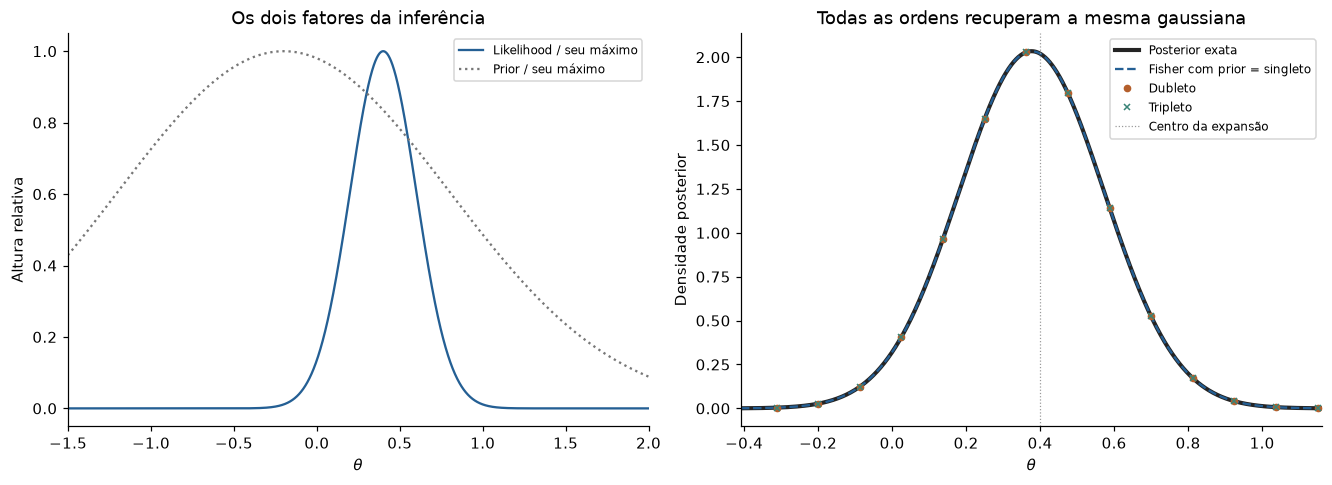

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")  # Separa os ingredientes da posterior final.
axs[0].plot(eixo_A, np.exp(loglike_A-loglike_A.max()), color=CORES_B3["Fisher/singleto"],
            label="Likelihood / seu máximo")  # Mostra a região preferida pelos dados.
axs[0].plot(eixo_A, np.exp(prior_log_A-prior_log_A.max()), color="#777777", ls=":",
            label="Prior / seu máximo")  # Mostra a informação anterior em escala relativa, sem tratá-la como posterior.
axs[0].set(xlabel=r"$\theta$", ylabel="Altura relativa", title="Os dois fatores da inferência", xlim=(-1.5, 2.0))  # Declara a escala vertical relativa.
axs[0].legend(fontsize=8)  # Identifica likelihood e prior.
axs[1].plot(eixo_A, p_A, color=CORES_B3["Exata"], lw=2.7, label="Posterior exata")  # Desenha a referência integrada.
axs[1].plot(eixo_A, p_fisher_A, color=CORES_B3["Fisher/singleto"], ls="--",
            label="Fisher com prior = singleto")  # Confere a forma obtida analiticamente.
for nome, marcador in [("Dubleto","o"), ("Tripleto","x")]:  # Marca pontos das curvas que coincidem com a referência.
    axs[1].plot(eixo_A[::90], curvas_A[nome][::90], marcador, ms=4, color=CORES_B3[nome], label=nome)
axs[1].axvline(theta0_A, color="#999999", lw=.8, ls=":", label="Centro da expansão")  # Mostra que a prior pode deslocar o centro posterior.
axs[1].set(xlabel=r"$\theta$", ylabel="Densidade posterior", title="Todas as ordens recuperam a mesma gaussiana",
            xlim=(m_A-4/np.sqrt(Q_A), m_A+4/np.sqrt(Q_A)))  # Foca a região que contém a massa posterior.
axs[1].legend(fontsize=8)  # Identifica as curvas sobrepostas.
figura_b3("01_limite_linear", fig)  # Salva a comparação e a incorpora ao notebook.


Os resultados coincidem, como previsto pela anulação das derivadas superiores. A sobreposição não significa que a comparação visual foi pouco sensível: a tabela verifica a diferença entre densidades e a solução analítica verifica os momentos.

O singleto e Fisher compartilham o mesmo núcleo quadrático da likelihood. Avaliar esse núcleo e multiplicar pela prior é uma rota; inverter a precisão gaussiana total e escrever a densidade analítica é outra. Neste caso, as duas rotas respondem à mesma pergunta. Passar a ordens superiores não acrescenta informação porque o modelo não tem resposta de ordem superior.

Isso estabelece nosso teste de consistência. Vamos agora conservar os erros gaussianos e alterar apenas a relação entre parâmetros e observáveis.


## 3.3. Exemplo B — quando a segunda derivada é necessária

Retomaremos a resposta curva do Bloco 1, agora com a ferramenta que faltava para aproximá-la:

$$
\mu(q_1,q_2)=\begin{pmatrix}q_1\\q_2-\kappa q_1^2\end{pmatrix},\qquad
\kappa=0.65,\quad d=(0,0),\quad \theta_0=(0,0),\quad
C=\operatorname{diag}(1,0.4^2).
$$

As priors continuam próprias, independentes: $q_1\sim\mathcal N(0,3^2)$ e $q_2\sim\mathcal N(0,5^2)$. No centro, $J=I$, a única entrada não nula de $H$ é $H_{2,11}=-2\kappa$ e $T=0$. Portanto,

$$
E_1=\frac12q_1^2+\frac{q_2^2}{2(0.4)^2},\qquad
E_2=E_3=\frac12q_1^2+\frac{(q_2-\kappa q_1^2)^2}{2(0.4)^2}.
$$

Antes de calcular, já sabemos o resultado que devemos procurar: o singleto produz uma elipse, enquanto o dubleto recupera **exatamente este modelo quadrático**, inclusive a posterior depois de multiplicar pela mesma prior. O tripleto não deve mudar o resultado, pois sua nova derivada é zero.

Em particular, o termo $\kappa^2q_1^4/[2(0.4)^2]$ precisa aparecer no expoente. Não é uma quarta derivada do modelo: é o quadrado de sua segunda derivada. Essa é uma aplicação direta da distinção entre as duas ordens do Bloco 2.


In [25]:
kappa_B = 0.65  # Escolha a intensidade da curvatura; zero retorna ao caso linear.
C_B = np.diag([1.0, 0.4**2])  # Define as variâncias gaussianas dos dois observáveis.
prior_cov_B = np.diag([3.0**2, 5.0**2])  # Define a mesma prior própria em todas as comparações.
q1_B = np.linspace(-5.5, 5.5, 501)  # Escolhe o recorte numérico do primeiro parâmetro.
q2_B = np.linspace(-3.5, 18.0, 501)  # Inclui a cauda positiva da posterior curva.
xx_B, yy_B = np.meshgrid(q1_B, q2_B)  # Forma os pares de coordenadas da malha.
pontos_B = np.stack((xx_B, yy_B), axis=-1)  # Guarda os parâmetros na última dimensão.
modelo_B = np.stack((xx_B, yy_B-kappa_B*xx_B**2), axis=-1)  # Avalia o modelo quadrático sem aproximação.
prior_log_B = dali.gaussian_logpdf(pontos_B, [0,0], prior_cov_B)  # Avalia a prior nos mesmos pontos.
log_ref_B = dali.gaussian_logpdf(-modelo_B, [0,0], C_B)+prior_log_B  # Usa dados zero para formar o resíduo exato.
p_B, _ = dali.normalize_log_grid(log_ref_B, q1_B, q2_B)  # Normaliza a posterior de referência em duas dimensões.
J_B = np.eye(2)  # Calcula o Jacobiano no centro (0,0).
H_B = np.zeros((2,2,2))  # Prepara o tensor de segundas derivadas do modelo.
H_B[1,0,0] = -2*kappa_B  # Inclui a única curvatura não nula, na segunda previsão.
T_B = np.zeros((2,2,2,2))  # Todas as terceiras derivadas desse modelo são zero.
expansao_B = dali.prepare_dali([0,0], (J_B,H_B,T_B), C_B)  # Prepara as três ordens com a mesma covariância.
curvas_B = {"Exata": p_B}  # Guarda todas as densidades na mesma malha física.
linhas_B = []  # Reúne os resultados para comparar largura e massa.
for ordem, nome in [(1,"Fisher/singleto"), (2,"Dubleto"), (3,"Tripleto")]:  # Percorre a hierarquia.
    log_p = expansao_B.loglike(pontos_B, order=ordem)+prior_log_B  # Mantém a prior exata na aproximação.
    curvas_B[nome], _ = dali.normalize_log_grid(log_p, q1_B, q2_B)  # Normaliza cada posterior no mesmo domínio.
for nome, pdf in curvas_B.items():  # Calcula os mesmos diagnósticos para todos os métodos.
    media, cov = dali.grid_moments_2d(pdf, q1_B, q2_B)  # Obtém momentos globais, não apenas a curvatura no máximo.
    linhas_B.append({"Método": nome, "Média q2": media[1], "Desvio q2": np.sqrt(cov[1,1]),
                      "TV vs. exata": 0.5*dali.integrate_grid_2d(abs(pdf-p_B), q1_B, q2_B)})
assert np.max(abs(curvas_B["Dubleto"]-p_B)) < 1e-12  # Confere que a segunda ordem recupera o modelo inteiro.
assert np.max(abs(curvas_B["Tripleto"]-p_B)) < 1e-12  # Confere que T=0 não altera a resposta.
tabela_b3("02_quadratico", pd.DataFrame(linhas_B))  # Mostra a diferença entre a elipse local e a distribuição curva.


,Método,Média q2,Desvio q2,TV vs. exata
0,Exata,5.417134e-01,0.843187,0.000000e+00
1,Fisher/singleto,1.214306e-17,0.398726,3.690543e-01
2,Dubleto,5.417134e-01,0.843187,9.368355e-17
3,Tripleto,5.417134e-01,0.843187,9.368355e-17


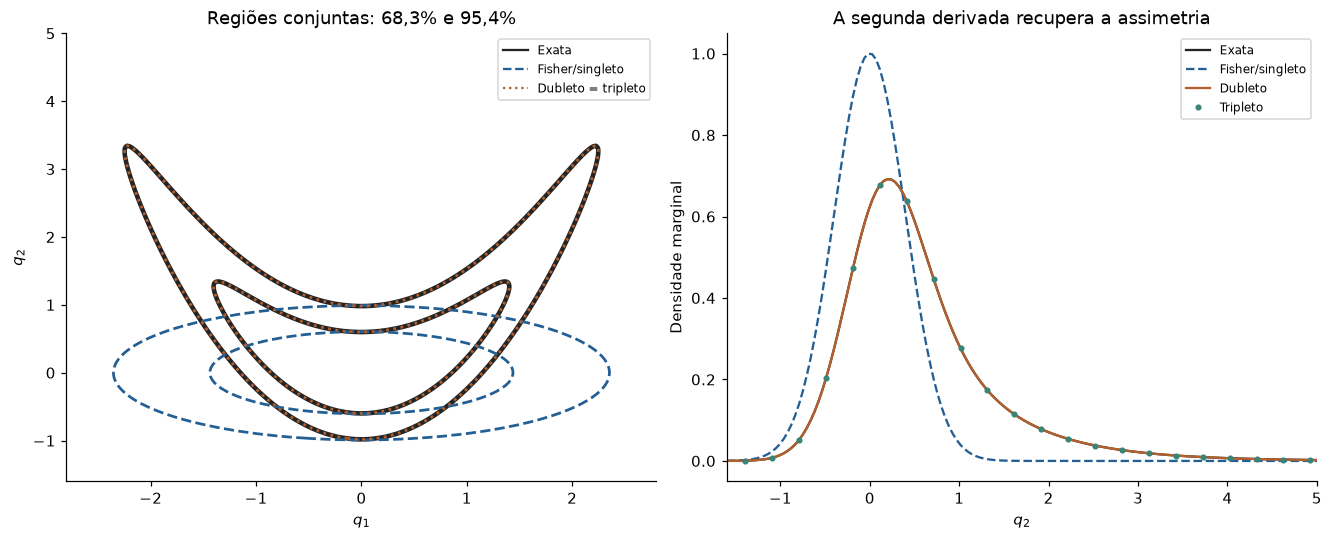

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")  # Coloca lado a lado região conjunta e marginal.
lim_ref_B = np.sort(dali.hpd_thresholds_2d(p_B, q1_B, q2_B))  # Encontra os níveis de 68,3% e 95,4% da referência.
axs[0].contour(xx_B, yy_B, p_B, levels=lim_ref_B, colors=CORES_B3["Exata"], linewidths=3)  # Desenha a forma curva verdadeira.
for nome, estilo in [("Fisher/singleto","--"), ("Dubleto",":")]:  # Compara as regiões de igual probabilidade de cada método.
    lim = np.sort(dali.hpd_thresholds_2d(curvas_B[nome], q1_B, q2_B))  # Usa o nível HPD próprio de cada densidade.
    axs[0].contour(xx_B, yy_B, curvas_B[nome], levels=lim, colors=CORES_B3[nome], linestyles=estilo, linewidths=1.8)
for nome, estilo in [("Exata","-"), ("Fisher/singleto","--"), ("Dubleto",":")]:  # Acrescenta entradas claras para a legenda.
    axs[0].plot([], [], color=CORES_B3[nome], ls=estilo, label=nome+(" = tripleto" if nome=="Dubleto" else ""))
axs[0].set(xlabel=r"$q_1$", ylabel=r"$q_2$", title="Regiões conjuntas: 68,3% e 95,4%",
            xlim=(-2.8,2.8), ylim=(-1.6,5.0))  # Foca a região favorecida pelas distribuições.
axs[0].legend(fontsize=8)  # Identifica a elipse e a posterior curva.
for nome, pdf in curvas_B.items():  # Integra q1 para comparar as marginais de q2.
    marginal = simpson(pdf, x=q1_B, axis=1)  # Marginaliza em vez de fixar q1 no máximo.
    if nome == "Tripleto":  # Usa pontos para tornar visível a coincidência com o dubleto.
        axs[1].plot(q2_B[::7], marginal[::7], "o", ms=3, color=CORES_B3[nome], label=nome)
    else:  # Mantém curvas contínuas para as demais densidades.
        axs[1].plot(q2_B, marginal, color=CORES_B3[nome], ls="--" if nome=="Fisher/singleto" else "-", label=nome)
axs[1].set(xlabel=r"$q_2$", ylabel="Densidade marginal", title="A segunda derivada recupera a assimetria", xlim=(-1.6,5.0))
axs[1].legend(fontsize=8)  # Identifica as marginais, incluindo as que se sobrepõem.
figura_b3("02_modelo_quadratico", fig)  # Exporta os dois painéis da comparação.


O dubleto acompanha a região curva e sua marginal assimétrica, enquanto o singleto conserva a elipse local. A média global de $q_2$ é positiva, embora o MAP conjunto esteja na origem. Essa diferença já aparecia no Bloco 1; agora sabemos quais derivadas do modelo permitem recuperá-la.

O acordo entre dubleto, tripleto e referência não resulta de um ajuste das curvas depois de vê-las. Ele foi previsto porque o modelo é um polinômio de grau dois: sua Taylor até segunda ordem já é o modelo completo. A tabela e os testes numéricos confirmam essa identidade.

Isso não significa que todo problema não gaussiano será resolvido pelo dubleto. Aqui não havia resto de Taylor depois de $H$. No próximo exemplo o modelo não é um polinômio quadrático, e seu truncamento pode até inventar uma solução adicional.


## 3.4. Exemplo C — um modo espúrio produzido pela parametrização

Vamos considerar uma resposta que cai com a distância,

$$
\mu(d)=\frac1d,\qquad d_0=1,\qquad z_{\rm obs}=1,\qquad \sigma=0.12,
\qquad \pi_d(d)=\frac{\mathbf1_{[0.35,\,3.20]}(d)}{3.20-0.35}.
$$

Aqui $d$ é o **parâmetro distância**; usamos $z_{\rm obs}$ para o dado e evitar a ambiguidade com nossa notação anterior de vetor de dados. É um modelo escalar inspirado na dependência de amplitude com distância, não uma reprodução de uma forma de onda gravitacional completa. Todos os valores são adimensionais.

Como $1/d$ é estritamente decrescente nesse suporte, a equação $\mu(d)=z_{\rm obs}$ só tem a solução $d=1$. A prior é constante dentro do intervalo, portanto não cria outros máximos interiores. Essa será nossa referência para chamar uma solução adicional de **espúria**.

Definindo $\delta=d-1$, as três aproximações do modelo são

$$
\mu_1=1-\delta,\qquad
\mu_2=1-\delta+\delta^2,\qquad
\mu_3=1-\delta+\delta^2-\delta^3.
$$

No dubleto, $\mu_2=1$ implica $\delta(1-\delta)=0$: além de $d=1$, aparece **$d=2$**, que está dentro da prior. O truncamento deixou de ser monotônico e criou uma segunda interseção com o dado. No tripleto, a equação vira $\delta(1-\delta+\delta^2)=0$. Como o fator quadrático tem discriminante $-3$, não há outra raiz real.

Antes de calcular, esperamos então um segundo pico no dubleto e sua ausência no tripleto. Isso não implica que o tripleto recupere toda a forma da posterior exata; ele remove o pico neste exemplo, mas ainda aproxima $1/d$ por um polinômio local. A TV permitirá avaliar também essa diferença de forma. Como diagnóstico regional, compararemos $P(d>1.5)$, separando previamente a região do pico artificial daquela próxima ao centro.


In [27]:
d0_C, sigma_C = 1.0, 0.12  # Escolha o centro da expansão e o desvio do erro da medição.
limites_C = (0.35, 3.20)  # Define o suporte da prior; ele inclui o pico espúrio previsto em d=2.
eixo_C = np.linspace(*limites_C, 5701)  # Refina a malha dentro do mesmo suporte físico.
delta_C = eixo_C-d0_C  # Calcula o deslocamento em relação ao centro.
zobs_C = 1/d0_C  # Define o dado de forecast pela resposta no fiducial.
logprior_C = np.full_like(eixo_C, -np.log(limites_C[1]-limites_C[0]))  # Avalia a prior uniforme própria.
logref_C = norm.logpdf(zobs_C, 1/eixo_C, sigma_C)+logprior_C  # Avalia a likelihood exata sem expandir 1/d.
p_C, logZ_C = dali.normalize_log_grid_1d(logref_C, eixo_C)  # Normaliza a referência na variável distância.
derivadas_C = tuple(np.full((1,)*(k+1), (-1)**k*factorial(k)/d0_C**(k+1))
                    for k in (1,2,3))  # Calcula J,H,T de 1/d, sem incluir os fatores de Taylor.
expansao_C = dali.prepare_dali([d0_C], derivadas_C, [[sigma_C**2]])  # Prepara o forecast na parametrização d.
curvas_C = {"Exata": p_C}  # Guarda todas as curvas na mesma coordenada física.
modelos_C = {"Exata": 1/eixo_C}  # Guarda as previsões para explicar as interseções com o dado.
raizes_C = []  # Reúne a localização e a discrepância física das soluções dos polinômios.
for ordem, nome in [(1,"Fisher/singleto"), (2,"Dubleto"), (3,"Tripleto")]:  # Compara as três ordens sem trocar a prior.
    logp = expansao_C.loglike(eixo_C[:, None], order=ordem)+logprior_C  # Inclui a prior na likelihood aproximada.
    curvas_C[nome], _ = dali.normalize_log_grid_1d(logp, eixo_C)  # Normaliza em d, não no espaço do modelo.
    coef = [0]+[(-1)**k/d0_C**(k+1) for k in range(1,ordem+1)]  # Retira k! das derivadas para obter a Taylor de mu-mu0.
    modelos_C[nome] = zobs_C+Polynomial(coef)(delta_C)  # Calcula a previsão do modelo truncado em cada distância.
    roots = d0_C+raizes_no_suporte_b3(coef, (limites_C[0]-d0_C, limites_C[1]-d0_C))  # Volta das raízes em delta para d.
    for raiz in roots:  # Confere cada solução com o modelo físico sem truncamento.
        raizes_C.append({"Método": nome, "Raiz no suporte": raiz,
                         "|mu_exata - dado| / sigma": abs(1/raiz-zobs_C)/sigma_C})
tabela_b3("03_distancia_raizes", pd.DataFrame(raizes_C))  # Mostra que a raiz d=2 não reproduz o dado no modelo exato.


,Método,Raiz no suporte,|mu_exata - dado| / sigma
0,Fisher/singleto,1.0,0.000000
1,Dubleto,1.0,0.000000
2,Dubleto,2.0,4.166667
3,Tripleto,1.0,0.000000


### Uma escolha melhor: usar a resposta $u=1/d$

Em $u$, o mesmo modelo fica $\mu(u)=u$. Todas as derivadas após a primeira são zero, e o singleto já representa a likelihood exata. Mas precisamos manter a **mesma prior física**, não escolher novamente uma uniforme:

$$
\pi_u(u)=\pi_d(1/u)\left|\frac{dd}{du}\right|
=\frac{\mathbf1_{[1/3.20,\,1/0.35]}(u)}{(3.20-0.35)u^2}.
$$

A likelihood em $u$ é gaussiana; sua posterior não precisa ser, pois $\pi_u$ não é gaussiana. Para comparar com as curvas anteriores, retornamos à distância:

$$
p_d(d\mid z)=p_u(1/d\mid z)\left|\frac{du}{dd}\right|
=\frac{p_u(1/d\mid z)}{d^2}.
$$

Vamos normalizar independentemente em $u$ e depois fazer esse retorno. Não renormalizaremos a curva de volta em $d$ para esconder um eventual erro no jacobiano. Máximos de densidades podem mudar de posição numa transformação não linear; por isso, o diagnóstico de modo espúrio será feito **na mesma coordenada $d$**, com a mesma prior.


In [28]:
eixo_u_C = np.linspace(1/limites_C[1], 1/limites_C[0], 5701)  # Ordena crescentemente o suporte transformado.
logprior_u_C = -np.log(limites_C[1]-limites_C[0])-2*np.log(eixo_u_C)  # Inclui |dd/du|=1/u² na prior.
expansao_u_C = dali.prepare_dali([1/d0_C], (np.ones((1,1)), np.zeros((1,1,1)),
                                          np.zeros((1,1,1,1))), [[sigma_C**2]])  # Prepara o modelo linear em u.
logpost_u_C = expansao_u_C.loglike(eixo_u_C[:, None], order=1)+logprior_u_C  # Soma a prior transformada ao singleto exato.
p_u_C, logZ_u_C = dali.normalize_log_grid_1d(logpost_u_C, eixo_u_C)  # Normaliza na variável u por uma integração independente.
u_nos_d_C = 1/eixo_C  # Avalia a coordenada nova nos mesmos pontos de distância dos gráficos.
logprior_u_nos_d_C = -np.log(limites_C[1]-limites_C[0])-2*np.log(u_nos_d_C)  # Avalia a mesma prior transformada nesses pontos.
p_retorno_C = np.exp(expansao_u_C.loglike(u_nos_d_C[:, None], order=1)
                     +logprior_u_nos_d_C-logZ_u_C-2*np.log(eixo_C))  # Multiplica a posterior em u por |du/dd|=1/d².
curvas_C["Linear em u (retorno)"] = p_retorno_C  # Acrescenta a comparação somente após voltar à mesma coordenada d.
assert abs(logZ_u_C-logZ_C) < 1e-9  # Confere a invariância da evidência ao transformar corretamente a prior.
assert np.max(abs(p_retorno_C-p_C)) < 1e-9  # Confere o retorno sem uma segunda normalização em d.
tabela_b3("04_distancia_posteriors", resumo_1d_b3(eixo_C, curvas_C, corte=1.5))  # Quantifica o pico e as diferenças de forma.


,Método,Média,Desvio,TV vs. exata,P(parâmetro > 1.5)
0,Exata,1.048311,0.139126,0.000000e+00,0.006637
1,Fisher/singleto,1.000000,0.120000,1.067049e-01,0.000015
2,Dubleto,1.500000,0.463324,4.998064e-01,0.500000
3,Tripleto,1.040012,0.127819,1.758504e-02,0.001085
4,Linear em u (retorno),1.048311,0.139126,1.064548e-16,0.006637


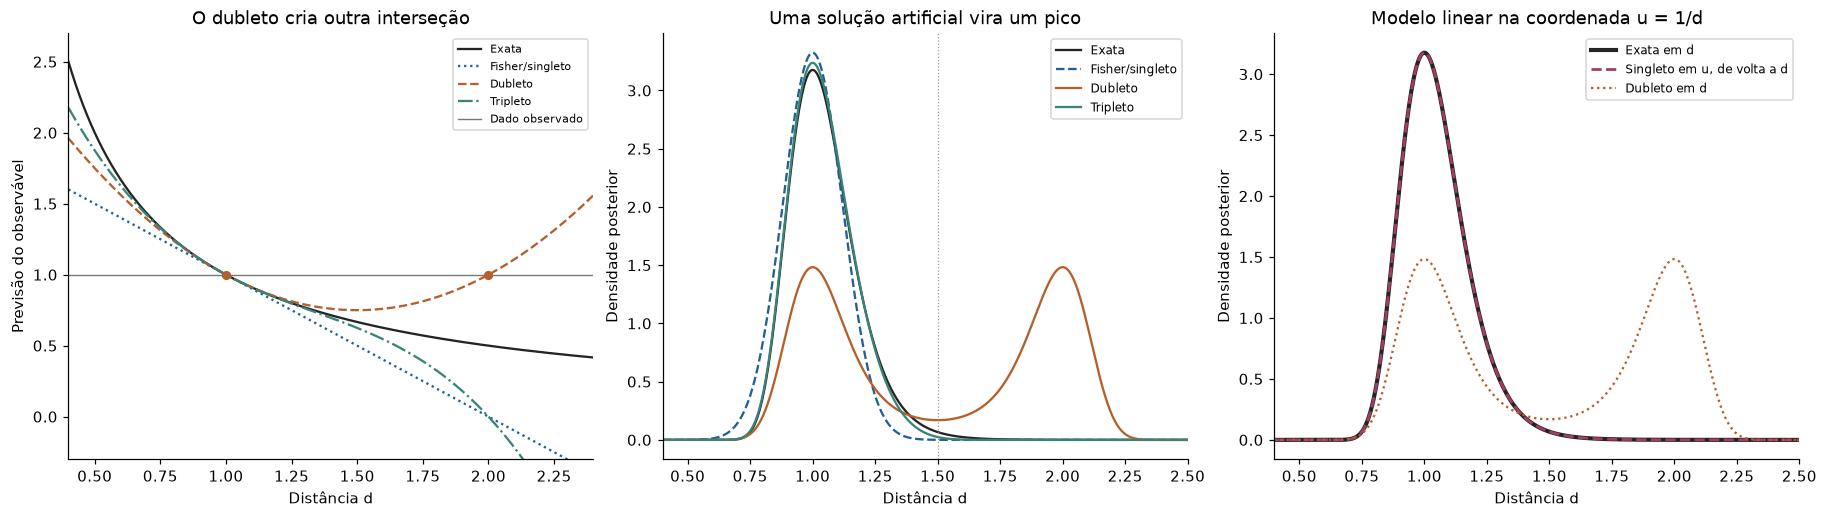

In [29]:
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.6), layout="constrained")  # Liga modelo, posterior e mudança de parâmetro.
for nome, estilo in [("Exata","-"), ("Fisher/singleto",":"), ("Dubleto","--"), ("Tripleto","-.")]:
    axs[0].plot(eixo_C, modelos_C[nome], color=CORES_B3[nome], ls=estilo, label=nome)  # Mostra onde cada modelo cruza o dado.
axs[0].axhline(zobs_C, color="#777777", lw=.9, label="Dado observado")  # Identifica a equação que define as soluções.
axs[0].plot([d0_C,2*d0_C], [zobs_C,zobs_C], "o", color=CORES_B3["Dubleto"], ms=5)  # Marca a solução verdadeira e a espúria do dubleto.
axs[0].set(xlabel="Distância d", ylabel="Previsão do observável", title="O dubleto cria outra interseção",
            xlim=(.4,2.4), ylim=(-.3,2.7))  # Foca a região das duas interseções sem mudar a integração.
axs[0].legend(fontsize=7.5)  # Identifica os modelos truncados.
for nome in ("Exata","Fisher/singleto","Dubleto","Tripleto"):  # Compara as posteriors na parametrização original.
    axs[1].plot(eixo_C, curvas_C[nome], color=CORES_B3[nome], ls="--" if nome=="Fisher/singleto" else "-", label=nome)
axs[1].axvline(1.5, color="#999999", lw=.8, ls=":")  # Marca o limite do diagnóstico regional definido antes das contas.
axs[1].set(xlabel="Distância d", ylabel="Densidade posterior", title="Uma solução artificial vira um pico", xlim=(.4,2.5))
axs[1].legend(fontsize=8)  # Identifica as quatro posteriors.
axs[2].plot(eixo_C, p_C, color=CORES_B3["Exata"], lw=2.7, label="Exata em d")  # Usa a mesma referência física.
axs[2].plot(eixo_C, p_retorno_C, color=CORES_B3["Linear em u (retorno)"], ls="--", lw=1.8,
            label="Singleto em u, de volta a d")  # Mostra que a mudança consistente de variável recupera a referência.
axs[2].plot(eixo_C, curvas_C["Dubleto"], color=CORES_B3["Dubleto"], ls=":", label="Dubleto em d")  # Mantém o problema original visível.
axs[2].set(xlabel="Distância d", ylabel="Densidade posterior", title="Modelo linear na coordenada u = 1/d", xlim=(.4,2.5))
axs[2].legend(fontsize=8)  # Deixa explícito que as curvas foram comparadas de volta em d.
figura_b3("03_distancia_e_parametrizacao", fig)  # Exporta a sequência visual completa.


O modo em $d=2$ é um artefato do dubleto: o modelo exato nesse ponto prevê $1/2$, enquanto o dado é $1$. Não é uma segunda distância igualmente permitida pelo modelo físico. Como a normalização precisa repartir massa entre duas regiões, o dubleto também reduz o peso da região próxima à solução verdadeira; o problema não se resume a uma deformação pequena da curva.

O tripleto elimina essa segunda raiz no suporte considerado, embora sua posterior ainda possa diferir da exata. Já a parametrização $u=1/d$ recupera a referência com o singleto, porque a resposta ficou linear. O acordo depois do retorno confirma simultaneamente o tratamento da likelihood e da prior.

Esse é o mecanismo discutido para a distância em de Souza e Quartin (2026, §2.1): dependência inversa de amplitude, derivadas com sinais alternados e um dubleto com pico artificial. Nosso exemplo isola esse mecanismo em um observável. Ele não demonstra que trocar de parâmetro ou usar o tripleto resolverá qualquer modelo. É essa última possibilidade que vamos testar agora.


## 3.5. Exemplo D — Hipótese sobre ordens pares e ímpares

Quando vi os modos espúrios em aula, pensei que, por aparecerem associados à alternância de sinais das derivadas, o problema não deveria se repetir ao mesmo tempo em uma ordem par e na ordem ímpar seguinte. O exemplo da distância inversa parece favorecer essa ideia: o dubleto falha e o tripleto remove o segundo pico.

Mas essa observação ainda é uma hipótese sobre uma classe de modelos. Para testá-la, precisamos olhar para as raízes do polinômio truncado. A paridade, sozinha, não determina essas raízes; os coeficientes também importam. Vamos construir um caso no qual podemos verificar isso analiticamente.

Considere agora

$$
g(x)=x-x^2+0.1x^3+0.5x^4,\qquad x_0=0,\qquad z_{\rm obs}=0,\qquad \sigma=0.12,
\qquad \pi_x(x)=\frac{\mathbf1_{[-0.5,\,2]}(x)}{2.5}.
$$

O suporte é parte do problema e contém as duas soluções espúrias que aparecerão. Nele,

$$
g'(x)=1-2x+0.3x^2+2x^3>0.
$$

Podemos conferir o sinal pelos extremos de $g'$: $g''(x)=-2+0.6x+6x^2$ tem apenas um zero no suporte, em $x\simeq0.5295$, onde $g'\simeq0.3220>0$; nas extremidades, $g'$ também é positiva. Portanto, o modelo exato é estritamente crescente nesse intervalo e $g(x)=0$ só tem a solução $x=0$. Não estamos omitindo um segundo modo verdadeiro da referência no suporte assumido.


### O que deve acontecer antes de executar o código?

No centro, as derivadas brutas são $J=1$, $H=-2$, $T=0.6$ e $U=g^{(4)}=12$. A quarta derivada será chamada de $U$ para não confundi-la com a precisão $Q$ do Bloco 1. Os modelos truncados são

$$
\mathcal T_2=x-x^2,\qquad
\mathcal T_3=x-x^2+0.1x^3,\qquad
\mathcal T_4=g(x).
$$

O dubleto tem raízes $0$ e $1$. No tripleto,

$$
\mathcal T_3=x(1-x+0.1x^2)=0
\quad\Rightarrow\quad
x=0,\quad x=5-\sqrt{15}\simeq1.1270,\quad x=5+\sqrt{15}.
$$

A primeira raiz adicional pertence ao suporte e a última está fora dele. Assim, **dubleto e tripleto terão modos espúrios simultaneamente, em posições distintas**. Em uma família $x-x^2+\beta x^3$, o fator quadrático tem discriminante $1-4\beta$: a ausência de raízes adicionais depende de $\beta$, não apenas de a ordem ser ímpar. A distância inversa tinha uma estrutura particular de coeficientes que não podemos transformar em regra geral.

A quarta ordem recupera o modelo completo, pois ele é quártico. Como verificamos que $g$ é monotônica no suporte, essa ordem remove as soluções artificiais **neste exemplo**. Não é uma demonstração de que toda quarta ordem será suficiente ou de que ordens sucessivas melhoram monotonamente.

Como diagnóstico regional, fixaremos $P(x>0.6)$. A posterior exata pode ter alguma massa nessa região; o que investigaremos é o excesso de massa produzido pelos picos espúrios. O limite será o mesmo para todos os métodos.


In [30]:
coef_D = np.array([0.0, 1.0, -1.0, 0.1, 0.5])  # Escolhe os coeficientes em ordem crescente: constante, x, x², x³, x⁴.
g_D = Polynomial(coef_D)  # Define o modelo e permite derivá-lo analiticamente.
theta0_D, sigma_D = 0.0, 0.12  # Define o fiducial e o ruído gaussiano.
limites_D = (-0.5, 2.0)  # Declara a prior antes de comparar os métodos; contém os dois picos artificiais.
eixo_D = np.linspace(*limites_D, 5001)  # Escolhe a resolução de integração dentro desse mesmo suporte.
zobs_D = float(g_D(theta0_D))  # Define o dado observado no fiducial.
logprior_D = np.full_like(eixo_D, -np.log(limites_D[1]-limites_D[0]))  # Mantém uma prior uniforme própria.
logref_D = norm.logpdf(zobs_D, g_D(eixo_D), sigma_D)+logprior_D  # Avalia o modelo quártico sem truncamento.
p_D, logZ_D = dali.normalize_log_grid_1d(logref_D, eixo_D)  # Normaliza a posterior exata em x.
valores_der_D = [float(g_D.deriv(k)(theta0_D)) for k in (1,2,3,4)]  # Obtém as derivadas brutas 1,-2,0.6,12.
derivadas_D = tuple(np.full((1,)*(k+1), valor) for k,valor in enumerate(valores_der_D, start=1))  # Dá a cada tensor sua forma (N,p,...,p).
expansao_D = dali.prepare_dali([theta0_D], derivadas_D, [[sigma_D**2]])  # Prepara até a quarta ordem do modelo.
curvas_D = {"Exata": p_D}  # Guarda as densidades na coordenada x.
modelos_D = {"Exata": g_D(eixo_D)}  # Guarda as previsões para explicar a origem de cada pico.
raizes_D = []  # Reúne as soluções de cada truncamento dentro da prior.
for ordem, nome in [(1,"Fisher/singleto"), (2,"Dubleto"), (3,"Tripleto"), (4,"4ª ordem")]:
    logp = expansao_D.loglike(eixo_D[:, None], order=ordem)+logprior_D  # Mantém o quadrado inteiro e a mesma prior.
    curvas_D[nome], _ = dali.normalize_log_grid_1d(logp, eixo_D)  # Normaliza cada aproximação.
    coef = [0]+[valores_der_D[k-1]/factorial(k) for k in range(1,ordem+1)]  # Inclui os fatores de Taylor, sem confundi-los com derivadas brutas.
    modelos_D[nome] = zobs_D+Polynomial(coef)(eixo_D-theta0_D)  # Avalia o modelo truncado usado por essa ordem.
    roots = theta0_D+raizes_no_suporte_b3(coef, (limites_D[0]-theta0_D, limites_D[1]-theta0_D))  # Localiza suas raízes permitidas.
    for raiz in roots:  # Confere cada solução com o modelo físico sem truncamento.
        raizes_D.append({"Método": nome, "Raiz no suporte": raiz,
                         "|g_exata - dado| / sigma": abs(g_D(raiz)-zobs_D)/sigma_D})
criticos_D = g_D.deriv(2).roots()  # Encontra os pontos que podem minimizar g' no intervalo.
candidatos_D = list(limites_D)+[float(z.real) for z in criticos_D
                               if abs(z.imag)<1e-10 and limites_D[0]<z.real<limites_D[1]]  # Inclui os extremos do suporte.
min_derivada_D = float(np.min(g_D.deriv()(np.array(candidatos_D))))  # Confere o menor valor de g' em todos os candidatos.
assert min_derivada_D > 0  # Garante monotonicidade neste exemplo; alterar os coeficientes exige rever essa propriedade.
assert np.max(abs(curvas_D["4ª ordem"]-p_D)) < 1e-12  # Confere que o modelo quártico foi recuperado inteiro.
tabela_b3("05_contraexemplo_raizes", pd.DataFrame(raizes_D))  # Mostra as soluções artificiais mesmo com derivadas analíticas exatas.
print(f"Mínimo de g' no suporte: {min_derivada_D:.6f}")  # Confirma que a referência tem uma única solução para o dado.


,Método,Raiz no suporte,|g_exata - dado| / sigma
0,Fisher/singleto,0.000000,0.000000
1,Dubleto,0.000000,0.000000
2,Dubleto,1.000000,5.000000
3,Tripleto,0.000000,0.000000
4,Tripleto,1.127017,6.722179
5,4ª ordem,0.000000,0.000000


Mínimo de g' no suporte: 0.322023


### Existe uma parametrização melhor também aqui?

Neste caso, sim: como $g$ é estritamente crescente no suporte, podemos usar $u=g(x)$. O observável passa a ser $\mu(u)=u$ e o singleto já descreve a likelihood exata. A prior correspondente é

$$
\pi_u(u)=\frac{1}{2.5\,g'(g^{-1}(u))},\qquad
u\in[g(-0.5),g(2)].
$$

Ao voltar, $p_x(x)=p_u(g(x))g'(x)$. Vamos repetir a verificação da normalização independente em $u$. Não precisaremos obter uma fórmula explícita para a inversa quártica: usaremos os pares conhecidos $(x,g(x))$, que formam uma malha crescente, agora não uniforme em $u$.

Essa escolha é possível porque temos um parâmetro, um observável e uma resposta invertível no domínio assumido. Em um problema com muitos parâmetros e observáveis, não podemos presumir uma transformação global que linearize todas as previsões. O critério aprendido aqui é procurar respostas mais lineares e identificáveis na região relevante, verificar invertibilidade e transformar a mesma prior, em vez de escolher a coordenada apenas porque um gráfico parece melhor.


In [31]:
eixo_u_D = g_D(eixo_D)  # Constrói os pares (x,u), sem precisar resolver a inversa quártica.
jac_D = g_D.deriv()(eixo_D)  # Avalia du/dx, que já foi verificado como positivo.
logprior_u_D = logprior_D-np.log(jac_D)  # Aplica |dx/du|=1/g'(x) à mesma prior física.
derivadas_u_D = (np.ones((1,1)),)+tuple(np.zeros((1,)*(k+1)) for k in (2,3,4))  # O modelo em u é linear em todas as ordens.
expansao_u_D = dali.prepare_dali([zobs_D], derivadas_u_D, [[sigma_D**2]])  # Prepara a resposta linear na coordenada nova.
logpost_u_D = expansao_u_D.loglike(eixo_u_D[:, None], order=1)+logprior_u_D  # Avalia a densidade antes da normalização em u.
p_u_D, logZ_u_D = dali.normalize_log_grid_1d(logpost_u_D, eixo_u_D)  # Integra com as coordenadas não uniformes de u.
p_retorno_D = np.exp(logpost_u_D-logZ_u_D+np.log(jac_D))  # Multiplica por du/dx para voltar à densidade em x.
curvas_D["Linear em u (retorno)"] = p_retorno_D  # Compara a nova parametrização só após o retorno.
assert abs(logZ_u_D-logZ_D) < 1e-8  # Confere a mesma evidência pelas duas coordenadas.
assert np.max(abs(p_retorno_D-p_D)) < 1e-8  # Confere o retorno sem renormalizá-lo em x.
tabela_b3("06_contraexemplo_posteriors", resumo_1d_b3(eixo_D, curvas_D, corte=0.6))  # Compara os excessos de massa com a referência.


,Método,Média,Desvio,TV vs. exata,P(parâmetro > 0.6)
0,Exata,0.062465,0.158999,0.000000e+00,7.027641e-03
1,Fisher/singleto,0.000008,0.119983,1.368052e-01,2.866560e-07
2,Dubleto,0.500000,0.463324,4.823067e-01,4.820527e-01
3,Tripleto,0.594370,0.525221,5.180620e-01,5.231112e-01
4,4ª ordem,0.062465,0.158999,6.671650e-17,7.027641e-03
5,Linear em u (retorno),0.062465,0.158999,9.410147e-14,7.027641e-03


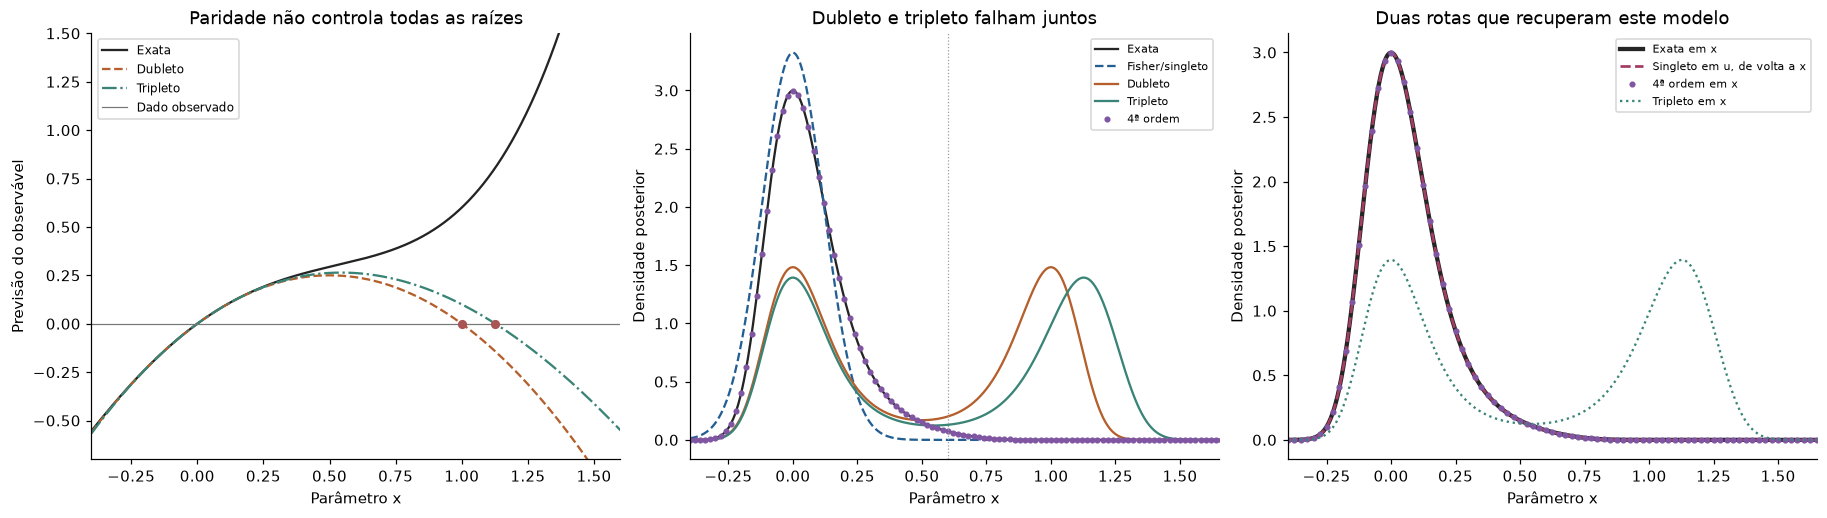

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.6), layout="constrained")  # Liga a equação do modelo ao teste da hipótese.
for nome, estilo in [("Exata","-"), ("Dubleto","--"), ("Tripleto","-.")]:
    axs[0].plot(eixo_D, modelos_D[nome], color=CORES_B3[nome], ls=estilo, label=nome)  # Mostra as falsas interseções com o dado zero.
axs[0].axhline(0, color="#777777", lw=.8, label="Dado observado")  # Marca a equação que cada truncamento tenta satisfazer.
axs[0].plot([1,5-np.sqrt(15)], [0,0], "o", color="#aa5555", ms=5)  # Marca os dois modos espúrios previstos analiticamente.
axs[0].set(xlabel="Parâmetro x", ylabel="Previsão do observável", title="Paridade não controla todas as raízes",
            xlim=(-.4,1.6), ylim=(-.7,1.5))  # Foca os cruzamentos sem alterar o domínio de integração.
axs[0].legend(fontsize=8)  # Identifica referência e truncamentos.
for nome in ("Exata","Fisher/singleto","Dubleto","Tripleto"):  # Desenha as distribuições globais na mesma coordenada.
    axs[1].plot(eixo_D, curvas_D[nome], color=CORES_B3[nome], ls="--" if nome=="Fisher/singleto" else "-", label=nome)
axs[1].plot(eixo_D[::40], curvas_D["4ª ordem"][::40], "o", ms=3, color=CORES_B3["4ª ordem"], label="4ª ordem")  # Marca a ordem que coincide com a referência.
axs[1].axvline(.6, color="#999999", lw=.8, ls=":")  # Identifica o limite do diagnóstico regional.
axs[1].set(xlabel="Parâmetro x", ylabel="Densidade posterior", title="Dubleto e tripleto falham juntos", xlim=(-.4,1.65))
axs[1].legend(fontsize=7.5)  # Identifica as ordens e a referência sem esconder a hipótese testada.
axs[2].plot(eixo_D, p_D, color=CORES_B3["Exata"], lw=2.8, label="Exata em x")  # Mantém a referência física para a nova parametrização.
axs[2].plot(eixo_D, p_retorno_D, color=CORES_B3["Linear em u (retorno)"], ls="--", lw=1.8,
            label="Singleto em u, de volta a x")  # Mostra o retorno com a prior e o jacobiano preservados.
axs[2].plot(eixo_D[::50], curvas_D["4ª ordem"][::50], "o", ms=3, color=CORES_B3["4ª ordem"], label="4ª ordem em x")
axs[2].plot(eixo_D, curvas_D["Tripleto"], color=CORES_B3["Tripleto"], ls=":", label="Tripleto em x")  # Conserva o contraste com a aproximação que falhou.
axs[2].set(xlabel="Parâmetro x", ylabel="Densidade posterior", title="Duas rotas que recuperam este modelo", xlim=(-.4,1.65))
axs[2].legend(fontsize=7.5)  # Explicita a equivalência após retornar à mesma variável.
figura_b3("04_contraexemplo_paridade", fig)  # Exporta a interpretação visual da hipótese e do contraexemplo.


O resultado contraria minha hipótese inicial: o dubleto cria um pico em $x=1$, enquanto o tripleto o desloca para $x\simeq1.1270$, sem eliminá-lo. A tabela mostra que o tripleto pode até atribuir mais massa à região artificial e ficar mais distante da referência que o dubleto. As derivadas foram calculadas analiticamente; não podemos explicar esse efeito por erro de diferenças finitas.

O problema está nas soluções do modelo truncado. Um coeficiente cúbico positivo não impede que $1-x+\beta x^2$ tenha raízes reais. A mudança de paridade não oferece, portanto, uma proteção geral contra modos espúrios. Mesmo o acordo entre duas ordens seria insuficiente para garantir precisão, pois ambas poderiam deixar de conter a informação relevante.

A quarta ordem e a parametrização $u=g(x)$ recuperam a referência por razões diferentes e verificáveis: a primeira reproduz todo o polinômio quártico; a segunda torna a resposta linear no domínio invertível. Nenhuma das duas rotas dispensa conferir o suporte e a prior. Também não concluímos que a quarta ordem sempre resolve: essa foi uma propriedade do modelo construído para este teste.


## 3.6. As diferenças poderiam vir da integração?

As raízes anteriores já demonstram analiticamente a existência dos modos espúrios. Ainda assim, precisamos conferir os números das tabelas: uma malha inadequada poderia distorcer o peso de cada região ou uma cauda mal representada poderia deslocar os momentos.

No caso linear, temos a referência gaussiana analítica. No caso quadrático, ampliaremos o domínio e recalcularemos os momentos da posterior exata. Nos dois exemplos com suporte físico finito, refinaremos a malha mantendo os limites da prior e o corte regional. Assim não trocaremos a prior enquanto verificamos a quadratura.


In [33]:
media_A_grid, var_A_grid = dali.grid_moments_1d(p_A, eixo_A)  # Integra os momentos para conferir a gaussiana analítica.
assert abs(media_A_grid-m_A) < 1e-10 and abs(var_A_grid-1/Q_A) < 1e-10  # Confere média e variância sem depender da figura.
q1_ext_B = np.linspace(-6, 6, 601)  # Amplia o recorte numérico em q1, sem alterar sua prior gaussiana.
q2_ext_B = np.linspace(-4, 24, 601)  # Amplia também a cauda positiva de q2.
xx_ext_B, yy_ext_B = np.meshgrid(q1_ext_B, q2_ext_B)  # Forma os pares do domínio ampliado.
pts_ext_B = np.stack((xx_ext_B, yy_ext_B), axis=-1)  # Organiza as duas coordenadas de cada ponto.
mu_ext_B = np.stack((xx_ext_B, yy_ext_B-kappa_B*xx_ext_B**2), axis=-1)  # Reavalia o mesmo modelo físico.
log_ext_B = (dali.gaussian_logpdf(-mu_ext_B, [0,0], C_B)
             +dali.gaussian_logpdf(pts_ext_B, [0,0], prior_cov_B))  # Mantém likelihood e prior inalteradas.
p_ext_B, _ = dali.normalize_log_grid(log_ext_B, q1_ext_B, q2_ext_B)  # Normaliza no domínio ampliado.
m_base_B, S_base_B = dali.grid_moments_2d(p_B, q1_B, q2_B)  # Recupera os momentos da malha principal.
m_ext_B, S_ext_B = dali.grid_moments_2d(p_ext_B, q1_ext_B, q2_ext_B)  # Calcula os momentos na malha ampliada.
dif_media_B = np.max(abs(m_ext_B-m_base_B))  # Mede o efeito de ampliar o domínio sobre a média.
dif_cov_B = np.max(abs(S_ext_B-S_base_B))  # Mede o efeito sobre a covariância.
assert dif_media_B < 1e-7 and dif_cov_B < 1e-7  # Confere estabilidade muito maior que a diferença entre métodos.
tabela_b3("07_dominio_quadratico", pd.DataFrame({  # Registra a dimensão do erro numérico do exemplo B.
    "Conferência": ["Maior diferença na média", "Maior diferença na covariância"],
    "Domínio principal vs. ampliado": [dif_media_B, dif_cov_B],
}))

linhas_refino = []  # Reúne os diagnósticos ao refinar as duas malhas de suporte físico finito.
casos_refino = [("C: distância", limites_C, (2851,5701,11401), sigma_C, zobs_C, 1.5, expansao_C,
                 lambda x: 1/x),  # Usa o modelo inverso exato, sem alterar o suporte.
                ("D: quártico", limites_D, (2501,5001,10001), sigma_D, zobs_D, .6, expansao_D,
                 g_D)]  # Usa o modelo quártico exato nos três refinamentos.
for caso, limites, resolucoes, desvio, dado, corte, expansao, modelo in casos_refino:
    for n in resolucoes:  # Altera somente a resolução, conservando a mesma inferência.
        eixo = np.linspace(*limites, n)  # Refaz o eixo no suporte original da prior.
        lp = -np.log(limites[1]-limites[0])  # Mantém a mesma densidade uniforme anterior.
        pref, _ = dali.normalize_log_grid_1d(norm.logpdf(dado, modelo(eixo), desvio)+lp, eixo)  # Integra a referência.
        pdub, _ = dali.normalize_log_grid_1d(expansao.loglike(eixo[:, None], order=2)+lp, eixo)  # Integra o dubleto.
        ptri, _ = dali.normalize_log_grid_1d(expansao.loglike(eixo[:, None], order=3)+lp, eixo)  # Integra o tripleto.
        linhas_refino.append({"Caso": caso, "Nós": n,  # Registra separadamente cada resolução.
            "TV dubleto": .5*simpson(abs(pdub-pref), x=eixo),
            "TV tripleto": .5*simpson(abs(ptri-pref), x=eixo),
            "Massa regional exata": massa_acima_b3(eixo, pref, corte),
            "Massa regional dubleto": massa_acima_b3(eixo, pdub, corte),
            "Massa regional tripleto": massa_acima_b3(eixo, ptri, corte)})
tabela_b3("08_refinamento_malhas", pd.DataFrame(linhas_refino))  # Verifica que a massa dos picos não é um artefato da resolução.


,Conferência,Domínio principal vs. ampliado
0,Maior diferença na média,4.744829e-10
1,Maior diferença na covariância,8.561867e-09


,Caso,Nós,TV dubleto,TV tripleto,Massa regional exata,Massa regional dubleto,Massa regional tripleto
0,C: distância,2851,0.499806,0.017585,0.006637,0.500000,0.001085
1,C: distância,5701,0.499806,0.017585,0.006637,0.500000,0.001085
2,C: distância,11401,0.499806,0.017585,0.006637,0.500000,0.001085
3,D: quártico,2501,0.482307,0.518062,0.007028,0.482053,0.523111
4,D: quártico,5001,0.482307,0.518062,0.007028,0.482053,0.523111
5,D: quártico,10001,0.482307,0.518062,0.007028,0.482053,0.523111


A integração recupera os momentos gaussianos do exemplo A e mantém estáveis os momentos do exemplo B ao ampliar seu domínio. Nos exemplos C e D, o refinamento conserva as grandes diferenças de massa entre os métodos. Portanto, a interpretação dos picos não depende de escolher uma única resolução conveniente.

O caso B também recorda por que separar duas afirmações: a identidade entre dubleto e modelo exato é algébrica; a precisão dos momentos extraídos de uma malha ainda depende da integração. Da mesma forma, as raízes espúrias são demonstráveis sem plotar uma posterior, mas seu peso exige normalizar e integrar a densidade com a prior.


## 3.7. O que os exemplos ensinam e o que levamos para a Lista 3

| Situação testada | Resultado e interpretação |
|---|---|
| Modelo linear | Singleto e Fisher compartilham o núcleo quadrático; com a mesma prior, as posteriors coincidem. |
| Modelo quadrático | A segunda derivada é suficiente para reproduzir a resposta curva; o grau quártico no expoente vem do quadrado do modelo. |
| Distância inversa | O dubleto perde a monotonicidade; o tripleto remove a raiz extra neste caso, e $u=1/d$ lineariza a resposta. |
| Contraexemplo quártico | A paridade não protege as aproximações. Dubleto e tripleto falham juntos; a quarta ordem recupera este polinômio completo. |
| Reparametrização | Manter o problema físico exige transformar a prior e comparar as densidades na mesma coordenada. |

Os exemplos foram desenhados para que a razão de cada sucesso ou falha fosse identificável antes dos resultados. Eles não são uma classificação geral de todos os modos de falha. Num problema observacional, precisaremos examinar também a escolha do centro, o resto da expansão e a região de massa relevante, confrontando a aproximação com a likelihood exata.

### De onde vem a não gaussianidade?

Aqui, ela apareceu na posterior mesmo com erros gaussianos nos observáveis: o mapa entre parâmetros e previsões era não linear. A prior e suas fronteiras também podem tornar a posterior não gaussiana, como vimos no Bloco 1; conservá-las exatamente é parte do problema de inferência, não uma tarefa que as derivadas do modelo devam substituir.

Precisamos distinguir isso de **erros não gaussianos nos próprios dados**. A construção por quadrado usada nestes exemplos pressupõe erros gaussianos com $C$ fixa. Para outro modelo de erros, precisamos de uma formulação compatível ou de uma generalização; aumentar a ordem desse mesmo quadrado não transforma, por si só, uma likelihood gaussiana em qualquer likelihood desejada.

Essa distinção orientará o próximo bloco. Na Lista 3, a posterior tem uma resposta não linear, uma prior com suporte delimitado e um fator explícito $(2w^2+3)$ na likelihood. Vamos separar essas contribuições, manter o fator não gaussiano e as priors declarados, e investigar quais partes a expansão do modelo consegue recuperar. Isso permitirá explicar por que uma elipse construída no máximo teve tão pouca fidelidade global, sem confundir um pico verdadeiro da referência com um pico inventado pelo truncamento.

Na futura reprodução com supernovas, também fica registrada a pergunta: **ao passar para a quarta ordem, os modos espúrios permanecem ausentes ou podem reaparecer?** Esse será um teste da aplicação concreta, com sua parametrização e seu suporte; os exemplos atuais não antecipam a resposta.


<a id="bloco-4"></a>

# 4. Aplicação à Lista 3

Na última questão da Lista 3, aproximamos a posterior por uma gaussiana em torno de seu máximo. Os gráficos mostraram uma limitação clara: a aproximação não reproduzia bem as marginais nem os contornos, sobretudo em $y$. Agora temos as ferramentas para investigar **o que se perde na expansão e qual ordem do modelo recupera essa informação**.

Antes de começar, quero separar as perguntas que vamos responder:

1. Como a likelihood e as priors produzem assimetria em $x$, curtose não gaussiana em $y$ e dois picos em $w$?
2. O singleto com fatores e priors exatos é igual à gaussiana local da questão 5?
3. Até qual ordem de DALI precisamos ir para recuperar as marginais e os três planos do corner plot?
4. Como cortar, marginalizar ou mudar o centro da expansão altera a comparação?

Essas características não são exclusivas: uma variável bimodal também pode ter assimetria e curtose não gaussianas. Vamos medir os momentos e os pesos das regiões, além de olhar as figuras. Para manter a leitura clara, cada painel de comparação terá apenas a referência e uma aproximação, salvo quando uma terceira curva for necessária para separar o efeito da prior ou do centro.


## 4.1. Reconstruindo o problema da lista

O enunciado já fornece a likelihood; não precisamos inventar dados crus que a tenham gerado:

$$
\mathcal L(x,y,w)=
\exp\!\left[-\frac{(x-5)^2}{18}\right]
\exp\!\left[-\frac{r(x,y,w)^2}{72}\right](2w^2+3),
\qquad r=y+\frac12y^2+0.3x^2+w.
$$

As priors são independentes,

$$
\pi(x,y,w)=\frac{\mathbf1_{[-13,13]}(x)\mathbf1_{[-13,13]}(y)}{26^2}
\frac1{4\sqrt{2\pi}}\exp\!\left[-\frac{w^2}{32}\right].
$$

Como na resolução, reuniremos os termos que dependem dos parâmetros num núcleo:

$$
q=\mathbf1_{[-13,13]}(x)\mathbf1_{[-13,13]}(y)
\underbrace{(2w^2+3)}_{h(w)}
\exp\!\left[-\frac{(x-5)^2}{18}-\frac{r^2}{72}-\frac{w^2}{32}\right],
\qquad p=\frac{q}{\int q\,dx\,dy\,dw}.
$$

Retiramos apenas constantes independentes dos parâmetros. A integral usada no código normaliza esse núcleo específico; não vamos usá-la para comparar modelos. **$h(w)$ permanece na likelihood**, como no enunciado, e não será silenciosamente trocado por uma prior.

| Símbolo | Significado neste bloco |
|---|---|
| $\theta=(x,y,w)$ | Parâmetros da questão. |
| $r=y+0.5y^2+0.3x^2+w$ | Combinação não linear que acopla os parâmetros. |
| $h(w)=2w^2+3$ | Fator não gaussiano mantido exato. |
| $\widehat\theta$ | MAP **conjunto**, que pode diferir das modas das marginais. |
| $C_G=\operatorname{diag}(9,36)$ | Covariância que organiza somente os dois fatores gaussianos. |
| $F_G^{\rm exp}$ | Informação esperada desse bloco gaussiano. |
| $H_{\rm post}$ | Hessiana observada de $-\log q$ no MAP, incluindo $h$ e a prior. |

A primeira gaussiana favorece $x$ próximo de 5, mas $x^2$ também entra em $r$. Escrevendo $r=\frac12(y+1)^2+0.3x^2+w-\frac12$, vemos por que valores negativos de $w$ podem compensar a contribuição de $x^2$. Já $h$ favorece módulos maiores de $w$, enquanto sua prior reprime as caudas. Essa competição sugere dois ramos com pesos diferentes; vamos verificar essa previsão pela integração.


In [34]:
import importlib  # Permite carregar as funções depois de sua reescrita.
import numpy as np  # Traz as operações com vetores e matrizes.
import pandas as pd  # Organiza os diagnósticos em tabelas.
from scipy.integrate import simpson  # Integra as marginais e compara as densidades.
from scipy.optimize import minimize  # Refina os pontos estacionários encontrados na lista.
from scipy.signal import find_peaks  # Localiza os picos resolvidos na marginal de w.
from scipy.stats import norm  # Fornece a prior normal e as curvas gaussianas de referência.
import matplotlib.pyplot as plt  # Desenha os painéis da aplicação.
from matplotlib.lines import Line2D  # Cria legendas consistentes para os contornos.
from IPython.display import display  # Exibe tabelas e figuras.
from src import lista3  # Mantém o modelo específico separado das ferramentas gerais de DALI.

importlib.reload(dali)  # Carrega os auxiliares gerais atualizados.
importlib.reload(lista3)  # Carrega o núcleo e as derivadas da questão.
modelo4=lista3.Lista3Model(mu_x=5.,sigma_x=3.,sigma_y=6.,sigma_w=4.,halfwidth=13.)  # Altere estes valores para explorar outra configuração.
FIG4=FIGURAS_DIR/'bloco_04'  # Escolhe a pasta das figuras desta aplicação.
TAB4=TABELAS_DIR/'bloco_04'  # Escolhe a pasta das tabelas.
FIG4.mkdir(parents=True,exist_ok=True)  # Cria as pastas se ainda não existirem.
TAB4.mkdir(parents=True,exist_ok=True)
NOMES4=('x','y','w')  # Declara a ordem dos eixos em todos os arrays.
PARES4=((0,1),(0,2),(1,2))  # Enumera xy, xw e yw.
COR4={'Exata':'#202020','Laplace com suporte':'#b45f2c','D1':'#245f94','D2':'#398477'}  # Mantém uma cor por método.
PROBS4=2*norm.cdf([1,2,3])-1  # Define regiões HPD com massas 68,27%, 95,45% e 99,73%.
LIMITES4=[(-9,11),(-13,13),(-22,18)]  # Controla apenas o enquadramento dos gráficos, não a integração.
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none'})  # Uniformiza o estilo.

def tabela4(nome,tabela):
    """Exibe e salva exatamente os mesmos números usados na discussão."""
    tabela.to_csv(TAB4/f'{nome}.csv',index=False)  # Exporta os resultados em CSV.
    display(tabela)  # Mostra os valores no notebook.

def figura4(nome,fig):
    """Incorpora a figura ao notebook e guarda suas versões PNG e SVG."""
    for formato in ('png','svg'):  # Preserva uma imagem e uma versão vetorial.
        fig.savefig(FIG4/f'{nome}.{formato}',dpi=160,bbox_inches='tight')  # Exporta os rótulos completos.
    display(fig)  # Mostra a mesma figura que foi salva.
    plt.close(fig)  # Libera a figura antes da próxima comparação.

def contornos4(ax,eixo_i,eixo_j,pdf,cor,lw=1.5):
    """Desenha os mesmos conteúdos de probabilidade para cada densidade comparada."""
    niveis=np.sort(dali.hpd_thresholds_2d(pdf,eixo_i,eixo_j,PROBS4))  # Calcula os limiares HPD próprios da distribuição.
    ax.contour(eixo_i,eixo_j,pdf,levels=niveis,colors=cor,  # Usa j nas linhas e i nas colunas.
               linestyles=(':','--','-'),linewidths=lw)  # Do contorno externo ao interno: 3, 2 e 1 sigma em probabilidade.

def par_formatado4(ax,par):
    """Aplica nomes e a mesma escala aos painéis de um determinado par."""
    i,j=par  # Identifica os parâmetros horizontal e vertical.
    ax.set(xlabel=NOMES4[i],ylabel=NOMES4[j],xlim=LIMITES4[i],ylim=LIMITES4[j])  # Mantém os métodos na mesma escala.
    if i<2:  # x e y têm suporte físico limitado pela prior.
        for borda in (-modelo4.halfwidth,modelo4.halfwidth):
            ax.axvline(borda,color='#bbbbbb',lw=.6)  # Torna visível a fronteira quando ela pertence ao enquadramento.
    if j<2:
        for borda in (-modelo4.halfwidth,modelo4.halfwidth):
            ax.axhline(borda,color='#bbbbbb',lw=.6)


## 4.2. O que exatamente vamos expandir?

Para aplicar a construção do Bloco 2, organizamos os dois fatores gaussianos como

$$
d_G=(5,0),\qquad \mu_G(\theta)=(x,r),\qquad C_G=\operatorname{diag}(9,36).
$$

Essa é uma organização algébrica da likelihood fornecida; não afirma que o exercício nos deu duas medidas experimentais brutas. Em torno de $\theta_0$, a Taylor do segundo componente é

$$
r(\theta_0+\Delta)=r_0+0.6x_0\Delta_x+(1+y_0)\Delta_y+\Delta_w
+0.3\Delta_x^2+\frac12\Delta_y^2.
$$

Portanto, $\mu_G$ é **exatamente quadrática**. Se preservarmos o resíduo $d_G-\mu_G(\theta_0)$, o dubleto recupera a parte gaussiana inteira. Como $h$ e as priors serão mantidos exatos,

$$
\boxed{q_{D2}=q_{D3}=q_{D4}=q_{\rm exato}}.
$$

Essa identidade vale antes de integrar, para qualquer centro escolhido e em todo o suporte. Ela deve valer, portanto, para todas as marginais, os três planos e todos os cortes. A terceira e quarta derivadas **do modelo** são zero. Isso não significa que a densidade final tenha terceiro e quarto momentos gaussianos.

Há uma distinção importante em relação à questão 5: a gaussiana local da posterior usa $H_{\rm post}=-\nabla\nabla\log q|_{\widehat\theta}$, aproximando também localmente o efeito de $h$ e da prior. O singleto daqui aproxima somente $\mu_G$ e conserva esses fatores exatos. Não devemos chamá-los da mesma aproximação sem declarar essa diferença.


In [35]:
def theta_xw4(t):
    """Reconstrói theta no plano y=-1 usado para refinar os modos da lista."""
    return np.array([t[0],-1.,t[1]])  # Mantém explícito o centro da resposta quadrática em y.

ajustes_map4=[]  # Reúne as soluções dos dois ramos, sem confundir pico conjunto com pico marginal.
for inicio in ([4.68,-5.63],[2.65,4.28]):  # Usa pontos iniciais nos ramos negativo e positivo de w.
    ajuste=minimize(lambda t:-float(modelo4.log_kernel(theta_xw4(t))),inicio,
        jac=lambda t:-modelo4.gradient(theta_xw4(t))[[0,2]],method='L-BFGS-B',
        bounds=[(-modelo4.halfwidth,modelo4.halfwidth),(None,None)],
        options={'gtol':1e-11,'ftol':1e-14})  # Refina a densidade conjunta com gradiente analítico.
    ajustes_map4.append(ajuste)  # Guarda os dois candidatos estacionários.
melhor4=min(ajustes_map4,key=lambda a:a.fun)  # Escolhe a maior densidade entre os ramos encontrados.
theta_map4=theta_xw4(melhor4.x)  # Reobtém o MAP conjunto da lista.
assert np.linalg.norm(modelo4.gradient(theta_map4))<1e-7  # Confere a estacionariedade nos três parâmetros.
Hpost4=modelo4.hessian(theta_map4)  # Calcula a curvatura observada da posterior completa.
assert np.linalg.eigvalsh(Hpost4).min()>0  # Confere que a aproximação local é uma gaussiana bem definida.
SigmaF4=np.linalg.solve(Hpost4,np.eye(3))  # Resolve o sistema para obter a covariância gaussiana local.
derivadas4=modelo4.derivatives(theta_map4)  # Obtém J,H,T,U do bloco gaussiano; T e U são zero.
CG4=np.diag([modelo4.sigma_x**2,modelo4.sigma_y**2])  # Mantém esta covariância distinta de SigmaF4.
residuo4=np.array([modelo4.mu_x,0.])-modelo4.prediction(theta_map4)  # Preserva o resíduo observado, que não é zero no MAP.
expansao4=dali.prepare_dali(theta_map4,derivadas4,CG4,residual=residuo4)  # Prepara todas as ordens no mesmo ponto.
FG4=dali.fisher_gaussian(derivadas4[0],CG4)  # Calcula a informação esperada somente do bloco gaussiano.
tabela4('01_centros',pd.DataFrame([  # Registra os candidatos, sem interpretar suas alturas como probabilidades dos ramos.
    {'x':theta_xw4(a.x)[0],'y':-1.,'w':theta_xw4(a.x)[2],'log q':-a.fun}
    for a in ajustes_map4]))
tabela4('02_curvatura',pd.DataFrame(Hpost4,columns=NOMES4).assign(linha=NOMES4)[['linha',*NOMES4]])  # Exibe a matriz da questão 5.
tabela4('03_autovalores',pd.DataFrame({'Matriz':['F_G esperado','H_post observado'],
    'Menor autovalor':[np.linalg.eigvalsh(FG4).min(),np.linalg.eigvalsh(Hpost4).min()]}))  # Distingue informação singular e curvatura observada.


,x,y,w,log q
0,4.683180,-1.0,-5.628646,3.196691
1,2.653302,-1.0,4.284294,2.319203


,linha,x,y,w
0,x,0.337950,0.000000,0.078053
1,y,0.000000,0.012528,0.000000
2,w,0.078053,0.000000,0.145103


,Matriz,Menor autovalor
0,F_G esperado,0.000000
1,H_post observado,0.012528


Recuperamos o MAP da lista, aproximadamente $(4.6832,-1,-5.6286)$. Há também um máximo conjunto no ramo positivo, com densidade menor. A altura desses pontos não fornece os pesos dos ramos: para isso precisamos integrar.

No MAP, $J_{G,y}=0$, pois $\partial_y r=1+y$. Logo, $F_G^{\rm exp}$ é singular nessa direção. Isso não impede que a posterior completa tenha curvatura positiva: o termo com resíduo e a segunda derivada do modelo contribuem para $H_{\rm post}$. Também não impede usar o singleto com a prior de suporte finito, pois sua avaliação não exige inverter $F_G$.

O nome Fisher na questão 5 corresponde à aproximação gaussiana local construída com a Hessiana da log-posterior. Vamos mantê-la como referência histórica, identificando as matrizes para que a comparação com DALI seja inequívoca.


## 4.3. Referência numérica e uma integral independente

Usaremos $x,y\in[-13,13]$, com 261 nós em cada eixo, e $w\in[-32,32]$, com 641 nós. Os limites em $x,y$ pertencem às priors; o recorte em $w$ é apenas numérico e será ampliado para conferir as caudas. A integração usa pesos de Simpson e percorre planos de $w$, evitando armazenar um cubo inteiro para cada método.

A marginal de um par integra o terceiro parâmetro; cada corte, por sua vez, será renormalizado no seu próprio plano. Todos os planos marginalizados usam o **mesmo normalizador conjunto**. As regiões HPD terão massas de 68,27%, 95,45% e 99,73%, e não raios gaussianos fixos aplicados a uma forma não gaussiana.

Há ainda uma conferência independente. Definindo $A=y+0.5y^2+0.3x^2$, podemos completar o quadrado em $w$:

$$
V=\left(\frac1{36}+\frac1{16}\right)^{-1},\qquad m=-\frac{V}{36}A.
$$

A integral de $h(w)$ contra a gaussiana auxiliar usa $\mathbb E[w^2]=V+m^2$. Assim, dentro do suporte de $x,y$,

$$
\int q\,dw=
\sqrt{2\pi V}\,[3+2(V+m^2)]
\exp\!\left[-\frac{(x-5)^2}{18}-\frac{A^2}{2(36+16)}\right].
$$

Vamos comparar essa expressão, integrada em todo $w\in\mathbb R$, com a quadratura por planos. Isso verifica tanto a marginal $(x,y)$ quanto o recorte numérico em $w$.


In [36]:
axes4=(np.linspace(-modelo4.halfwidth,modelo4.halfwidth,261),  # Escolhe a resolução em x; mantenha número ímpar de nós.
       np.linspace(-modelo4.halfwidth,modelo4.halfwidth,261),  # Escolhe a resolução em y no mesmo suporte físico.
       np.linspace(-32,32,641))  # Altere o alcance de w para conferir o erro de cauda, sem alterar sua prior.
logpico4=float(modelo4.log_kernel(theta_map4))  # Escolhe uma constante próxima ao pico para estabilizar as exponenciais.

def log_dali4(points,order):
    """Aproxima só o bloco gaussiano e conserva h e as priors exatos."""
    return -expansao4.exponent(points,order=order)+modelo4.log_extra(points)  # Retira somente a constante gaussiana independente dos parâmetros.

def log_laplace4(points):
    """Usa a Hessiana total da lista, com suporte físico de x,y preservado."""
    delta=points-theta_map4  # Mede os deslocamentos em relação ao MAP conjunto.
    return logpico4-.5*np.einsum('...a,ab,...b->...',delta,Hpost4,delta)  # Não multiplica novamente pela prior já incluída na curvatura.

resultados4={}  # Guarda marginais e pares; não guarda cubos 3D.
avaliadores4={'Exata':modelo4.log_kernel,'Laplace com suporte':log_laplace4,
              'D1':lambda p:log_dali4(p,1),'D2':lambda p:log_dali4(p,2)}  # Compara quatro objetos explicitamente definidos.
for nome,avaliador in avaliadores4.items():  # Integra cada objeto de forma independente.
    resultados4[nome]=dali.marginalize_grid_3d(avaliador,axes4,log_shift=logpico4)
    print('Marginais e planos calculados:',nome)  # Registra a conclusão de cada integração.
ref4=resultados4['Exata']  # Identifica a referência sem aproximação do modelo.
xx4,yy4=np.meshgrid(*axes4[:2])  # Forma o plano usado na integral analítica em w.
pxy_analitico4,logI_analitico4=dali.normalize_log_grid(modelo4.log_integrated_w(xx4,yy4),*axes4[:2])  # Normaliza a expressão semianalítica.
assert np.max(abs(pxy_analitico4-ref4.pairs[0,1]))<1e-10  # Confere a marginal xy por duas rotas independentes.
assert abs(logI_analitico4-ref4.log_normalizer)<1e-10  # Confere a normalização conjunta e a cauda de w.

pontos_teste4=np.random.default_rng(SEMENTE).uniform([-13,-13,-32],[13,13,32],size=(600,3))  # Escolhe pontos por todo o domínio para conferir a identidade em log.
erros_ordem4=[]  # Guarda os erros antes da normalização, evitando falsos acordos por subfluxo nas caudas.
for ordem in (1,2,3,4):  # Verifica a hierarquia até a quarta ordem do modelo.
    erro=float(np.max(abs(log_dali4(pontos_teste4,ordem)-modelo4.log_kernel(pontos_teste4))))  # Compara os núcleos em log.
    erros_ordem4.append({'Ordem DALI':ordem,'Maior erro em log q nos pontos testados':erro})
    if ordem>=2:
        assert erro<2e-10  # Confirma o fechamento da expansão no modelo quadrático.
tabela4('04_fechamento_ordens',pd.DataFrame(erros_ordem4))  # Explica por que não reintegraremos curvas idênticas para D3 e D4.


Marginais e planos calculados: Exata
Marginais e planos calculados: Laplace com suporte
Marginais e planos calculados: D1
Marginais e planos calculados: D2


,Ordem DALI,Maior erro em log q nos pontos testados
0,1,3.110647e+02
1,2,1.989520e-13
2,3,1.989520e-13
3,4,1.989520e-13


## 4.4. As formas das marginais e o corner de referência

Para uma marginal $p(t)$, vamos calcular momentos da distribuição, e não estimadores de uma amostra:

$$
\mu=\int t\,p(t)\,dt,\qquad
\sigma^2=\int(t-\mu)^2p(t)\,dt,\qquad
\gamma_1=\frac{\mathbb E[(t-\mu)^3]}{\sigma^3},\qquad
\gamma_2=\frac{\mathbb E[(t-\mu)^4]}{\sigma^4}-3.
$$

$\gamma_1$ mede assimetria; $\gamma_2$ é o **excesso de curtose**, cujo valor gaussiano é zero. Um excesso negativo indica curtose menor que a gaussiana, mas não caracteriza sozinho a largura, o número de picos ou toda a forma. A curtose de Pearson seria $\gamma_2+3$.

Antes de ver os números, esperamos uma cauda negativa relevante em $x$, uma marginal aproximadamente simétrica em torno de $y=-1$ e dois picos com pesos diferentes em $w$. O domínio de $y$ não é exatamente simétrico em torno de $-1$; vamos verificar que a massa nas bordas é desprezível em vez de supor uma simetria exata imposta pela prior.


In [37]:
linhas_momentos4=[]  # Reúne momentos das mesmas marginais para todos os métodos.
momentos4={}  # Mantém os valores disponíveis para as figuras e as conferências.
for nome,resultado in resultados4.items():
    momentos4[nome]=[]  # Prepara os três conjuntos de momentos desse método.
    for i,parametro in enumerate(NOMES4):
        stats=dali.density_moments_1d(resultado.marginals[i],axes4[i])  # Integra média, desvio, assimetria e excesso de curtose.
        momentos4[nome].append(stats)  # Guarda os números para reutilização.
        linhas_momentos4.append({'Método':nome,'Parâmetro':parametro,'Média':stats['mean'],'Desvio':stats['std'],
                                 'Assimetria gamma1':stats['skewness'],'Excesso de curtose gamma2':stats['excess_kurtosis']})
tabela4('05_momentos_marginais',pd.DataFrame(linhas_momentos4))  # Exibe os resultados sem reduzir cada variável a uma única característica.
picos_w4,_=find_peaks(ref4.marginals[2],prominence=.01*ref4.marginals[2].max())  # Define picos com proeminência de pelo menos 1% da altura máxima.
assert len(picos_w4)==2  # Confere a bimodalidade resolvida na referência.
indice_vale4=picos_w4[0]+np.argmin(ref4.marginals[2][picos_w4[0]:picos_w4[1]+1])  # Localiza o mínimo entre os dois picos.
separador_w4=float(axes4[2][indice_vale4])  # Define uma divisão operacional comum entre as duas bacias.
linhas_picos4=[]  # Reúne localização dos picos e probabilidades de regiões, não alturas interpretadas como pesos.
for nome,resultado in resultados4.items():
    pdf=resultado.marginals[2]  # Seleciona a marginal de w do método.
    picos,_=find_peaks(pdf,prominence=.01*pdf.max())  # Aplica o mesmo critério de proeminência a todos.
    massa_direita=dali.grid_tail_mass_1d(pdf,axes4[2],separador_w4)  # Integra acima do vale definido na referência.
    linhas_picos4.append({'Método':nome,'Picos resolvidos':len(picos),'Posições na malha':str(np.round(axes4[2][picos],3).tolist()),
        'Massa bacia esquerda':1-massa_direita,'Massa bacia direita':massa_direita,
        'P(w>0)':dali.grid_tail_mass_1d(pdf,axes4[2],0.)})
tabela4('06_picos_e_pesos_w',pd.DataFrame(linhas_picos4))  # Distingue a existência dos picos da qualidade de seus pesos.
print(f'Divisão operacional entre os picos da referência: w={separador_w4:.3f}')  # Informa qual região foi integrada.


,Método,Parâmetro,Média,Desvio,Assimetria gamma1,Excesso de curtose gamma2
0,Exata,x,3.143244,2.188482,-0.360784,-0.010136
1,Exata,y,-1.000000,2.695643,0.000000,-0.742091
2,Exata,w,-4.596876,4.953773,0.876629,0.359805
3,Laplace com suporte,x,4.683153,1.838090,-0.000279,-0.001131
4,Laplace com suporte,y,-0.528023,6.485712,0.072963,-0.889074
5,Laplace com suporte,w,-5.628632,2.805224,0.000012,-0.000017
6,D1,x,3.934563,2.235930,-0.122527,-0.131949
7,D1,y,0.000000,7.505553,0.000000,-1.200000
8,D1,w,-2.459551,5.947018,0.493026,-0.841052
9,D2,x,3.143244,2.188482,-0.360784,-0.010136


,Método,Picos resolvidos,Posições na malha,Massa bacia esquerda,Massa bacia direita,P(w>0)
0,Exata,2,"[-6.0, 4.0]",0.828183,0.171817,0.172648
1,Laplace com suporte,1,[-5.6],0.979430,0.020570,0.022403
2,D1,2,"[-5.6, 4.7]",0.677548,0.322452,0.323409
3,D2,2,"[-6.0, 4.0]",0.828183,0.171817,0.172648


Divisão operacional entre os picos da referência: w=0.100


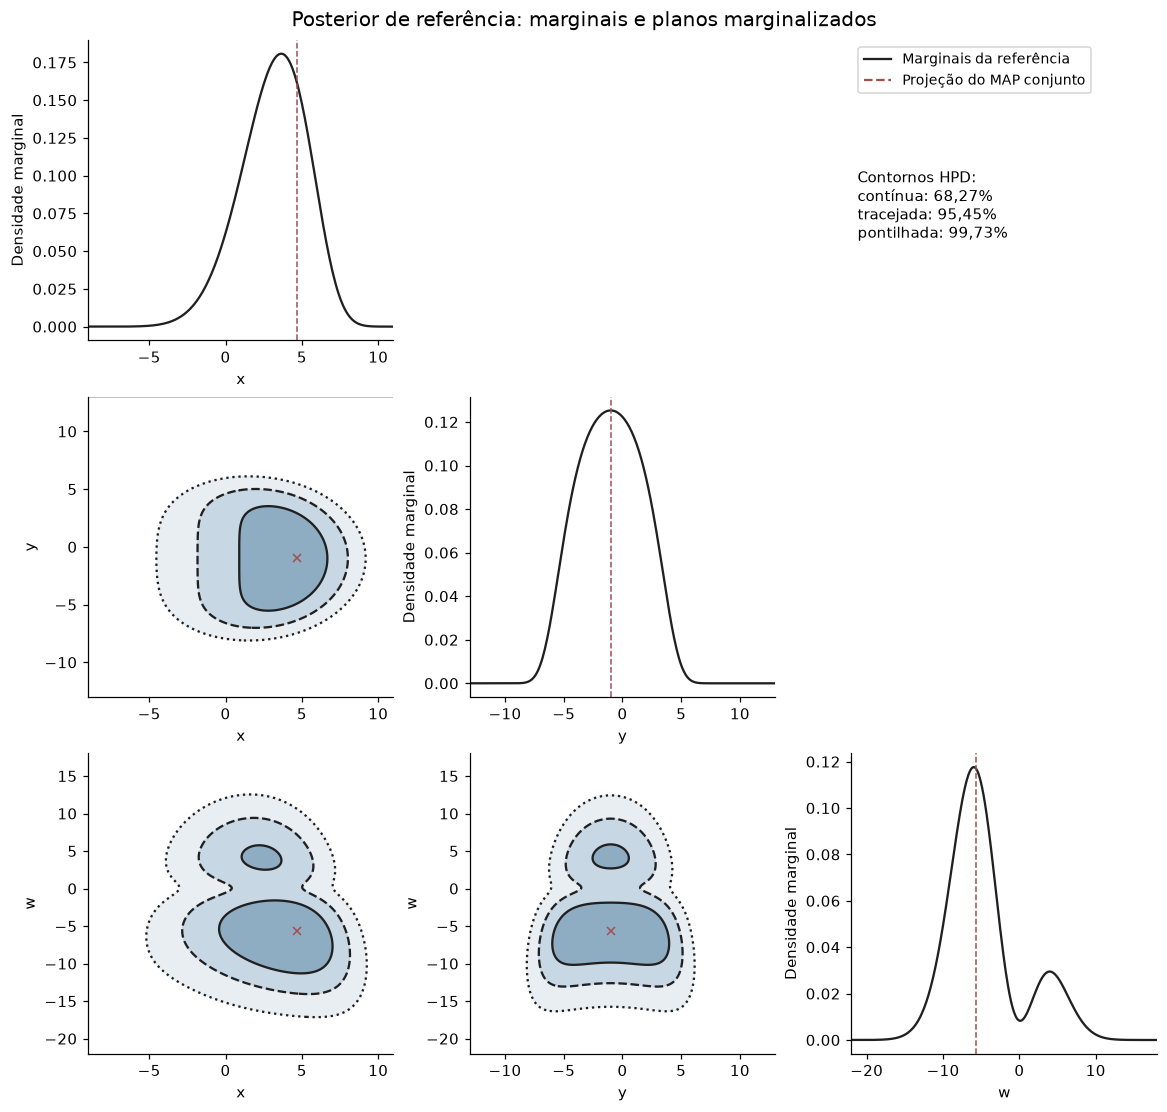

In [38]:
fig,axs=plt.subplots(3,3,figsize=(10.5,10),layout='constrained')  # Desenha um corner apenas da referência, sem sobrepor métodos.
for i in range(3):
    eixo=axes4[i]  # Seleciona o parâmetro da diagonal.
    axs[i,i].plot(eixo,ref4.marginals[i],color=COR4['Exata'])  # Mostra a marginal unidimensional.
    axs[i,i].axvline(theta_map4[i],color='#a14f4f',ls='--',lw=1)  # Distingue MAP conjunto de moda marginal.
    axs[i,i].set(xlabel=NOMES4[i],ylabel='Densidade marginal',xlim=LIMITES4[i])  # Usa o mesmo enquadramento dos demais gráficos.
    for j in range(3):
        if j>i:
            axs[i,j].axis('off')  # Deixa vazio o triângulo superior.
        elif j<i:
            pdf=ref4.pairs[j,i]  # Mantém i nas linhas do plano e j nas colunas.
            niveis=np.sort(dali.hpd_thresholds_2d(pdf,axes4[j],axes4[i],PROBS4))  # Localiza as três regiões de probabilidade.
            axs[i,j].contourf(axes4[j],axes4[i],pdf,levels=[*niveis,pdf.max()*1.001],colors=['#e8eef2','#c7d7e3','#8fadc2'])  # Destaca as regiões centrais.
            contornos4(axs[i,j],axes4[j],axes4[i],pdf,COR4['Exata'])  # Desenha as fronteiras HPD.
            axs[i,j].plot(theta_map4[j],theta_map4[i],'x',color='#a14f4f',ms=5)  # Projeta o MAP conjunto no mesmo plano.
            par_formatado4(axs[i,j],(j,i))  # Declara os eixos e seus limites.
axs[0,2].legend(handles=[Line2D([0],[0],color=COR4['Exata'],label='Marginais da referência'),
    Line2D([0],[0],color='#a14f4f',ls='--',label='Projeção do MAP conjunto')],loc='upper left',fontsize=9)  # Usa o espaço vazio para não cobrir as curvas.
axs[0,2].text(.02,.57,'Contornos HPD:\ncontínua: 68,27%\ntracejada: 95,45%\npontilhada: 99,73%',
    transform=axs[0,2].transAxes,va='top',fontsize=10)  # Explica o significado das linhas antes das comparações.
fig.suptitle('Posterior de referência: marginais e planos marginalizados',fontsize=13)  # Identifica o objeto mostrado.
figura4('01_corner_referencia',fig)  # Salva o corner completo da aplicação.


A referência confirma a assimetria negativa em $x$, com $\gamma_1\simeq-0.361$, e o excesso negativo de curtose em $y$, $\gamma_2\simeq-0.742$. A marginal de $y$ é muito próxima de simétrica em torno de $-1$. Em $w$, encontramos dois picos, mas a maior parte da massa está no ramo negativo: o acoplamento permite compensar a contribuição positiva de $x^2$.

Os parâmetros não se separam em uma coleção de distribuições independentes. Os planos do corner mostram quais combinações podem compensar umas às outras. Também fica visível que projetar o MAP conjunto não dá, em geral, as modas das marginais: integrar leva em conta o volume de parâmetros compatíveis, e não só a altura de um ponto.

Os pesos das duas bacias foram definidos operacionalmente pelo vale entre os picos da referência; $P(w>0)$ é informado separadamente. Não estamos inferindo pesos de componentes de um modelo de mistura que o enunciado não forneceu.


## 4.5. Por que a aproximação erra tanto em $y$?

No MAP, $\widehat y=-1$. Fixando apenas para esta dedução $x=\widehat x$ e $w=\widehat w$, escrevemos $s=y+1$ e

$$
r=\widehat r+\frac12s^2,\qquad
-\log\frac{q(\widehat x,y,\widehat w)}{q(\widehat\theta)}
=\frac{\widehat r}{2\sigma_y^2}s^2+\frac1{8\sigma_y^2}s^4.
$$

A curvatura local só conserva a primeira parcela. Como $\widehat r\simeq0.451$ é pequeno, a gaussiana local tem grande largura, $\sigma_{y,F}\simeq8.93$. O termo quártico reprime fortemente as caudas antes disso, mas não aparece nessa gaussiana. Já o dubleto o recupera porque ele vem do **quadrado da segunda derivada do modelo**.

O singleto perde ainda mais nessa direção: $J_{G,y}=0$ elimina toda a dependência de $y$ da parte aproximada. Como $h$ e a prior de $w$ também não dependem de $y$, sobra a prior uniforme em $[-13,13]$. Sua média é zero, seu desvio é $26/\sqrt{12}$ e seu excesso de curtose é $-1.2$. Portanto, ele produz curtose negativa, mas não a marginal correta. Esse é um exemplo de por que medir um momento isolado não basta para declarar que a distribuição foi recuperada.

A figura separa dois objetos: à esquerda, o perfil com $x,w$ fixos no MAP; à direita, a marginal obtida ao integrá-los. A gaussiana sem corte da questão 5 extrapola a prior de $y$. Para comparar os métodos na mesma região física, nossa **Laplace com suporte** corta essa gaussiana em $x,y\in[-13,13]$ e renormaliza a distribuição conjunta. A prior normal e o fator $h$ já entraram na curvatura local, portanto não serão multiplicados uma segunda vez.


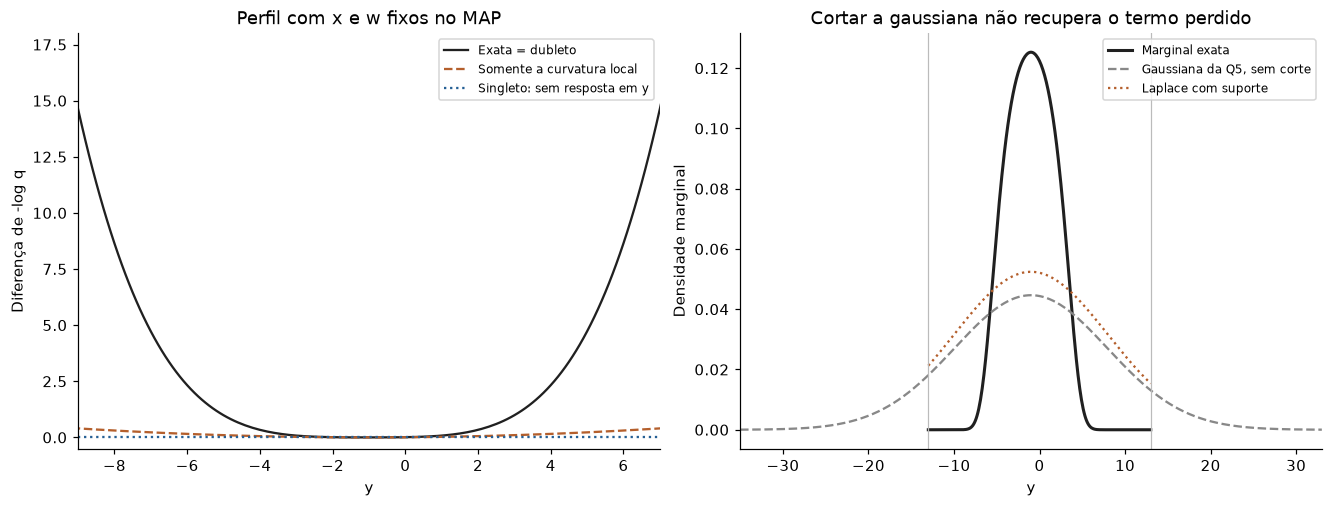

A gaussiana sem corte coloca 14.82% da massa marginal de y fora de [-13,13].


In [39]:
pontos_y4=np.tile(theta_map4,(axes4[1].size,1))  # Mantém x e w no MAP para estudar somente o perfil em y.
pontos_y4[:,1]=axes4[1]  # Percorre o eixo y do suporte físico.
s_y4=axes4[1]+1  # Mede o deslocamento em relação a y=-1.
rhat4=float(modelo4.prediction(theta_map4)[1])  # Calcula o resíduo quadrático no MAP.
potencial_y4=logpico4-modelo4.log_kernel(pontos_y4)  # Obtém a diferença de -log q sem aproximar o modelo.
quadratico_y4=.5*Hpost4[1,1]*s_y4**2  # Avalia a parcela que a gaussiana local conserva.
formula_y4=rhat4*s_y4**2/(2*modelo4.sigma_y**2)+s_y4**4/(8*modelo4.sigma_y**2)  # Acrescenta a parcela quártica completa.
assert np.max(abs(potencial_y4-formula_y4))<1e-10  # Confere a origem algébrica da não gaussianidade.
eixo_y_largo4=np.linspace(-35,33,1201)  # Amplia apenas a visualização da gaussiana que ignora o suporte.
sigma_y_local4=np.sqrt(SigmaF4[1,1])  # Obtém o desvio marginal da gaussiana local sem truncamento.
fora_y4=norm.cdf(-13,theta_map4[1],sigma_y_local4)+norm.sf(13,theta_map4[1],sigma_y_local4)  # Mede a massa que ela coloca fora da prior.
fig,axs=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')  # Separa perfil condicional e marginal global.
axs[0].plot(axes4[1],potencial_y4,color=COR4['Exata'],label='Exata = dubleto')  # Mostra o crescimento da forma quártica.
axs[0].plot(axes4[1],quadratico_y4,color=COR4['Laplace com suporte'],ls='--',label='Somente a curvatura local')
axs[0].plot(axes4[1],np.zeros_like(s_y4),color=COR4['D1'],ls=':',label='Singleto: sem resposta em y')
axs[0].set(xlabel='y',ylabel='Diferença de -log q',title='Perfil com x e w fixos no MAP',xlim=(-9,7),ylim=(-.5,18))
axs[0].legend(fontsize=8)  # Identifica o termo perdido na aproximação local.
axs[1].plot(axes4[1],ref4.marginals[1],color=COR4['Exata'],lw=2,label='Marginal exata')  # Usa a distribuição global integrada.
axs[1].plot(eixo_y_largo4,norm.pdf(eixo_y_largo4,theta_map4[1],sigma_y_local4),color='#888888',ls='--',label='Gaussiana da Q5, sem corte')
axs[1].plot(axes4[1],resultados4['Laplace com suporte'].marginals[1],color=COR4['Laplace com suporte'],ls=':',label='Laplace com suporte')
for borda in (-13,13):
    axs[1].axvline(borda,color='#bbbbbb',lw=.8)  # Marca as fronteiras da prior uniforme.
axs[1].set(xlabel='y',ylabel='Densidade marginal',title='Cortar a gaussiana não recupera o termo perdido',xlim=(-35,33))
axs[1].legend(fontsize=8)
figura4('02_mecanismo_em_y',fig)  # Salva as duas leituras complementares do problema.
print(f'A gaussiana sem corte coloca {fora_y4:.2%} da massa marginal de y fora de [-13,13].')  # Quantifica a extrapolação da prior.


## 4.6. Comparando as marginais e os planos dois a dois

Vamos agora comparar densidades globais, todas com o mesmo suporte e normalizadas nos três parâmetros. Cada linha das próximas figuras usa **uma** aproximação contra a referência. O dubleto representa também o tripleto e a quarta ordem porque já demonstramos sua identidade, não porque as curvas tenham sido ajustadas para parecer iguais.

Reutilizaremos a distância de variação total do Bloco 3. Um valor pequeno é necessário para considerar boa a distribuição inteira; compartilhar o sinal de uma assimetria, ter curtose negativa ou apresentar dois picos não garante isso. Para resumir a ordem necessária, adotaremos previamente $\mathrm{TV}<0.01$ como um critério descritivo de 1% e informaremos a primeira **ordem testada** que o satisfaz. Neste problema, o fechamento algébrico no dubleto é uma conclusão mais forte que esse limiar numérico.


,Método,x,y,w
0,Exata,0.000000e+00,0.000000e+00,0.000000e+00
1,Laplace com suporte,2.773012e-01,4.617035e-01,1.917133e-01
2,D1,1.281539e-01,5.711376e-01,1.527713e-01
3,D2,7.214931e-17,5.278338e-17,4.630950e-17


,Método,xy,xw,yw
0,Exata,0.000000e+00,0.000000e+00,0.000000e+00
1,Laplace com suporte,5.396343e-01,3.649377e-01,4.850446e-01
2,D1,6.030853e-01,2.842975e-01,6.141041e-01
3,D2,7.866072e-17,7.081194e-17,5.932046e-17


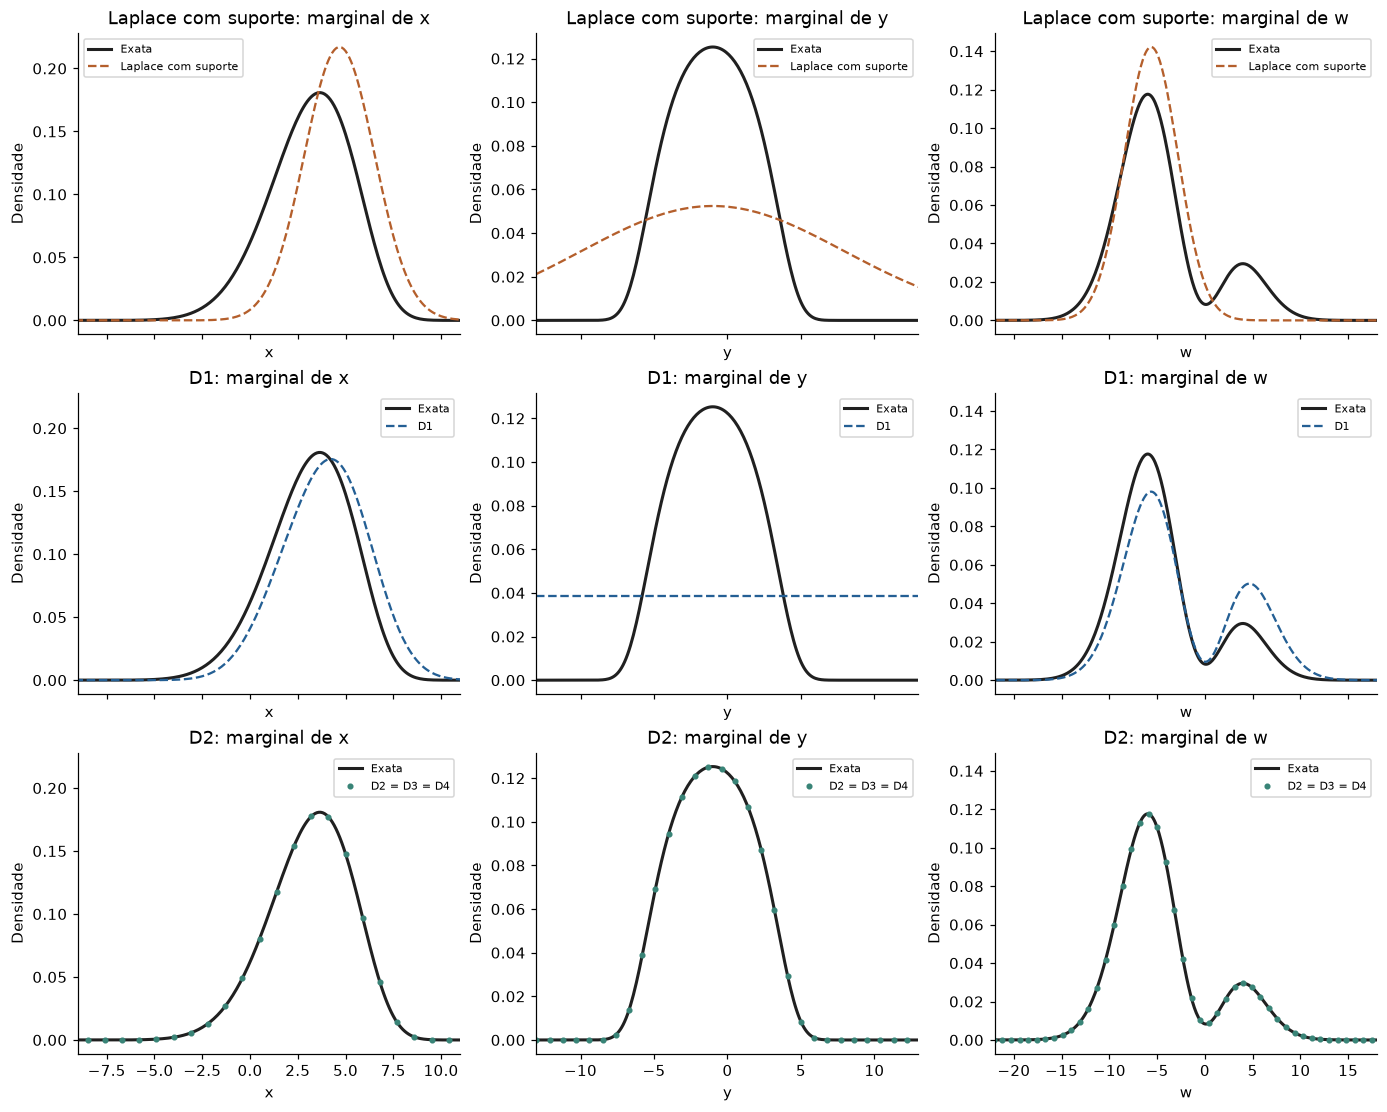

In [40]:
tv_marginais4={}  # Guarda as discrepâncias nas três marginais unidimensionais.
tv_pares4={}  # Guarda as discrepâncias nos três planos marginalizados.
linhas_tv1_4=[]  # Organiza a primeira tabela, com as marginais.
linhas_tv2_4=[]  # Organiza a segunda tabela, com os planos.
for nome,resultado in resultados4.items():
    tv_marginais4[nome]=[.5*simpson(abs(resultado.marginals[i]-ref4.marginals[i]),x=axes4[i]) for i in range(3)]  # Integra na coordenada física.
    tv_pares4[nome]=[.5*dali.integrate_grid_2d(abs(resultado.pairs[i,j]-ref4.pairs[i,j]),axes4[i],axes4[j]) for i,j in PARES4]  # Compara regiões de massa, não só contornos.
    linhas_tv1_4.append({'Método':nome,**dict(zip(NOMES4,tv_marginais4[nome]))})
    linhas_tv2_4.append({'Método':nome,**{NOMES4[i]+NOMES4[j]:v for (i,j),v in zip(PARES4,tv_pares4[nome])}})
tabela4('07_tv_marginais',pd.DataFrame(linhas_tv1_4))  # Mostra quando os traços visuais correspondem a boa fidelidade global.
tabela4('08_tv_planos',pd.DataFrame(linhas_tv2_4))  # Evita concluir pelo acordo de apenas uma marginal.
assert max(tv_marginais4['D2']+tv_pares4['D2'])<1e-11  # Confere a identidade depois de integrar e normalizar.
metodos_fig4=('Laplace com suporte','D1','D2')  # Separa as comparações para não empilhar muitas curvas.
fig,axs=plt.subplots(3,3,figsize=(12.5,10),sharex='col',sharey='col',layout='constrained')
for linha,nome in enumerate(metodos_fig4):
    for i,parametro in enumerate(NOMES4):
        ax=axs[linha,i]  # Seleciona a marginal e a aproximação desse painel.
        ax.plot(axes4[i],ref4.marginals[i],color=COR4['Exata'],lw=2,label='Exata')  # Mantém a mesma referência em todas as linhas.
        if nome=='D2':
            ax.plot(axes4[i][::9],resultados4[nome].marginals[i][::9],'o',ms=3,color=COR4[nome],label='D2 = D3 = D4')  # Torna visível a coincidência.
        else:
            ax.plot(axes4[i],resultados4[nome].marginals[i],color=COR4[nome],ls='--',label=nome)  # Usa só uma curva aproximada por painel.
        ax.set(xlabel=parametro,ylabel='Densidade',title=f'{nome}: marginal de {parametro}',xlim=LIMITES4[i])
        ax.legend(fontsize=7.5)  # Explicita os dois objetos que estão sendo comparados.
figura4('03_marginais_por_aproximacao',fig)


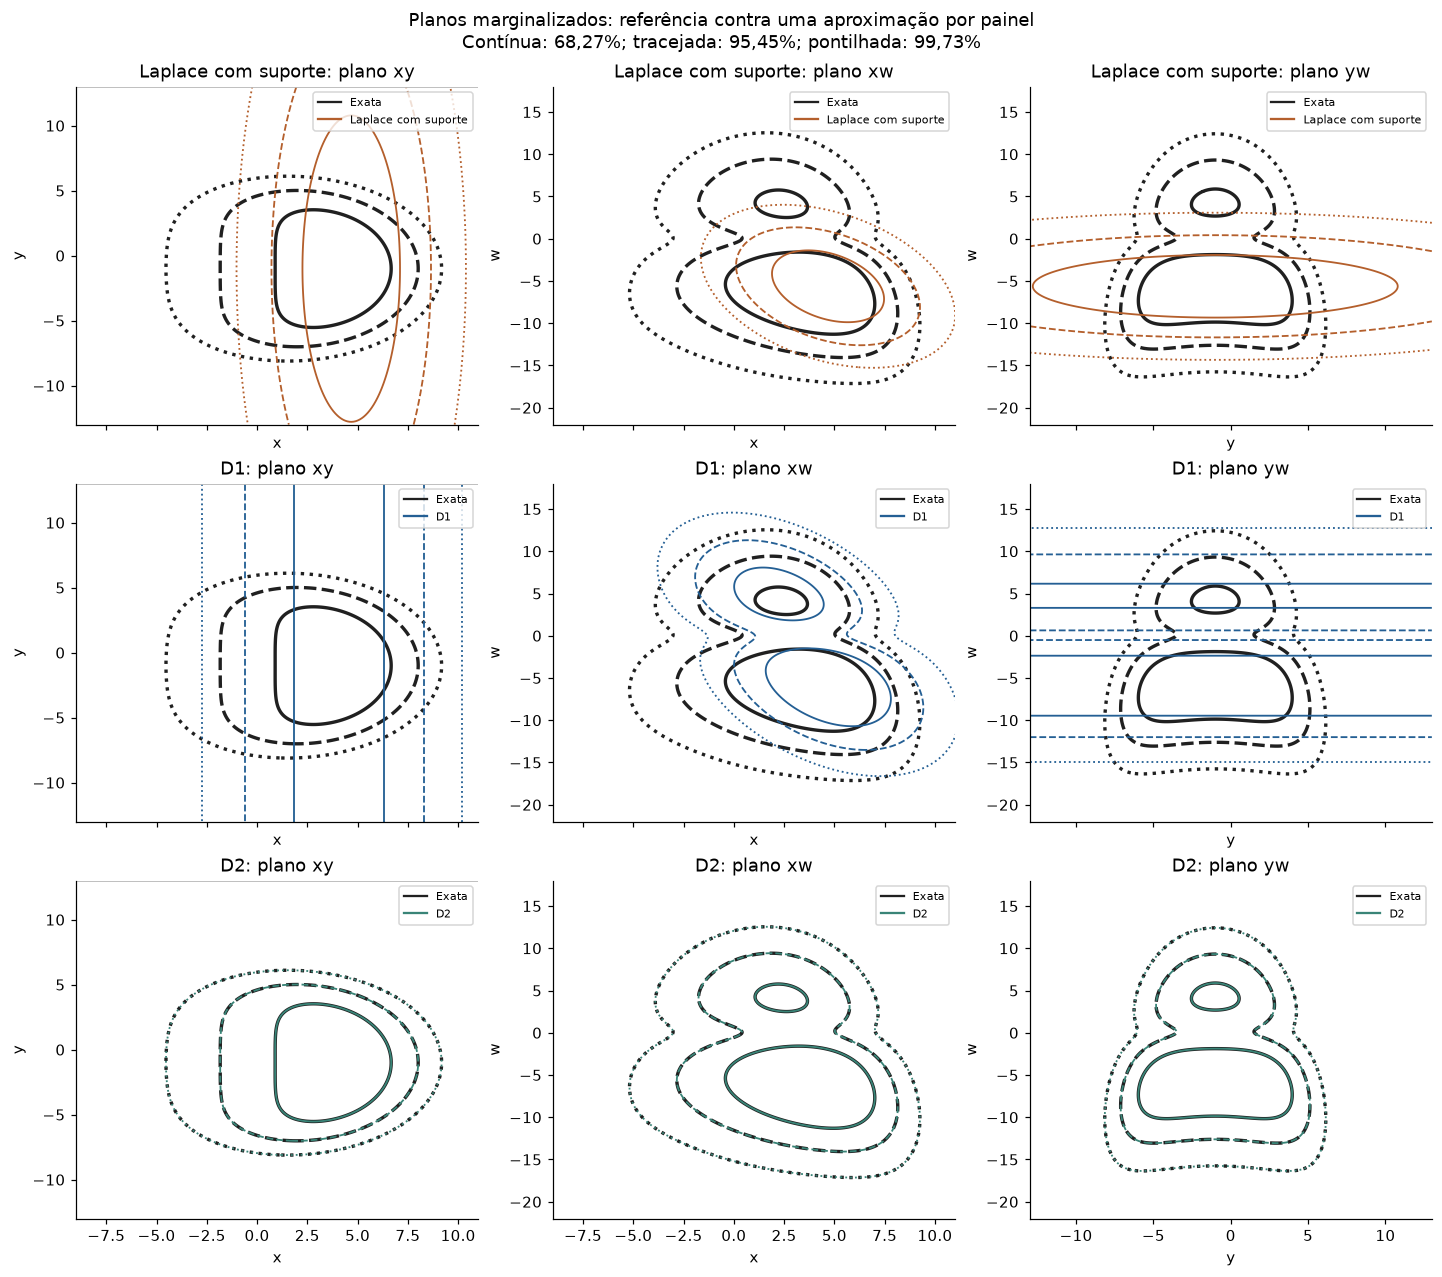

In [41]:
fig,axs=plt.subplots(3,3,figsize=(13,11.5),sharex='col',sharey='col',layout='constrained')  # Compara um método por linha e um par por coluna.
for linha,nome in enumerate(metodos_fig4):
    for coluna,(i,j) in enumerate(PARES4):
        ax=axs[linha,coluna]  # Seleciona o plano com eixos i,j.
        contornos4(ax,axes4[i],axes4[j],ref4.pairs[i,j],COR4['Exata'],lw=2.2)  # Usa os níveis próprios da referência.
        contornos4(ax,axes4[i],axes4[j],resultados4[nome].pairs[i,j],COR4[nome],lw=1.2)  # Usa os níveis próprios da aproximação.
        par_formatado4(ax,(i,j))  # Mantém escalas e suporte consistentes entre as linhas.
        ax.set_title(f'{nome}: plano {NOMES4[i]}{NOMES4[j]}')
        ax.legend(handles=[Line2D([0],[0],color=COR4['Exata'],label='Exata'),
                           Line2D([0],[0],color=COR4[nome],label=nome)],fontsize=7.5)  # A cor distingue método, não probabilidade.
fig.suptitle('Planos marginalizados: referência contra uma aproximação por painel\nContínua: 68,27%; tracejada: 95,45%; pontilhada: 99,73%',fontsize=12)
figura4('04_planos_por_aproximacao',fig)  # Salva todos os pares sem um corner com excesso de curvas.


O dubleto recupera as três marginais e os três planos, como previsto. Ter assimetria em $x$, excesso de curtose em $y$ e multimodalidade em $w$ não exigiu três ordens diferentes: essas propriedades são produzidas pela densidade final e sua integração, enquanto a ordem de DALI controla as derivadas do modelo dentro dela.

O singleto já produz assimetria em $x$ e dois picos em $w$, mas erra larguras, posições e pesos. Sua marginal uniforme em $y$ tem excesso de curtose negativo e, ainda assim, é uma representação ruim. A gaussiana local perde o segundo ramo de $w$ e a geometria curva das regiões conjuntas. Preservar seu suporte melhora a consistência com as priors, mas não reconstrói o termo do modelo que foi descartado.

A pequena assimetria em $y$ da gaussiana com suporte tem outra origem: sua curva é larga e centrada em $-1$, enquanto os limites da prior são simétricos em torno de zero. A truncagem remove massas diferentes das duas caudas. Na referência, a supressão quártica age muito antes das fronteiras e esse efeito é desprezível.

Alguns contornos tocam as fronteiras da prior; nesses casos, as curvas de nível podem ficar abertas no painel. A região HPD inclui também a fronteira do suporte. As probabilidades foram integradas no domínio completo, independentemente do enquadramento visual.


## 4.7. De onde vêm os dois ramos de $w$?

Para entender a competição sem misturar fatores, vamos primeiro olhar apenas para a prior e para o produto $h(w)\pi(w)$. Esse produto pode ser normalizado por $\mathbb E_\pi[h]=2\sigma_w^2+3$. Com os valores do enunciado, seus máximos não nulos satisfazem

$$
\frac{4}{2w^2+3}=\frac1{16}
\quad\Rightarrow\quad w=\pm\sqrt{30.5}.
$$

Isso já produz dois ramos simétricos. A posterior completa, porém, inclui também $r=A+w$: ele favorece compensações negativas para a contribuição de $A$ na maior parte da região favorecida. Os picos e pesos se deslocam e deixam de ser simétricos.

Como controle, faremos uma segunda inferência retirando $h$, mas conservando os fatores gaussianos e as mesmas priors. **Esse controle muda a likelihood; não é uma ordem de DALI.** Ele serve para identificar a contribuição de $h$ à bimodalidade. O singleto preserva essa contribuição exatamente, o que explica por que ele pode apresentar dois picos sem recuperar sua distribuição correta.


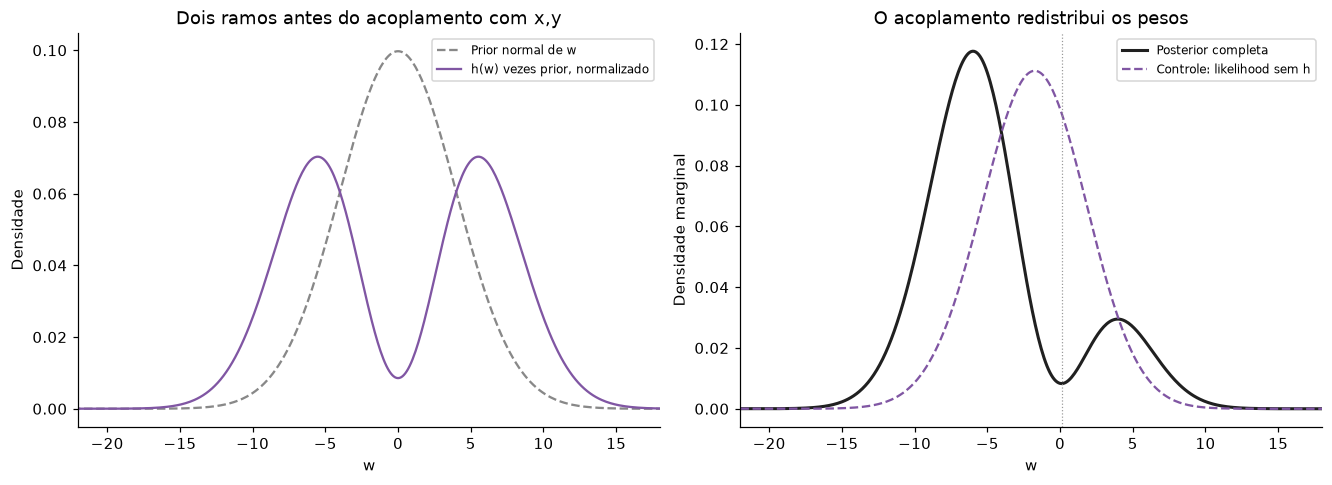

,Objeto,Picos em w,P(w>0)
0,Posterior completa,2,0.172648
1,Controle sem h,1,0.307602


In [42]:
sem_h4=dali.marginalize_grid_3d(lambda p:modelo4.log_kernel(p,include_factor=False),axes4,log_shift=0.)  # Calcula o controle com a mesma prior e sem h.
prior_w4=norm.pdf(axes4[2],0,modelo4.sigma_w)  # Avalia a prior gaussiana original de w.
h_prior4=(2*axes4[2]**2+3)*prior_w4/(2*modelo4.sigma_w**2+3)  # Normaliza apenas o produto h vezes a prior.
fig,axs=plt.subplots(1,2,figsize=(12,4.3),layout='constrained')
axs[0].plot(axes4[2],prior_w4,color='#888888',ls='--',label='Prior normal de w')  # Mostra o fator unimodal antes de h.
axs[0].plot(axes4[2],h_prior4,color='#8056a3',label='h(w) vezes prior, normalizado')  # Mostra a competição entre polinômio e gaussiana.
axs[0].set(xlabel='w',ylabel='Densidade',title='Dois ramos antes do acoplamento com x,y',xlim=LIMITES4[2])
axs[0].legend(fontsize=8)
axs[1].plot(axes4[2],ref4.marginals[2],color=COR4['Exata'],lw=2,label='Posterior completa')  # Mantém a referência do problema original.
axs[1].plot(axes4[2],sem_h4.marginals[2],color='#8056a3',ls='--',label='Controle: likelihood sem h')  # Isola o efeito de retirar o fator.
axs[1].axvline(separador_w4,color='#999999',lw=.8,ls=':')  # Marca a divisão operacional entre as bacias da referência.
axs[1].set(xlabel='w',ylabel='Densidade marginal',title='O acoplamento redistribui os pesos',xlim=LIMITES4[2])
axs[1].legend(fontsize=8)
figura4('05_fator_h_e_prior',fig)  # Exporta o diagnóstico dos dois ramos.
picos_sem_h4,_=find_peaks(sem_h4.marginals[2],prominence=.01*sem_h4.marginals[2].max())  # Aplica o mesmo critério de resolução dos modos.
tabela4('09_controle_sem_fator',pd.DataFrame([
    {'Objeto':'Posterior completa','Picos em w':len(picos_w4),'P(w>0)':dali.grid_tail_mass_1d(ref4.marginals[2],axes4[2],0.)},
    {'Objeto':'Controle sem h','Picos em w':len(picos_sem_h4),'P(w>0)':dali.grid_tail_mass_1d(sem_h4.marginals[2],axes4[2],0.)}]))  # Quantifica uma mudança de modelo, não uma melhora de aproximação.


A prior sozinha é unimodal. O produto com $h$ favorece dois módulos não nulos; o acoplamento da likelihood então favorece o ramo negativo e altera suas posições. O controle sem $h$ confirma que esse fator tem papel essencial na estrutura de dois ramos desta questão.

Esses picos são **verdadeiros na posterior de referência**. Não são os modos espúrios criados pelo truncamento no Bloco 3. Recuperar a multimodalidade significa preservar uma estrutura do problema; removê-la com uma única gaussiana é uma perda de informação, não uma regularização desejável.


## 4.8. Cortar e marginalizar: retomando a questão 4

No plano $(x,y)$, fixar $w=w_0$ significa usar

$$
p(x,y\mid w_0)=\frac{q(x,y,w_0)}{\int q(u,v,w_0)\,du\,dv}.
$$

Marginalizar significa integrar a posterior conjunta normalizada. As duas operações se relacionam por

$$
p(x,y)=\int p(x,y\mid w)\,p(w)\,dw.
$$

A marginal reúne cortes com seus pesos posteriores; não é o corte mais alto, nem uma média sem pesos. Em problemas não lineares, não há uma regra de que a marginal deva ser mais larga que **todo** corte particular. Precisamos ver quais regiões entram na mistura.

Vamos repetir os três procedimentos da lista para os três pares. Na coluna central, o terceiro parâmetro será fixado na **coordenada do MAP conjunto**, não na moda de sua marginal. Isso permite uma comparação direta com os resultados que já discutimos no Overleaf. Como o dubleto recupera $q$ inteiro, ele deve recuperar também todos esses cortes, depois de normalizá-los no plano.


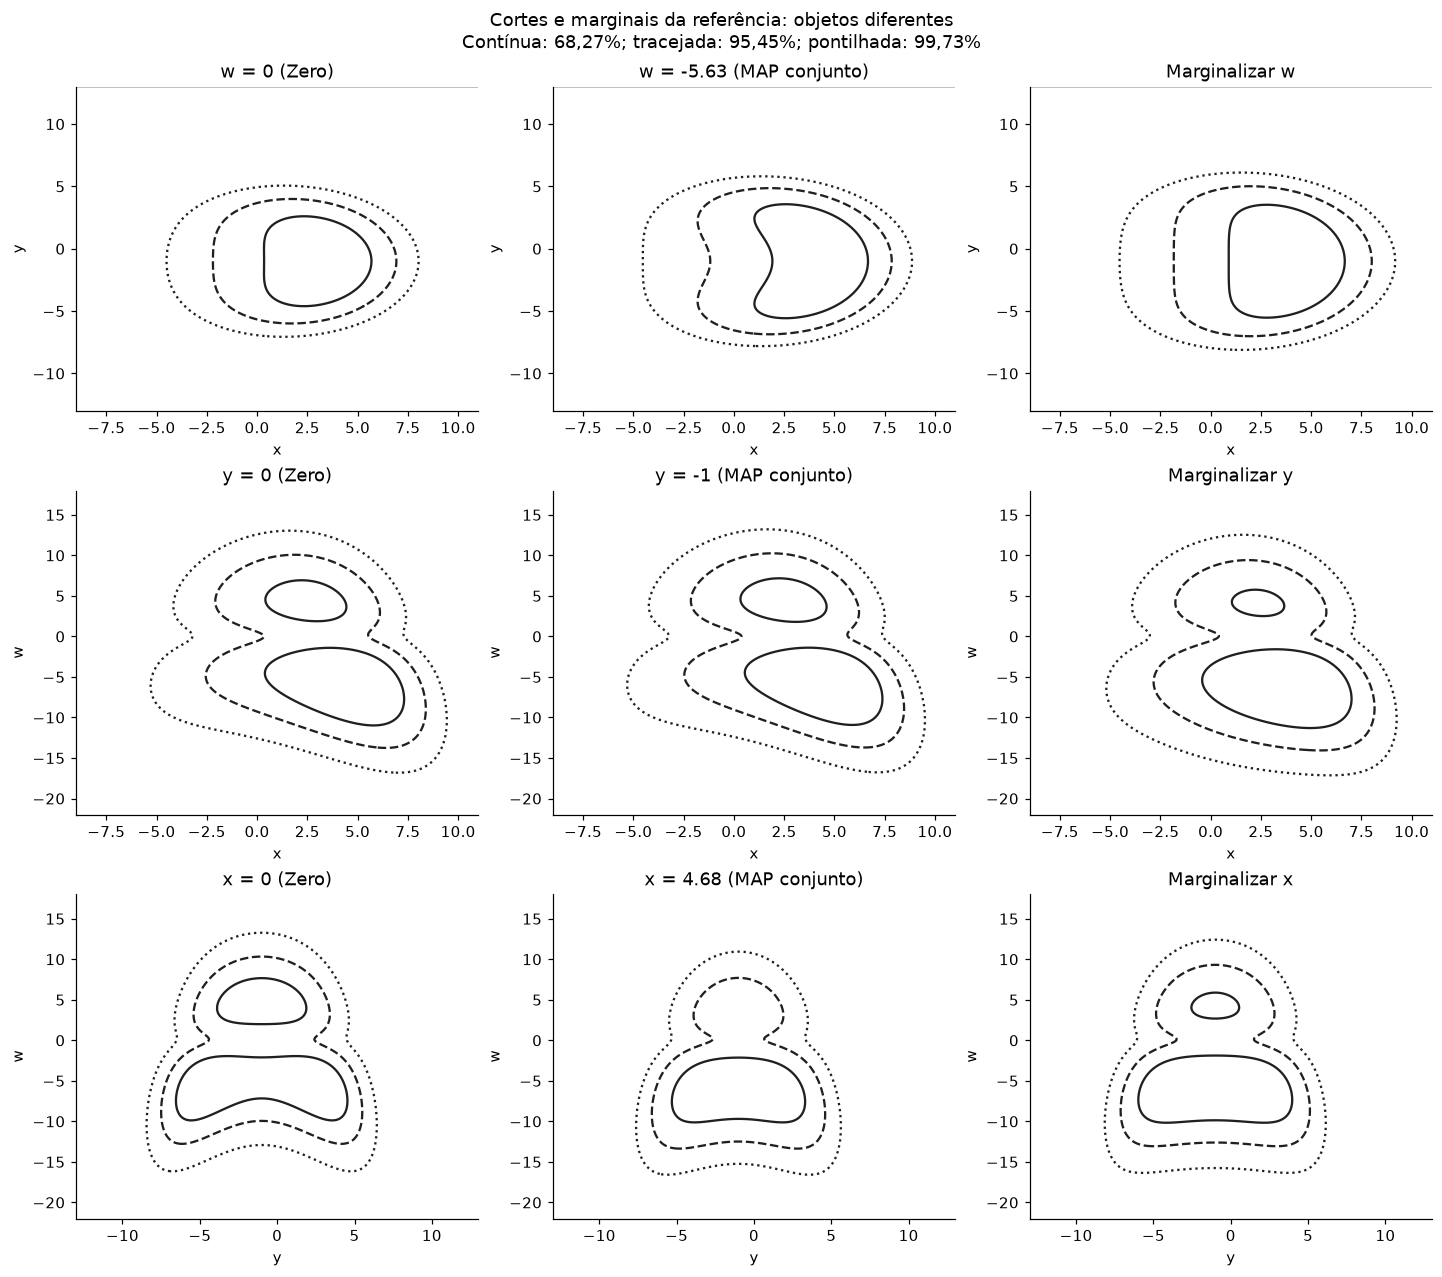

,Plano,Terceiro,Valor fixado,Tipo de corte,TV corte vs. marginal,TV D2 vs. corte exato
0,xy,w,0.000000,Zero,0.226803,1.037945e-16
1,xy,w,-5.628646,MAP conjunto,0.068886,7.170438e-17
2,xw,y,0.000000,Zero,0.154153,6.629467e-17
3,xw,y,-1.000000,MAP conjunto,0.181735,6.767393e-17
4,yw,x,0.000000,Zero,0.227733,1.222106e-16
5,yw,x,4.683180,MAP conjunto,0.140841,4.593177e-17


In [43]:
def corte4(par,valor,avaliador=modelo4.log_kernel):
    """Avalia e normaliza um corte no plano par, fixando o terceiro parâmetro."""
    i,j=par  # Identifica os dois eixos livres.
    outro=3-i-j  # Identifica o terceiro eixo, pois os índices são 0,1,2.
    primeiro,segundo=np.meshgrid(axes4[i],axes4[j])  # Monta o plano nas mesmas coordenadas dos marginais.
    pontos=np.empty(primeiro.shape+(3,))  # Reserva as três coordenadas em cada ponto do plano.
    pontos[...,i]=primeiro  # Preenche o primeiro parâmetro livre.
    pontos[...,j]=segundo  # Preenche o segundo parâmetro livre.
    pontos[...,outro]=valor  # Fixa o parâmetro condicionado.
    pdf,_=dali.normalize_log_grid(avaliador(pontos),axes4[i],axes4[j])  # Usa o normalizador próprio desse corte.
    return pdf

cortes4={}  # Guarda os cortes para as próximas comparações.
linhas_cortes4=[]  # Mede a diferença entre os cortes e as marginais do mesmo plano.
fig,axs=plt.subplots(3,3,figsize=(13,11.5),layout='constrained')
for linha,(i,j) in enumerate(PARES4):
    outro=3-i-j  # Determina qual parâmetro será fixado ou integrado.
    for coluna,(rotulo,valor) in enumerate([('Zero',0.),('MAP conjunto',theta_map4[outro])]):
        pdf=corte4((i,j),valor)  # Normaliza a posterior exata condicionada ao valor declarado.
        cortes4[((i,j),rotulo)]=pdf  # Guarda a densidade sem confundi-la com a marginal.
        pdf_d2=corte4((i,j),valor,avaliador=lambda p:log_dali4(p,2))  # Confere o mesmo corte pela expansão de segunda ordem.
        tv_d2=.5*dali.integrate_grid_2d(abs(pdf_d2-pdf),axes4[i],axes4[j])  # Mede o erro depois de normalizar o corte.
        assert tv_d2<1e-11  # A identidade do modelo deve valer também fora do centro, como em w=0.
        tv_marg=.5*dali.integrate_grid_2d(abs(pdf-ref4.pairs[i,j]),axes4[i],axes4[j])  # Distingue cortar de marginalizar.
        linhas_cortes4.append({'Plano':NOMES4[i]+NOMES4[j],'Terceiro':NOMES4[outro],'Valor fixado':valor,
                              'Tipo de corte':rotulo,'TV corte vs. marginal':tv_marg,'TV D2 vs. corte exato':tv_d2})
        contornos4(axs[linha,coluna],axes4[i],axes4[j],pdf,COR4['Exata'])  # Mostra apenas a referência em cada painel.
        par_formatado4(axs[linha,coluna],(i,j))
        axs[linha,coluna].set_title(f'{NOMES4[outro]} = {valor:.3g} ({rotulo})')  # Identifica o objeto condicionado.
    contornos4(axs[linha,2],axes4[i],axes4[j],ref4.pairs[i,j],COR4['Exata'])  # Mostra a integração como terceiro objeto.
    par_formatado4(axs[linha,2],(i,j))
    axs[linha,2].set_title(f'Marginalizar {NOMES4[outro]}')
fig.suptitle('Cortes e marginais da referência: objetos diferentes\nContínua: 68,27%; tracejada: 95,45%; pontilhada: 99,73%',fontsize=12)
figura4('06_cortes_e_marginais',fig)  # Salva as nove leituras da posterior da questão 4.
tabela4('10_cortes_e_marginais',pd.DataFrame(linhas_cortes4))  # Quantifica as diferenças e verifica D2 nos cortes.


Fixar $w$ muda quais combinações de $x^2$ e $(y+1)^2$ podem compensar o resíduo. No plano $(x,y)$, o corte em zero e o corte no MAP conjunto respondem a informações distintas sobre $w$. Marginalizar reúne também outras compensações, com os pesos que a posterior de $w$ permite.

Nos planos que mantêm $w$ livre, o fator $h$ continua presente e pode manter dois ramos, mesmo depois de fixar o terceiro parâmetro. Já quando fixamos $w$, $h(w_0)$ é uma constante e desaparece ao normalizar o corte. Essa diferença explica por que as estruturas dos três planos não precisam se parecer.

O acordo de D2 com os cortes reforça a interpretação anterior: não foi uma coincidência apenas das marginais. Ele representa o núcleo completo e, por isso, permanece correto ao condicionar ou integrar.


### A pergunta que fiz ao final da lista: e se expandirmos no próprio corte?

Na resolução, fiquei incomodado com a largura de $y$ quando condicionamos a gaussiana conjunta a $w=0$. Há duas operações diferentes: aproximar a posterior conjunta no seu MAP e depois cortar, ou primeiro condicionar a $w=0$ e construir uma nova gaussiana no máximo desse corte.

Se $a=(x,y)$, a primeira rota usa

$$
H_{a\mid w}=H_{aa},\qquad
m_{a\mid w=0}=\widehat a-H_{aa}^{-1}H_{aw}(0-\widehat w).
$$

A marginalização gaussiana tem outra precisão, dada pelo complemento de Schur:

$$
H_{a,\mathrm{marg}}=H_{aa}-H_{aw}H_{ww}^{-1}H_{wa}.
$$

Seu núcleo permanece centrado em $\widehat a$. Essas fórmulas descrevem a gaussiana antes de impor as fronteiras; em seguida conservamos o suporte de $x,y$ e renormalizamos. Por isso, o centro do núcleo pode diferir da média após a truncagem. Vamos conferir a fórmula de Schur contra a integração numérica da gaussiana conjunta.

A segunda rota encontra o máximo do corte exato e calcula a Hessiana nesse novo ponto. Esperamos uma melhora porque a curvatura passa a descrever a região que está sendo condicionada, em vez de extrapolar desde outro centro. Ainda assim, uma gaussiana continua sem o termo quártico de $y$.


,Objeto,Média x,Desvio y,TV vs. corte exato
0,Exata,2.513263,2.180010,0.000000
1,"Conjunta, depois corte",3.383185,6.485712,0.572327
2,Gaussiana no corte,3.434505,3.435730,0.282899


,Objeto,Centro do núcleo x,Centro do núcleo y,Precisão xx,Precisão xy,Precisão yy
0,"Conjunta, depois corte",3.383185,-1.0,0.337950,0.0,0.012528
1,"Conjunta, depois marginalização",4.683180,-1.0,0.295964,0.0,0.012528
2,Gaussiana no corte,3.434507,-1.0,0.279715,0.0,0.084410


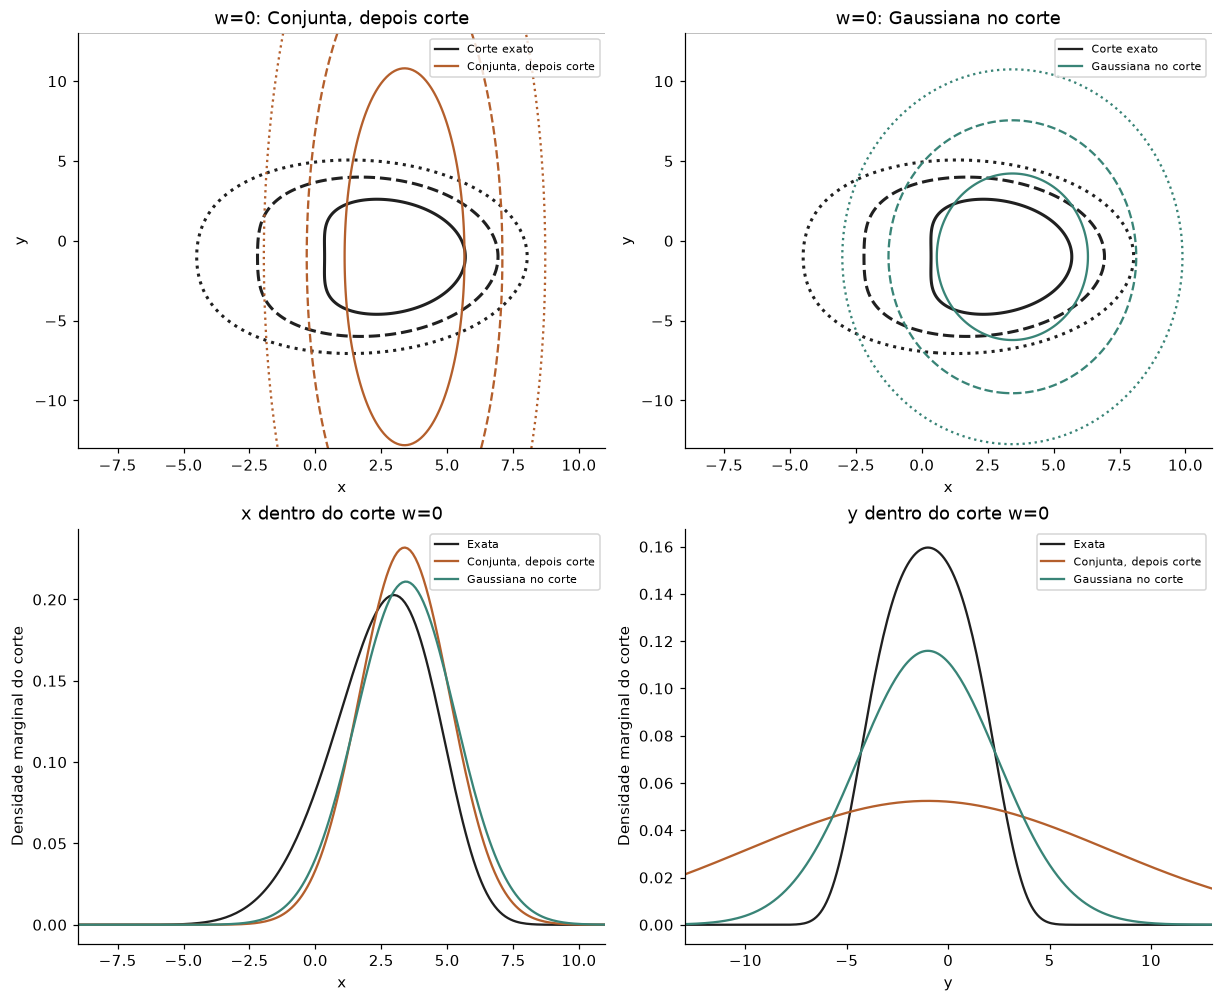

In [44]:
Haa4=Hpost4[:2,:2]  # Seleciona a precisão condicional da gaussiana conjunta.
m_cond4=theta_map4[:2]-np.linalg.solve(Haa4,Hpost4[:2,2])*(0-theta_map4[2])  # Condiciona a gaussiana conjunta a w=0.
ajuste_corte4=minimize(lambda t:-float(modelo4.log_kernel([t[0],t[1],0.])),[3.4,-1.],
    jac=lambda t:-modelo4.gradient([t[0],t[1],0.])[:2],method='L-BFGS-B',
    bounds=[(-13,13),(-13,13)],options={'gtol':1e-11,'ftol':1e-14})  # Refaz o ajuste diretamente no corte.
m_proprio4=ajuste_corte4.x  # Guarda o centro do corte exato.
Hproprio4=modelo4.hessian([*m_proprio4,0.])[:2,:2]  # Calcula a curvatura no ponto apropriado ao corte.
pts_xy4=np.stack((xx4,yy4),axis=-1)  # Organiza as coordenadas do plano x,y.
Hmarg4=Haa4-np.outer(Hpost4[:2,2],Hpost4[2,:2])/Hpost4[2,2]  # Integra w analiticamente pelo complemento de Schur.
delta_marg4=pts_xy4-theta_map4[:2]  # Mantém o centro do núcleo da marginal gaussiana.
log_marg4=-.5*np.einsum('...a,ab,...b->...',delta_marg4,Hmarg4,delta_marg4)  # Avalia a gaussiana marginal antes de normalizar.
p_schur4,_=dali.normalize_log_grid(log_marg4,*axes4[:2])  # Impõe o mesmo suporte utilizado na integração da conjunta.
assert np.max(abs(p_schur4-resultados4['Laplace com suporte'].pairs[0,1]))<1e-10  # Confere a marginalização por duas rotas independentes.
delta_cond4=pts_xy4-m_cond4  # Mede os deslocamentos a partir do centro condicionado da gaussiana conjunta.
delta_proprio4=pts_xy4-m_proprio4  # Mede os deslocamentos a partir do centro encontrado no corte.
log_cond4=-.5*np.einsum('...a,ab,...b->...',delta_cond4,Haa4,delta_cond4)  # Avalia a primeira aproximação gaussiana.
log_proprio4=-.5*np.einsum('...a,ab,...b->...',delta_proprio4,Hproprio4,delta_proprio4)  # Avalia a aproximação refeita no corte.
p_cond4,_=dali.normalize_log_grid(log_cond4,*axes4[:2])  # Mantém o suporte de x,y também na gaussiana condicionada.
p_proprio4,_=dali.normalize_log_grid(log_proprio4,*axes4[:2])  # Normaliza a aproximação centrada no próprio corte.
exato_corte4=cortes4[((0,1),'Zero')]  # Usa a mesma referência exata que apareceu na figura anterior.
objetos_corte4={'Exata':exato_corte4,'Conjunta, depois corte':p_cond4,'Gaussiana no corte':p_proprio4}  # Declara as três densidades comparadas.
linhas_centro4=[]  # Registra o efeito do novo ponto de expansão.
for nome,pdf in objetos_corte4.items():
    media,cov=dali.grid_moments_2d(pdf,*axes4[:2])  # Integra os momentos dessas densidades condicionais.
    linhas_centro4.append({'Objeto':nome,'Média x':media[0],'Desvio y':np.sqrt(cov[1,1]),
        'TV vs. corte exato':.5*dali.integrate_grid_2d(abs(pdf-exato_corte4),*axes4[:2])})
tabela4('11_expansao_no_corte',pd.DataFrame(linhas_centro4))  # Quantifica a melhora sem declará-la perfeita.
linhas_precisoes4=[]  # Separa as curvaturas de condicionar, marginalizar e refazer a expansão.
for nome,centro,precisao in [('Conjunta, depois corte',m_cond4,Haa4),
    ('Conjunta, depois marginalização',theta_map4[:2],Hmarg4),('Gaussiana no corte',m_proprio4,Hproprio4)]:
    linhas_precisoes4.append({'Objeto':nome,'Centro do núcleo x':centro[0],'Centro do núcleo y':centro[1],
        'Precisão xx':precisao[0,0],'Precisão xy':precisao[0,1],'Precisão yy':precisao[1,1]})  # Não confunde centro do núcleo com média após truncar.
tabela4('11b_precisoes_gaussianas',pd.DataFrame(linhas_precisoes4))  # Relaciona as fórmulas às matrizes realmente usadas.
fig,axs=plt.subplots(2,2,figsize=(11,9),layout='constrained')
for coluna,(nome,pdf,cor) in enumerate([('Conjunta, depois corte',p_cond4,'#b45f2c'),('Gaussiana no corte',p_proprio4,'#398477')]):
    contornos4(axs[0,coluna],*axes4[:2],exato_corte4,COR4['Exata'],lw=2)  # Mantém a referência em ambos os painéis superiores.
    contornos4(axs[0,coluna],*axes4[:2],pdf,cor)  # Acrescenta somente uma aproximação por painel.
    par_formatado4(axs[0,coluna],(0,1))
    axs[0,coluna].set_title(f'w=0: {nome}')
    axs[0,coluna].legend(handles=[Line2D([0],[0],color=COR4['Exata'],label='Corte exato'),Line2D([0],[0],color=cor,label=nome)],fontsize=7.5)
for i in (0,1):
    ax=axs[1,i]  # Compara as marginais do corte, e não as marginais da posterior conjunta.
    for nome,pdf in objetos_corte4.items():
        marginal=simpson(pdf,x=axes4[1-i],axis=0 if i==0 else 1)  # Integra o outro parâmetro livre no plano condicionado.
        cor={'Exata':COR4['Exata'],'Conjunta, depois corte':'#b45f2c','Gaussiana no corte':'#398477'}[nome]
        ax.plot(axes4[i],marginal,color=cor,label=nome)  # Mostra no máximo três curvas, cada uma com um significado explícito.
    ax.set(xlabel=NOMES4[i],ylabel='Densidade marginal do corte',title=f'{NOMES4[i]} dentro do corte w=0',xlim=LIMITES4[i])
    ax.legend(fontsize=7.5)
figura4('07_centro_da_expansao_no_corte',fig)


Refazer a expansão no máximo do corte reduz bastante a largura indevida em $y$ e melhora a representação da região central. Isso retoma a observação feita na lista, agora separando o efeito do centro daquele devido à ordem truncada.

A melhora não torna a forma gaussiana exata: a marginal de $x$ continua deslocada, pois a curvatura local não recupera o volume das regiões integradas em $y$. O dubleto resolve esse corte por outra razão: ele conserva a resposta quadrática e seu quadrado completo. Como não há resto de Taylor do modelo depois da segunda ordem, seu acordo independe de o centro ser o MAP conjunto ou o máximo do corte, desde que o resíduo seja preservado.


## 4.9. Qual ordem recupera cada distribuição?

Vamos reunir a resposta sem associar mecanicamente o momento de ordem três a DALI de terceira ordem ou a curtose à quarta ordem. A primeira ordem já produz alguns desses traços por causa dos fatores mantidos exatos, mas isso não garante suas magnitudes, suas larguras ou seus pesos.

Na figura, o ponto chamado Laplace é a gaussiana local com suporte, e não uma ordem de DALI. Os pontos D3 e D4 reutilizam D2 pela identidade já demonstrada e conferida em log. A tabela de ordem mínima considera as distribuições completas, pelo critério TV definido antes das comparações.


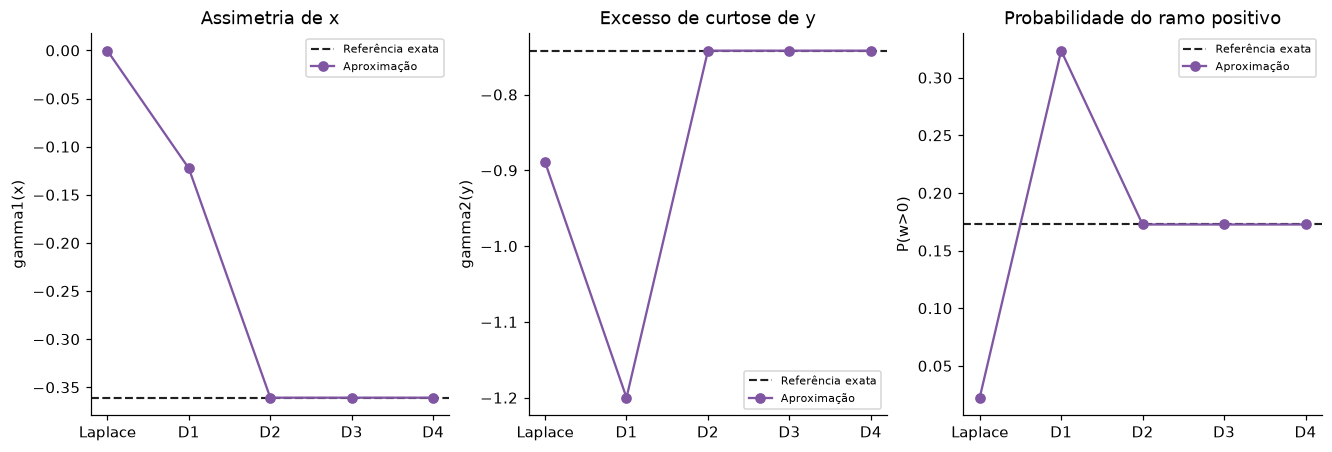

,Objeto,Primeira ordem testada com TV<0.01,Ordem que fecha o modelo exatamente
0,Marginal x,2,2
1,Marginal y,2,2
2,Marginal w,2,2
3,Plano xy,2,2
4,Plano xw,2,2
5,Plano yw,2,2


In [45]:
labels_ordem4=['Laplace','D1','D2','D3','D4']  # Distingue a gaussiana local da hierarquia de DALI.
objetos_ordem4=[resultados4['Laplace com suporte'],resultados4['D1'],resultados4['D2'],resultados4['D2'],resultados4['D2']]  # Usa a identidade D2=D3=D4, sem simular curvas diferentes.
serie_skew4=[dali.density_moments_1d(r.marginals[0],axes4[0])['skewness'] for r in objetos_ordem4]  # Compara a assimetria de x.
serie_kurt4=[dali.density_moments_1d(r.marginals[1],axes4[1])['excess_kurtosis'] for r in objetos_ordem4]  # Compara o excesso de curtose de y.
serie_pw4=[dali.grid_tail_mass_1d(r.marginals[2],axes4[2],0.) for r in objetos_ordem4]  # Compara uma probabilidade global dos ramos.
referencias_ordem4=[momentos4['Exata'][0]['skewness'],momentos4['Exata'][1]['excess_kurtosis'],
                   dali.grid_tail_mass_1d(ref4.marginals[2],axes4[2],0.)]  # Mantém o mesmo alvo em cada diagnóstico.
fig,axs=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,serie,referencia,titulo,ylabel in zip(axs,[serie_skew4,serie_kurt4,serie_pw4],referencias_ordem4,
    ['Assimetria de x','Excesso de curtose de y','Probabilidade do ramo positivo'],['gamma1(x)','gamma2(y)','P(w>0)']):
    ax.axhline(referencia,color=COR4['Exata'],ls='--',lw=1.4,label='Referência exata')  # Marca o valor verdadeiro da comparação.
    ax.plot(labels_ordem4,serie,'o-',color='#8056a3',label='Aproximação')  # Mostra a estabilização a partir do dubleto.
    ax.set(title=titulo,ylabel=ylabel)  # Nomeia o momento ou a probabilidade representada.
    ax.legend(fontsize=7.5)
figura4('08_ordem_e_diagnosticos',fig)
linhas_minimas4=[]  # Reúne a primeira ordem testada que satisfaz o critério global de fidelidade.
for i,parametro in enumerate(NOMES4):
    tv_por_ordem=[tv_marginais4['D1'][i]]+[tv_marginais4['D2'][i]]*3  # Usa as ordens 1 a 4 verificadas.
    minimo=next(k for k,v in enumerate(tv_por_ordem,start=1) if v<.01)  # Aplica o mesmo limiar de 1% a cada marginal.
    linhas_minimas4.append({'Objeto':'Marginal '+parametro,'Primeira ordem testada com TV<0.01':minimo,'Ordem que fecha o modelo exatamente':2})
for indice,(i,j) in enumerate(PARES4):
    tv_por_ordem=[tv_pares4['D1'][indice]]+[tv_pares4['D2'][indice]]*3  # Repete o critério para as distribuições de pares.
    minimo=next(k for k,v in enumerate(tv_por_ordem,start=1) if v<.01)
    linhas_minimas4.append({'Objeto':'Plano '+NOMES4[i]+NOMES4[j],'Primeira ordem testada com TV<0.01':minimo,'Ordem que fecha o modelo exatamente':2})
tabela4('12_ordem_necessaria',pd.DataFrame(linhas_minimas4))  # Responde à pergunta principal para marginais e pares.


### A referência e a resolução dos modos estão estáveis?

A identidade de D2 é algébrica; a qualidade da quadratura ainda precisa ser conferida. Já comparamos a marginal $(x,y)$ com a integral analítica em todo $w$. Agora refinaremos $x,y$ e, separadamente, ampliaremos o recorte de $w$, conservando as priors. Compararemos médias, desvios, assimetrias e excessos de curtose, além da localização dos picos resolvidos em $w$.


In [46]:
casos_convergencia4=[('Refinar x,y',(np.linspace(-13,13,321),np.linspace(-13,13,321),axes4[2])),  # Melhora a resolução no mesmo suporte.
                    ('Ampliar w',(axes4[0],axes4[1],np.linspace(-40,40,801)))]  # Conserva o passo de w e inclui caudas mais distantes.
linhas_convergencia4=[]  # Mede os efeitos das duas mudanças numéricas separadamente.
for descricao,eixos in casos_convergencia4:
    refinado=dali.marginalize_grid_3d(modelo4.log_kernel,eixos,log_shift=logpico4)  # Reintegra somente a referência para conferir sua estabilidade.
    for i,parametro in enumerate(NOMES4):
        stats=dali.density_moments_1d(refinado.marginals[i],eixos[i])  # Recalcula os momentos com a nova integração.
        base=momentos4['Exata'][i]  # Recupera os números da malha principal.
        linhas_convergencia4.append({'Conferência':descricao,'Parâmetro':parametro,
            'Diferença média':abs(stats['mean']-base['mean']),'Diferença desvio':abs(stats['std']-base['std']),
            'Diferença gamma1':abs(stats['skewness']-base['skewness']),
            'Diferença gamma2':abs(stats['excess_kurtosis']-base['excess_kurtosis']),
            'Diferença log integral':abs(refinado.log_normalizer-ref4.log_normalizer)})
        assert max(abs(stats[k]-base[k]) for k in ('mean','std','skewness','excess_kurtosis'))<2e-6  # Exige erro numérico muito menor que as discrepâncias das aproximações.
    picos,_=find_peaks(refinado.marginals[2],prominence=.01*refinado.marginals[2].max())  # Confere que a bimodalidade não depende de uma malha específica.
    assert len(picos)==2  # Mantém a contagem com o mesmo critério de proeminência.
tabela4('13_convergencia',pd.DataFrame(linhas_convergencia4))  # Registra a precisão dos números que sustentam a interpretação.


,Conferência,Parâmetro,Diferença média,Diferença desvio,Diferença gamma1,Diferença gamma2,Diferença log integral
0,"Refinar x,y",x,1.776357e-15,2.664535e-15,1.243450e-14,4.041212e-14,2.131628e-14
1,"Refinar x,y",y,1.110223e-16,0.000000e+00,9.068664e-17,0.000000e+00,2.131628e-14
2,"Refinar x,y",w,1.776357e-15,1.776357e-15,2.220446e-15,3.996803e-15,2.131628e-14
3,Ampliar w,x,1.323386e-13,1.216804e-13,2.539080e-13,3.437250e-13,5.684342e-14
4,Ampliar w,y,0.000000e+00,3.494982e-13,9.068664e-17,9.854340e-13,5.684342e-14
5,Ampliar w,w,1.556977e-12,4.246381e-12,1.133726e-11,4.563416e-11,5.684342e-14


O refinamento e a ampliação da cauda mantêm os momentos e os dois picos de $w$. A comparação com a integral analítica confirma a referência por outra rota. Os erros de quadratura são muito menores que as diferenças entre a gaussiana local, o singleto e a posterior exata.

Podemos então responder à pergunta principal: **com $h$ e as priors mantidos exatos, a segunda ordem do modelo basta para recuperar todas as marginais, todos os pares e os cortes desta questão**. A terceira e quarta ordens não trazem melhora adicional porque suas derivadas do modelo são zero. Isso não corresponde a aproximar o fator $h$ por uma gaussiana, nem a truncar diretamente a Taylor da log-posterior até grau quatro.

O singleto já conserva parte da não gaussianidade de $w$ por manter $h$ e a prior. Ainda assim, ele erra a distribuição global. Em $y$, sua curtose negativa vem de uma uniforme que perdeu a resposta do modelo, enquanto a posterior correta é uma distribuição suave, aproximadamente simétrica em torno de $-1$. A aplicação mostra por que precisamos combinar momentos, pesos e regiões conjuntas para avaliar uma aproximação.

Essa também é a diferença em relação aos modos espúrios do bloco anterior: a bimodalidade aqui é parte da referência. Já a próxima aplicação, com supernovas, terá um modelo que não termina num polinômio quadrático. Nela, a fidelidade das ordens precisará ser medida novamente; o fechamento encontrado nesta lista não é uma garantia geral.



<a id="bloco-5"></a>

# 5. Supernovas: das medidas às aproximações de DALI

Até aqui, escolhemos modelos controlados e retomamos uma posterior da Lista 3. Agora queremos partir de medidas observacionais. Isso acrescenta uma pergunta antes da expansão: **o que o instrumento e a análise do catálogo medem, e como uma cosmologia prevê esses valores?**

Vamos reconstruir a aplicação de supernovas da Seção 3 e da Figura 1 de Sellentin, Quartin e Amendola (2014), usando as 580 supernovas do Union2.1 e um modelo $w$CDM plano. A reprodução é metodológica: documentaremos nossas priors, determinaremos nosso próprio ponto de expansão e conservaremos os resíduos observados. Ao lado dessa inferência, faremos um experimento fiducial sem realização de ruído, no qual a definição esperada de Fisher coincide com a curvatura local.

As perguntas são:

1. Como redshift e módulo de distância se relacionam com $\mu(\theta)$ e $C$ dos blocos anteriores?
2. Por que precisamos retirar uma constante de calibração, e o que deixamos de medir ao fazer isso?
3. Como Fisher, dubleto, tripleto e quarta ordem descrevem a posterior observacional?
4. Uma mudança de parâmetros ou uma ordem maior pode criar um máximo que os dados não sustentam?
5. A referência em malha é confirmada por cadeias que avaliam a likelihood completa?

O núcleo deste bloco é bidimensional, com $w$ constante. As figuras tridimensionais do artigo com $w_a$ livre não serão chamadas de reproduzidas aqui. A quarta ordem, a investigação das coordenadas, o controle com a covariância sistemática e a verificação por MCMC são extensões desta implementação.


## 5.1. O que uma supernova nos fornece?

Uma supernova Ia pode ser usada como **vela padronizável**. Isso não significa que todas tenham luminosidade idêntica. A equipe do catálogo ajusta as curvas de luz e aplica correções, incluindo efeitos de forma, cor e população hospedeira. O Union2.1 fornece módulos de distância já tratados por essa análise. Não vamos reconstruir fotometria bruta nem reaplicar essas correções.

O fluxo $f$ e a luminosidade $L$ definem a distância de luminosidade:

$$
f=\frac{L}{4\pi d_L^2},\qquad
\mu_{\rm dist}=m-M=5\log_{10}\!\left(\frac{d_L}{\mathrm{Mpc}}\right)+25.
$$

Aqui, $m$ e $M$ são magnitudes aparente e absoluta, e $\mu_{\rm dist}$ é o módulo de distância. O fator 25 vem de expressar em Mpc uma razão originalmente definida em relação a 10 pc. **O símbolo $\mu_i(\theta)$ continuará significando a previsão do nosso modelo**; abaixo separaremos dela uma constante aditiva.

O redshift satisfaz $1+z=a_0/a_{\rm em}$; usaremos $a_0=1$. Cada supernova fornece um ponto em redshift e uma estimativa de distância com erro. Estamos condicionando a inferência aos redshifts publicados: não construiremos aqui um modelo adicional para suas incertezas ou para velocidades peculiares. Os erros e a covariância escolhidos são os fornecidos pelo catálogo.

Antes de calcular, podemos prever que uma curva de distância não vai determinar separadamente todos os ingredientes da expansão cósmica. Alterar a matéria e a equação de estado pode produzir curvas parecidas no intervalo observado. Isso deve aparecer como uma degenerescência curva nos parâmetros.


In [47]:
import importlib  # Recarrega os módulos durante sua leitura e reescrita.
import hashlib  # Confere a integridade dos arquivos observacionais.
import json  # Lê a procedência e registra escolhas reproduzíveis.
import time  # Mede o custo desta execução, sem confundir preparo com avaliação.
import numpy as np  # Trabalha com redshifts, parâmetros e malhas.
import pandas as pd  # Organiza as comparações numéricas.
import matplotlib.pyplot as plt  # Produz as figuras da aplicação.
from matplotlib.lines import Line2D  # Mantém legendas claras nos contornos.
from scipy.integrate import simpson, quad  # Integra densidades e confere as distâncias por outra rota.
from scipy.optimize import minimize  # Refina possíveis máximos adicionais das aproximações.
from scipy.ndimage import maximum_filter  # Localiza candidatos a máximos na malha.
from scipy.interpolate import RegularGridInterpolator  # Avalia regiões da referência nos pontos de MCMC.
from IPython.display import display  # Exibe as tabelas e as figuras junto das explicações.
from src import supernovas as sn  # Isola o modelo cosmológico e a calibração.
from src import amostragem as mc  # Separa o algoritmo de Metropolis e os diagnósticos.

importlib.reload(dali)  # Carrega a avaliação comprimida sem alterar os blocos anteriores.
importlib.reload(sn)  # Carrega as funções específicas de supernovas.
importlib.reload(mc)  # Carrega o amostrador que usaremos na likelihood completa.
FIG5=FIGURAS_DIR/'bloco_05'  # Escolhe a pasta das figuras desta aplicação.
TAB5=TABELAS_DIR/'bloco_05'  # Escolhe a pasta dos resultados numéricos.
DATA5=DADOS_DIR/'union21'  # Localiza os arquivos oficiais incluídos na entrega.
FIG5.mkdir(parents=True,exist_ok=True)  # Permite executar novamente sem recriar pastas manualmente.
TAB5.mkdir(parents=True,exist_ok=True)
COR5={'Exata':'#252525','D1 / Fisher':'#b45f2b','D2':'#316799','D3':'#398477','D4':'#91569f'}  # Usa as mesmas cores em todas as comparações.
PROBS5=(.6827,.9545)  # Define conteúdos de probabilidade, sem impor raios gaussianos.
BOUNDS5=np.array([[.005,.995],[-4.5,-.2]])  # Escolhe a prior uniforme física; altere conscientemente e repita a conferência de domínio.
NOMES5=(r'$\Omega_m$',r'$w$')  # Mantém w cosmológico distinto da variável w da Lista 3.

def tabela5(nome,frame):
    """Exibe e salva a mesma tabela, para permitir conferir texto e números."""
    frame.to_csv(TAB5/f'{nome}.csv',index=False)  # Guarda números sem arredondamento prematuro.
    display(frame)  # Deixa a saída ao lado da discussão.

def figura5(nome,fig):
    """Salva versões raster e vetorial da figura produzida pelo notebook."""
    fig.savefig(FIG5/f'{nome}.png',dpi=170,bbox_inches='tight')  # Facilita a visualização no GitHub.
    fig.savefig(FIG5/f'{nome}.svg',bbox_inches='tight')  # Preserva a qualidade para a apresentação futura.
    display(fig)  # Mostra a figura antes de interpretar seus resultados.
    plt.close(fig)  # Evita acumular figuras abertas no kernel.

def contornos5(ax,pdf,axes,cor,lw=1.7):
    """Calcula HPD de cada densidade para os mesmos conteúdos de probabilidade."""
    levels=np.sort(dali.hpd_thresholds_2d(pdf,*axes,PROBS5))  # Usa limiares próprios de cada distribuição.
    ax.contour(*axes,pdf,levels=levels,colors=cor,linestyles=('--','-'),linewidths=lw)  # Tracejada: 95,45%; contínua: 68,27%.

def plano5(ax,xlim=(0,.65),ylim=(-2.9,-.3)):
    """Mantém os enquadramentos comparáveis e declara os parâmetros físicos."""
    ax.set(xlabel=NOMES5[0],ylabel=NOMES5[1],xlim=xlim,ylim=ylim)  # O enquadramento não altera o domínio integrado.


## 5.2. De onde vêm os dados e quais colunas entram?

Usaremos a [página oficial do Supernova Cosmology Project](https://supernova.lbl.gov/Union/) e o lançamento de [Suzuki et al. (2012)](https://arxiv.org/abs/1105.3470). Os arquivos estão em `data/union21/`, com URLs, data de obtenção e hashes SHA-256 em `provenance.json`. A execução científica usa essas cópias locais; não depende de um novo download a cada leitura.

| Arquivo ou coluna | Uso neste bloco |
|---|---|
| `SCPUnion2.1_mu_vs_z.txt` | Tabela das 580 supernovas após os cortes da equipe. |
| Nome | Preserva a identidade e a ordem das observações. |
| $z_i$ | Redshift em que calculamos a previsão. |
| $d_i$ | Módulo de distância publicado; são os dados da nossa notação. |
| $\sigma_i$ | Erro do módulo de distância em magnitudes. |
| Probabilidade de hospedeira de baixa massa | Registrada, mas não usada como peso nem aplicada como nova correção. |
| `SCPUnion2.1_covmat_nosys.txt` | Conferência da covariância estatística diagonal. |
| `SCPUnion2.1_covmat_sys.txt` | Covariância completa com sistemáticas, usada em um controle separado. |

A análise principal seguirá a forma da equação (22) do artigo, com $C=\operatorname{diag}(\sigma_i^2)$. Vamos verificar que a matriz oficial sem sistemáticas coincide com essa escolha. Depois trocaremos **a matriz inteira** pela versão com sistemáticas; não a somaremos de novo à diagonal, o que contaria os erros estatísticos duas vezes. Nenhum corte adicional será feito, e a ordem das linhas será mantida para que a covariância continue correspondendo às supernovas certas.


,Número de SNe,z mínimo,z máximo,Erro mediano (mag),Erro mínimo (mag),Erro máximo (mag)
0,580,0.015,1.414,0.189029,0.084144,1.006812


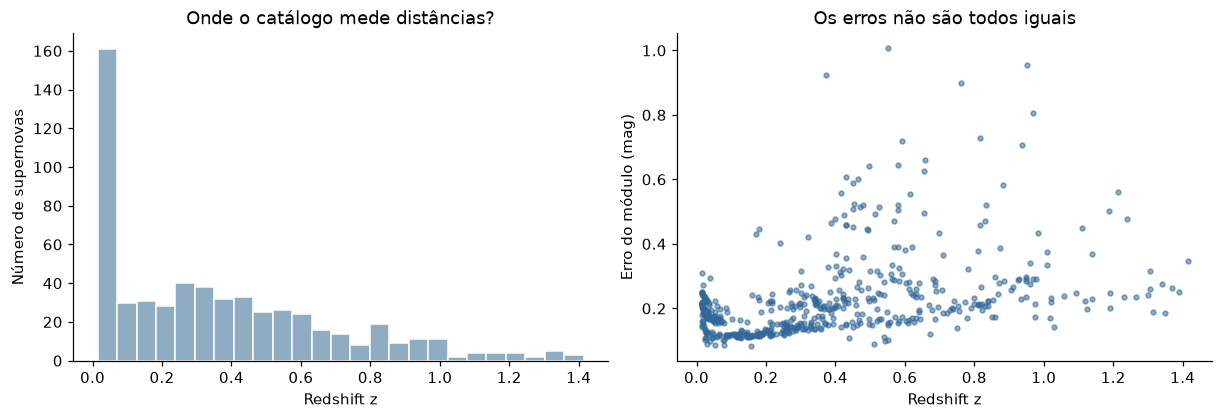

In [48]:
provenance5=json.loads((DATA5/'provenance.json').read_text())  # Lê a identificação das cópias observacionais.
for record in provenance5:
    actual=hashlib.sha256((DATA5/record['file']).read_bytes()).hexdigest()  # Calcula o hash dos bytes locais.
    assert actual==record['sha256'],f"Arquivo alterado: {record['file']}"  # Evita uma mudança silenciosa do conjunto de dados.
catalogo5=sn.load_union21(DATA5/'SCPUnion2.1_mu_vs_z.txt')  # Lê as cinco colunas sem ordenar as linhas.
z5,dados5,sigma5=catalogo5['z'],catalogo5['modulus'],catalogo5['sigma']  # Identifica redshift, dado e erro da nossa notação.
Cstat5=np.loadtxt(DATA5/'SCPUnion2.1_covmat_nosys.txt')  # Carrega a matriz estatística oficial apenas para conferência.
Csys5=np.loadtxt(DATA5/'SCPUnion2.1_covmat_sys.txt')  # Carrega a covariância que já inclui sistemáticas e estatística.
assert np.max(abs(Cstat5-np.diag(sigma5**2)))<2e-12  # Confirma a equivalência da rota diagonal neste catálogo.
assert Csys5.shape==(580,580) and np.allclose(Csys5,Csys5.T)  # Confere a forma e a simetria antes de fatorar.
tabela5('01_catalogo',pd.DataFrame([{'Número de SNe':len(z5),'z mínimo':z5.min(),'z máximo':z5.max(),
    'Erro mediano (mag)':np.median(sigma5),'Erro mínimo (mag)':sigma5.min(),'Erro máximo (mag)':sigma5.max()}]))
fig,axs=plt.subplots(1,2,figsize=(11,3.7),layout='constrained')  # Separa distribuição de redshifts e tamanho dos erros.
axs[0].hist(z5,bins=25,color='#8fadc2',edgecolor='white')  # Mostra a amostragem observacional sem usá-la como prior cosmológica.
axs[0].set(xlabel='Redshift z',ylabel='Número de supernovas',title='Onde o catálogo mede distâncias?')
axs[1].scatter(z5,sigma5,s=10,alpha=.55,color='#316799')  # Mantém cada supernova como um ponto com seu próprio erro.
axs[1].set(xlabel='Redshift z',ylabel='Erro do módulo (mag)',title='Os erros não são todos iguais')
figura5('01_catalogo_e_erros',fig)


## 5.3. Da cosmologia à previsão $\mu_i(\theta)$

Vamos explicitar as hipóteses: universo homogêneo e isotrópico, geometria espacial plana, matéria sem pressão e energia escura com $w=p_{\rm DE}/\rho_{\rm DE}$ constante, em unidades nas quais $c=1$ nessa razão. Desprezaremos radiação e evolução de $w$ no intervalo do catálogo. Na parametrização CPL do artigo, isso corresponde a fixar $w_a=0$ e identificar $w=w_0$.

A conservação de um fluido com $w$ constante dá $\rho\propto a^{-3(1+w)}$. Para matéria, $w_m=0$; para uma constante cosmológica, $w=-1$ e a densidade não varia. A equação de Friedmann fica

$$
E(z;\theta)^2\equiv\frac{H(z;\theta)^2}{H_0^2}
=\Omega_m(1+z)^3+(1-\Omega_m)(1+z)^{3(1+w)},\qquad \theta=(\Omega_m,w).
$$

$\Omega_m$ é a fração atual de densidade de matéria em relação à densidade crítica. A planura fixa $\Omega_{\rm DE}=1-\Omega_m$. Integrando a propagação da luz, obtemos

$$
D_C=\frac{c}{H_0}\int_0^z\frac{du}{E(u;\theta)},\qquad
d_L=(1+z)D_C,\qquad
\widehat d_L\equiv\frac{H_0d_L}{c}=(1+z)\int_0^z\frac{du}{E(u;\theta)}.
$$

Assim, a previsão que entra no vetor dos blocos anteriores será

$$
\mu_i(\theta)=5\log_{10}\widehat d_L(z_i;\theta),\qquad
d_i=\mu_i(\theta)+\mathcal A+\varepsilon_i,\qquad
\varepsilon\sim\mathcal N(0,C).
$$

Para módulos com calibração absoluta conhecida, $\mathcal A=25+5\log_{10}[(c/H_0)/\mathrm{Mpc}]$. Aqui deixaremos esse deslocamento livre: a calibração da luminosidade e a escala $H_0$ entram de forma degenerada. Depois de marginalizá-lo, as supernovas medem a **forma relativa da relação distância–redshift**, sem fornecer uma medida independente de $H_0$ nesta análise.

A integral será calculada por Gauss–Legendre em cada intervalo $[0,z_i]$. A mudança $u=z_i(t+1)/2$ traz o peso $z_i/2$, implementado em `FlatWCDM`. Conferiremos a quadratura contra uma integração adaptativa e contra um caso analítico só de matéria. As fórmulas de distância seguem também [Hogg (1999/2000)](https://arxiv.org/abs/astro-ph/9905116).


## 5.4. Por que a calibração pode ser integrada analiticamente?

Com $r=d-\mu(\theta)$ e $\mathbf1$ o vetor de uns,

$$
-2\log\mathcal L(\theta,\mathcal A)
=(r-\mathcal A\mathbf1)^TC^{-1}(r-\mathcal A\mathbf1)+\text{constante}.
$$

Definindo $S_0=\mathbf1^TC^{-1}\mathbf1$, $S_1=\mathbf1^TC^{-1}r$ e $S_2=r^TC^{-1}r$, completamos o quadrado:

$$
S_2-2\mathcal A S_1+\mathcal A^2S_0
=S_0\left(\mathcal A-\frac{S_1}{S_0}\right)^2
+S_2-\frac{S_1^2}{S_0}.
$$

Integrar $\mathcal A$ com uma prior constante dá um fator $\sqrt{2\pi/S_0}$ independente de $\theta$, pois $C$ é fixa. Portanto,

$$
\widehat{\mathcal A}(\theta)=\frac{S_1}{S_0},\qquad
\chi^2_{\rm marg}(\theta)=S_2-\frac{S_1^2}{S_0},\qquad
\mathcal L_{\rm marg}(\theta)\propto e^{-\chi^2_{\rm marg}/2}.
$$

O perfil e a marginalização têm aqui a mesma **dependência nos parâmetros cosmológicos**; isso ocorre pela linearidade do offset e pela covariância fixa. Não é uma regra para parâmetros de nuisance em geral. A prior constante de $\mathcal A$ é imprópria: a posterior cosmológica pode ser normalizada, mas não usaremos sua normalização como evidência absoluta de modelos.

Em forma matricial, a precisão projetada é

$$
M_\perp=C^{-1}-\frac{C^{-1}\mathbf1\mathbf1^TC^{-1}}{S_0},
\qquad M_\perp\mathbf1=0.
$$

Ela é semidefinida positiva e tem posto $N-1$. **Não podemos passá-la como se fosse uma covariância definida positiva para `prepare_dali`.** O código primeiro aplica $C^{-1/2}$, depois faz uma reflexão ortogonal para alinhar a direção do offset com um eixo e remove esse eixo. Chamaremos a transformação resultante de $P$:

$$
\widetilde d=Pd,\quad\widetilde\mu=P\mu,\quad
\chi^2_{\rm marg}=\|\widetilde d-\widetilde\mu\|^2.
$$

Restam 579 componentes e métrica identidade. A mesma transformação linear será aplicada a todas as derivadas. Não retiramos informação sobre a forma da curva; retiramos a direção que uma mudança de calibração consegue absorver.


In [49]:
modelo5=sn.FlatWCDM(z5,quadrature_order=48)  # Escolhe a precisão da quadratura; será conferida com 96 nós.
projecao5=sn.CalibrationProjection(sigma5**2)  # Marginaliza a calibração usando a covariância estatística diagonal.
ajuste5=sn.fit_supernovae(modelo5,projecao5,dados5,BOUNDS5)  # Ajusta a cosmologia observacional após retirar o offset.
theta_hat5=ajuste5.x  # Guarda o MAP conjunto, pois a prior será uniforme dentro dos limites escolhidos.
mu_hat5=modelo5.predict(theta_hat5)  # Calcula a curva teórica nos redshifts observados.
A_hat5=float(projecao5.offset(dados5-mu_hat5))  # Recupera o deslocamento de calibração apenas para desenhar e interpretar os dados.
residuo5=projecao5.project(dados5-mu_hat5)  # Preserva os resíduos observados; eles não são zero no melhor ajuste.
chi2_hat5=float(residuo5@residuo5)  # Calcula a discrepância mínima na mesma métrica usada na likelihood.
theta_fid5=np.array([.285,-1.])  # Define a cosmologia fiducial do experimento de previsão, como no catálogo futuro do artigo.
dados_fid5=modelo5.predict(theta_fid5)+A_hat5  # Usa a média prevista nos mesmos redshifts e com os mesmos erros, sem sortear ruído.
assert np.linalg.norm(projecao5.project(np.ones(len(z5))))<1e-10  # Confere que uma translação comum é inteiramente absorvida.
tabela5('02_centro_e_calibracao',pd.DataFrame([
    {'Caso':'Dados observados','Omega_m':theta_hat5[0],'w':theta_hat5[1],'A para desenho':A_hat5,'chi² no centro':chi2_hat5},
    {'Caso':'Fiducial sem realização de ruído','Omega_m':theta_fid5[0],'w':theta_fid5[1],'A para desenho':A_hat5,'chi² no centro':0.}]))
print('Componentes após a projeção:',residuo5.size,'| número de parâmetros cosmológicos:',len(theta_hat5))


,Caso,Omega_m,w,A para desenho,chi² no centro
0,Dados observados,0.281166,-1.009897,43.158043,562.22421
1,Fiducial sem realização de ruído,0.285000,-1.000000,43.158043,0.00000


Componentes após a projeção: 579 | número de parâmetros cosmológicos: 2


O melhor ajuste estatístico está próximo de $(\Omega_m,w)=(0.2812,-1.0099)$, com $\chi^2\simeq562.22$ e $\widehat{\mathcal A}\simeq43.158$. Esses números descrevem o catálogo e as hipóteses declaradas; não constituem uma reprodução de todas as calibrações e análises cosmológicas do lançamento oficial.

Vamos separar três objetos que podem parecer iguais:

| Objeto | O que foi escolhido ou medido? | Há realização de ruído? |
|---|---|---|
| $d_i$ observados | Módulos publicados pela equipe Union2.1. | Contêm os resíduos dos dados reais. |
| $\mu_i(\widehat\theta)+\widehat{\mathcal A}$ | Curva ajustada aos dados observados. | É uma previsão do modelo; não substitui os dados. |
| $d_i^{\rm fid}=\mu_i(\theta_{\rm fid})+\mathcal A$ | Média de um experimento hipotético, usando $z_i,C$ do catálogo. | Não; o resíduo no fiducial é zero após a projeção. |

O experimento fiducial usa $(0.285,-1)$, mas não simula o catálogo futuro de 1000 objetos do artigo. Aqui conservamos a seleção de redshifts e os erros do Union2.1 para isolar o efeito de ter ou não um resíduo observado. Uma realização simulada exigiria sortear $L\xi$, com $\xi\sim\mathcal N(0,I)$ e $LL^T=C$; não faremos esse sorteio neste bloco.

Antes dos contornos, vamos olhar as curvas. Mais matéria e um $w$ diferente mudam $E(z)$ e, por consequência, a integral da distância. Depois de permitir um deslocamento comum, algumas diferenças diminuem bastante. É essa compensação entre mudanças de forma que esperamos encontrar na posterior.


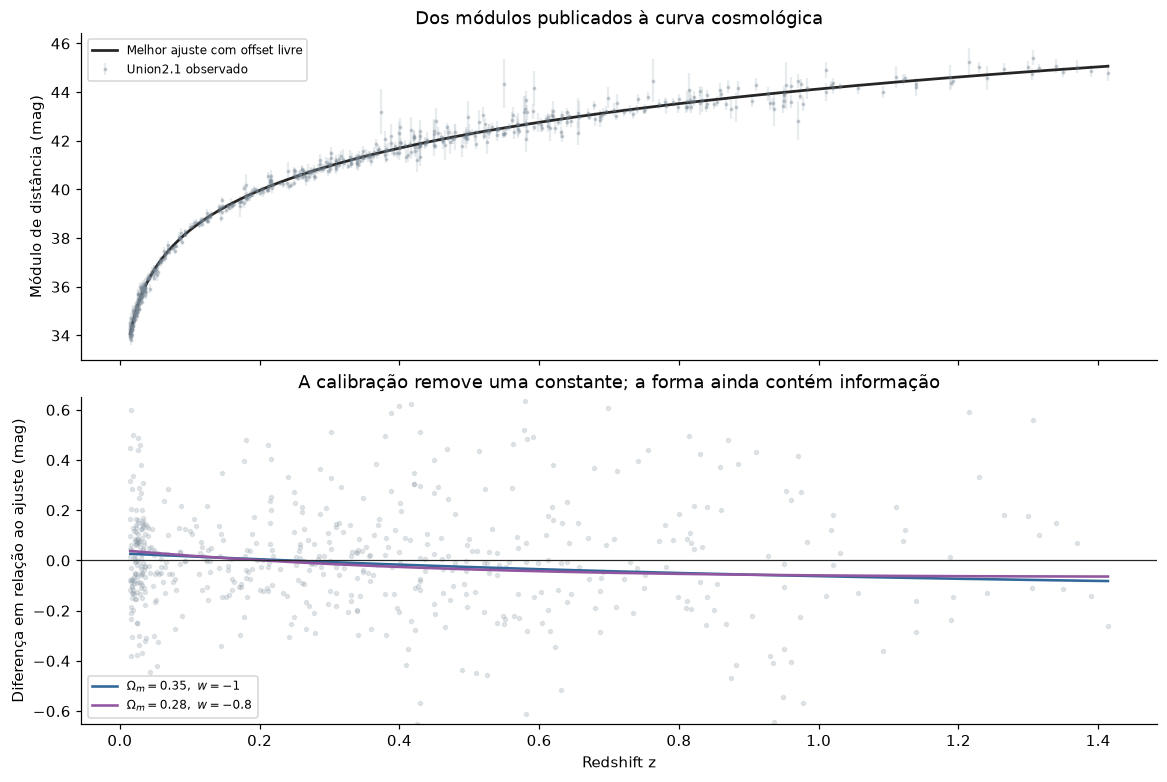

In [50]:
z_desenho5=np.linspace(z5.min(),z5.max(),400)  # Cria uma curva suave somente para a figura.
modelo_desenho5=sn.FlatWCDM(z_desenho5,48)  # Usa a mesma cosmologia com os redshifts da visualização.
curva_hat5=modelo_desenho5.predict(theta_hat5)+A_hat5  # Desenha a previsão ajustada com a calibração recuperada.
fig,axs=plt.subplots(2,1,figsize=(10.5,7),sharex=True,layout='constrained')  # Separa módulos e diferenças de forma.
axs[0].errorbar(z5,dados5,yerr=sigma5,fmt='.',ms=3,alpha=.32,color='#788895',ecolor='#bcc5cc',label='Union2.1 observado')  # Mostra os erros dos dados, não barras de erro em parâmetros.
axs[0].plot(z_desenho5,curva_hat5,color=COR5['Exata'],lw=1.8,label='Melhor ajuste com offset livre')
axs[0].set(ylabel='Módulo de distância (mag)',title='Dos módulos publicados à curva cosmológica')
axs[0].legend(fontsize=8)
axs[1].scatter(z5,dados5-mu_hat5-A_hat5,s=7,alpha=.22,color='#8998a3')  # Mostra o resíduo em magnitudes, antes da ponderação pelos erros.
for theta,cor,rotulo in [(np.array([.35,-1.]),'#316799',r'$\Omega_m=0.35,\ w=-1$'),
                        (np.array([.28,-.8]),'#91569f',r'$\Omega_m=0.28,\ w=-0.8$')]:
    offset=float(projecao5.offset(dados5-modelo5.predict(theta)))  # Permite que cada hipótese reajuste a mesma nuisance.
    diferenca=modelo_desenho5.predict(theta)+offset-curva_hat5  # Isola mudanças que um deslocamento comum não eliminou.
    axs[1].plot(z_desenho5,diferenca,color=cor,lw=1.7,label=rotulo)
axs[1].axhline(0,color=COR5['Exata'],lw=.8)  # Marca a curva de referência do melhor ajuste.
axs[1].set(xlabel='Redshift z',ylabel='Diferença em relação ao ajuste (mag)',ylim=(-.65,.65),title='A calibração remove uma constante; a forma ainda contém informação')
axs[1].legend(fontsize=8)
figura5('02_diagrama_de_hubble',fig)


## 5.5. Derivadas, Fisher e o resíduo que não desaparece

Agora o modelo não termina num polinômio quadrático como na Lista 3. A integral de $1/E$ e o logaritmo geram derivadas de ordens superiores. Vamos calculá-las no mesmo ponto $\widehat\theta$, aplicar $P$ e usar a hierarquia já construída:

$$
E_K(\theta)=\frac12\left\|\widetilde r_0-
\sum_{k=1}^{K}\frac1{k!}\widetilde\mu_{,\alpha_1\cdots\alpha_k}
\Delta_{\alpha_1}\cdots\Delta_{\alpha_k}\right\|^2,
\qquad p_K\propto e^{-E_K}\pi(\theta).
$$

O módulo `supernovas.py` usa **aritmética de séries truncadas**: expande $E^2$, usa a série binomial para a raiz inversa, integra os coeficientes e expande o logaritmo. Isso aplica a regra da cadeia sem subtrair números quase iguais numa quarta diferença finita. Os coeficientes internos têm fatoriais; os tensores retornados são derivadas brutas, como em `prepare_dali`. Conferiremos a ordem do resto de Taylor, primeiras e segundas derivadas por diferenças finitas e a estabilidade com mais nós.

No melhor ajuste, $\widetilde J^T\widetilde r_0\simeq0$. Assim, o singleto é a gaussiana de informação **esperada**, $F=\widetilde J^T\widetilde J$, com o suporte físico preservado. A Hessiana observada é

$$
H_{\rm obs}=F-\sum_i\widetilde r_{0,i}\widetilde\mu_{i,\alpha\beta}.
$$

Os resíduos não precisam ser zero para que seu produto com $J$ desapareça. Nos dados observados, descartar $\widetilde r_0$ elimina uma informação que o dubleto e as ordens seguintes conservam. No experimento fiducial sem ruído, $\widetilde r_0=0$ e $H_{\rm obs}=F$.

Há ainda uma simplificação computacional exata: todas as avaliações de DALI combinam as mesmas colunas de derivadas e o mesmo resíduo. Uma fatoração QR preserva a norma dessas combinações. Em dois parâmetros até a quarta ordem, são 14 monômios não constantes e o resíduo: podemos avaliar a mesma expansão com uma matriz de até 15 linhas, em vez de percorrer as 579 componentes projetadas. **Isso não é um novo truncamento**, e seu acordo será conferido diretamente.


In [51]:
inicio_preparo5=time.perf_counter()  # Separa o preparo das avaliações posteriores.
derivadas5=modelo5.derivatives(theta_hat5,order=4,chart='physical')  # Calcula J,H,T,U nos parâmetros usuais.
derivadas_proj5=projecao5.derivative_tensors(derivadas5)  # Retira a calibração das derivadas pela mesma transformação dos dados.
expansao5=dali.prepare_dali(theta_hat5,derivadas_proj5,np.eye(len(z5)-1),residual=residuo5)  # Conserva o resíduo observado e a métrica identidade.
rapida5=dali.compress_dali(expansao5)  # Preserva a mesma norma com menos componentes.
tempo_preparo5=time.perf_counter()-inicio_preparo5  # Registra o custo local, incluindo derivadas e fatorações.
J5,H5=derivadas_proj5[:2]  # Identifica primeira e segunda derivadas após marginalizar o offset.
F5=J5.T@J5  # Calcula a informação esperada do modelo projetado.
Hobs5=F5-np.einsum('i,iab->ab',residuo5,H5)  # Acrescenta a contribuição observada dos resíduos.
SigmaF5=np.linalg.solve(F5,np.eye(2))  # Obtém a covariância gaussiana sem formar a inversa dos dados.
assert np.linalg.norm(J5.T@residuo5)<2e-4  # Confere que estamos suficientemente perto de um ponto estacionário.
assert np.linalg.eigvalsh(Hobs5).min()>0  # Confere a existência da gaussiana de Laplace observada.
pontos_auditoria5=theta_hat5+np.random.default_rng(SEMENTE).normal(size=(80,2))*[.1,.4]  # Testa também pontos afastados do centro.
for ordem in (1,2,3,4):
    assert np.allclose(expansao5.exponent(pontos_auditoria5,ordem),rapida5.exponent(pontos_auditoria5,ordem),rtol=2e-13,atol=2e-10)  # Confere a compressão com resíduo e produtos mistos.
tabela5('03_curvaturas',pd.DataFrame([{'Matriz':nome,'OmegaOmega':matriz[0,0],'Omegaw':matriz[0,1],'ww':matriz[1,1],
    'Menor autovalor':np.linalg.eigvalsh(matriz).min()} for nome,matriz in [('F esperado',F5),('H observado',Hobs5)]]))
print('Preparo completo (s):',round(tempo_preparo5,3),'| dimensão do quadrado comprimido:',rapida5.factor.shape)


,Matriz,OmegaOmega,Omegaw,ww,Menor autovalor
0,F esperado,2658.231414,944.917802,360.829431,22.122065
1,H observado,2658.362115,945.213032,360.627521,21.770468


Preparo completo (s): 0.03 | dimensão do quadrado comprimido: (15, 15)


## 5.6. Construindo a posterior de referência

Adotaremos priors independentes uniformes em $0.005\leq\Omega_m\leq0.995$ e $-4.5\leq w\leq-0.2$. São escolhas deste experimento, não restrições externas da cosmologia. O intervalo de matéria evita os extremos sem um dos componentes e permite investigar coordenadas logarítmicas. Conferiremos a referência também com limites mais amplos.

Dentro desse retângulo,

$$
q(\theta)=\exp[-\chi^2_{\rm marg}(\theta)/2],\qquad
p(\theta\mid d)=\frac{q(\theta)}{\int q(\theta)\,d\Omega_m\,dw}.
$$

A constante da prior uniforme cancela nessa posterior. Toda comparação terá a mesma prior e a mesma medida física. A referência usa a integral cosmológica completa em cada ponto; DALI usa apenas as derivadas centrais. Ambas ainda precisam de integração em parâmetros para normalizar e marginalizar.

Usaremos 281 nós em $\Omega_m$ e 401 em $w$. A avaliação por lotes limita a memória; os pesos de Simpson entram na integração. A figura pode mostrar uma região menor para facilitar a leitura, mas as probabilidades serão calculadas no retângulo inteiro. Não vamos julgar a precisão apenas pela região ampliada no desenho.


In [52]:
axes5=(np.linspace(*BOUNDS5[0],281),np.linspace(*BOUNDS5[1],401))  # Escolhe números ímpares de nós para Simpson.
xx5,ww5=np.meshgrid(*axes5)  # Mantém w nas linhas e Omega_m nas colunas, como nos blocos anteriores.
pontos5=np.stack((xx5,ww5),axis=-1)  # Organiza cada ponto na ordem dos parâmetros.
inicio_grid5=time.perf_counter()  # Mede a construção da referência separadamente do preparo de DALI.
logref5=sn.loglike_grid(modelo5,projecao5,dados5,pontos5,batch_size=128)  # Avalia a likelihood observada sem Taylor cosmológica.
ref5,logI5=dali.normalize_log_grid(logref5,*axes5)  # Normaliza no retângulo da prior física.
tempo_grid5=time.perf_counter()-inicio_grid5  # Registra o custo desta referência, sem tratá-lo como benchmark universal.
pdfs5={'Exata':ref5}  # Guarda a mesma referência para todas as comparações.
logs5={'Exata':logref5}  # Mantém também a log-densidade para conferir regiões remotas.
for ordem,nome in enumerate(('D1 / Fisher','D2','D3','D4'),start=1):
    logs5[nome]=-rapida5.exponent(pontos5,ordem)  # Usa o quadrado completo da ordem escolhida.
    pdfs5[nome],_=dali.normalize_log_grid(logs5[nome],*axes5)  # Normaliza cada aproximação na mesma prior.
media_ref5,cov_ref5=dali.grid_moments_2d(ref5,*axes5)  # Distingue média posterior do ponto de maior densidade.
print('Referência em malha (s):',round(tempo_grid5,3),'| média posterior:',media_ref5)


Referência em malha (s): 46.587 | média posterior: [ 0.27480286 -1.02923608]


## 5.7. O que cada ordem consegue recuperar?

Fisicamente, esperamos uma anticorrelação entre os dois parâmetros na região favorecida: aumentar a matéria pode ser compensado por tornar $w$ mais negativo. Como a compensação não é linear em todo o intervalo, uma elipse local deve perder parte da forma. O dubleto e o tripleto podem curvar essa região, mas não há uma garantia de melhora monotônica com a ordem.

Cada painel comparará a referência com **uma** aproximação. As linhas contínuas e tracejadas encerram 68,27% e 95,45% da probabilidade de cada densidade. Vamos medir também a variação total,

$$
\mathrm{TV}(p,p_K)=\frac12\int|p-p_K|\,d\Omega_m\,dw,
$$

e a massa da referência contida nas regiões HPD propostas por cada método. Se uma região que contém 95,45% sob a aproximação contiver muito menos sob a referência, sua interpretação probabilística está alterada. O recorte em células usado para esse diagnóstico tem um erro de discretização maior que o dos momentos suaves; ele não substitui a conferência de resolução.


,Método,TV conjunta,Média Omega_m,Média w,Desvio Omega_m,Desvio w,Massa ref. na HPD 68.27%,Massa ref. na HPD 95.45%
0,Exata,0.000000,0.274803,-1.029236,0.076510,0.203065,0.682742,0.954634
1,D1 / Fisher,0.235292,0.281194,-1.009969,0.073722,0.200106,0.626631,0.854630
2,D2,0.081570,0.276203,-1.022144,0.063799,0.174104,0.626229,0.909410
3,D3,0.015082,0.279599,-1.042574,0.074547,0.209657,0.683364,0.956420
4,D4,0.047640,0.287707,-1.088040,0.095021,0.331484,0.718664,0.974810


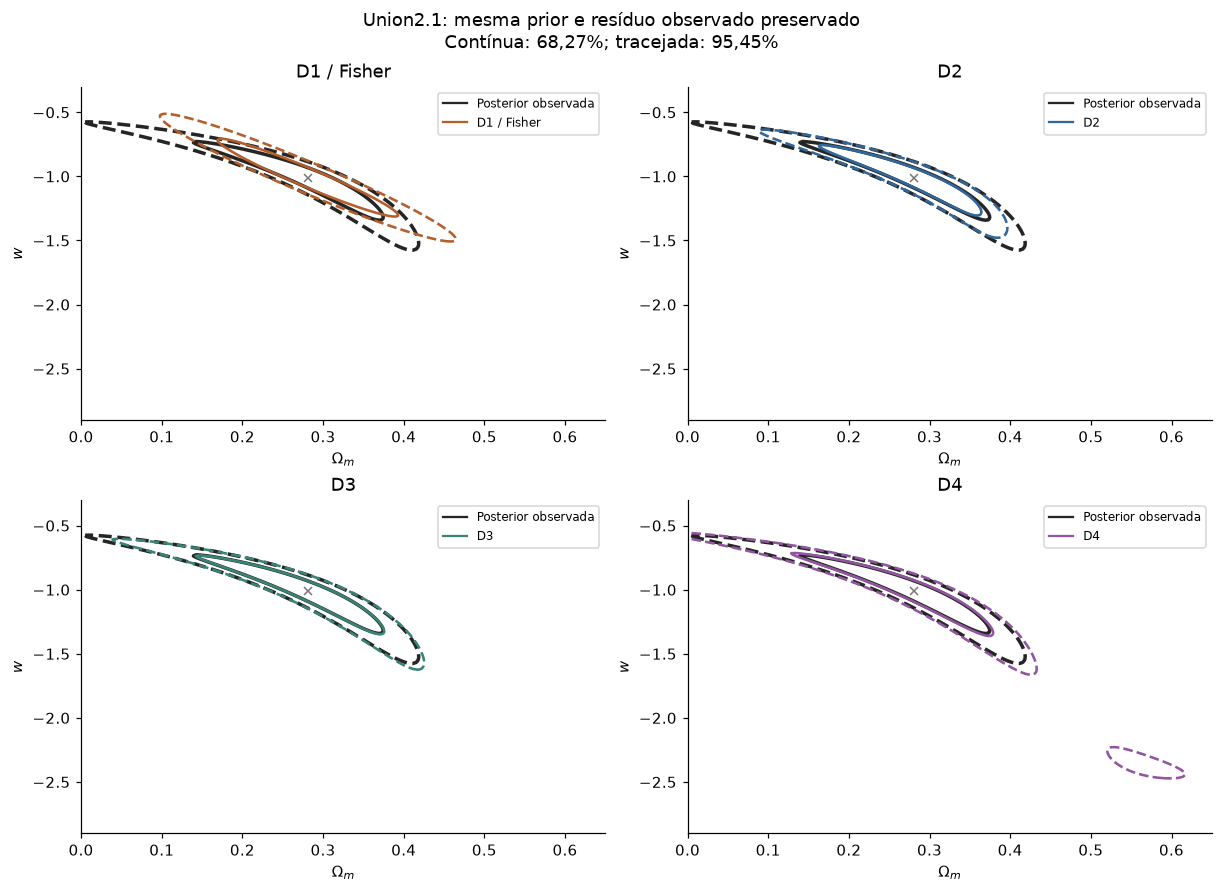

In [54]:
linhas_metricas5=[]  # Reúne erros globais, momentos e conteúdo probabilístico das regiões.
marginais5={}  # Guarda p(Omega_m) e p(w) depois de integrar o outro parâmetro.
for nome,pdf in pdfs5.items():
    marginais5[nome]=(simpson(pdf,x=axes5[1],axis=0),simpson(pdf,x=axes5[0],axis=1))  # Usa coordenadas físicas em ambas as integrações.
    media,cov=dali.grid_moments_2d(pdf,*axes5)  # Calcula momentos da distribuição inteira.
    levels=dali.hpd_thresholds_2d(pdf,*axes5,PROBS5)  # Encontra limiares por conteúdo de probabilidade.
    coberturas=[dali.integrate_grid_2d(ref5*(pdf>=level),*axes5) for level in levels]  # Mede a massa verdadeira dentro das regiões da aproximação.
    linhas_metricas5.append({'Método':nome,'TV conjunta':.5*dali.integrate_grid_2d(abs(pdf-ref5),*axes5),
        'Média Omega_m':media[0],'Média w':media[1],'Desvio Omega_m':np.sqrt(cov[0,0]),'Desvio w':np.sqrt(cov[1,1]),
        'Massa ref. na HPD 68.27%':coberturas[0],'Massa ref. na HPD 95.45%':coberturas[1]})
tabela5('04_comparacao_observada',pd.DataFrame(linhas_metricas5))  # Não reduz a comparação à aparência do contorno.
fig,axs=plt.subplots(2,2,figsize=(11,8),layout='constrained')  # Usa uma aproximação em cada painel.
for ax,nome in zip(axs.flat,('D1 / Fisher','D2','D3','D4')):
    contornos5(ax,ref5,axes5,COR5['Exata'],lw=2.3)  # Mantém a referência identificável em todos os painéis.
    contornos5(ax,pdfs5[nome],axes5,COR5[nome])  # Acrescenta somente a ordem nomeada.
    ax.plot(*theta_hat5,'x',color='#777777',ms=5)  # Marca o ponto comum da expansão.
    plano5(ax)  # Não muda as escalas entre as ordens.
    ax.set_title(nome)
    ax.legend(handles=[Line2D([0],[0],color=COR5['Exata'],label='Posterior observada'),Line2D([0],[0],color=COR5[nome],label=nome)],fontsize=8)
fig.suptitle('Union2.1: mesma prior e resíduo observado preservado\nContínua: 68,27%; tracejada: 95,45%',fontsize=12)
figura5('03_contornos_por_ordem',fig)


,Método,Parâmetro,TV marginal,Assimetria,Excesso de curtose
0,D1 / Fisher,Omega_m,0.080750,0.004829,-0.015255
1,D1 / Fisher,w,0.033737,-0.004420,-0.013575
2,D2,Omega_m,0.075714,-0.533010,-0.007734
3,D2,w,0.063772,-0.226984,-0.243710
4,D3,Omega_m,0.015059,-0.486821,0.162340
5,D3,w,0.015075,-0.624314,0.778464
6,D4,Omega_m,0.047347,0.471579,1.677841
7,D4,w,0.047032,-2.177541,6.088141


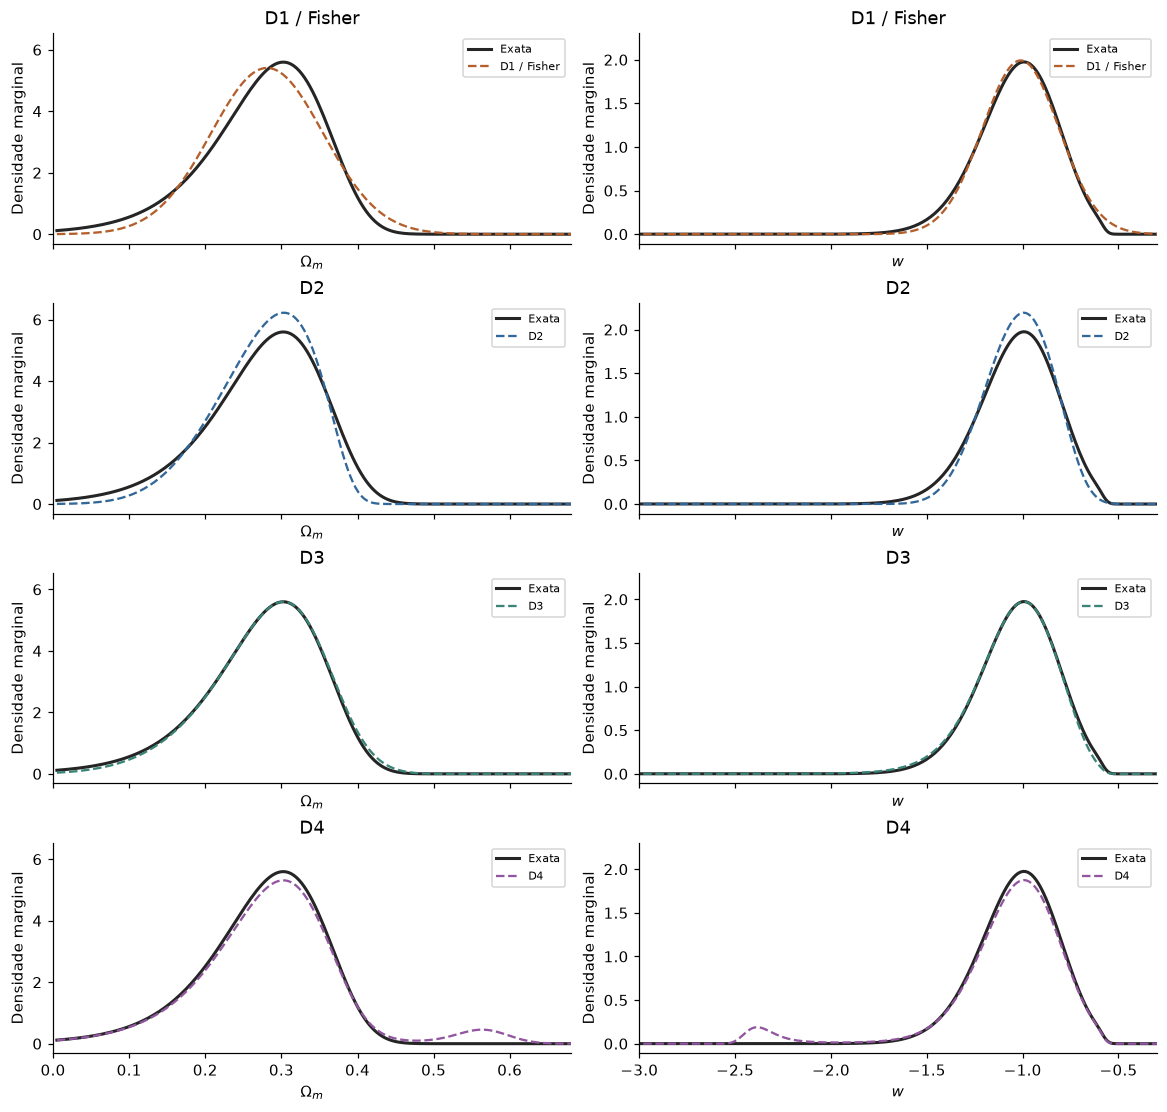

In [55]:
linhas_marginais5=[]  # Examina se um bom plano conjunto também produz boas projeções unidimensionais.
fig,axs=plt.subplots(4,2,figsize=(10.5,10),sharex='col',sharey='col',layout='constrained')
for linha,nome in enumerate(('D1 / Fisher','D2','D3','D4')):
    for i in (0,1):
        ax=axs[linha,i]  # Seleciona a ordem e o parâmetro do painel.
        ax.plot(axes5[i],marginais5['Exata'][i],color=COR5['Exata'],lw=2,label='Exata')  # Mantém a mesma marginal de referência.
        ax.plot(axes5[i],marginais5[nome][i],color=COR5[nome],ls='--',label=nome)  # Evita sobrepor quatro ordens de uma vez.
        ax.set(xlabel=NOMES5[i],ylabel='Densidade marginal',title=nome,xlim=((0,.68) if i==0 else (-3.,-.3)))
        ax.legend(fontsize=7.5)
        stats=dali.density_moments_1d(marginais5[nome][i],axes5[i])  # Mede assimetria e curtose sem associá-las a uma ordem específica de DALI.
        linhas_marginais5.append({'Método':nome,'Parâmetro':('Omega_m','w')[i],
            'TV marginal':.5*simpson(abs(marginais5[nome][i]-marginais5['Exata'][i]),x=axes5[i]),
            'Assimetria':stats['skewness'],'Excesso de curtose':stats['excess_kurtosis']})
tabela5('05_marginais_observadas',pd.DataFrame(linhas_marginais5))
figura5('04_marginais_por_ordem',fig)


A região favorecida se curva, como esperávamos da compensação entre matéria e energia escura. A média posterior não coincide exatamente com o MAP, pois integrar leva em conta o volume disponível ao longo dessa curva. Fisher resume a inclinação e a largura locais, mas não conserva a relação completa entre elas longe do centro.

Nas escolhas deste bloco, a TV conjunta cai de cerca de 0.235 no singleto para 0.082 no dubleto e 0.015 no tripleto. A quarta ordem volta a aproximadamente 0.048. Sua região central pode parecer boa e, ainda assim, ela acrescenta massa numa região remota. Vamos localizar esse máximo adicional e testá-lo contra a likelihood completa, em vez de atribuí-lo automaticamente a ruído da figura.

As marginais deixam visível uma consequência do máximo remoto: uma estrutura pequena no plano conjunto pode alterar caudas e probabilidades integradas. A ideia da Lista 3 continua válida — precisamos olhar formas, momentos e pesos — mas agora não existe um fechamento algébrico em D2 que garanta a resposta em todo o domínio.


## 5.8. O experimento fiducial e a diferença em relação aos dados observados

Vamos usar os mesmos redshifts, a mesma covariância e as mesmas priors, trocando apenas o vetor de dados por sua média na cosmologia fiducial. Essa construção permite testar a geometria esperada da likelihood sem atribuir uma realização particular de resíduos à previsão.

Uma posterior fiducial pode ser não gaussiana: igualar os dados à média no centro não lineariza a relação cosmológica em todo o espaço. O que desaparece é o resíduo central, não as segundas, terceiras e quartas derivadas. Por isso, esperamos que o singleto seja a gaussiana local correta e, mesmo assim, que as ordens seguintes possam modificar sua forma global.

Também faremos um controle deliberadamente incompleto: usar resíduo zero em D3 no centro do ajuste **observado**. Isso nos permite medir o efeito de abandonar o termo com resíduo, em vez de confundir essa escolha com a diferença entre duas ordens.


,Experimento,Método,TV contra sua referência
0,Fiducial sem ruído,D1 / Fisher,0.239776
1,Fiducial sem ruído,D2,0.083160
2,Fiducial sem ruído,D3,0.015473
3,Fiducial sem ruído,D4,0.114641
4,"Observado, resíduo preservado",D3,0.015082
5,"Observado, resíduo zerado",D3,0.017347


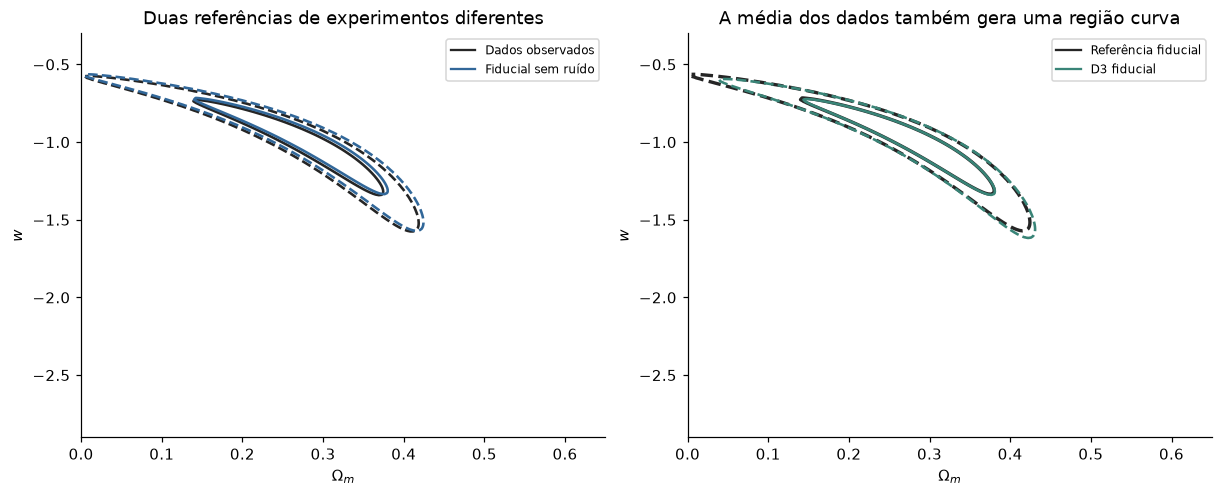

In [56]:
def preparar5(center,data,chart='physical',projection=projecao5):
    """Aplica a mesma expansão a outro centro, vetor de dados ou covariância."""
    derivatives=projection.derivative_tensors(modelo5.derivatives(center,4,chart))  # Calcula e projeta as derivadas na coordenada escolhida.
    residual=projection.project(data-modelo5.predict(center))  # Conserva o resíduo adequado a esse experimento.
    expansion=dali.prepare_dali(sn.coordinates(center,chart),derivatives,np.eye(len(z5)-1),residual=residual)  # Mantém a métrica identidade no espaço projetado.
    return dali.compress_dali(expansion)

logfid5=sn.loglike_grid(modelo5,projecao5,dados_fid5,pontos5)  # Constrói a referência do experimento sem realização de ruído.
ref_fid5,_=dali.normalize_log_grid(logfid5,*axes5)  # Usa a mesma prior física do caso observado.
rapida_fid5=preparar5(theta_fid5,dados_fid5)  # Seu resíduo central é nulo, a menos de arredondamento.
linhas_fid5=[]  # Registra o efeito da ordem no experimento fiducial.
pdfs_fid5={}
for ordem,nome in enumerate(('D1 / Fisher','D2','D3','D4'),start=1):
    pdfs_fid5[nome],_=dali.normalize_log_grid(-rapida_fid5.exponent(pontos5,ordem),*axes5)  # Reconstrói cada ordem sem resíduos sorteados.
    linhas_fid5.append({'Experimento':'Fiducial sem ruído','Método':nome,'TV contra sua referência':.5*dali.integrate_grid_2d(abs(pdfs_fid5[nome]-ref_fid5),*axes5)})
sem_residuo5=dali.compress_dali(dali.prepare_dali(theta_hat5,derivadas_proj5,np.eye(len(z5)-1)))  # Cria somente o controle que abandona o resíduo dos dados reais.
pdf_sem_residuo5,_=dali.normalize_log_grid(-sem_residuo5.exponent(pontos5,3),*axes5)  # Não confunde esse controle com o forecast de centro diferente.
linhas_fid5.append({'Experimento':'Observado, resíduo preservado','Método':'D3','TV contra sua referência':linhas_metricas5[3]['TV conjunta']})
linhas_fid5.append({'Experimento':'Observado, resíduo zerado','Método':'D3','TV contra sua referência':.5*dali.integrate_grid_2d(abs(pdf_sem_residuo5-ref5),*axes5)})
tabela5('06_fiducial_e_residuo',pd.DataFrame(linhas_fid5))  # Separa diferença de dados, centro e tratamento do resíduo.
fig,axs=plt.subplots(1,2,figsize=(11,4.4),layout='constrained')
contornos5(axs[0],ref5,axes5,COR5['Exata'])  # Mostra a posterior dos dados observados.
contornos5(axs[0],ref_fid5,axes5,'#316799')  # Mostra a referência do experimento fiducial, sem chamar sua curva de dado observado.
axs[0].legend(handles=[Line2D([0],[0],color=COR5['Exata'],label='Dados observados'),Line2D([0],[0],color='#316799',label='Fiducial sem ruído')],fontsize=8)
axs[0].set_title('Duas referências de experimentos diferentes')
contornos5(axs[1],ref_fid5,axes5,COR5['Exata'],lw=2.2)  # Mantém a referência correta para avaliar a previsão.
contornos5(axs[1],pdfs_fid5['D3'],axes5,COR5['D3'])  # Usa apenas D3 para não empilhar as quatro curvas.
axs[1].legend(handles=[Line2D([0],[0],color=COR5['Exata'],label='Referência fiducial'),Line2D([0],[0],color=COR5['D3'],label='D3 fiducial')],fontsize=8)
axs[1].set_title('A média dos dados também gera uma região curva')
for ax in axs:
    plano5(ax)
figura5('05_observado_e_fiducial',fig)


As duas referências têm formas parecidas porque os centros estão próximos, mas respondem a vetores de dados diferentes. A tabela compara cada aproximação com a referência do seu próprio experimento. O caso sem resíduo no centro observado também não deve ser confundido com o fiducial escolhido: ele usa outro centro e substitui o problema local dos dados reais por uma previsão com resíduo nulo.

Essa separação explica como podemos acompanhar a construção de Fisher esperada do artigo e, ao mesmo tempo, fazer uma inferência com os resíduos publicados. A reprodução não depende de apresentar uma previsão fiducial como se fosse um novo conjunto observado.


## 5.9. A escolha de parâmetros: o que muda e o que deve permanecer?

Vamos comparar três coordenadas para a expansão:

| Nome no código | Coordenadas | Motivação |
|---|---|---|
| `physical` | $(\Omega_m,w)$ | Parâmetros usuais da interpretação cosmológica. |
| `logw` | $(\Omega_m,v)$, $v=\log(-w)$ | Representa o módulo positivo de $w$ por uma escala logarítmica. |
| `logboth` | $(u,v)$, $u=\log\Omega_m$, $v=\log(-w)$ | Representa também a matéria positiva por seu logaritmo. |

São mapas regulares dentro da prior escolhida. Eles não garantem, por sua definição, que um truncamento seja melhor. No modelo exato, mudar coordenadas preserva as previsões; em Taylor finita, a regra da cadeia distribui os termos de forma diferente entre as ordens e altera o resto.

A prior uniforme será **sempre a mesma em $d\Omega_m\,dw$**. Vamos calcular $E_K$ em cada coordenada e voltar a avaliar e integrar a densidade na malha física:

$$
p_K(\theta)\propto e^{-E_K[q(\theta)]}\pi_\theta(\theta).
$$

Nessa expressão não entra um jacobiano adicional, pois continuamos integrando em $\theta$. Se integrássemos na coordenada $q$, precisaríamos de $\pi_q=\pi_\theta|\det(\partial\theta/\partial q)|$: o fator é $|w|$ em `logw` e $\Omega_m|w|$ em `logboth`. Impor uma prior uniforme em $v$ mudaria a prior em $w$ para algo proporcional a $1/|w|$. Vamos conferir isso numericamente, antes de atribuir qualquer melhora à parametrização.

O singleto em $v$ é quadrático em $\Delta v$, mas sua expressão em $w$, com essa prior física, não precisa ser uma gaussiana. Por isso, a identificação de D1 com a elipse usual de Fisher será reservada às coordenadas físicas da comparação principal.


,Coordenadas,Ordem,TV conjunta,P(Omega_m>0.48)
0,Referência exata,0,0.000000,3.191767e-05
1,physical,1,0.235292,3.517720e-03
2,physical,2,0.081570,2.009974e-11
3,physical,3,0.015082,2.245825e-04
4,physical,4,0.047640,4.095182e-02
5,logw,1,0.134508,6.141979e-03
6,logw,2,0.062717,6.137148e-02
7,logw,3,0.006567,4.864260e-06
8,logw,4,0.003729,8.356653e-05
9,logboth,1,0.301765,5.651005e-02


,Escolha,P(w<-2) antes dos dados
0,Uniforme física em w,0.581395
1,Uniforme em log(-w): outra prior,0.260455


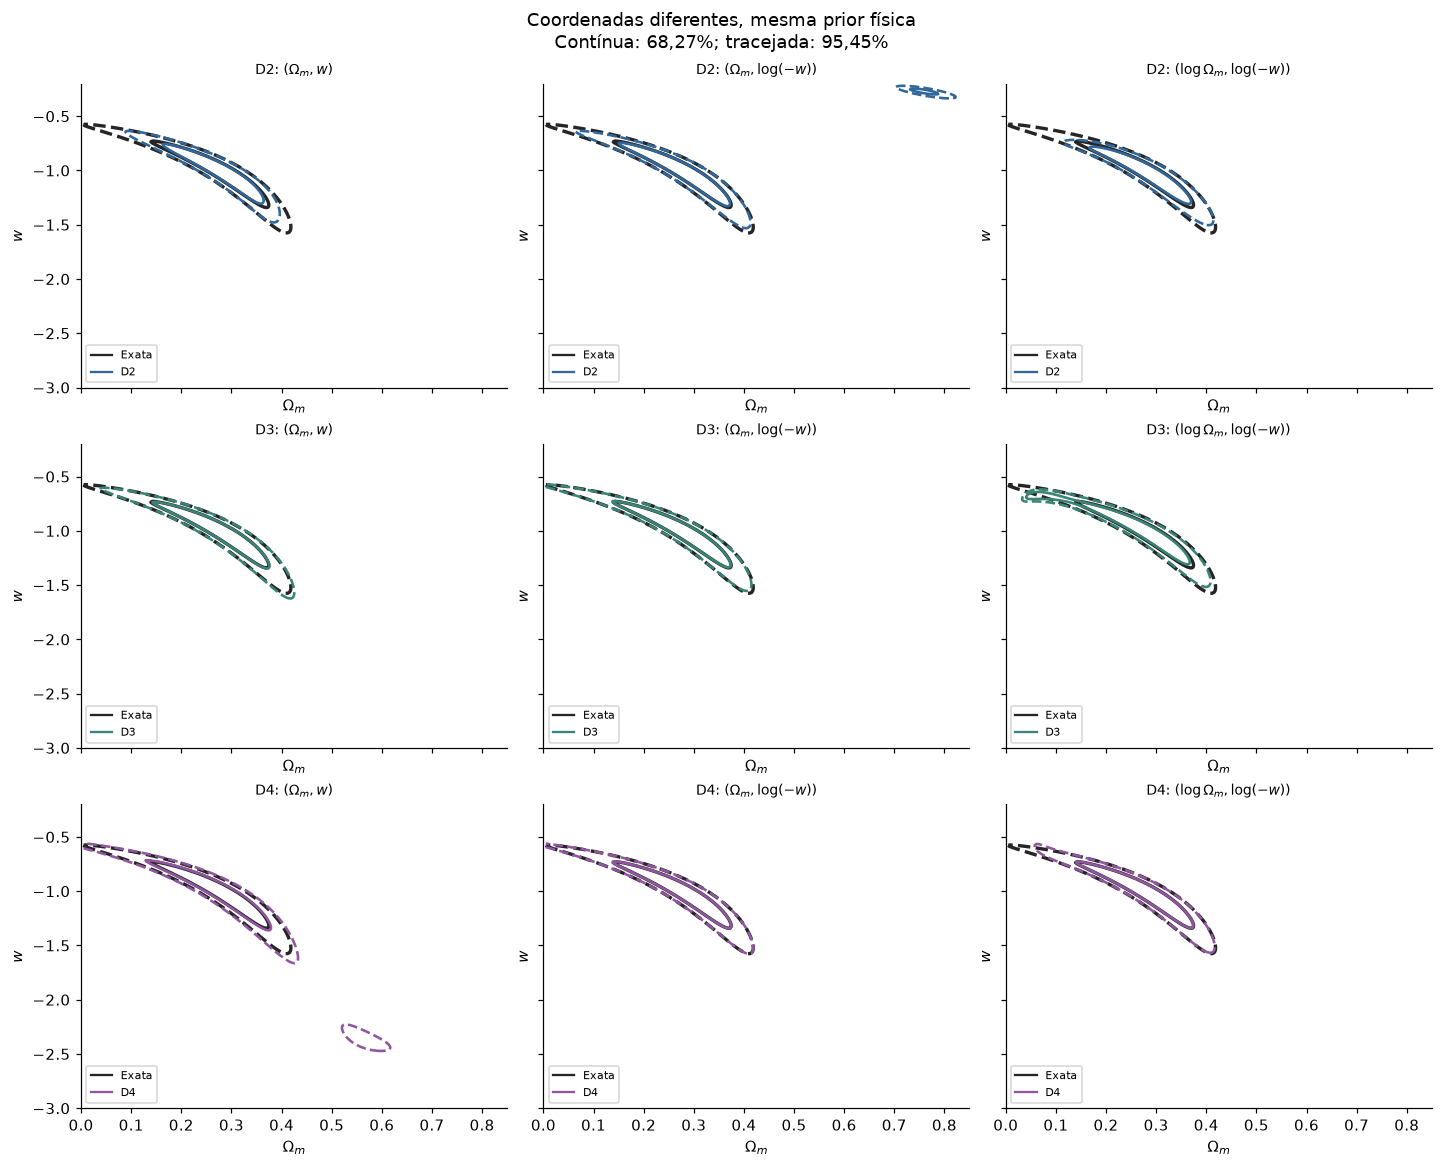

In [57]:
charts5=('physical','logw','logboth')  # Fixa os três mapas que serão comparados.
nomes_charts5={'physical':r'$(\Omega_m,w)$','logw':r'$(\Omega_m,\log(-w))$','logboth':r'$(\log\Omega_m,\log(-w))$'}  # Usa notação matemática nos títulos.
expansoes_charts5={'physical':rapida5}  # Reutiliza o caso que já foi calculado.
densidades_charts5={'physical':{k:pdfs5[('D1 / Fisher','D2','D3','D4')[k-1]] for k in (1,2,3,4)}}
logs_charts5={'physical':{k:logs5[('D1 / Fisher','D2','D3','D4')[k-1]] for k in (1,2,3,4)}}
linhas_charts5=[{'Coordenadas':'Referência exata','Ordem':0,'TV conjunta':0.,
    'P(Omega_m>0.48)':dali.grid_tail_mass_1d(marginais5['Exata'][0],axes5[0],.48)}]  # Inclui a probabilidade verdadeira para interpretar a massa remota das aproximações.
for chart in charts5:
    if chart!='physical':
        expansoes_charts5[chart]=preparar5(theta_hat5,dados5,chart=chart)  # Muda apenas a coordenada usada para Taylor.
        densidades_charts5[chart],logs_charts5[chart]={},{}
        for ordem in (1,2,3,4):
            log=-expansoes_charts5[chart].exponent(sn.coordinates(pontos5,chart),ordem)  # Volta aos pontos físicos antes de integrar.
            densidades_charts5[chart][ordem],_=dali.normalize_log_grid(log,*axes5)  # Conserva dOmega_m dw e a mesma prior.
            logs_charts5[chart][ordem]=log
    for ordem in (1,2,3,4):
        pdf=densidades_charts5[chart][ordem]  # Seleciona a densidade na medida física comum.
        marginal_omega=simpson(pdf,x=axes5[1],axis=0)  # Integra w antes de medir a cauda em matéria.
        linhas_charts5.append({'Coordenadas':chart,'Ordem':ordem,'TV conjunta':.5*dali.integrate_grid_2d(abs(pdf-ref5),*axes5),
            'P(Omega_m>0.48)':dali.grid_tail_mass_1d(marginal_omega,axes5[0],.48)})  # Esta é uma região operacional, não o peso de um componente de mistura.
tabela5('07_parametrizacao',pd.DataFrame(linhas_charts5))
v_prior5=np.linspace(np.log(.2),np.log(4.5),2001)  # Integra a prior transformada em toda a faixa de v.
prior_v5=np.exp(v_prior5)/(4.5-.2)  # Converte a uniforme física de w usando |dw/dv|=|w|.
assert abs(simpson(prior_v5,x=v_prior5)-1)<1e-10  # Confere a normalização do jacobiano separadamente da cosmologia.
tabela5('08_prior_transformada',pd.DataFrame([
    {'Escolha':'Uniforme física em w','P(w<-2) antes dos dados':(4.5-2)/(4.5-.2)},
    {'Escolha':'Uniforme em log(-w): outra prior','P(w<-2) antes dos dados':np.log(4.5/2)/np.log(4.5/.2)}]))
fig,axs=plt.subplots(3,3,figsize=(13,10.5),sharex=True,sharey=True,layout='constrained')  # Cada coluna muda a coordenada e cada linha muda a ordem.
for coluna,chart in enumerate(charts5):
    for linha,ordem in enumerate((2,3,4)):
        ax=axs[linha,coluna]  # Mantém cada comparação com somente duas densidades.
        contornos5(ax,ref5,axes5,COR5['Exata'],lw=2.2)  # Repete a mesma posterior física de referência.
        contornos5(ax,densidades_charts5[chart][ordem],axes5,COR5[f'D{ordem}'])
        plano5(ax,xlim=(0,.85),ylim=(-3.,-.2))  # Inclui os máximos remotos detectados nestes mapas.
        ax.set_title(f'D{ordem}: {nomes_charts5[chart]}',fontsize=9)
        ax.legend(handles=[Line2D([0],[0],color=COR5['Exata'],label='Exata'),Line2D([0],[0],color=COR5[f'D{ordem}'],label=f'D{ordem}')],fontsize=7,loc='lower left')  # Mantém a legenda longe do máximo adicional de D2 em logw.
fig.suptitle('Coordenadas diferentes, mesma prior física\nContínua: 68,27%; tracejada: 95,45%',fontsize=12)
figura5('06_parametrizacao_e_ordem',fig)


Os resultados mostram por que não podemos escolher uma parametrização apenas por parecer mais natural ou por manter parâmetros positivos. `logw` melhora bastante o tripleto e a quarta ordem nesta região, mas seu dubleto cria uma concentração remota. Em `logboth`, o tripleto passa a ter um máximo adicional e perde fidelidade, embora a quarta ordem volte a melhorar. Não há uma coordenada vencedora em toda ordem.

A escolha deve combinar domínio físico, regularidade do modelo, tamanho do resto de Taylor e verificação da massa longe do centro. O acordo da região central é necessário, mas pode deixar passar concentrações adicionais. Também não basta procurar picos em uma marginal: uma estrutura conjunta pode se diluir ou se combinar com outra ao integrar.

Na referência, $P(\Omega_m>0.48)\simeq3.2\times10^{-5}$. A quarta ordem física coloca cerca de $4.10\%$ nessa região. Essa diferença de massa ajuda a explicar por que uma curva central visualmente boa pode produzir momentos e caudas incorretos.

A tabela da prior mostra uma diferença grande mesmo antes de usar os dados. É por isso que uma curva aparentemente melhor, obtida ao impor uma uniforme na nova coordenada, não demonstraria por si só que a expansão melhorou. Neste experimento essa mudança de problema foi evitada.


## 5.10. O máximo adicional da quarta ordem é sustentado pelos dados?

Vamos tornar o diagnóstico verificável. Buscaremos candidatos que sejam máximos locais resolvidos na malha e estejam até 12 unidades de log-densidade abaixo do máximo nela encontrado. Depois refinaremos esses pontos na aproximação e avaliaremos a likelihood **completa** nas mesmas coordenadas físicas. Extremos presos à fronteira serão identificados separadamente de máximos interiores.

No caso físico, a quarta ordem sugere uma concentração em torno de $(0.5704,-2.3797)$. Para saber se é espúria, não basta comparar sua altura com a do MAP: precisamos perguntar se a likelihood completa também tem ali uma estrutura estacionária e uma densidade compatível.

Definiremos $\Delta\chi^2_K=2[E_K(\theta)-E_K(\widehat\theta)]$ e $\Delta\chi^2_{\rm exata}=\chi^2(\theta)-\chi^2(\widehat\theta)$. A figura mostrará também o caminho reto entre o MAP e o máximo secundário. Esse caminho é somente um corte de diagnóstico, não uma trajetória física nem uma marginal.


,Coordenadas,Ordem,Tipo,Omega_m,w,Delta chi² aproximada,Delta chi² exata,Menor autovalor Hessiana de E aproximada,Norma gradiente chi² exata
0,physical,1,principal,0.281166,-1.009897,0.000000,4.547474e-13,22.122069,0.000013
1,physical,2,principal,0.281166,-1.009897,0.000000,-5.684342e-13,21.770471,0.000004
2,physical,3,principal,0.281166,-1.009897,0.000000,-5.684342e-13,21.770445,0.000004
3,physical,4,adicional interior,0.570434,-2.379736,4.960906,5.179215e+01,150.098293,598.821287
4,physical,4,principal,0.281166,-1.009897,0.000000,-5.684342e-13,21.770445,0.000004
5,logw,1,principal,0.281166,-1.009897,0.000000,-5.684342e-13,22.122076,0.000004
6,logw,2,principal,0.281166,-1.009897,0.000000,-5.684342e-13,21.770481,0.000004
7,logw,2,adicional interior,0.758211,-0.269922,1.156732,4.984498e+02,793.366478,567.730357
8,logw,3,principal,0.281166,-1.009897,0.000000,-5.684342e-13,21.770445,0.000004
9,logw,4,principal,0.281166,-1.009897,0.000000,-5.684342e-13,21.770445,0.000004


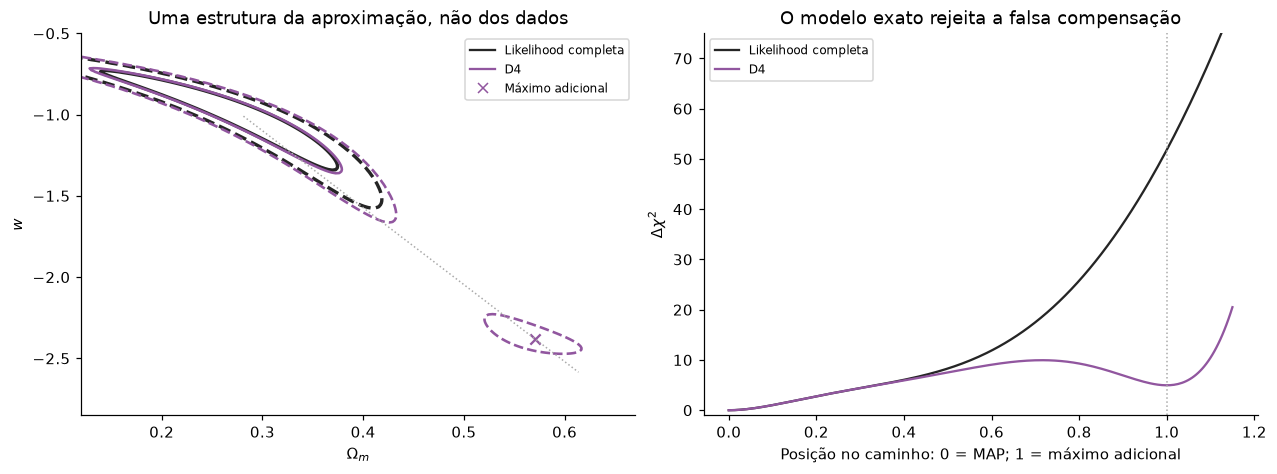

In [58]:
linhas_modos5=[]  # Registra candidatos refinados, incluindo os que aparecem em outras coordenadas.
for chart in charts5:
    expansion=expansoes_charts5[chart]  # Seleciona as derivadas já preparadas nesse mapa.
    central=sn.coordinates(theta_hat5,chart)  # Mantém o mesmo centro físico da comparação.
    for ordem in (1,2,3,4):
        log=logs_charts5[chart][ordem]  # Busca apenas estruturas resolvidas na malha inteira.
        candidatos=np.argwhere((log==maximum_filter(log,size=5))&(log>=log.max()-12))  # Declara o limiar da busca, sem prometer ausência global de outros picos.
        encontrados=[]  # Evita registrar várias células do mesmo máximo.
        for linha,coluna in candidatos:
            energia=lambda th:float(expansion.exponent(sn.coordinates(th,chart),ordem))  # Refina o quadrado da aproximação em parâmetros físicos.
            ajuste=minimize(energia,pontos5[linha,coluna],method='Nelder-Mead',bounds=BOUNDS5,
                options={'xatol':1e-9,'fatol':1e-10,'maxiter':2000})  # Usa o candidato apenas como ponto inicial.
            th=ajuste.x  # Recupera a localização refinada.
            if any(np.linalg.norm(th-other)<1e-4 for other in encontrados):
                continue  # Não conta duas vezes um candidato que convergiu ao mesmo ponto.
            encontrados.append(th)
            borda=bool(np.any(np.minimum(abs(th-BOUNDS5[:,0]),abs(th-BOUNDS5[:,1]))<1e-5))  # Identifica extremos condicionados pela prior.
            tipo='principal' if np.linalg.norm(th-theta_hat5)<1e-3 else ('fronteira' if borda else 'adicional interior')
            passos_hess5=np.array([1e-4,2e-4])  # Escolhe deslocamentos pequenos para conferir a curvatura dos candidatos refinados.
            hess_energia5=np.empty((2,2))  # Usa diferenças independentes da busca de máximos.
            for a in (0,1):
                ea=np.eye(2)[a]*passos_hess5[a]  # Percorre uma direção física por vez.
                hess_energia5[a,a]=(energia(th+ea)-2*energia(th)+energia(th-ea))/passos_hess5[a]**2
            ea,eb=np.diag(passos_hess5)  # Define as direções que entram na derivada mista.
            hess_energia5[0,1]=hess_energia5[1,0]=(energia(th+ea+eb)-energia(th+ea-eb)-energia(th-ea+eb)+energia(th-ea-eb))/(4*np.prod(passos_hess5))
            menor_curvatura5=float(np.linalg.eigvalsh(hess_energia5).min())  # Máximos de exp(-E) devem ser mínimos de E.
            if tipo=='adicional interior':
                assert menor_curvatura5>0  # Confirma que o candidato adicional é um máximo local da aproximação, não uma sela.
            residuo_exato=projecao5.project(dados5-modelo5.predict(th))  # Reavalia o modelo completo nesse ponto, sem usar a Taylor.
            jac_exato=projecao5.derivative_tensors(modelo5.derivatives(th,1))[0]  # Calcula o gradiente da referência no candidato.
            linhas_modos5.append({'Coordenadas':chart,'Ordem':ordem,'Tipo':tipo,'Omega_m':th[0],'w':th[1],
                'Delta chi² aproximada':2*(energia(th)-float(expansion.exponent(central,ordem))),
                'Delta chi² exata':float(residuo_exato@residuo_exato)-chi2_hat5,
                'Menor autovalor Hessiana de E aproximada':menor_curvatura5,
                'Norma gradiente chi² exata':float(np.linalg.norm(-2*jac_exato.T@residuo_exato))})
tabela5('09_modos_refinados',pd.DataFrame(linhas_modos5))  # Conserva também os extremos de fronteira, sem chamá-los de modos interiores.
modo4_5=next(row for row in linhas_modos5 if row['Coordenadas']=='physical' and row['Ordem']==4 and row['Tipo']=='adicional interior')  # Seleciona o exemplo que estamos investigando.
theta_esp5=np.array([modo4_5['Omega_m'],modo4_5['w']])  # Não o trata como uma segunda cosmologia favorecida pelos dados.
t_caminho5=np.linspace(0,1.15,251)  # Percorre o MAP, o máximo secundário e um pequeno trecho depois dele.
caminho5=theta_hat5+t_caminho5[:,None]*(theta_esp5-theta_hat5)  # Define explicitamente o corte no plano físico.
delta_exata5=-2*sn.loglike_grid(modelo5,projecao5,dados5,caminho5)-chi2_hat5  # Usa a integral cosmológica completa no corte.
delta_d4_5=2*(rapida5.exponent(caminho5,4)-rapida5.exponent(theta_hat5,4))  # Usa apenas a aproximação de quarta ordem.
fig,axs=plt.subplots(1,2,figsize=(11.5,4.2),layout='constrained')
contornos5(axs[0],ref5,axes5,COR5['Exata'],lw=2.2)  # Mostra a região que a posterior observada sustenta.
contornos5(axs[0],pdfs5['D4'],axes5,COR5['D4'])  # Mostra a massa extra criada pela expansão.
axs[0].plot(caminho5[:,0],caminho5[:,1],color='#aaaaaa',ls=':',lw=1)  # Localiza o corte desenhado à direita.
axs[0].scatter(*theta_esp5,marker='x',s=45,color=COR5['D4'],label='Máximo adicional de D4')
plano5(axs[0],xlim=(.12,.67),ylim=(-2.85,-.5))
axs[0].set_title('Uma estrutura da aproximação, não dos dados')
axs[0].legend(handles=[Line2D([0],[0],color=COR5['Exata'],label='Likelihood completa'),
    Line2D([0],[0],color=COR5['D4'],label='D4'),Line2D([0],[0],color=COR5['D4'],marker='x',ls='',label='Máximo adicional')],fontsize=8)  # Identifica também as cores dos contornos.
axs[1].plot(t_caminho5,delta_exata5,color=COR5['Exata'],label='Likelihood completa')  # Mantém somente duas curvas para isolar o mecanismo.
axs[1].plot(t_caminho5,delta_d4_5,color=COR5['D4'],label='D4')
axs[1].axvline(1,color='#aaaaaa',ls=':',lw=1)  # Marca o ponto refinado, não um novo ajuste da referência.
axs[1].set(xlabel='Posição no caminho: 0 = MAP; 1 = máximo adicional',ylabel=r'$\Delta\chi^2$',ylim=(-1,75),title='O modelo exato rejeita a falsa compensação')
axs[1].legend(fontsize=8)
figura5('07_modo_espurio_da_quarta_ordem',fig)


No máximo adicional físico de D4, $\Delta\chi^2_K$ é aproximadamente 4.96, mas a likelihood completa dá $\Delta\chi^2\simeq51.79$ e gradiente não nulo. A aproximação produz uma compensação artificial entre os termos truncados; a função cosmológica original não compartilha esse máximo. É o mesmo tipo de cautela estudado nos exemplos controlados, agora num catálogo real.

A quarta ordem continua positiva e normalizável com a prior escolhida. Essas propriedades não impedem uma geometria incorreta. A região $\Omega_m>0.48$ da tabela anterior é um diagnóstico operacional da massa remota, não uma decomposição da posterior em componentes de mistura.

Em `logw`, uma concentração adicional aparece já em D2; em `logboth`, aparece em D3. A mudança de coordenadas pode deslocar o problema entre ordens, em vez de resolvê-lo universalmente. A busca tem resolução, limiar de altura e domínio declarados. Quando não detectamos um máximo adicional, afirmamos apenas essa ausência **neste diagnóstico**, sem transformar a figura numa prova global.


## 5.11. O que muda ao incluir as correlações sistemáticas?

Até aqui, seguimos a covariância diagonal da aplicação do artigo. Agora vamos usar a matriz oficial com sistemáticas para ver se a geometria e a expansão continuam coerentes quando os erros se correlacionam. Esse controle muda a likelihood: é uma comparação entre duas hipóteses de covariância, não entre ordens do mesmo alvo.

Repetiremos o ajuste, a marginalização da calibração e a preparação das derivadas com a nova matriz. Não reutilizaremos o MAP nem o Fisher da análise diagonal como se descrevessem o mesmo problema. A matriz é tratada como conhecida e independente de $\theta$; por isso a construção de DALI permanece aplicável.

Esperamos uma mudança na informação disponível e nas degenerescências. Incluir sistemáticas não significa apenas multiplicar todas as barras por uma constante: correlações podem afetar de formas diferentes as combinações de distâncias que informam os parâmetros.


,Covariância,MAP Omega_m,MAP w,Média Omega_m,Média w,Desvio Omega_m,Desvio w
0,Estatística diagonal,0.281166,-1.009897,0.274803,-1.029236,0.076510,0.203065
1,Com sistemáticas,0.295764,-1.000855,0.296215,-1.090389,0.111683,0.354633


TV de D3 contra a referência com sistemáticas: 0.05190995974715076


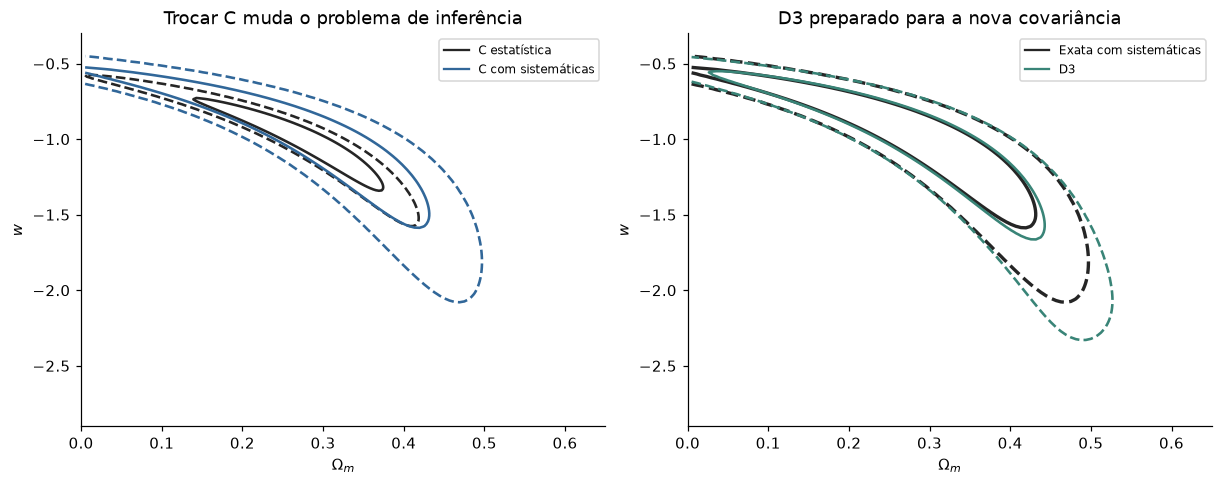

In [59]:
projecao_sys5=sn.CalibrationProjection(Csys5)  # Usa a matriz completa uma única vez, sem somar novamente a diagonal.
ajuste_sys5=sn.fit_supernovae(modelo5,projecao_sys5,dados5,BOUNDS5,start=theta_hat5)  # Encontra o centro apropriado a essa likelihood.
theta_sys5=ajuste_sys5.x
axes_sys5=(np.linspace(*BOUNDS5[0],161),np.linspace(*BOUNDS5[1],241))  # Usa uma malha suficiente para o controle, sem misturá-la à referência principal.
xsys5,wsys5=np.meshgrid(*axes_sys5)
pts_sys5=np.stack((xsys5,wsys5),axis=-1)
logsys5=sn.loglike_grid(modelo5,projecao_sys5,dados5,pts_sys5)  # Recalcula o alvo com todas as correlações.
ref_sys5,_=dali.normalize_log_grid(logsys5,*axes_sys5)
rapida_sys5=preparar5(theta_sys5,dados5,projection=projecao_sys5)  # Recalcula resíduo, derivadas projetadas e compressão.
pdf_sys_d3_5,_=dali.normalize_log_grid(-rapida_sys5.exponent(pts_sys5,3),*axes_sys5)  # Mantém a comparação de D3 com sua própria referência.
linhas_cov5=[]
for nome,pdf,eixos,centro in [('Estatística diagonal',ref5,axes5,theta_hat5),('Com sistemáticas',ref_sys5,axes_sys5,theta_sys5)]:
    media,cov=dali.grid_moments_2d(pdf,*eixos)  # Integra os momentos de cada alvo no mesmo domínio físico.
    linhas_cov5.append({'Covariância':nome,'MAP Omega_m':centro[0],'MAP w':centro[1],'Média Omega_m':media[0],
        'Média w':media[1],'Desvio Omega_m':np.sqrt(cov[0,0]),'Desvio w':np.sqrt(cov[1,1])})
tabela5('10_covariancias',pd.DataFrame(linhas_cov5))
print('TV de D3 contra a referência com sistemáticas:',.5*dali.integrate_grid_2d(abs(pdf_sys_d3_5-ref_sys5),*axes_sys5))
fig,axs=plt.subplots(1,2,figsize=(11,4.3),layout='constrained')
contornos5(axs[0],ref5,axes5,COR5['Exata'])  # Compara as duas inferências exatas, sem confundir efeito de covariância com erro de DALI.
contornos5(axs[0],ref_sys5,axes_sys5,'#316799')
axs[0].set_title('Trocar C muda o problema de inferência')
axs[0].legend(handles=[Line2D([0],[0],color=COR5['Exata'],label='C estatística'),Line2D([0],[0],color='#316799',label='C com sistemáticas')],fontsize=8)
contornos5(axs[1],ref_sys5,axes_sys5,COR5['Exata'],lw=2.2)  # Usa a nova referência ao avaliar a aproximação.
contornos5(axs[1],pdf_sys_d3_5,axes_sys5,COR5['D3'])
axs[1].set_title('D3 preparado para a nova covariância')
axs[1].legend(handles=[Line2D([0],[0],color=COR5['Exata'],label='Exata com sistemáticas'),Line2D([0],[0],color=COR5['D3'],label='D3')],fontsize=8)
for ax in axs:
    plano5(ax)
figura5('08_covariancia_e_sistematicas',fig)


Com sistemáticas, o MAP fica próximo de $(0.2958,-1.0009)$, mas o efeito mais visível é o alargamento da região. O desvio marginal de $\Omega_m$ passa de aproximadamente 0.0765 para 0.1117; o de $w$, de 0.2031 para 0.3546. A média de $w$ fica mais negativa que o MAP por causa da massa ao longo da cauda curva.

A comparação da direita pergunta se D3 acompanha esse novo alvo. Sua TV é aproximadamente 0.052, maior que 0.015 no caso estatístico. Ele ainda recupera parte importante da forma, mas sua precisão precisa ser medida novamente: uma ordem adequada para uma matriz de erros não recebe uma garantia automática para outra.

Continuamos trabalhando com os módulos já publicados e um único offset livre. Essa etapa não reproduz o ajuste conjunto de todas as nuisances das curvas de luz e da população hospedeira. O controle informa o efeito de usar a covariância disponibilizada nesse modelo comprimido de distâncias.


## 5.12. MCMC como verificação da likelihood completa

A malha fornece uma referência direta em dois parâmetros. Vamos verificá-la por uma rota diferente: quatro cadeias independentes de Metropolis, usando a likelihood cosmológica completa e a mesma prior física. **Nenhuma cadeia usará DALI como alvo.**

Se o estado atual é $\theta$, propomos $\theta'=\theta+sL_F\xi$, com $L_FL_F^T=F^{-1}$ e $\xi\sim\mathcal N(0,I)$. A proposta gaussiana é simétrica, então a probabilidade de aceitação é

$$
\alpha=\min\!\left[1,\frac{\mathcal L_{\rm exata}(\theta')\pi(\theta')}
{\mathcal L_{\rm exata}(\theta)\pi(\theta)}\right].
$$

Fisher orienta os saltos, mas cada decisão ainda avalia a integral de distância completa. Uma proposta fora da prior é rejeitada. Durante o aquecimento, ajustamos somente a escala $s$; depois a congelamos. Estados rejeitados são repetidos na cadeia, pois fazem parte da distribuição estacionária.

O código usará 24 mil passos por cadeia, dos quais 4 mil são aquecimento: 80 mil estados retidos ao todo. Isso não significa 80 mil amostras independentes. Vamos medir autocorrelação por ESS e verificar a concordância entre cadeias pelo $\widehat R$ com divisão, postos e dobramento, seguindo [Vehtari et al. (2021)](https://arxiv.org/abs/1903.08008). Informaremos ESS da região central e das caudas, além do erro de Monte Carlo da média. Esses diagnósticos não provam ausência de modos remotos; a referência em malha os complementa.

Essa é uma primeira conexão com a combinação Fisher–MCMC que queremos estudar depois. Ainda não é uma demonstração de ganho de velocidade: avaliar um alvo aproximado seria outra operação, e uma proposta não simétrica baseada em DALI exigiria conservar a razão das propostas na aceitação.


In [60]:
alvo_projetado5=projecao5.project(dados5)  # Transforma os dados uma vez, fora do laço das cadeias.
def logposterior_exata5(points):
    """Retorna a log-posterior observada, com -inf fora da prior física."""
    points=np.asarray(points,dtype=float)  # Recebe uma lista de pontos, um por cadeia.
    permitido=np.all((points>=BOUNDS5[:,0])&(points<=BOUNDS5[:,1]),axis=-1)  # Aplica exatamente os mesmos limites da malha.
    result=np.full(points.shape[:-1],-np.inf)  # Já rejeita os pontos que não pertencem ao suporte.
    if np.any(permitido):
        residual=alvo_projetado5-projecao5.project(modelo5.predict(points[permitido]))  # Avalia a distância completa, sem Taylor.
        result[permitido]=-.5*np.sum(residual**2,axis=-1)  # Omite somente constantes comuns dentro da prior.
    return result

inicios5=np.array([[.12,-.65],[.25,-1.],[.38,-1.8],[.3,-2.5]])  # Começa em regiões dispersas para comparar as cadeias depois do aquecimento.
PASSOS5,AQUECIMENTO5=24000,4000  # Altere para alongar as cadeias; repita os diagnósticos após qualquer mudança.
inicio_mcmc5=time.perf_counter()  # Registra o tempo da amostragem exata desta configuração.
cadeias5=mc.metropolis(logposterior_exata5,inicios5,SigmaF5,steps=PASSOS5,warmup=AQUECIMENTO5,seed=SEMENTE)  # Usa Fisher somente na proposta.
tempo_mcmc5=time.perf_counter()-inicio_mcmc5
np.savez_compressed(TAB5/'mcmc_union21.npz',samples=cadeias5.samples,acceptance=cadeias5.acceptance,
    scales=cadeias5.scales,starts=inicios5,bounds=BOUNDS5,seed=SEMENTE,steps=PASSOS5,warmup=AQUECIMENTO5)  # Guarda a amostra e sua configuração.
diagnosticos5=[]  # Registra a precisão efetiva dos resultados, em vez de contar apenas estados.
for i,nome in enumerate(('Omega_m','w')):
    series=cadeias5.samples[:,:,i]  # Mantém separados os eixos de cadeia e tempo para os diagnósticos.
    diag=mc.diagnostics(series)  # Calcula Rhat por postos, ESS central, ESS de cauda e MCSE.
    diagnosticos5.append({'Parâmetro':nome,'Média MCMC':series.mean(),'Média da malha':media_ref5[i],
        'Desvio MCMC':series.std(),'Desvio da malha':np.sqrt(cov_ref5[i,i]),
        'Diferença média / MCSE':(series.mean()-media_ref5[i])/diag['mcse_mean'],**diag})
    assert diag['rhat']<1.01 and min(diag['ess_bulk'],diag['ess_tail'])>400  # Exige mistura central e de cauda nesta execução.
    assert abs(series.mean()-media_ref5[i])<5*diag['mcse_mean']+1e-4  # Compara médias respeitando o erro de Monte Carlo.
tabela5('11_diagnosticos_mcmc',pd.DataFrame(diagnosticos5))
tabela5('12_cadeias_e_proposta',pd.DataFrame({'Cadeia':np.arange(1,5),'Aceitação na produção':cadeias5.acceptance,'Escala congelada':cadeias5.scales}))
print('Estados retidos:',cadeias5.samples.shape[0]*cadeias5.samples.shape[1],'| tempo MCMC exato (s):',round(tempo_mcmc5,2))


,Parâmetro,Média MCMC,Média da malha,Desvio MCMC,Desvio da malha,Diferença média / MCSE,rhat,ess_bulk,ess_tail,ess_mean,mcse_mean
0,Omega_m,0.274392,0.274803,0.076899,0.076510,-0.409001,1.000287,6396.017890,4581.178446,5852.999707,0.001005
1,w,-1.027667,-1.029236,0.202808,0.203065,0.624803,1.000315,6383.511892,5013.305998,6519.888448,0.002512


,Cadeia,Aceitação na produção,Escala congelada
0,1,0.30075,1.804939
1,2,0.32615,1.682914
2,3,0.29525,1.823079
3,4,0.28495,1.878600


Estados retidos: 80000 | tempo MCMC exato (s): 20.63


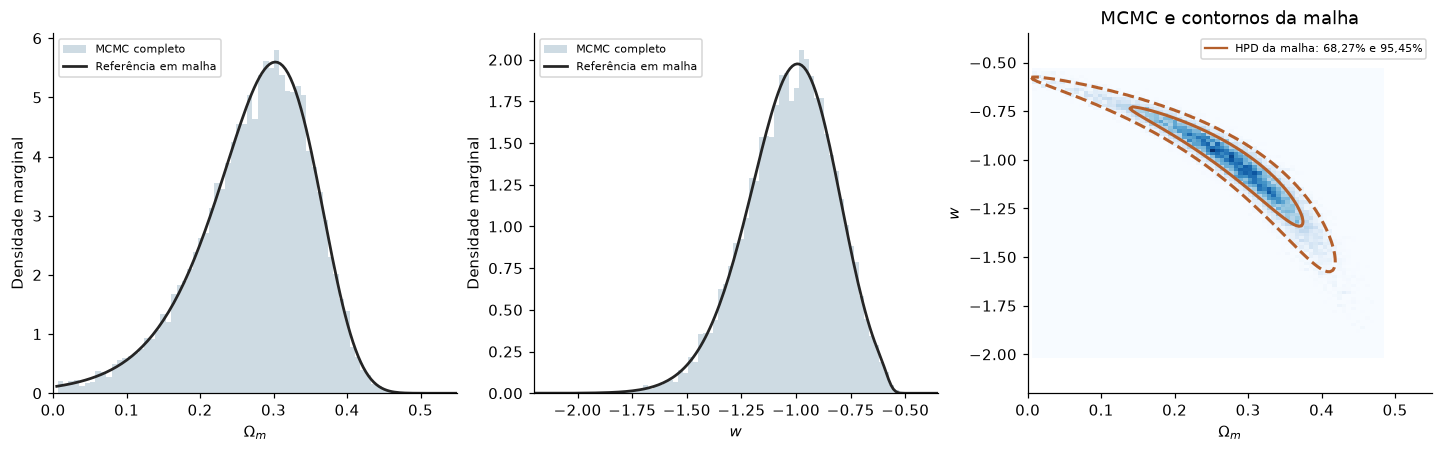

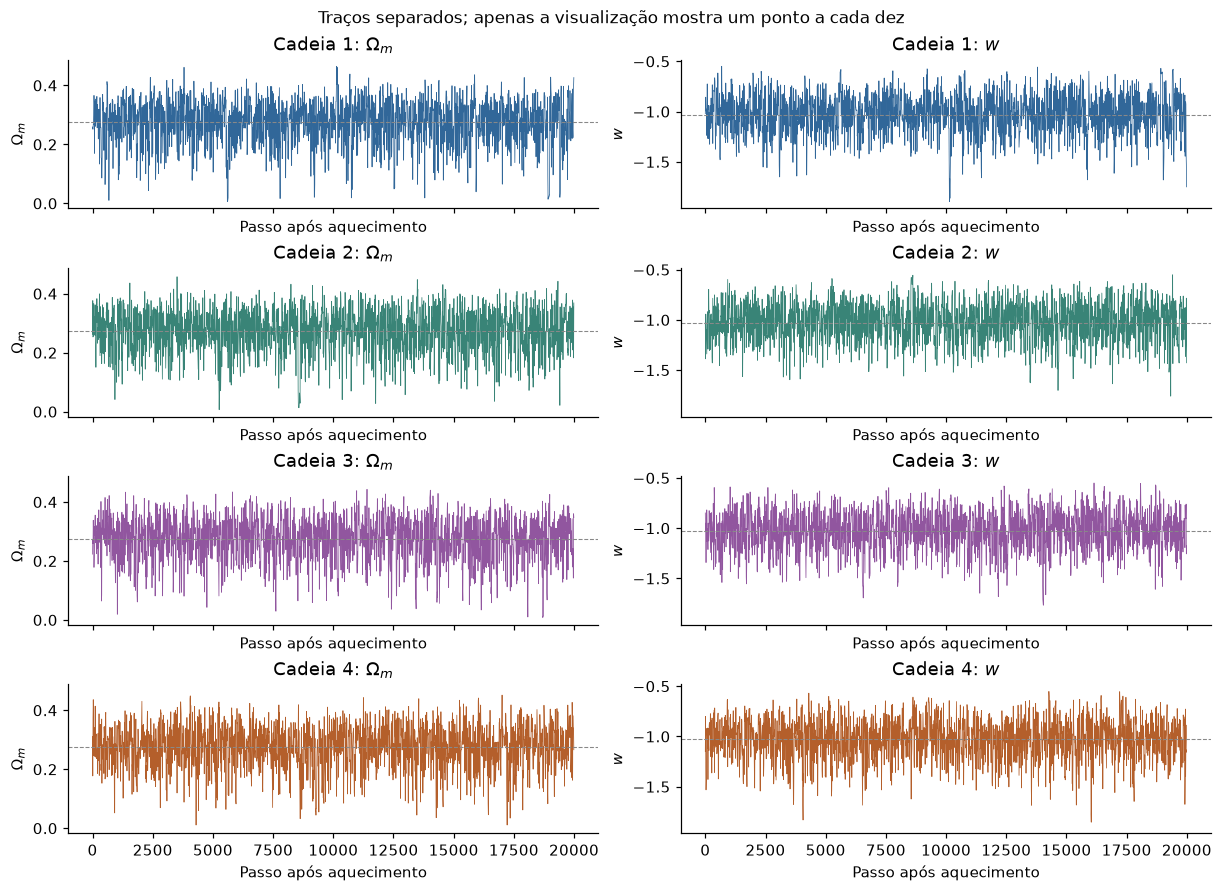

,Conteúdo nominal,Frequência MCMC,MCSE da frequência,ESS da indicadora
0,0.6827,0.675462,0.005677,6803.117210
1,0.9545,0.959163,0.002301,7399.326263


In [61]:
amostras5=cadeias5.samples.reshape(-1,2)  # Junta as cadeias só para desenhar densidades e calcular frequências.
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')  # Compara duas marginais e o plano conjunto.
for i in (0,1):
    axs[i].hist(amostras5[:,i],bins=65,density=True,color='#c6d5df',alpha=.85,label='MCMC completo')  # Mantém a flutuação amostral visível.
    axs[i].plot(axes5[i],marginais5['Exata'][i],color=COR5['Exata'],lw=1.8,label='Referência em malha')
    axs[i].set(xlabel=NOMES5[i],ylabel='Densidade marginal',xlim=((0,.55) if i==0 else (-2.2,-.35)))
    axs[i].legend(fontsize=7.5)
hist5,edges_om5,edges_w5=np.histogram2d(amostras5[:,0],amostras5[:,1],bins=(75,90),density=True)  # Usa contagens, sem ajustar uma gaussiana à amostra.
axs[2].pcolormesh(edges_om5,edges_w5,hist5.T,cmap='Blues',shading='auto',rasterized=True)  # Mostra onde as cadeias passaram.
contornos5(axs[2],ref5,axes5,'#b45f2b',lw=2)  # Sobrepõe os conteúdos de probabilidade da referência independente.
plano5(axs[2],xlim=(0,.55),ylim=(-2.2,-.35))
axs[2].set_title('MCMC e contornos da malha')
axs[2].legend(handles=[Line2D([0],[0],color='#b45f2b',label='HPD da malha: 68,27% e 95,45%')],fontsize=7)
figura5('09_mcmc_e_malha',fig)
fig,axs=plt.subplots(4,2,figsize=(11,8),sharex=True,sharey='col',layout='constrained')  # Deixa uma cadeia por painel para evitar quatro traços sobrepostos.
cores_cadeias5=('#316799','#398477','#91569f','#b45f2b')  # Mantém identidade visual entre os parâmetros da mesma cadeia.
for chain in range(4):
    for i in (0,1):
        axs[chain,i].plot(np.arange(0,cadeias5.samples.shape[1],10),cadeias5.samples[chain,::10,i],lw=.5,color=cores_cadeias5[chain])  # Reduz só a densidade visual; os diagnósticos usaram todos os estados.
        axs[chain,i].axhline(media_ref5[i],color='#888888',ls='--',lw=.7)  # Marca a média da referência como orientação.
        axs[chain,i].set(title=f'Cadeia {chain+1}: '+NOMES5[i],xlabel='Passo após aquecimento',ylabel=NOMES5[i])
fig.suptitle('Traços separados; apenas a visualização mostra um ponto a cada dez',fontsize=11)
figura5('10_tracos_das_cadeias',fig)
interpolador5=RegularGridInterpolator((axes5[1],axes5[0]),ref5,bounds_error=False,fill_value=0.)  # Usa a referência contínua por interpolação para classificar as amostras.
densidade_nas_cadeias5=interpolador5(cadeias5.samples[:,:,[1,0]])  # Ajusta a ordem de índices da matriz: w primeiro, Omega depois.
linhas_massas5=[]
for prob,level in zip(PROBS5,dali.hpd_thresholds_2d(ref5,*axes5,PROBS5)):
    dentro=(densidade_nas_cadeias5>=level).astype(float)  # Cria uma série indicadora da região HPD da malha.
    diag=mc.diagnostics(dentro)  # Mede o erro da frequência considerando sua autocorrelação.
    linhas_massas5.append({'Conteúdo nominal':prob,'Frequência MCMC':dentro.mean(),'MCSE da frequência':diag['mcse_mean'],'ESS da indicadora':diag['ess_mean']})
tabela5('13_massas_hpd_mcmc',pd.DataFrame(linhas_massas5))  # Complementa a concordância de médias e histogramas.


As cadeias recuperam a região curva e as marginais da malha dentro da precisão amostral. As médias diferem por menos de alguns erros de Monte Carlo, e as frequências das regiões HPD fornecem uma conferência adicional da massa integrada. Os traços são mostrados separadamente para que a sobreposição não esconda uma cadeia presa.

O $\widehat R$ próximo de 1 e os ESS de milhares são compatíveis com boa exploração desta referência no domínio escolhido. A contagem de 80 mil estados deve ser lida junto desses tamanhos efetivos. Essa validação sustenta a referência usada para julgar Fisher e DALI; ela não converte os máximos extras de uma aproximação em estruturas dos dados.

A proposta orientada por Fisher continua permitindo uma posterior não gaussiana porque o alvo na aceitação é exato. Essa distinção será útil quando estudarmos estratégias de aceleração: mudar a proposta e mudar a likelihood são decisões diferentes.


## 5.13. O que a posterior diz sobre a expansão do universo?

Os valores favorecidos estão próximos de uma cosmologia com $w=-1$ e matéria em torno de 28% da densidade crítica atual. Isso é compatibilidade com essa região do modelo, não uma probabilidade posterior de $w$ ser exatamente um ponto. Também não é uma medida de $H_0$, pois sua escala foi absorvida pela calibração.

Podemos traduzir a posterior em uma quantidade física mais direta. O parâmetro de desaceleração é

$$
q(z)=-\frac{a\ddot a}{\dot a^2}
=\frac12+\frac32 w\,\Omega_{\rm DE}(z),\qquad
\Omega_{\rm DE}(z)=\frac{(1-\Omega_m)(1+z)^{3(1+w)}}{E(z)^2}.
$$

Essa relação vem da equação de aceleração para os dois fluidos adotados. $q<0$ significa expansão acelerada; $q>0$, desacelerada. No presente, $q_0=1/2+(3/2)w(1-\Omega_m)$. O melhor ajuste dá $q_0\simeq-0.589$.

Vamos transformar as amostras da posterior exata em curvas de $E(z)$ e $q(z)$. As faixas mostram incerteza **dos parâmetros do modelo**, condicionada às hipóteses e à prior; não são novos dados diretos de $H(z)$, nem incluem um novo sorteio dos erros de cada supernova. A expectativa física é ver aceleração hoje e uma contribuição crescente da matéria quando olhamos para redshifts maiores.


,q0 no MAP,Média q0 da malha,Desvio q0 da malha,Mediana q0 MCMC,Quantil 2.5%,Quantil 16%,Quantil 84%,Quantil 97.5%,Rhat de q0
0,-0.588922,-0.597838,0.113706,-0.588698,-0.834278,-0.710206,-0.482811,-0.398855,1.000397


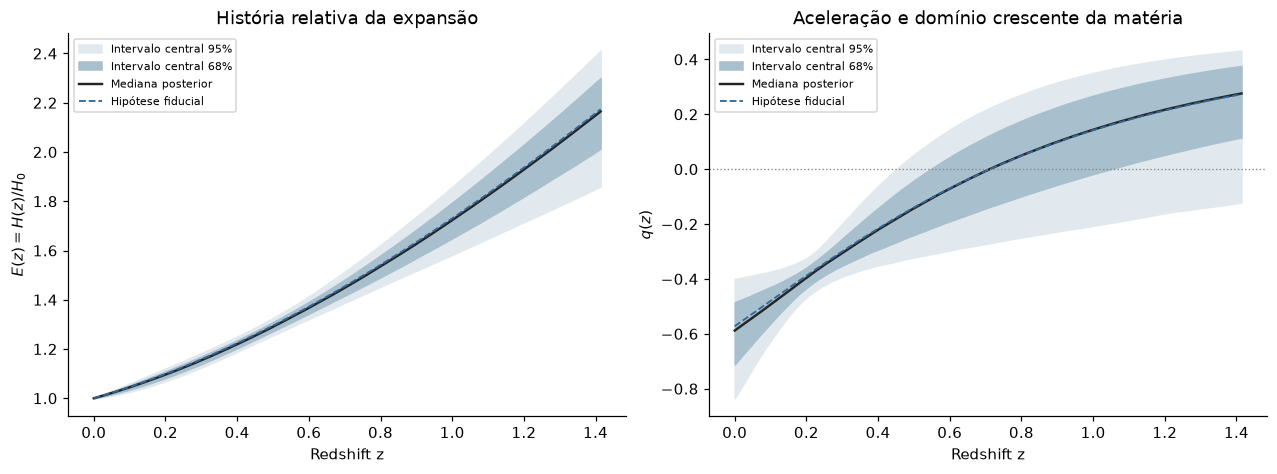

In [62]:
z_historia5=np.linspace(0,z5.max(),161)  # Mostra apenas o intervalo que conecta o presente ao catálogo.
desenhos5=amostras5[::8]  # Reduz só o número de curvas da figura; os diagnósticos anteriores usaram toda a amostra.
omega_hist5=desenhos5[:,0,None]  # Prepara um valor de matéria por curva posterior.
w_hist5=desenhos5[:,1,None]  # Prepara um valor de w por curva.
dark_hist5=(1-omega_hist5)*(1+z_historia5)**(3*(1+w_hist5))  # Calcula a densidade de energia escura ao longo do redshift.
e2_hist5=omega_hist5*(1+z_historia5)**3+dark_hist5  # Obtém E² com a equação de Friedmann adotada.
E_hist5=np.sqrt(e2_hist5)  # Retira H0 para manter apenas a história relativa medida pelo modelo.
q_hist5=.5+1.5*w_hist5*dark_hist5/e2_hist5  # Traduz a mesma posterior para aceleração e desaceleração.
q0_series5=.5+1.5*cadeias5.samples[:,:,1]*(1-cadeias5.samples[:,:,0])  # Mantém os eixos de cadeia e tempo para conferir q0.
diag_q0_5=mc.diagnostics(q0_series5)  # Verifica a mistura também nessa quantidade derivada.
q0_grid5=.5+1.5*ww5*(1-xx5)  # Obtém a mesma transformação em todos os pontos da referência.
q0_media5=dali.integrate_grid_2d(q0_grid5*ref5,*axes5)  # Confere a média física por quadratura, sem usar MCMC.
q0_std5=np.sqrt(dali.integrate_grid_2d((q0_grid5-q0_media5)**2*ref5,*axes5))
q0_quant5=np.quantile(q0_series5,[.025,.16,.5,.84,.975])  # Resume a forma sem impor uma gaussiana a q0.
tabela5('19_aceleracao_atual',pd.DataFrame([{'q0 no MAP':.5+1.5*theta_hat5[1]*(1-theta_hat5[0]),
    'Média q0 da malha':q0_media5,'Desvio q0 da malha':q0_std5,'Mediana q0 MCMC':q0_quant5[2],
    'Quantil 2.5%':q0_quant5[0],'Quantil 16%':q0_quant5[1],'Quantil 84%':q0_quant5[3],'Quantil 97.5%':q0_quant5[4],
    'Rhat de q0':diag_q0_5['rhat']}]))
fig,axs=plt.subplots(1,2,figsize=(11.5,4.2),layout='constrained')
Efid5=np.sqrt(theta_fid5[0]*(1+z_historia5)**3+(1-theta_fid5[0])*(1+z_historia5)**(3*(1+theta_fid5[1])))  # Desenha a hipótese fiducial já definida, sem reajustá-la.
qfid5=.5+1.5*theta_fid5[1]*(1-theta_fid5[0])*(1+z_historia5)**(3*(1+theta_fid5[1]))/Efid5**2
for ax,curvas,fid,ylabel,titulo in zip(axs,(E_hist5,q_hist5),(Efid5,qfid5),(r'$E(z)=H(z)/H_0$',r'$q(z)$'),
    ('História relativa da expansão','Aceleração e domínio crescente da matéria')):
    lo95,lo68,mediana,hi68,hi95=np.quantile(curvas,[.025,.16,.5,.84,.975],axis=0)  # Calcula intervalos centrais ponto a ponto, não uma banda simultânea.
    ax.fill_between(z_historia5,lo95,hi95,color='#e1e9ee',label='Intervalo central 95%')
    ax.fill_between(z_historia5,lo68,hi68,color='#a8bfce',label='Intervalo central 68%')
    ax.plot(z_historia5,mediana,color=COR5['Exata'],lw=1.6,label='Mediana posterior')
    ax.plot(z_historia5,fid,color='#316799',ls='--',lw=1.2,label='Hipótese fiducial')
    ax.set(xlabel='Redshift z',ylabel=ylabel,title=titulo)
    ax.legend(fontsize=7.5)
axs[1].axhline(0,color='#888888',ls=':',lw=.9)  # Separa a expansão acelerada da desacelerada no modelo.
figura5('11_historia_de_expansao',fig)


A posterior concentra a aceleração atual em valores negativos de $q_0$: a mediana fica próxima de $-0.589$, e o intervalo central de 95% está aproximadamente entre $-0.834$ e $-0.399$. Em redshifts maiores, a matéria cresce em importância e a mediana de $q(z)$ passa para o setor desacelerado; a faixa de 95% ainda permite histórias aceleradas em parte desse intervalo. Essa leitura é condicional ao modelo plano de dois fluidos e às escolhas da análise.

As faixas são intervalos centrais ponto a ponto. Não significam que 95% das curvas completas estejam contidas na faixa de 95% em todos os redshifts simultaneamente. A curva fiducial permanece compatível com a região ampla de histórias permitidas, mas não foi ajustada a cada amostra.

Essa interpretação também explica o próximo passo: supernovas informam uma integral de $1/E$, enquanto BAO trará combinações que dependem da distância transversal e de $H(z)$ em redshifts específicos. Combinar essas dependências pode ajudar a resolver a compensação que vimos no plano $(\Omega_m,w)$.


## 5.14. As diferenças poderiam ser numéricas ou vir da prior?

Vamos separar três verificações:

1. **Quadratura e derivadas.** Duplicar os nós de 48 para 96 deve conservar a previsão e os tensores. Compararemos algumas distâncias com integração adaptativa, inclusive longe do ajuste.
2. **Resolução em parâmetros.** Refinaremos a referência para 361 por 521 nós e compararemos normalização, médias e desvios. Os testes das séries também verificam que, ao reduzir o deslocamento pela metade, o resto cai com a potência esperada até ordem quatro.
3. **Domínio da prior.** Ampliaremos para $0.0001\leq\Omega_m\leq0.9999$ e $-6\leq w\leq-0.1$. Isso muda a prior, e não é apenas refinamento numérico. A razão das integrais do mesmo núcleo permite medir a massa da nova posterior fora do retângulo original. Faremos a comparação para a referência, D3 e D4.

A sensibilidade de uma aproximação ao domínio pode ser maior que a do alvo. Um resultado que muda muito ao abrir a prior não deve ser apresentado como se dependesse somente da curvatura local no melhor ajuste.


In [63]:
modelo96_5=sn.FlatWCDM(z5,96)  # Dobra o número de nós sem alterar dados ou cosmologia.
linhas_quadratura5=[]
for theta in (theta_hat5,theta_esp5,np.array([.05,-3.]),np.array([.9,-.2])):
    erro_mu=float(np.max(abs(modelo5.predict(theta)-modelo96_5.predict(theta))))  # Mede a estabilidade da integral em todo o catálogo.
    linhas_quadratura5.append({'Verificação':'48 vs. 96 nós','Omega_m':theta[0],'w':theta[1],'Maior diferença em mu (mag)':erro_mu})
    assert erro_mu<2e-10  # Exige precisão muito maior que os erros observacionais.
for redshift in (.015,.2,.7,1.414):
    integral=quad(lambda z:1/np.sqrt(theta_hat5[0]*(1+z)**3+(1-theta_hat5[0])*(1+z)**(3*(1+theta_hat5[1]))),0,redshift,epsabs=1e-12,epsrel=1e-12)[0]  # Usa uma quadratura adaptativa independente.
    mu_quad=5*np.log10((1+redshift)*integral)  # Converte a distância dessa rota à mesma previsão.
    mu_g=float(sn.FlatWCDM([redshift],48).predict(theta_hat5)[0])
    linhas_quadratura5.append({'Verificação':f'Gauss vs. adaptativa: z={redshift}','Omega_m':theta_hat5[0],'w':theta_hat5[1],'Maior diferença em mu (mag)':abs(mu_g-mu_quad)})
tabela5('14_quadratura',pd.DataFrame(linhas_quadratura5))
linhas_derivadas5=[]
for chart in charts5:
    der48=modelo5.derivatives(theta_hat5,4,chart)  # Conserva a mesma coordenada em ambas as quadraturas.
    der96=modelo96_5.derivatives(theta_hat5,4,chart)
    for ordem,(a,b) in enumerate(zip(der48,der96),start=1):
        relativo=np.max(abs(a-b))/max(np.max(abs(b)),1e-14)  # Normaliza por uma escala global do tensor, sem dividir por componentes nulas.
        linhas_derivadas5.append({'Coordenadas':chart,'Ordem da derivada':ordem,'Diferença relativa máxima 48 vs. 96':relativo})
        assert relativo<2e-9  # Confere também os termos usados na quarta ordem e nas mudanças de parâmetros.
tabela5('15_derivadas',pd.DataFrame(linhas_derivadas5))
axes_finas5=(np.linspace(*BOUNDS5[0],361),np.linspace(*BOUNDS5[1],521))  # Refina o mesmo retângulo da prior.
xf5,wf5=np.meshgrid(*axes_finas5)
log_fina5=sn.loglike_grid(modelo5,projecao5,dados5,np.stack((xf5,wf5),axis=-1))  # Recalcula a referência completa, em vez de interpolar a anterior.
pdf_fina5,logIfina5=dali.normalize_log_grid(log_fina5,*axes_finas5)
media_fina5,cov_fina5=dali.grid_moments_2d(pdf_fina5,*axes_finas5)
dif_media5=abs(media_fina5-media_ref5)  # Mede diferenças de médias da quadratura em parâmetros.
dif_desvio5=abs(np.sqrt(np.diag(cov_fina5))-np.sqrt(np.diag(cov_ref5)))
assert max(dif_media5.max(),dif_desvio5.max(),abs(logIfina5-logI5))<2e-5  # Separa erro de quadratura das diferenças entre aproximações.
tabela5('16_refinamento_malha',pd.DataFrame([{'Diferença log integral':abs(logIfina5-logI5),'Diferença média Omega_m':dif_media5[0],
    'Diferença média w':dif_media5[1],'Diferença desvio Omega_m':dif_desvio5[0],'Diferença desvio w':dif_desvio5[1]}]))
axes_amplas5=(np.linspace(.0001,.9999,301),np.linspace(-6.,-.1,501))  # Abre a prior para conferir a sensibilidade dos alvos, não apenas a resolução.
xa5,wa5=np.meshgrid(*axes_amplas5)
pa5=np.stack((xa5,wa5),axis=-1)
log_ampla5=sn.loglike_grid(modelo5,projecao5,dados5,pa5)  # Usa o mesmo núcleo observado para que as razões de integrais sejam comparáveis.
linhas_dominio5=[]
for nome,log_original,log_ampla in [('Exata',logref5,log_ampla5),('D3',logs5['D3'],-rapida5.exponent(pa5,3)),('D4',logs5['D4'],-rapida5.exponent(pa5,4))]:
    _,logI_original=dali.normalize_log_grid(log_original,*axes5)
    pdf,logI_ampla=dali.normalize_log_grid(log_ampla,*axes_amplas5)  # Renormaliza cada alvo na prior ampliada.
    media,cov=dali.grid_moments_2d(pdf,*axes_amplas5)
    linhas_dominio5.append({'Objeto':nome,'Massa fora do retângulo original':1-np.exp(logI_original-logI_ampla),
        'Média Omega_m na prior ampliada':media[0],'Média w na prior ampliada':media[1]})
tabela5('17_sensibilidade_a_prior',pd.DataFrame(linhas_dominio5))
tabela5('18_tempos_desta_execucao',pd.DataFrame([{'Operação':'Preparo DALI físico até ordem quatro','Segundos':tempo_preparo5},
    {'Operação':'Referência observada 281 x 401','Segundos':tempo_grid5},{'Operação':'Quatro cadeias no alvo exato','Segundos':tempo_mcmc5}]))  # Registra contexto; os trabalhos comparados produzem saídas diferentes.


,Verificação,Omega_m,w,Maior diferença em mu (mag)
0,48 vs. 96 nós,0.281166,-1.009897,1.776357e-15
1,48 vs. 96 nós,0.570434,-2.379736,1.998401e-15
2,48 vs. 96 nós,0.050000,-3.000000,5.773160e-15
3,48 vs. 96 nós,0.900000,-0.200000,5.107026e-15
4,Gauss vs. adaptativa: z=0.015,0.281166,-1.009897,0.000000e+00
5,Gauss vs. adaptativa: z=0.2,0.281166,-1.009897,0.000000e+00
6,Gauss vs. adaptativa: z=0.7,0.281166,-1.009897,4.770490e-16
7,Gauss vs. adaptativa: z=1.414,0.281166,-1.009897,0.000000e+00


,Coordenadas,Ordem da derivada,Diferença relativa máxima 48 vs. 96
0,physical,1,3.332248e-15
1,physical,2,1.497217e-15
2,physical,3,3.060282e-15
3,physical,4,4.801995e-15
4,logw,1,3.332248e-15
5,logw,2,1.437328e-15
6,logw,3,3.060282e-15
7,logw,4,4.801995e-15
8,logboth,1,5.688736e-15
9,logboth,2,3.917833e-15


,Diferença log integral,Diferença média Omega_m,Diferença média w,Diferença desvio Omega_m,Diferença desvio w
0,2.951310e-10,2.676809e-11,7.485945e-11,1.604834e-11,4.862749e-12


,Objeto,Massa fora do retângulo original,Média Omega_m na prior ampliada,Média w na prior ampliada
0,Exata,0.000551,0.274653,-1.028986
1,D3,0.000177,0.279551,-1.042491
2,D4,0.000528,0.287557,-1.087771


,Operação,Segundos
0,Preparo DALI físico até ordem quatro,0.030371
1,Referência observada 281 x 401,46.586845
2,Quatro cadeias no alvo exato,20.626211


A quadratura das distâncias e as derivadas ficam estáveis ao dobrar os nós, e o refinamento em parâmetros conserva os momentos. O máximo adicional de D4 foi encontrado usando essas mesmas derivadas estáveis e uma avaliação comprimida conferida contra o quadrado original. Isso permite atribuir o efeito ao truncamento do modelo, em vez de a uma quarta diferença finita mal condicionada.

A tabela da prior deve ser lida separadamente: ampliar o suporte muda o problema estatístico. Neste teste, a referência acrescenta cerca de 0.055% de massa fora do retângulo original; D3 e D4 físicos também acrescentam menos de 0.1%. Portanto, a diferença relevante de D4 já estava dentro do suporte inicial, e não foi produzida apenas por cortar sua cauda. As afirmações quantitativas anteriores continuam referidas à prior inicial declarada; esse teste não prova insensibilidade a qualquer prior.

Os tempos registrados não são uma competição direta entre uma malha normalizada e um conjunto de amostras. Cada operação entrega um objeto diferente. O estudo de custo do projeto separará preparo, custo por avaliação e exploração necessária para obter uma precisão comparável.


## 5.15. O que aprendemos e por que combinar observáveis?

Construímos a ligação entre uma medida publicada e o vetor de previsão: a cosmologia determina $E(z)$, sua integral determina a distância, e o logaritmo transforma a distância em módulo. A constante que reúne luminosidade absoluta e escala de Hubble foi marginalizada antes de aplicar Fisher e DALI. Isso fixa o significado do que a análise consegue medir.

O singleto descreve a geometria local; o dubleto e o tripleto acompanham melhor a região curva do Union2.1 neste experimento. A quarta ordem mostra uma limitação concreta: pode melhorar a resposta perto do centro e, simultaneamente, criar uma compensação falsa longe dele. Mudar coordenadas altera esse comportamento, mas não fornece uma escolha universalmente boa. A mesma prior física, os resíduos corretos e a validação da região inteira são partes da comparação.

A referência em malha e o MCMC completo concordam na precisão examinada. Essa concordância nos dá uma base para julgar as aproximações; não transforma a covariância, as priors ou a cosmologia adotadas em hipóteses livres de incerteza. O catálogo histórico é usado porque conecta o estudo à aplicação do artigo.

As supernovas ainda deixam uma degenerescência: observam distâncias relativas e integram a história de expansão. No próximo bloco, BAO acrescentará combinações relacionadas a

$$
D_M(z)=\frac{d_L(z)}{1+z},\qquad
D_H(z)=\frac{c}{H(z)},\qquad
\frac{D_M}{r_d},\ \frac{D_H}{r_d}.
$$

$r_d$ é a escala do horizonte sonoro no arrasto bariônico e precisará de uma hipótese de calibração própria. Essas observáveis podem cortar a degenerescência das supernovas em outra direção. Vamos conferir isso com os dados, sem assumir que combinar conjuntos sempre torna a posterior gaussiana.

Para dados condicionalmente independentes, a construção conjunta será

$$
p(\theta,\text{nuisances}\mid d_{\rm SN},d_{\rm BAO})\propto
\mathcal L_{\rm SN}\mathcal L_{\rm BAO}\,\pi(\theta,\text{nuisances}).
$$

A prior entra uma vez, e parâmetros compartilhados de calibração serão tratados de forma consistente. Somar matrizes de Fisher exige a mesma parametrização e um ponto fiducial comum, além da independência assumida; a combinação de likelihoods completas será nossa referência.


<a id="bloco-6"></a>

# 6. BAO e combinação de observáveis

**Situação: planejada.**

**Pergunta:** combinar observáveis com degenerescências diferentes altera a vantagem de DALI sobre Fisher?

Vamos utilizar as medidas BAO publicadas de BOSS DR12 e sua covariância completa, com a origem em catálogos de galáxias explicitada.

- [ ] Conferir a ordem das observáveis, os redshifts e a matriz correspondente.
- [ ] Definir as convenções de $D_M$, $H$, $r_d$ e calibração.
- [ ] Explicitar as hipóteses para a combinação com supernovas.
- [ ] Construir referências e aproximações para os mesmos parâmetros e priors.
- [ ] Comparar as degenerescências e a informação dos conjuntos isolados e combinados.


<a id="bloco-7"></a>

# 7. Oficina visual inspirada em Dalí

**Situação: planejada.**

**Pergunta:** até onde uma aproximação local acompanha uma distribuição de contornos deformados?

O exemplo será construído por código, inspirado nos relógios de *A Persistência da Memória*. O modelo, a covariância, os parâmetros inferidos e a prior serão explicitados. Uma possibilidade é variar as configurações de deformação num modelo com termo quadrático e termo senoidal, descrito no README.

- [ ] Construir e normalizar a referência.
- [ ] Comparar Fisher, dubleto e tripleto do mesmo modelo.
- [ ] Investigar o efeito do ruído e do ponto de expansão.
- [ ] Produzir uma versão estática legível no GitHub.
- [ ] Acrescentar controles interativos se ajudarem a exploração.

A finalidade é ilustrar a geometria e os limites das aproximações no modelo definido.


<a id="bloco-8"></a>

# 8. Precisão e custo computacional

**Situação: planejada; as medições acompanharão os exemplos.**

**Pergunta:** quanto custa atingir determinada qualidade de aproximação e exploração?

- [ ] Separar erro da aproximação, erro de integração e erro de amostragem.
- [ ] Comparar probabilidades, momentos, quantis, modos e divergências adequadas.
- [ ] Definir regiões conjuntas por conteúdo de probabilidade.
- [ ] Medir derivadas, preparação dos coeficientes, avaliação e exploração.
- [ ] Comparar custo total e tamanho efetivo, além do tempo por avaliação.
- [ ] Identificar quando o preparo de DALI compensa ou deixa de compensar.

Fisher e DALI aproximam a função; grid e MCMC são formas de explorá-la. As comparações manterão o mesmo problema estatístico.


<a id="bloco-9"></a>

# 9. Síntese, limitações e referências

**Situação: será escrita a partir dos experimentos validados.**

A discussão final retomará a pergunta central, os regimes em que cada aproximação funcionou, as falhas observadas e os custos medidos. Os resultados não serão preenchidos antes da execução e da validação dos estudos.

## Referências iniciais

1. Sellentin, Quartin e Amendola. *Breaking the spell of Gaussianity: forecasting with higher order Fisher matrices*. [arXiv:1401.6892v3](https://arxiv.org/abs/1401.6892v3).
2. de Souza e Quartin. *On the use of the Derivative Approximation for Likelihoods for Gravitational Wave Inference*. [arXiv:2510.16955v2](https://arxiv.org/abs/2510.16955v2).
3. [Supernova Cosmology Project: Union2.1](https://supernova.lbl.gov/Union/).
4. Alam et al. *Cosmological analysis of the DR12 galaxy sample*. [arXiv:1607.03155](https://arxiv.org/abs/1607.03155), [dados BOSS](https://sdss3.org/science/boss_publications.php).
5. Gregory, *Bayesian Logical Data Analysis for the Physical Sciences*; slides e Lista 3 da disciplina de Estatística Bayesiana.
6. [MoMA: Salvador Dalí, The Persistence of Memory, 1931](https://www.moma.org/collection/works/79018).

As referências serão acrescentadas junto das deduções, escolhas de modelo e dados a que derem suporte. O roteiro completo de leituras está no README.
